>>> **Loss Given Default**

**Import Libraries**

In [196]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.calibration import calibration_curve
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    auc,
    mean_absolute_error,
    mean_squared_error,
    precision_recall_curve,
    r2_score,
    silhouette_score,
)


**Import Data**

In [197]:
loan_data_preprocessed_backup = pd.read_csv("D:/DEO DESKTOP FOLDER/WEBSITE/CREDIT RISK MODELLING/loan_data_2007_2014_preprocessed.csv", low_memory=True)

C:\Users\USER\AppData\Local\Temp\ipykernel_9908\1964447750.py:1: DtypeWarning: Columns (21,49) have mixed types. Specify dtype option on import or set low_memory=False.
  loan_data_preprocessed_backup = pd.read_csv("D:/DEO DESKTOP FOLDER/WEBSITE/CREDIT RISK MODELLING/loan_data_2007_2014_preprocessed.csv", low_memory=True)


**Explore Data**

In [198]:
loan_data_preprocessed = loan_data_preprocessed_backup.copy()
loan_data_preprocessed.head()

,Unnamed: 0.1,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,...,addr_state:UT,addr_state:VA,addr_state:VT,addr_state:WA,addr_state:WI,addr_state:WV,addr_state:WY,initial_list_status:f,initial_list_status:w,good_bad
0,0,0,1077501,1296599,5000,5000,4975.0,36 months,10.65,162.87,...,0,0,0,0,0,0,0,1,0,1
1,1,1,1077430,1314167,2500,2500,2500.0,60 months,15.27,59.83,...,0,0,0,0,0,0,0,1,0,0
2,2,2,1077175,1313524,2400,2400,2400.0,36 months,15.96,84.33,...,0,0,0,0,0,0,0,1,0,1
3,3,3,1076863,1277178,10000,10000,10000.0,36 months,13.49,339.31,...,0,0,0,0,0,0,0,1,0,1
4,4,4,1075358,1311748,3000,3000,3000.0,60 months,12.69,67.79,...,0,0,0,0,0,0,0,1,0,1


In [199]:
len(loan_data_preprocessed)
    

466285

In [200]:
# This is called slicing a dataframe.


# STEP 1: Ensure you're working on a true copy (not a view)
loan_data_defaults = loan_data_preprocessed[
    loan_data_preprocessed['loan_status'].isin([
        'Charged Off', 
        'Does not meet the credit policy. Status:Charged Off'
    ])
].copy()  # 👈 .copy() is CRITICAL here

In [201]:

# STEP 2: Fill missing values SAFELY with explicit dtype
for col in ['mths_since_last_delinq', 'mths_since_last_record']:
    loan_data_defaults.loc[:, col] = (
        loan_data_defaults[col]
        .fillna(0)           # Replace NaN with 0
        .astype(int)         # Explicitly convert to integer
    )

**PREPARING THE INPUTS** selecting out what we need 

**DEPENDENT VARIABLES**

**LGD**

In [202]:
loan_data_defaults['recovery_rate'] = loan_data_defaults['recoveries'] / loan_data_defaults['funded_amnt']
loan_data_defaults['recovery_rate'].describe()

count    43236.000000
mean         0.060820
std          0.089770
min          0.000000
25%          0.000000
50%          0.029466
75%          0.114044
max          1.220774
Name: recovery_rate, dtype: float64

In [203]:
# STEP 1: Investigate extreme values BEFORE truncating
extreme_recoveries = loan_data_defaults[loan_data_defaults['recovery_rate'] > 1].copy()
print(f"Loans with recovery > 100%: {len(extreme_recoveries)}")
print(extreme_recoveries[['loan_amnt', 'recoveries', 'funded_amnt', 'purpose']].head())

# STEP 2: Business decision: Keep or cap?

# Option A (Advanced): Keep >1 values but add flag
loan_data_defaults['recovery_exceeds_exposure'] = (loan_data_defaults['recovery_rate'] > 1).astype(int)
# Then decide: model raw rate, or use capped rate + flag as feature

# Option B (Conservative): Cap at 1.0
loan_data_defaults.loc[:, 'recovery_rate'] = loan_data_defaults['recovery_rate'].clip(0, 1)

# STEP 3: For LGD target, ensure logical bounds
# loan_data_defaults.loc[:, 'lgd_target'] = (1 - loan_data_defaults['recovery_rate']).clip(0, 1)

Loans with recovery > 100%: 27
       loan_amnt  recoveries  funded_amnt             purpose
10743      11200    11816.32        11200      small_business
28853       3000     3100.73         3000              moving
29595       3200     3345.13         3200  debt_consolidation
33636       4900     5037.55         4900               other
38115       6000     6272.43         6000               other


In [204]:
# 1. Count of recovery_rate exactly 0, less than 0, and combined
count_exact_0 = (loan_data_defaults['recovery_rate'] == 0).sum()
count_less_0 = (loan_data_defaults['recovery_rate'] < 0).sum()
count_le_0 = (loan_data_defaults['recovery_rate'] <= 0).sum()

# 2. Count and sum of recovery_rate strictly above 1
count_above_1 = (loan_data_defaults['recovery_rate'] > 1).sum()
sum_above_1 = loan_data_defaults.loc[
    loan_data_defaults['recovery_rate'] > 1, 'recovery_rate'
].sum()

print(f'Exact 0: {count_exact_0}')
print(f'Less than 0: {count_less_0}')
print(f'Total <= 0: {count_le_0}')
print(f'Count > 1: {count_above_1}')
print(f'Sum > 1: {sum_above_1:.4f}')

Exact 0: 18865
Less than 0: 0
Total <= 0: 18865
Count > 1: 0
Sum > 1: 0.0000


In [205]:
# Option C (Conservative): Cap at 1.0


# mean recovery rate is seen and min recovery rate is 0 however max is beyond 1 due to accounting calculationsand how different databases reflect them
#but should be bounded btn 0 and 1. so we can truncate the values 

loan_data_defaults['recovery_rate'] = np.where(loan_data_defaults['recovery_rate'] > 1, 1, loan_data_defaults['recovery_rate'])
loan_data_defaults['recovery_rate'] = np.where(loan_data_defaults['recovery_rate'] < 0, 0, loan_data_defaults['recovery_rate'])

# loan_data_defaults['recovery_rate'] = loan_data_defaults['recovery_rate'].clip(0,1)

loan_data_defaults['recovery_rate'].describe()
# recovery rate (portion of the total exposure that can be recovered once a default has ocurred)
#is our dependent variable for our LGD model and we have succesfully preprocessed it 

count    43236.000000
mean         0.060770
std          0.089202
min          0.000000
25%          0.000000
50%          0.029466
75%          0.114044
max          1.000000
Name: recovery_rate, dtype: float64

**EAD**

In [206]:
loan_data_defaults['CCF'] = (loan_data_defaults['funded_amnt'] - loan_data_defaults['total_rec_prncp']) / loan_data_defaults['funded_amnt'] 
# ** >>> Dependent Variable  for EAD  is Credit Factor, if all is paid CCF is 0 and if nothing it is 1, CCF is portion of total exposure at default

In [207]:
loan_data_defaults['CCF'].describe()

count    43236.000000
mean         0.735952
std          0.200742
min          0.000438
25%          0.632088
50%          0.789908
75%          0.888543
max          1.000000
Name: CCF, dtype: float64

In [208]:
#CREATING recovery_rate_0_1 VARIABLE this is different from recovery rate, here interest is in non zero recovery rates 

loan_data_defaults.loc[:, 'recovery_rate_0_1'] = np.where(loan_data_defaults['recovery_rate'] == 0, 0, 1)

# ONCE  we know this we can take only the accounts where rate is greater than 0 and model much exactly it is, and the easiest way is with linear regression
loan_data_defaults['recovery_rate_0_1'].sample(8)


120750    1
193958    0
207968    1
15619     1
9049      1
136743    0
381972    0
342893    0
Name: recovery_rate_0_1, dtype: int64

In [209]:
count_zero_flag = (loan_data_defaults['recovery_rate_0_1'] == 0).sum()
print(f"Accounts with recovery_rate_0_1 == 0: {count_zero_flag}")

Accounts with recovery_rate_0_1 == 0: 18865


**Distribution of Recovery Rates and Credit Conversion Factors**
>>>By regression.
>>>>> Other Modelling Approachess.

**Explore Dependent Variables**

In [210]:
# We already know that both dependent variables are restricted in the intervals 0 and 1. now we need to look at them visually and that they are proportions

import matplotlib.pyplot as plt
import seaborn as sns
sns.set # set sns as default 


<function seaborn.rcmod.set(*args, **kwargs)>

(array([0.0069417 , 0.03933632, 0.03702241, 0.10181164, 0.03702241,
        0.03008071, 0.16428696, 0.06016142, 0.01619731, 0.14577576,
        0.15503136, 0.03933632, 0.13883405, 0.20825108, 0.05321972,
        0.12726455, 0.18973987, 0.09718384, 0.10875334, 0.28460981,
        0.18973987, 0.16197306, 0.28229591, 0.19899548, 0.20593718,
        0.2545291 , 0.2707264 , 0.256843  , 0.28229591, 0.27766811,
        0.31237662, 0.32626003, 0.35634074, 0.33782953, 0.37022414,
        0.40493266, 0.35171294, 0.43269947, 0.46740798, 0.40261876,
        0.47203578, 0.48129139, 0.48591919, 0.48823309, 0.55765012,
        0.61086984, 0.65020615, 0.5183138 , 0.71268148, 0.61781154,
        0.66408956, 0.68491467, 0.78672631, 0.63400885, 0.84457383,
        0.85614333, 0.90704915, 0.84225993, 0.90936305, 0.96952448,
        0.95101327, 0.99266348, 1.0296859 , 1.15000875, 1.11298633,
        1.10604463, 1.31660961, 1.31429571, 1.38602664, 1.42999075,
        1.68220595, 1.59890552, 1.44850196, 1.86

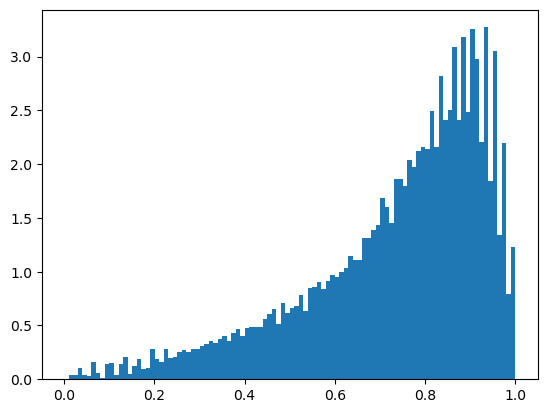

In [212]:
# EAD

'''
**For EAD**
For ead CCF are more homogeneously distributed. It seems like directly applying  a linear regression model to model CCFs directly,  
would produce satisfactory results . so for CCF we will use a multiple linear regression model..'''



plt.hist(loan_data_defaults['CCF'], bins = 100, density = True)


In [213]:
loan_data_defaults.loc[:, 'recovery_rate_0_1'] = np.where(loan_data_defaults['recovery_rate'] == 0, 0, 1)

# ONCE  we know this we can take only the accounts where rate is greater than 0 and model much exactly it is, and the easiest way is with linear regression
loan_data_defaults['recovery_rate_0_1'].sample(3)


45452    0
96279    0
86341    0
Name: recovery_rate_0_1, dtype: int64

In [214]:
len(loan_data_defaults.columns), np.sort(loan_data_defaults.columns), 

(213,
 array(['CCF', 'Unnamed: 0', 'Unnamed: 0.1', 'acc_now_delinq',
        'addr_state', 'addr_state:AK', 'addr_state:AL', 'addr_state:AR',
        'addr_state:AZ', 'addr_state:CA', 'addr_state:CO', 'addr_state:CT',
        'addr_state:DC', 'addr_state:DE', 'addr_state:FL', 'addr_state:GA',
        'addr_state:HI', 'addr_state:IA', 'addr_state:ID', 'addr_state:IL',
        'addr_state:IN', 'addr_state:KS', 'addr_state:KY', 'addr_state:LA',
        'addr_state:MA', 'addr_state:MD', 'addr_state:ME', 'addr_state:MI',
        'addr_state:MN', 'addr_state:MO', 'addr_state:MS', 'addr_state:MT',
        'addr_state:NC', 'addr_state:NE', 'addr_state:NH', 'addr_state:NJ',
        'addr_state:NM', 'addr_state:NV', 'addr_state:NY', 'addr_state:OH',
        'addr_state:OK', 'addr_state:OR', 'addr_state:PA', 'addr_state:RI',
        'addr_state:SC', 'addr_state:SD', 'addr_state:TN', 'addr_state:TX',
        'addr_state:UT', 'addr_state:VA', 'addr_state:VT', 'addr_state:WA',
        'addr_state:WI

In [215]:
 loan_data_defaults['last_pymnt_d'].head(3)

1    Apr-13
8    Apr-12
9    Nov-12
Name: last_pymnt_d, dtype: object

In [216]:
# ✅ DATE CLEANING FUNCTION

ref = pd.to_datetime("2017-11-01")

def clean_date_column(date_series, ref_date):
    # Convert to datetime
    date_clean = pd.to_datetime(date_series, format='%b-%y', errors='coerce')
    
    # Calculate months difference
    months = (
        (ref_date.year - date_clean.dt.year) * 12 +
        (ref_date.month - date_clean.dt.month)
    )
    
    return date_clean, months


loan_data_defaults['last_pymnt_date'], loan_data_defaults["mths_since_last_pymnt_d"] = clean_date_column(loan_data_defaults['last_pymnt_d'], ref)
display(loan_data_defaults['last_pymnt_date'].head(3))
loan_data_defaults["mths_since_last_pymnt_d"].head(3)

1   2013-04-01
8   2012-04-01
9   2012-11-01
Name: last_pymnt_date, dtype: datetime64[ns]

1    55.0
8    67.0
9    60.0
Name: mths_since_last_pymnt_d, dtype: float64

**TIME DEPENDENT SPLITTING THE DATASET**

In [217]:
# BLOCK 1 — Audit the available time variables

# ============================================================
# BLOCK 1
# AUDIT THE TIME VARIABLES IN YOUR EXISTING DATA
# ============================================================



print("loan_data_defaults shape:", loan_data_defaults.shape)

# ------------------------------------------------------------
# 1. Show all date/time-related columns actually available
# ------------------------------------------------------------

time_columns = [
    col for col in loan_data_defaults.columns
    if any(word in col.lower() for word in [
        "issue",
        "default",
        "pymnt",
        "payment",
        "recover",
        "last_credit_pull",
        "earliest_cr"
    ])
]

print("\nTIME-RELATED COLUMNS FOUND:")
print(time_columns)


# ------------------------------------------------------------
# 2. Show the ranges of the important numeric time variables
# ------------------------------------------------------------

for col in [
    "mths_since_issue_d",
    "mths_since_last_pymnt_d",
    "mths_since_earliest_cr_line",
]:
    
    if col in loan_data_defaults.columns:
        print(f"\n{col}")
        print("Minimum:", loan_data_defaults[col].min())
        print("Maximum:", loan_data_defaults[col].max())
        print("Missing:", loan_data_defaults[col].isna().sum())


# ------------------------------------------------------------
# 3. Check whether raw issue date exists
# ------------------------------------------------------------

if "issue_d" in loan_data_defaults.columns:
    
    print("\nRAW issue_d EXISTS")
    print(loan_data_defaults["issue_d"].head())
    
else:
    
    print("\nRAW issue_d is NOT present in loan_data_defaults.")
    print("We will use the available processed time variable(s) instead.")

loan_data_defaults shape: (43236, 215)

TIME-RELATED COLUMNS FOUND:
['issue_d', 'pymnt_plan', 'earliest_cr_line', 'total_pymnt', 'total_pymnt_inv', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'earliest_cr_line_date', 'mths_since_earliest_cr_line', 'issue_d_date', 'mths_since_issue_d', 'loan_status:Default', 'recovery_rate', 'recovery_exceeds_exposure', 'recovery_rate_0_1', 'last_pymnt_date', 'mths_since_last_pymnt_d']

mths_since_issue_d
Minimum: 36.0
Maximum: 126.0
Missing: 0

mths_since_last_pymnt_d
Minimum: 22.0
Maximum: 119.0
Missing: 376

mths_since_earliest_cr_line
Minimum: 0.0
Maximum: 587.0
Missing: 0

RAW issue_d EXISTS
1     Dec-11
8     Dec-11
9     Dec-11
12    Dec-11
14    Dec-11
Name: issue_d, dtype: object


In [218]:
# ============================================================
# BLOCK 2
# CREATE A CHRONOLOGICAL TIME VARIABLE
# ============================================================

'''
Important
This is an issue-date axis.
That is appropriate for an origination-based PD split.
For LGD/EAD, we should ultimately consider whether a genuine default-date variable exists.
'''

from pandas.tseries.offsets import DateOffset

loan_data_defaults = loan_data_defaults.copy()


# ------------------------------------------------------------
# OPTION 1: Use raw issue_d if it exists
# ------------------------------------------------------------

if "issue_d" in loan_data_defaults.columns:
    
    loan_data_defaults["model_time"] = pd.to_datetime(
        loan_data_defaults["issue_d"],
        format='%b-%y', errors='coerce'                    # without format='%b-%y' everything becomes an error produce all NaT
    )



# ------------------------------------------------------------
# OPTION 2: Otherwise reconstruct from mths_since_issue_d
# ------------------------------------------------------------

elif "mths_since_issue_d" in loan_data_defaults.columns:
    
    ref_date = pd.Timestamp("2017-11-01")
    
    loan_data_defaults["model_time"] = (
        ref_date
        - pd.to_timedelta(
            loan_data_defaults["mths_since_issue_d"] * 30.4375,
            unit="D"
        )
    )


else:
    
    raise ValueError(
        "Neither issue_d nor mths_since_issue_d exists. "
        "A chronological split cannot safely be created."
    )


# ------------------------------------------------------------
# CHECK THE RESULT
# ------------------------------------------------------------

print("\nMODEL TIME RANGE")

print("Earliest:",
      loan_data_defaults["model_time"].min())

print("Latest:",
      loan_data_defaults["model_time"].max())

print("\nMissing model_time:",
      loan_data_defaults["model_time"].isna().sum())


MODEL TIME RANGE
Earliest: 2007-06-01 00:00:00
Latest: 2014-12-01 00:00:00

Missing model_time: 0


In [219]:
# ============================================================
# BLOCK 2
# USE THE EXISTING CLEANED ISSUE DATE
# ============================================================

# Your existing clean_date_column() has already created:
# loan_data_defaults["issue_d_date"]

print("Earliest issue date:",
      loan_data_defaults["issue_d_date"].min())

print("Latest issue date:",
      loan_data_defaults["issue_d_date"].max())

print("Missing issue dates:",
      loan_data_defaults["issue_d_date"].isna().sum())

Earliest issue date: 2007-06-01
Latest issue date: 2014-12-01
Missing issue dates: 0


In [220]:
# ============================================================
# HANDLE MISSING LAST-PAYMENT INFORMATION
# ============================================================

loan_data_defaults["mths_since_last_pymnt_d_missing"] = (
    loan_data_defaults["mths_since_last_pymnt_d"]
    .isna()
    .astype(int)
)

loan_data_defaults["mths_since_last_pymnt_d"] = (
    loan_data_defaults["mths_since_last_pymnt_d"]
    .fillna(999)
)

In [221]:
# ============================================================
# BLOCK 3
# YEAR-BY-YEAR LGD / EAD TIME AUDIT
# ============================================================

loan_data_defaults['issue_d_date'], loan_data_defaults['mths_since_issue_d'] = clean_date_column(
   loan_data_defaults['issue_d'], ref
)

loan_data_defaults["model_year"] = (
    loan_data_defaults["issue_d_date"].dt.year
)

In [222]:
# ============================================================
# BLOCK 3
# YEAR-BY-YEAR LGD / EAD / PD TIME AUDIT
# ============================================================

loan_data_defaults["model_year"] = (
    loan_data_defaults["model_time"].dt.year
)


# ------------------------------------------------------------
# LOANS BY YEAR
# ------------------------------------------------------------

loans_by_year = (                                # default observations in loan_data_defaults associated with that issue year.
    loan_data_defaults
    .groupby("model_year")
    .size()
    .rename("loans")
)


# ------------------------------------------------------------
# DEFAULTS BY YEAR
#
# loan_data_defaults already contains defaults only,
# so this is the number of default observations by year.
# ------------------------------------------------------------

defaults_by_year = loans_by_year.rename("defaults")


'''
loans_by_year


might be:
2011    1000
2012    1500

and:
defaults_by_year = loans_by_year.rename("defaults")


becomes:
2011    1000
2012    1500

with the name:
defaults

Therefore your earlier code was conceptually misleading.
Since loan_data_defaults already contains only defaults, I'd simply call it:
defaults_by_issue_year


and not pretend it is all loans.
'''

# ------------------------------------------------------------
# POSITIVE RECOVERIES BY YEAR
# ------------------------------------------------------------

positive_recoveries_by_year = (
    loan_data_defaults
    .groupby("model_year")["recovery_rate_0_1"]
    .sum()
    .rename("positive_recoveries")
)


# ------------------------------------------------------------
# STAGE 2 OBSERVATIONS BY YEAR
# ------------------------------------------------------------

stage2_by_year = (
    loan_data_defaults[
        loan_data_defaults["recovery_rate_0_1"] == 1
    ]
    .groupby("model_year")
    .size()
    .rename("stage2_observations")
)


# ------------------------------------------------------------
# CCF OBSERVATIONS BY YEAR
# ------------------------------------------------------------

ccf_by_year = (
    loan_data_defaults
    .groupby("model_year")["CCF"]
    .count()
    .rename("CCF_observations")
)


# ------------------------------------------------------------
# AVERAGE RECOVERY RATE
# ------------------------------------------------------------

average_recovery_by_year = (
    loan_data_defaults
    .groupby("model_year")["recovery_rate"]
    .mean()
    .rename("average_recovery_rate")
)


# ------------------------------------------------------------
# AVERAGE CCF
# ------------------------------------------------------------

average_ccf_by_year = (
    loan_data_defaults
    .groupby("model_year")["CCF"]
    .mean()
    .rename("average_CCF")
)


# ------------------------------------------------------------
# COMBINE EVERYTHING
# ------------------------------------------------------------

time_audit = pd.concat(
    [
        loans_by_year,
        defaults_by_year,
        positive_recoveries_by_year,
        stage2_by_year,
        ccf_by_year,
        average_recovery_by_year,
        average_ccf_by_year,
    ],
    axis=1
).reset_index()


print("\n==============================")
print("YEAR-BY-YEAR TIME AUDIT")
print("==============================")

print(time_audit.to_string(index=False))


YEAR-BY-YEAR TIME AUDIT
 model_year  loans  defaults  positive_recoveries  stage2_observations  CCF_observations  average_recovery_rate  average_CCF
       2007    158       158                  100                  100               158               0.060824     0.616164
       2008    496       496                  277                  277               496               0.054854     0.639689
       2009    723       723                  477                  477               723               0.057604     0.644249
       2010   1753      1753                 1304                 1304              1753               0.054803     0.638103
       2011   3205      3205                 2479                 2479              3205               0.054100     0.664680
       2012   8084      8084                 6050                 6050              8084               0.059087     0.647218
       2013  14836     14836                 8472                 8472             14836            

In [223]:
# ============================================================
# BLOCK 3
# YEAR-BY-YEAR LGD / EAD AUDIT
# ============================================================

loan_data_defaults["model_year"] = (
    loan_data_defaults["issue_d_date"].dt.year
)


# ------------------------------------------------------------
# DEFAULT OBSERVATIONS BY ISSUE YEAR
# ------------------------------------------------------------

defaults_by_year = (
    loan_data_defaults
    .groupby("model_year")
    .size()
    .rename("defaults")
)


# ------------------------------------------------------------
# POSITIVE RECOVERIES BY ISSUE YEAR
# ------------------------------------------------------------

positive_recoveries_by_year = (
    loan_data_defaults
    .groupby("model_year")["recovery_rate_0_1"]
    .sum()
    .rename("positive_recoveries")
)


# ------------------------------------------------------------
# STAGE 2 OBSERVATIONS BY ISSUE YEAR
# ------------------------------------------------------------

stage2_by_year = (
    loan_data_defaults[
        loan_data_defaults["recovery_rate_0_1"] == 1
    ]
    .groupby("model_year")
    .size()
    .rename("stage2_observations")
)


# ------------------------------------------------------------
# CCF OBSERVATIONS BY ISSUE YEAR
# ------------------------------------------------------------

ccf_by_year = (
    loan_data_defaults
    .groupby("model_year")["CCF"]
    .count()
    .rename("CCF_observations")
)


# ------------------------------------------------------------
# AVERAGE RECOVERY RATE
# ------------------------------------------------------------

average_recovery_by_year = (
    loan_data_defaults
    .groupby("model_year")["recovery_rate"]
    .mean()
    .rename("average_recovery_rate")
)


# ------------------------------------------------------------
# AVERAGE CCF
# ------------------------------------------------------------

average_ccf_by_year = (
    loan_data_defaults
    .groupby("model_year")["CCF"]
    .mean()
    .rename("average_CCF")
)


# ------------------------------------------------------------
# COMBINE THE RESULTS
# ------------------------------------------------------------

time_audit = pd.concat(
    [
        defaults_by_year,
        positive_recoveries_by_year,
        stage2_by_year,
        ccf_by_year,
        average_recovery_by_year,
        average_ccf_by_year,
    ],
    axis=1
).reset_index()


print("\n==============================")
print("YEAR-BY-YEAR TIME AUDIT")
print("==============================")

print(
    time_audit.to_string(index=False)
)


YEAR-BY-YEAR TIME AUDIT
 model_year  defaults  positive_recoveries  stage2_observations  CCF_observations  average_recovery_rate  average_CCF
       2007       158                  100                  100               158               0.060824     0.616164
       2008       496                  277                  277               496               0.054854     0.639689
       2009       723                  477                  477               723               0.057604     0.644249
       2010      1753                 1304                 1304              1753               0.054803     0.638103
       2011      3205                 2479                 2479              3205               0.054100     0.664680
       2012      8084                 6050                 6050              8084               0.059087     0.647218
       2013     14836                 8472                 8472             14836               0.068857     0.723225
       2014     13981          

In [224]:
# Examine whether the end of the dataset has unusual outcome behaviour. This directly addresses the "late observations" issue.

'''
What we are looking for is not:
"The last year is bad."

We are asking:
"Does the amount and nature of observed recovery/exposure change materially as we approach the end of the dataset?"

That distinction matters.
'''


# ============================================================
# BLOCK 4
# CHECK WHETHER LATE-PERIOD OBSERVATIONS LOOK DIFFERENT
# ============================================================

late_period_audit = (
    loan_data_defaults
    .groupby("model_year")
    .agg(
        observations=("recovery_rate", "size"),
        mean_recovery=("recovery_rate", "mean"),
        median_recovery=("recovery_rate", "median"),
        positive_recovery_rate=("recovery_rate_0_1", "mean"),
        mean_CCF=("CCF", "mean"),
        mean_mths_since_issue=(
            "mths_since_issue_d",
            "mean"
        ) if "mths_since_issue_d" in loan_data_defaults.columns
        else ("recovery_rate", "size")
    )
    .reset_index()
)

print("\n==============================")
print("OUTCOME BY TIME")
print("==============================")

print(late_period_audit.to_string(index=False))


OUTCOME BY TIME
 model_year  observations  mean_recovery  median_recovery  positive_recovery_rate  mean_CCF  mean_mths_since_issue
       2007           158       0.060824         0.019400                0.632911  0.616164             120.734177
       2008           496       0.054854         0.006220                0.558468  0.639689             113.965726
       2009           723       0.057604         0.014934                0.659751  0.644249              99.580913
       2010          1753       0.054803         0.025718                0.743868  0.638103              87.668568
       2011          3205       0.054100         0.035232                0.773479  0.664680              75.720749
       2012          8084       0.059087         0.049642                0.748392  0.647218              63.565562
       2013         14836       0.068857         0.069398                0.571043  0.723225              52.134335
       2014         13981       0.055812         0.000000      

In [225]:
# ============================================================
# CLEANING DATE COLUMNS
# YEAR-BY-YEAR LGD / EAD TIME AUDIT
# ============================================================

loan_data_defaults['issue_d_date'], loan_data_defaults['mths_since_issue_d'] = clean_date_column(
   loan_data_defaults['issue_d'], ref
)

loan_data_defaults["model_year"] = (
    loan_data_defaults["issue_d_date"].dt.year
)

In [226]:
# Chronological development/OOT split
'''
I don't want to hard-code arbitrary dates before seeing Block 3.
But you need a reusable mechanism.
Here is a percentage-based chronological split, which is safer than inventing years.


But there is an important caveat
This is a technical first cut, not the final business split.
Why?
Because 20% of observations isn't necessarily the same thing as:
one complete economic period

and it doesn't solve the recovery-observation issue.
Once we see the actual yearly table, I would rather choose the final OOT boundary by whole time periods.
'''


# ============================================================
# BLOCK 5
# CHRONOLOGICAL DEVELOPMENT / OOT SPLIT
# ============================================================

loan_data_defaults = loan_data_defaults.sort_values(
    "model_time"
).copy()


# ------------------------------------------------------------
# Reserve the latest 20% chronologically as OOT
# ------------------------------------------------------------

oot_fraction = 0.20

oot_start_position = int(
    len(loan_data_defaults) * (1 - oot_fraction)
)


loan_data_defaults_development = (
    loan_data_defaults.iloc[:oot_start_position]
    .copy()
)

loan_data_defaults_oot = (
    loan_data_defaults.iloc[oot_start_position:]
    .copy()
)


print("\n==============================")
print("CHRONOLOGICAL SPLIT")
print("==============================")

print(
    "Development:",
    loan_data_defaults_development["model_time"].min(),
    "to",
    loan_data_defaults_development["model_time"].max()
)

print(
    "OOT:",
    loan_data_defaults_oot["model_time"].min(),
    "to",
    loan_data_defaults_oot["model_time"].max()
)

print(
    "\nDevelopment observations:",
    len(loan_data_defaults_development)
)

print(
    "OOT observations:",
    len(loan_data_defaults_oot)
)


CHRONOLOGICAL SPLIT
Development: 2007-06-01 00:00:00 to 2014-05-01 00:00:00
OOT: 2014-05-01 00:00:00 to 2014-12-01 00:00:00

Development observations: 34588
OOT observations: 8648


In [227]:

# # Chronological development/OOT split

# Sort ascending so the past comes first
loan_data_defaults = loan_data_defaults.sort_values(
    'issue_d_date'
).reset_index(drop=True)

# 80/20 out-of-time split: train on the past, test on the future
split_idx = int(len(loan_data_defaults) * 0.80)

train = loan_data_defaults.iloc[:split_idx].copy()
test  = loan_data_defaults.iloc[split_idx:].copy()

# Sanity checks
print('Train period:', train['issue_d_date'].min(), '→', train['issue_d_date'].max())
print('Test period :', test['issue_d_date'].min(),  '→', test['issue_d_date'].max())
print('Train positive rate:', train['recovery_rate_0_1'].mean())
print('Test  positive rate:', test['recovery_rate_0_1'].mean())

Train period: 2007-06-01 00:00:00 → 2014-05-01 00:00:00
Test period : 2014-05-01 00:00:00 → 2014-12-01 00:00:00
Train positive rate: 0.6248120735515208
Test  positive rate: 0.3191489361702128


In [228]:
# in tutorial features_all **FEATURES ALL RFEATURES ALL***

features_all = ['grade:A',
  'grade:B',
  'grade:C',
  'grade:D',
  'grade:E',
  'grade:F',
  'grade:G',
  #'home_ownership:ANY', # THIS IS A CONSTANT 
  'home_ownership:MORTGAGE',
  'home_ownership:NONE',
  'home_ownership:OTHER',
  'home_ownership:OWN',
  'home_ownership:RENT',
  'verification_status:Not Verified',
  'verification_status:Source Verified',
  'verification_status:Verified',
  'purpose:car',
  'purpose:credit_card',
  'purpose:debt_consolidation',
  'purpose:educational',
  'purpose:home_improvement',
  'purpose:house',
  'purpose:major_purchase',
  'purpose:medical',
  'purpose:moving',
  'purpose:other',
  'purpose:renewable_energy',
  'purpose:small_business',
  'purpose:vacation',
  'purpose:wedding',
  'initial_list_status:f',
  'initial_list_status:w',
  'term_int',
  'emp_length_int',
  'mths_since_earliest_cr_line',
  'mths_since_issue_d',
  'mths_since_last_delinq',
  'mths_since_last_record',
  'funded_amnt',
  'annual_inc',
  'installment',
  'int_rate',
  'dti',
  'delinq_2yrs',
  'inq_last_6mths',
  'open_acc',
  'pub_rec',
  'total_acc',
  'total_rev_hi_lim', 
'acc_now_delinq'
]

len(features_all), sorted(features_all)


(49,
 ['acc_now_delinq',
  'annual_inc',
  'delinq_2yrs',
  'dti',
  'emp_length_int',
  'funded_amnt',
  'grade:A',
  'grade:B',
  'grade:C',
  'grade:D',
  'grade:E',
  'grade:F',
  'grade:G',
  'home_ownership:MORTGAGE',
  'home_ownership:NONE',
  'home_ownership:OTHER',
  'home_ownership:OWN',
  'home_ownership:RENT',
  'initial_list_status:f',
  'initial_list_status:w',
  'inq_last_6mths',
  'installment',
  'int_rate',
  'mths_since_earliest_cr_line',
  'mths_since_issue_d',
  'mths_since_last_delinq',
  'mths_since_last_record',
  'open_acc',
  'pub_rec',
  'purpose:car',
  'purpose:credit_card',
  'purpose:debt_consolidation',
  'purpose:educational',
  'purpose:home_improvement',
  'purpose:house',
  'purpose:major_purchase',
  'purpose:medical',
  'purpose:moving',
  'purpose:other',
  'purpose:renewable_energy',
  'purpose:small_business',
  'purpose:vacation',
  'purpose:wedding',
  'term_int',
  'total_acc',
  'total_rev_hi_lim',
  'verification_status:Not Verified',
  've

In [229]:
# Step 2 — Build the Stage 1 inputs

lgd_inputs_stage_1_train = train[features_all]
lgd_inputs_stage_1_test  = test[features_all]

lgd_targets_stage_1_train = train['recovery_rate_0_1']
lgd_targets_stage_1_test  = test['recovery_rate_0_1']

#  Apply the same logic to Stage 2
stage2_train = train[train['recovery_rate_0_1'] == 1].copy()
stage2_test  = test[test['recovery_rate_0_1']  == 1].copy()

In [230]:

# Step 3 — Cross-validation inside the training set
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

tscv = TimeSeriesSplit(n_splits=5)

param_grid = {'C': [0.01, 0.1, 1, 10]}

grid = GridSearchCV(
    LogisticRegression(max_iter=1000, solver='lbfgs'), # LogisticRegression(max_iter=1000, solver='saga'),
    param_grid,
    cv=tscv,
    scoring='roc_auc',
    n_jobs=-1,
)
grid.fit(lgd_inputs_stage_1_train, lgd_targets_stage_1_train)

print(grid.best_params_, grid.best_score_)

{'C': 1} 0.5752906727747773


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [231]:
# Step 4 — Final evaluation, once, on the sealed test set

best_model = grid.best_estimator_
y_hat_test_proba = best_model.predict_proba(lgd_inputs_stage_1_test)[:, 1]
best_model, y_hat_test_proba[:10]

(LogisticRegression(C=1, max_iter=1000),
 array([0.50955973, 0.62272654, 0.59622581, 0.66632564, 0.68585252,
        0.52053989, 0.64412154, 0.4301134 , 0.60312036, 0.58068524]))

In [232]:
# . A reusable out-of-time splitter function

def out_of_time_split(df, date_col, train_frac=0.8, gap_months=0):
    """
    Split a dataframe into train and test by date.

    Rules:
      - The oldest loans go to train.
      - The newest loans go to test.
      - Optionally, drop a 'gap' of months between train and test
        (so a loan's outcome from the training period doesn't leak
        into the test period).

    Returns:
      train_df, test_df
    """
    df = df.sort_values(date_col).reset_index(drop=True)

    # Basic index split
    cut = int(len(df) * train_frac)
    train_df = df.iloc[:cut].copy()
    test_df  = df.iloc[cut:].copy()

    # Apply the gap if asked
    if gap_months > 0:
        gap_end = train_df[date_col].max() - pd.DateOffset(months=gap_months)
        train_df = train_df[train_df[date_col] <= gap_end].copy()
        print(f"Dropped training rows in the {gap_months}-month gap.")
    '''
    How pd.DateOffset(months=gap_months) Works
    In pandas, pd.DateOffset represents a relative time duration. Unlike a fixed number of days, pd.DateOffset(months=x) understands calendar logic
    (e.g., subtracting 1 month from March 31st gives February 28th or 29th). It looks at the specific date you provide and calendar-rewinds it by
    exactly the number of months specified.
    '''

    # Report
    print(f"Train: {train_df[date_col].min().date()} → {train_df[date_col].max().date()}  ({len(train_df)} rows)")
    print(f"Test : {test_df[date_col].min().date()}  → {test_df[date_col].max().date()}   ({len(test_df)} rows)")
    return train_df, test_df

In [233]:
# Use it — for PD (uses issue date)

pd_train, pd_test = out_of_time_split(
    loan_data_defaults,
    date_col='issue_d_date',
    train_frac=0.8,
    gap_months=0,
)

# PD target is usually your good_bad column
pd_target_train = pd_train['good_bad']
pd_target_test  = pd_test['good_bad']

# Features (use whatever you decided on for PD)
pd_features = [c for c in features_all if c in pd_train.columns]
pd_X_train = pd_train[pd_features]
pd_X_test  = pd_test[pd_features]

Train: 2007-06-01 → 2014-05-01  (34588 rows)
Test : 2014-05-01  → 2014-12-01   (8648 rows)


In [234]:
# Use it — for LGD (uses default date — using last_pymnt_d as a stand-in)

lgd_train, lgd_test = out_of_time_split(
    loan_data_defaults,
    date_col='last_pymnt_date',   # closest thing to a default date
    train_frac=0.8,
    gap_months=0,
)

# Stage 1 target
lgd_stage1_target_train = lgd_train['recovery_rate_0_1']
lgd_stage1_target_test  = lgd_test['recovery_rate_0_1']

# Features
lgd_features = [c for c in features_all if c in lgd_train.columns]
lgd_X_train = lgd_train[lgd_features]
lgd_X_test  = lgd_test[lgd_features]

# Stage 2: only loans with a positive recovery
lgd_stage2_train = lgd_train[lgd_train['recovery_rate_0_1'] == 1].copy()
lgd_stage2_test  = lgd_test[lgd_test['recovery_rate_0_1'] == 1].copy()

lgd_stage2_target_train = lgd_stage2_train['recovery_rate']
lgd_stage2_target_test  = lgd_stage2_test['recovery_rate']

Train: 2007-12-01 → 2015-05-01  (34588 rows)
Test : 2015-05-01  → 2016-01-01   (8648 rows)


In [235]:
# Use it — for EAD/CCF (uses default date too)

ead_train, ead_test = out_of_time_split(
    loan_data_defaults,
    date_col='last_pymnt_date',
    train_frac=0.8,
    gap_months=0,
)

ead_target_train = ead_train['CCF']
ead_target_test  = ead_test['CCF']

ead_features = [c for c in features_all if c in ead_train.columns]
ead_X_train = ead_train[ead_features]
ead_X_test  = ead_test[ead_features]

Train: 2007-12-01 → 2015-05-01  (34588 rows)
Test : 2015-05-01  → 2016-01-01   (8648 rows)


In [236]:
# Expanding-window CV

'''
Now we can introduce TimeSeriesSplit.
But notice:
We are using it only inside development.
'''


# ============================================================
# BLOCK 6
# EXPANDING-WINDOW TIME-SERIES CV
# ============================================================

from sklearn.model_selection import TimeSeriesSplit


# IMPORTANT:
# Development data must already be sorted chronologically.

development_sorted = (
    loan_data_defaults_development
    .sort_values("model_time")
    .copy()
)


tscv = TimeSeriesSplit(
    n_splits=4
)


print("\n==============================")
print("EXPANDING-WINDOW CV")
print("==============================")


for fold, (train_index, validation_index) in enumerate(
    tscv.split(development_sorted),
    start=1
):

    fold_train = development_sorted.iloc[train_index]
    fold_validation = development_sorted.iloc[validation_index]

    print(f"\nFOLD {fold}")

    print(
        "TRAIN:",
        fold_train["model_time"].min(),
        "→",
        fold_train["model_time"].max()
    )

    print(
        "VALIDATION:",
        fold_validation["model_time"].min(),
        "→",
        fold_validation["model_time"].max()
    )

    print(
        "Train observations:",
        len(fold_train)
    )

    print(
        "Validation observations:",
        len(fold_validation)
    )


EXPANDING-WINDOW CV

FOLD 1
TRAIN: 2007-06-01 00:00:00 → 2012-02-01 00:00:00
VALIDATION: 2012-02-01 00:00:00 → 2012-12-01 00:00:00
Train observations: 6920
Validation observations: 6917

FOLD 2
TRAIN: 2007-06-01 00:00:00 → 2012-12-01 00:00:00
VALIDATION: 2012-12-01 00:00:00 → 2013-06-01 00:00:00
Train observations: 13837
Validation observations: 6917

FOLD 3
TRAIN: 2007-06-01 00:00:00 → 2013-06-01 00:00:00
VALIDATION: 2013-06-01 00:00:00 → 2013-11-01 00:00:00
Train observations: 20754
Validation observations: 6917

FOLD 4
TRAIN: 2007-06-01 00:00:00 → 2013-11-01 00:00:00
VALIDATION: 2013-11-01 00:00:00 → 2014-05-01 00:00:00
Train observations: 27671
Validation observations: 6917


In [237]:
# ============================================================
# BLOCK 6
# EXPANDING-WINDOW TIME-SERIES CV
# ============================================================

from sklearn.model_selection import TimeSeriesSplit


development_sorted = (
    loan_data_defaults_development
    .sort_values("issue_d_date")
    .copy()
)


tscv = TimeSeriesSplit(
    n_splits=4
)


print("\n==============================")
print("EXPANDING-WINDOW CV")
print("==============================")


for fold, (train_index, validation_index) in enumerate(
    tscv.split(development_sorted),
    start=1
):

    fold_train = development_sorted.iloc[train_index]

    fold_validation = (
        development_sorted.iloc[validation_index]
    )


    print(f"\nFOLD {fold}")


    print(
        "TRAIN:",
        fold_train["issue_d_date"].min(),
        "→",
        fold_train["issue_d_date"].max()
    )


    print(
        "VALIDATION:",
        fold_validation["issue_d_date"].min(),
        "→",
        fold_validation["issue_d_date"].max()
    )


    print(
        "Train observations:",
        len(fold_train)
    )


    print(
        "Validation observations:",
        len(fold_validation)
    )


EXPANDING-WINDOW CV

FOLD 1
TRAIN: 2007-06-01 00:00:00 → 2012-02-01 00:00:00
VALIDATION: 2012-02-01 00:00:00 → 2012-12-01 00:00:00
Train observations: 6920
Validation observations: 6917

FOLD 2
TRAIN: 2007-06-01 00:00:00 → 2012-12-01 00:00:00
VALIDATION: 2012-12-01 00:00:00 → 2013-06-01 00:00:00
Train observations: 13837
Validation observations: 6917

FOLD 3
TRAIN: 2007-06-01 00:00:00 → 2013-06-01 00:00:00
VALIDATION: 2013-06-01 00:00:00 → 2013-11-01 00:00:00
Train observations: 20754
Validation observations: 6917

FOLD 4
TRAIN: 2007-06-01 00:00:00 → 2013-11-01 00:00:00
VALIDATION: 2013-11-01 00:00:00 → 2014-05-01 00:00:00
Train observations: 27671
Validation observations: 6917


In [238]:
# Rolling OOT — the more rigorous version (optional but impressive)

def rolling_oot(df, date_col, year_col=None, min_train_years=3):
    """
    Train on all years up to N, test on year N+1, roll forward.
    Returns a list of (train_years, test_year, train_df, test_df) tuples.
    """
    df = df.sort_values(date_col).reset_index(drop=True)
    df['__year'] = df[date_col].dt.year

    years = sorted(df['__year'].dropna().unique())
    folds = []
    for i in range(min_train_years, len(years)):
        train_years = years[:i]
        test_year   = years[i]
        train_df = df[df['__year'].isin(train_years)].copy()
        test_df  = df[df['__year'] == test_year].copy()
        folds.append((train_years, test_year, train_df, test_df))

    for tr_years, te_year, tr, te in folds:
        print(f"Train {tr_years} ({len(tr)} rows)  →  Test {te_year} ({len(te)} rows)")
    return folds

folds = rolling_oot(loan_data_defaults, date_col='last_pymnt_date', min_train_years=3)
display(folds[:10])

Train [np.float64(2007.0), np.float64(2008.0), np.float64(2009.0)] (575 rows)  →  Test 2010.0 (680 rows)
Train [np.float64(2007.0), np.float64(2008.0), np.float64(2009.0), np.float64(2010.0)] (1255 rows)  →  Test 2011.0 (1189 rows)
Train [np.float64(2007.0), np.float64(2008.0), np.float64(2009.0), np.float64(2010.0), np.float64(2011.0)] (2444 rows)  →  Test 2012.0 (2638 rows)
Train [np.float64(2007.0), np.float64(2008.0), np.float64(2009.0), np.float64(2010.0), np.float64(2011.0), np.float64(2012.0)] (5082 rows)  →  Test 2013.0 (6464 rows)
Train [np.float64(2007.0), np.float64(2008.0), np.float64(2009.0), np.float64(2010.0), np.float64(2011.0), np.float64(2012.0), np.float64(2013.0)] (11546 rows)  →  Test 2014.0 (14947 rows)
Train [np.float64(2007.0), np.float64(2008.0), np.float64(2009.0), np.float64(2010.0), np.float64(2011.0), np.float64(2012.0), np.float64(2013.0), np.float64(2014.0)] (26493 rows)  →  Test 2015.0 (16348 rows)
Train [np.float64(2007.0), np.float64(2008.0), np.float6

[([np.float64(2007.0), np.float64(2008.0), np.float64(2009.0)],
  np.float64(2010.0),
       Unnamed: 0.1  Unnamed: 0      id  member_id  loan_amnt  funded_amnt  \
  0           42383       42383  134737     134726       5000         5000   
  1           42414       42414  128914     128905       4375         4375   
  2           42402       42402  131537     131518       5000         5000   
  3           42337       42337  146205     146192       9000         9000   
  4           42362       42362  139940     139937        500          500   
  ..            ...         ...     ...        ...        ...          ...   
  570         41601       41601  348480     349650       2200         2200   
  571         36703       36703  399988     443125       8500         8500   
  572         39672       39672  139790     139779       3000         3000   
  573         34389       34389  453541     560814      15000        15000   
  574         37143       37143  387827     420926      

In [239]:
# Sanity checks you should always run after splitting

def sanity_check(train, test, target_col, date_col):
    print("=" * 60)
    print("SPLIT SANITY CHECK")
    print("=" * 60)
    print(f"Train date range : {train[date_col].min().date()} → {train[date_col].max().date()}")
    print(f"Test  date range : {test[date_col].min().date()}  → {test[date_col].max().date()}")
    print(f"Train rows       : {len(train)}")
    print(f"Test  rows       : {len(test)}")
    print(f"Train target mean: {train[target_col].mean():.4f}")
    print(f"Test  target mean: {test[target_col].mean():.4f}")

    # Overlap in time? Should be zero if split is truly out-of-time
    overlap = set(train[date_col].dt.to_period('M')) & set(test[date_col].dt.to_period('M'))
    print(f"Overlapping months: {len(overlap)}  (should be 0 for a clean OOT split)")
    print("=" * 60)

sanity_check(lgd_train, lgd_test, target_col='recovery_rate_0_1', date_col='last_pymnt_date')

SPLIT SANITY CHECK
Train date range : 2007-12-01 → 2015-05-01
Test  date range : 2015-05-01  → 2016-01-01
Train rows       : 34588
Test  rows       : 8648
Train target mean: 0.6719
Test  target mean: 0.1307
Overlapping months: 1  (should be 0 for a clean OOT split)


In [240]:

'''
2007   100    0.2%
2008   800    1.9%
2009  1,500   3.5%
2010  3,000   7.0%       ← end of Train block
2011  5,000  11.6%       ← Test
2012  6,500  15.1%       ← Test
2013  9,000  20.9%       ← Holdout
2014  7,000  16.2%       ← Holdout
...
'''


loan_data_defaults['issue_year'] = loan_data_defaults['issue_d_date'].dt.year

# Count loans per year
loans_per_year = loan_data_defaults['issue_year'].value_counts().sort_index()
print(loans_per_year)

# Share per year as a percentage of all loans
share_per_year = (loans_per_year / loans_per_year.sum() * 100).round(1)
print(share_per_year)

issue_year
2007      158
2008      496
2009      723
2010     1753
2011     3205
2012     8084
2013    14836
2014    13981
Name: count, dtype: int64
issue_year
2007     0.4
2008     1.1
2009     1.7
2010     4.1
2011     7.4
2012    18.7
2013    34.3
2014    32.3
Name: count, dtype: float64


In [241]:

# Using time-based percentage splitting, not year-based. That way, each block has ~the same number of loans:

def out_of_time_three_way(df, date_col, train_frac=0.6, val_frac=0.2, gap_months=0):
    """
    Split into Train / Validation / Test by date (past → future).
    Optionally drop a 'gap' of months between blocks to prevent leakage.
    """
    df = df.sort_values(date_col).reset_index(drop=True)
    n = len(df)

    n_train = int(n * train_frac)
    n_val   = int(n * val_frac)

    train_df = df.iloc[:n_train].copy()
    val_df   = df.iloc[n_train : n_train + n_val].copy()
    test_df  = df.iloc[n_train + n_val:].copy()

    if gap_months > 0:
        gap = pd.DateOffset(months=gap_months)
        train_cutoff = train_df[date_col].max() - gap
        val_cutoff   = val_df[date_col].max() - gap
        train_df = train_df[train_df[date_col] <= train_cutoff].copy()
        val_df   = val_df[val_df[date_col]     <= val_cutoff].copy()

    for name, d in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
        print(f"{name:<6}: {d[date_col].min().date()} → {d[date_col].max().date()}  ({len(d)} rows)")
    return train_df, val_df, test_df

# Example: 60% train, 20% validation, 20% test, with a 12-month gap
train_df, val_df, test_df = out_of_time_three_way(
    loan_data_defaults,
    date_col='last_pymnt_date',
    train_frac=0.6,
    val_frac=0.2,
    gap_months=12,
)

Train : 2007-12-01 → 2013-12-01  (11546 rows)
Val   : NaT → NaT  (0 rows)
Test  : 2015-05-01 → 2016-01-01  (8648 rows)


In [277]:
train_df, val_df, test_df = out_of_time_three_way(
    loan_data_defaults,
    date_col='last_pymnt_date',
    train_frac=0.6,
    val_frac=0.2,
    gap_months=4,
)

Train : 2007-12-01 → 2014-08-01  (20123 rows)
Val   : 2014-12-01 → 2015-01-01  (2243 rows)
Test  : 2015-05-01 → 2016-01-01  (8648 rows)


In [278]:
# rather than creating the gap between blocks.
# Use the simpler version first:
def out_of_time_three_way(
    df,
    date_col,
    train_frac=0.60,
    val_frac=0.20,
    gap_months=0
):

    df = df.copy()

    df[date_col] = pd.to_datetime(
        df[date_col],
        errors="coerce"
    )

    df = (
        df
        .dropna(subset=[date_col])
        .sort_values(date_col)
        .reset_index(drop=True)
    )

    n = len(df)

    n_train = int(n * train_frac)

    n_val = int(n * val_frac)

    train_df = df.iloc[
        :n_train
    ].copy()

    val_df = df.iloc[
        n_train:n_train + n_val
    ].copy()

    test_df = df.iloc[
        n_train + n_val:
    ].copy()

    if gap_months > 0:

        gap = pd.DateOffset(
            months=gap_months
        )

        val_start = val_df[date_col].min()

        train_df = train_df[
            train_df[date_col]
            <= val_start - gap
        ].copy()

        test_start = test_df[date_col].min()

        val_df = val_df[
            val_df[date_col]
            <= test_start - gap
        ].copy()

    for name, current_df in [
        ("Train", train_df),
        ("Val", val_df),
        ("Test", test_df)
    ]:

        if len(current_df) == 0:

            print(
                f"{name:<6}: EMPTY"
            )

        else:

            print(
                f"{name:<6}: "
                f"{current_df[date_col].min().date()} → "
                f"{current_df[date_col].max().date()} "
                f"({len(current_df)} rows)"
            )

    return (
        train_df,
        val_df,
        test_df
    )

In [280]:
train_df, val_df, test_df = out_of_time_three_way(
    loan_data_defaults,
    date_col="issue_d_date",
    train_frac=0.60,
    val_frac=0.20,
    gap_months=0
)

Train : 2007-06-01 → 2013-10-01 (25941 rows)
Val   : 2013-10-01 → 2014-05-01 (8647 rows)
Test  : 2014-05-01 → 2014-12-01 (8648 rows)


        int_rate    dti  annual_inc  funded_amnt
year                                            
2009.0     0.107 -0.059        -0.0         -0.0
2010.0     0.074 -0.032        -0.0         -0.0
2011.0     0.049 -0.035         0.0         -0.0
2012.0     0.060 -0.027         0.0         -0.0
2013.0     0.034 -0.034         0.0          0.0
2014.0     0.052 -0.020         0.0          0.0
2015.0     0.026 -0.005         0.0          0.0


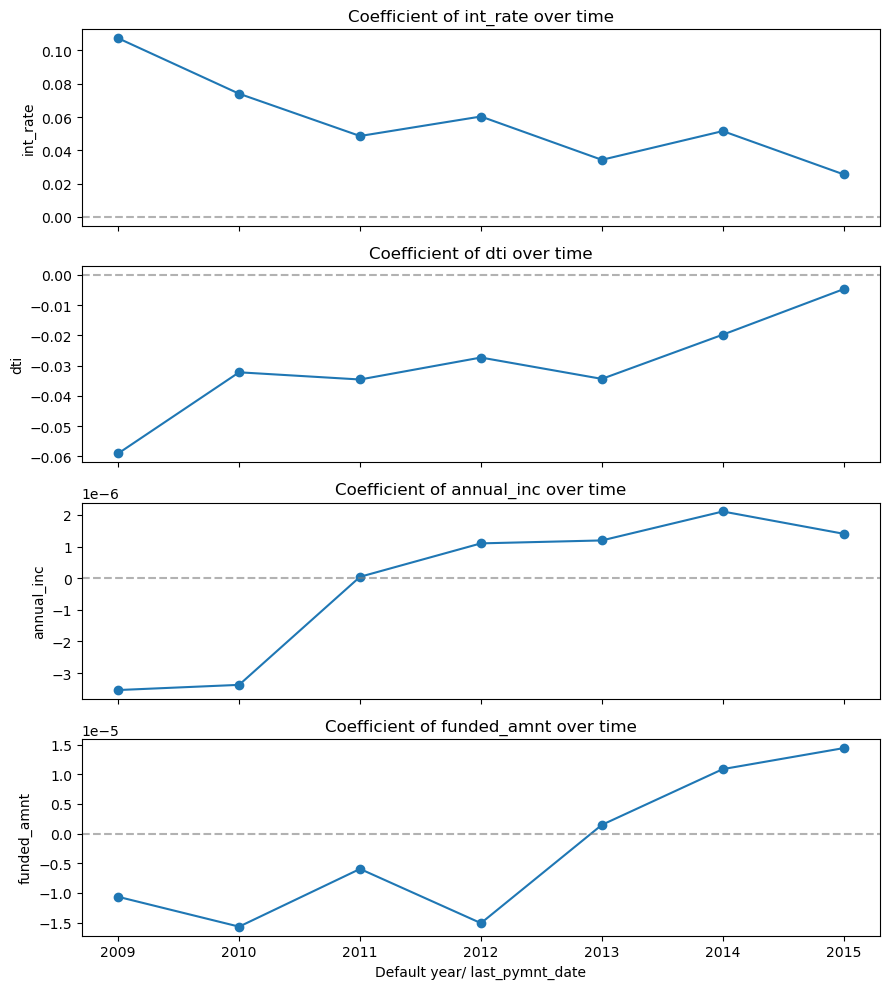

In [282]:
# Plotting coefficients over time — with code


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Make sure date is a real datetime and there's a year column

loan_data_defaults['pymnt_year'] = loan_data_defaults['last_pymnt_date'].dt.year

# Pick a few features you care about
tracked_features = ['int_rate', 'dti', 'annual_inc', 'funded_amnt']
tracked_features = [f for f in tracked_features if f in features_all]

coef_records = []

for year in sorted(loan_data_defaults['pymnt_year'].dropna().unique()):
    year_df = loan_data_defaults[loan_data_defaults['pymnt_year'] == year]

    # Need enough rows to fit
    if len(year_df) < 200:
        continue

    X = year_df[tracked_features].fillna(0)
    y = year_df['recovery_rate_0_1']

    # Skip if only one class in that year
    if y.nunique() < 2:
        continue

    try:
        X_sm = sm.add_constant(X)
        model = sm.Logit(y, X_sm).fit(disp=False)
        row = {'year': year}
        for f in tracked_features:
            row[f] = model.params[f]
        coef_records.append(row)
    except Exception as e:
        print(f"Year {year} failed: {e}")

coef_df = pd.DataFrame(coef_records).set_index('year')
print(coef_df.round(3))

# Plot
fig, axes = plt.subplots(len(tracked_features), 1,
                         figsize=(9, 2.5 * len(tracked_features)),
                         sharex=True)
for ax, f in zip(axes, tracked_features):
    ax.plot(coef_df.index, coef_df[f], marker='o')
    ax.axhline(0, color='gray', linestyle='--', alpha=0.6)
    ax.set_ylabel(f)
    ax.set_title(f"Coefficient of {f} over time")
plt.xlabel("Default year/ last_pymnt_date")
plt.tight_layout()
plt.show()

In [243]:
#  Rolling OOT — code for your three windows

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import pandas as pd

# Convert dates once

loan_data_defaults['issue_year'] = loan_data_defaults['issue_d_date'].dt.year

# For LGD, work with last_pymnt_d (default date proxy)

loan_data_defaults['default_year'] = loan_data_defaults['last_pymnt_date'].dt.year

def rolling_oot_windows(df, date_year_col, feature_cols, target_col, windows):
    """
    windows: list of (train_years_tuple, test_year)
    """
    results = []
    for train_years, test_year in windows:
        train_df = df[df[date_year_col].isin(train_years)].copy()
        test_df  = df[df[date_year_col] == test_year].copy()

        # Skip if either side is empty
        if len(train_df) < 100 or len(test_df) < 30:
            print(f"Skipping window {train_years} → {test_year} (too small)")
            continue

        X_train = train_df[feature_cols].fillna(0)
        y_train = train_df[target_col]
        X_test  = test_df[feature_cols].fillna(0)
        y_test  = test_df[target_col]

        # Skip if target has only one class
        if y_train.nunique() < 2 or y_test.nunique() < 2:
            print(f"Skipping window {train_years} → {test_year} (one class only)")
            continue

        # Scale
        scaler = StandardScaler()
        X_train_sc = scaler.fit_transform(X_train)
        X_test_sc  = scaler.transform(X_test)

        # Fit
        model = LogisticRegression(max_iter=1000, random_state=42)
        model.fit(X_train_sc, y_train)

        # Score
        proba = model.predict_proba(X_test_sc)[:, 1]
        auc = roc_auc_score(y_test, proba)

        results.append({
            'train_years': str(train_years),
            'test_year':   test_year,
            'n_train':     len(train_df),
            'n_test':      len(test_df),
            'test_auc':    round(auc, 4),
        })

    return pd.DataFrame(results)

# Windows you asked for
windows = [
    ((2007, 2008, 2009, 2010), 2011),
    ((2007, 2008, 2009, 2010, 2011), 2012),
    ((2007, 2008, 2009, 2010, 2011, 2012), 2013),
]

feature_cols_for_lgd = [f for f in features_all if f in loan_data_defaults.columns]

rolling_results = rolling_oot_windows(
    loan_data_defaults,
    date_year_col='default_year',
    feature_cols=feature_cols_for_lgd,
    target_col='recovery_rate_0_1',
    windows=windows,
)
print(rolling_results)

# Reading it: if the AUC in each row stays roughly the same, the model is stable. If it collapses in 2011, that's a signal that the crisis period
# hurt the model.



                            train_years  test_year  n_train  n_test  test_auc
0              (2007, 2008, 2009, 2010)       2011     1255    1189    0.6169
1        (2007, 2008, 2009, 2010, 2011)       2012     2444    2638    0.5751
2  (2007, 2008, 2009, 2010, 2011, 2012)       2013     5082    6464    0.6034


In [244]:
# Code for the whole pipeline:

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

# --- Step 1: OOT split first (sort by date, oldest → newest) ---
loan_data_defaults = loan_data_defaults.sort_values(
    'last_pymnt_date'
).reset_index(drop=True)

cut = int(len(loan_data_defaults) * 0.80)
train_block = loan_data_defaults.iloc[:cut].copy()
test_block  = loan_data_defaults.iloc[cut:].copy()

# --- Prepare features and target ---
feature_cols = [f for f in features_all if f in train_block.columns]

X_train = train_block[feature_cols].fillna(0)
y_train = train_block['recovery_rate_0_1']
X_test  = test_block[feature_cols].fillna(0)
y_test  = test_block['recovery_rate_0_1']

# --- Step 2: Scale on train only ---
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# --- Step 3: TimeSeriesSplit CV inside the training block ---
tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'C': [0.01, 0.1, 1.0, 10.0],
    'penalty': ['l2'],
    'solver': ['lbfgs'],
    'max_iter': [1000],
}

grid = GridSearchCV(
    LogisticRegression(),
    param_grid,
    cv=tscv,                # time-aware
    scoring='roc_auc',
    n_jobs=-1,
)
grid.fit(X_train_sc, y_train)

print("Best params (chosen by TimeSeriesSplit CV):", grid.best_params_)
print("Best CV AUC:", round(grid.best_score_, 4))

# --- Step 4: Fit the final model on the WHOLE training block ---
final_model = LogisticRegression(**grid.best_params_, random_state=42)
final_model.fit(X_train_sc, y_train)

# --- Step 5: One single evaluation on the sealed test block ---
proba_test = final_model.predict_proba(X_test_sc)[:, 1]
test_auc = roc_auc_score(y_test, proba_test)
print("FINAL TEST AUC (one shot, sealed until now):", round(test_auc, 4))

Best params (chosen by TimeSeriesSplit CV): {'C': 10.0, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'lbfgs'}
Best CV AUC: 0.6398
FINAL TEST AUC (one shot, sealed until now): 0.6567


In [245]:
'''Is it OK to do three fits then a giant 2008–2012 → 2013–14 split?
Yes. Absolutely. And here's the clean way to frame it:

The three fits (2007–2010→2011, 2007–2011→2012, 2007–2012→2013) are a stability check. They tell you whether the model is holding up year over year.

The giant split (train 2008–2012, test 2013–14) is your final production-mimicking evaluation.

They're not competing. They're two views of the same model.'''


# Giant split you asked for
big_train = loan_data_defaults[
    loan_data_defaults['default_year'].between(2008, 2012)
].copy()
big_test = loan_data_defaults[
    loan_data_defaults['default_year'].between(2013, 2014)
].copy()

print(f"Big train: {len(big_train)} rows")
print(f"Big test : {len(big_test)} rows")

Big train: 5081 rows
Big test : 21411 rows


In [246]:
''' Including time itself as a feature
The idea: add a column that says "which year was this loan issued?" Let the model learn that loans from 2007 behave differently from loans from 2013.

Caveat: these features make the model aware of time, but they don't help when you want to score a future loan — because you can't know the future year. Actually, you can — when the future arrives, you'll know it's e.g. 2026. So the model would say "2026 — hmm, I've never seen that." That's called "extrapolation" and it's risky. Use time features carefully.

A safer alternative: don't include the year. Instead, retrain the model every year in production.'''


# Make sure year is numeric
loan_data_defaults['issue_year'] = pd.to_datetime(
    loan_data_defaults['issue_d_date'], format='%b-%y', errors='coerce', 
).dt.year

# Add it to the feature list
if 'issue_year' not in features_all:
    features_all = features_all + ['issue_year']

# Also add the number of months since a base year — this is often more useful
# because it's continuous (2011.5, 2011.75, etc.) rather than stepped
loan_data_defaults['months_since_2007'] = (
    (pd.to_datetime(loan_data_defaults['issue_d_date']) - pd.Timestamp('2007-01-01'))
    .dt.days / 30.44
)

if 'months_since_2007' not in features_all:
    features_all = features_all + ['months_since_2007']

# Also useful: a "loan_age_at_default" feature
loan_data_defaults['months_to_default'] = (
    (pd.to_datetime(loan_data_defaults['last_pymnt_date'])
     - pd.to_datetime(loan_data_defaults['issue_d_date']))
    .dt.days / 30.44
)

if 'months_to_default' not in features_all:
    features_all = features_all + ['months_to_default']

In [247]:
# Option B — no internet, no API key. Just hardcode a tiny year-by-year economy table:

economy_table = {
    2007: {'unemployment': 4.6, 'gdp_growth': 1.9},
    2008: {'unemployment': 5.8, 'gdp_growth': -0.1},
    2009: {'unemployment': 9.3, 'gdp_growth': -2.5},
    2010: {'unemployment': 9.6, 'gdp_growth': 2.6},
    2011: {'unemployment': 8.9, 'gdp_growth': 1.6},
    2012: {'unemployment': 8.1, 'gdp_growth': 2.2},
    2013: {'unemployment': 7.4, 'gdp_growth': 1.8},
    2014: {'unemployment': 6.2, 'gdp_growth': 2.5},
}

loan_data_defaults['unemployment_rate'] = loan_data_defaults['issue_year'].map(
    lambda y: economy_table.get(y, {}).get('unemployment', np.nan)
)
loan_data_defaults['gdp_growth'] = loan_data_defaults['issue_year'].map(
    lambda y: economy_table.get(y, {}).get('gdp_growth', np.nan)
)

features_all = features_all + ['unemployment_rate', 'gdp_growth']

In [248]:
# Backtesting code — putting it all together, Here's a single function you can drop in that does a proper backtest:

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, mean_absolute_error, r2_score

def backtest_oot(
    df,
    date_col,
    feature_cols,
    target_col,
    train_frac=0.8,
    gap_months=12,
    model_type='logit',     # 'logit' for Stage 1 LGD / PD; 'linear' for Stage 2 LGD / CCF
):
    """
    Perform a proper out-of-time backtest with a gap.
    Returns a dict with the model, scaler, and performance numbers.
    """
    df = df.sort_values(date_col).reset_index(drop=True)

    cut = int(len(df) * train_frac)
    train = df.iloc[:cut].copy()
    test  = df.iloc[cut:].copy()

    # Apply the gap
    if gap_months > 0:
        cutoff = train[date_col].max() - pd.DateOffset(months=gap_months)
        train = train[train[date_col] <= cutoff].copy()

    print("=" * 60)
    print(f"BACKTEST: {model_type.upper()}")
    print("=" * 60)
    print(f"Train: {train[date_col].min().date()} → {train[date_col].max().date()} ({len(train)} rows)")
    print(f"Test : {test[date_col].min().date()}  → {test[date_col].max().date()}  ({len(test)} rows)")
    print("=" * 60)

    X_train = train[feature_cols].fillna(0)
    y_train = train[target_col]
    X_test  = test[feature_cols].fillna(0)
    y_test  = test[target_col]

    # Scale
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc  = scaler.transform(X_test)

    if model_type == 'logit':
        model = LogisticRegression(max_iter=1000, random_state=42)
        model.fit(X_train_sc, y_train)
        proba = model.predict_proba(X_test_sc)[:, 1]
        auc = roc_auc_score(y_test, proba)
        return {'model': model, 'scaler': scaler, 'test_auc': round(auc, 4)}

    elif model_type == 'linear':
        model = LinearRegression()
        model.fit(X_train_sc, y_train)
        pred = np.clip(model.predict(X_test_sc), 0, 1)
        mae  = mean_absolute_error(y_test, pred)
        r2   = r2_score(y_test, pred)
        return {'model': model, 'scaler': scaler, 'test_mae': round(mae, 4), 'test_r2': round(r2, 4)}

    else:
        raise ValueError("model_type must be 'logit' or 'linear'")

# Example usage for Stage 1 LGD
features_for_lgd = [f for f in features_all if f in loan_data_defaults.columns]

result_stage1 = backtest_oot(
    loan_data_defaults,
    date_col='last_pymnt_date',
    feature_cols=features_for_lgd,
    target_col='recovery_rate_0_1',
    train_frac=0.8,
    gap_months=12,
    model_type='logit',
)
print("Stage 1 result:", result_stage1)

# Stage 2 LGD: only loans with positive recovery
stage2_data = loan_data_defaults[loan_data_defaults['recovery_rate_0_1'] == 1].copy()

result_stage2 = backtest_oot(
    stage2_data,
    date_col='last_pymnt_date',
    feature_cols=features_for_lgd,
    target_col='recovery_rate',
    train_frac=0.8,
    gap_months=12,
    model_type='linear',
)
print("Stage 2 result:", result_stage2)

# EAD/CCF
result_ead = backtest_oot(
    loan_data_defaults,
    date_col='last_pymnt_date',
    feature_cols=features_for_lgd,
    target_col='CCF',
    train_frac=0.8,
    gap_months=12,
    model_type='linear',
)
print("EAD result:", result_ead)

BACKTEST: LOGIT
Train: 2007-12-01 → 2014-05-01 (16077 rows)
Test : 2015-05-01  → 2016-01-01  (8648 rows)
Stage 1 result: {'model': LogisticRegression(max_iter=1000, random_state=42), 'scaler': StandardScaler(), 'test_auc': np.float64(0.5856)}
BACKTEST: LINEAR
Train: 2007-12-01 → 2014-01-01 (8931 rows)
Test : 2015-01-01  → 2015-11-01  (4875 rows)
Stage 2 result: {'model': LinearRegression(), 'scaler': StandardScaler(), 'test_mae': 0.0419, 'test_r2': 0.1606}
BACKTEST: LINEAR
Train: 2007-12-01 → 2014-05-01 (16077 rows)
Test : 2015-05-01  → 2016-01-01  (8648 rows)
EAD result: {'model': LinearRegression(), 'scaler': StandardScaler(), 'test_mae': 0.0503, 'test_r2': 0.8776}


In [249]:

'''
VERY IMPORTANT: WHAT THIS VARIABLE ACTUALLY MEANS
This:
loan_age_at_last_pymnt_months


does NOT mean:
"How long the recovery took."

It means:
How old the loan was when the recorded last payment occurred.

These are very different.
Example:
Loan issued
Jan 2010
     ↓
Default
Jan 2012
     ↓
Recovery
Mar 2012
     ↓
Last payment
Jun 2012

Your variable measures:
Jan 2010 → Jun 2012
       ≈ 29 months

It does not measure:
Jan 2012 → Jun 2012
       ≈ 5 months

which would be a recovery/workout duration.
So we should call it a:
loan-age-at-last-payment diagnostic

not a true workout horizon.
That distinction matters enormously for your LGD project.
'''


loan_data_defaults["loan_age_at_last_pymnt_months"] = (
    (
        loan_data_defaults["last_pymnt_date"]
        - loan_data_defaults["issue_d_date"]
    ).dt.days
    / 30.4375
)

# safer below 

loan_data_defaults["loan_age_at_last_pymnt_months"] = (
    (
        loan_data_defaults["last_pymnt_date"]
        - loan_data_defaults["issue_d_date"]
    ).dt.days
    / 30.4375
)

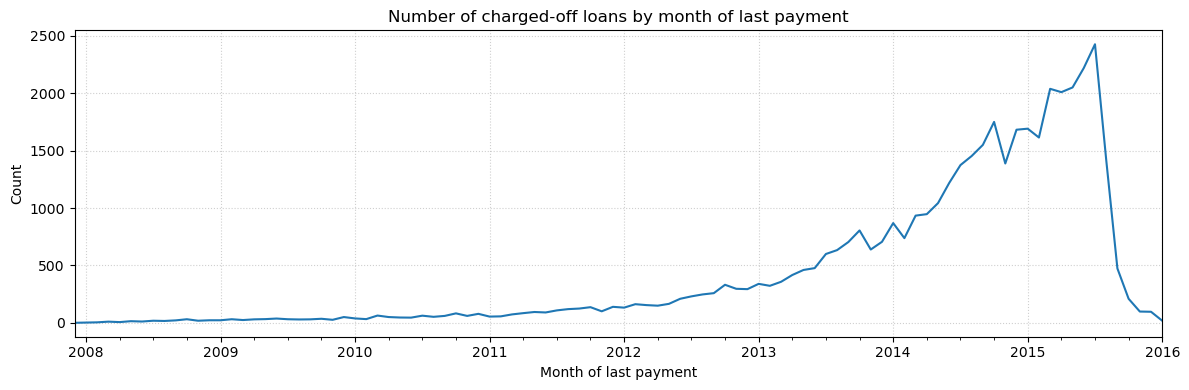

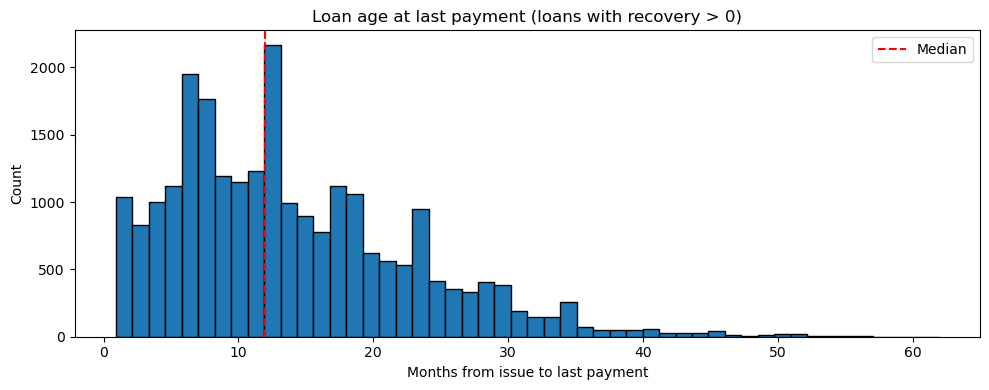

Median loan age at last payment (with recoveries): 12.0 months
90th percentile: 26.0 months
Latest last_pymnt_d in the data: 2016-01-01
Charged-off loans in the last 6 months: 2320
Their average recovery: 0.0030
Older loans' average recovery: 0.0637


In [250]:
#  How to calculate the workout horizon from your data — with code

'''
How to read the output:

If loans in the last 6 months of the dataset have much lower recoveries than older loans, that tells you the recent ones aren't finished recovering yet
— they're censored. That's the sign you need a gap.

If the 90th percentile of loan age at last payment is, say, 24 months, that's a hint that workouts stretch out over 2 years for some loans.

I would not interpret it that strongly.
It means:
90% of loans with recoveries had their recorded last payment by approximately that loan age.

But that does not necessarily mean recovery workouts lasted that long.
Why?
Because:
loan age
=
last payment date − issue date

whereas workout duration should be something like:
workout duration
=
last recovery/payment relevant to recovery
− default date

Those are different clocks.
18. And therefore this sentence needs caution
Your comment says:
"Rule of thumb for Lending Club: most recoveries finish within 12 months of charge-off."

I would not use that as an established fact in your model without a source or direct evidence from your data.
Your current data doesn't give us the individual recovery timing needed to establish that cleanly.
So don't hard-code:
gap_months = 12


because somebody wrote that comment.
Instead, use your data to investigate what you can actually observe, and document the limitation.

Rule of thumb for Lending Club: most recoveries finish within 12 months of charge-off. So a 12-month gap is reasonable. But if your plots show a long 
tail, use a longer gap.

You cannot measure the workout horizon exactly from this data, because Lending Club only gives you a snapshot. But the plots above give you a solid 
guess.
'''



# --- 2. Look at the distribution of last_pymnt_d for charged-off loans ---
charged_off = loan_data_defaults[
    loan_data_defaults['loan_status'].isin([
        'Charged Off',
        'Does not meet the credit policy. Status:Charged Off'
    ])
].copy()

charged_off['last_pymnt_month'] = charged_off['last_pymnt_date'].dt.to_period('M')
monthly_counts = charged_off['last_pymnt_month'].value_counts().sort_index()

plt.figure(figsize=(12, 4))
monthly_counts.plot()
plt.title('Number of charged-off loans by month of last payment')
plt.xlabel('Month of last payment')
plt.ylabel('Count')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# --- 3. How much recovery arrives late? ---
# Look at the gap between issue date and last_pymnt_d for loans that have recoveries
with_recovery = charged_off[charged_off['recoveries'] > 0].copy()

plt.figure(figsize=(10, 4))
plt.hist(with_recovery['loan_age_at_last_pymnt_months'], bins=50, edgecolor='black')
plt.axvline(with_recovery['loan_age_at_last_pymnt_months'].median(),
            color='red', linestyle='--', label='Median')
plt.title('Loan age at last payment (loans with recovery > 0)')
plt.xlabel('Months from issue to last payment')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Median loan age at last payment (with recoveries): "
      f"{with_recovery['loan_age_at_last_pymnt_months'].median():.1f} months")
print(f"90th percentile: "
      f"{with_recovery['loan_age_at_last_pymnt_months'].quantile(0.9):.1f} months")

# --- 4. The tail: how long after the last payment do recoveries keep arriving? ---
# Lending Club's dataset cut-off is around Dec 2015. Look at the last few months.
latest_month = charged_off['last_pymnt_date'].max()
print("Latest last_pymnt_d in the data:", latest_month.date())

# Loans that defaulted in the last 6 months of the data are probably unresolved
recent = charged_off[
    charged_off['last_pymnt_date'] > (latest_month - pd.DateOffset(months=6))
]
print(f"Charged-off loans in the last 6 months: {len(recent)}")
print(f"Their average recovery: {recent['recovery_rate'].mean():.4f}")
print(f"Older loans' average recovery: "
      f"{charged_off[charged_off['last_pymnt_date'] <= (latest_month - pd.DateOffset(months=6))]['recovery_rate'].mean():.4f}")

In [251]:
'''
Why 12 months? What if recoveries take 2 years?
You're right to push on this. There's no universal answer. The gap should match your workout horizon.

Here's the honest trade-off:

Gap size	Pros	Cons
Short (3 months)	More training data	Some leakage remains
Medium (12 months)	Good balance for consumer loans	Still some leakage for slow workouts
Long (24–36 months)	Almost no leakage	Wipes out a huge chunk of data
For Lending Club (unsecured consumer loans): recoveries tend to finish within 6–18 months of charge-off. So 12 months is a good default.

For mortgages or corporate loans: workouts can take 3–5 years. A 12-month gap would be too short there.

For your project specifically:

Try a 12-month gap first.

Then re-run the backtest with a 6-month gap and a 24-month gap and compare.

If the AUC barely changes, use the smaller gap (more data).

If the AUC drops sharply when you use the smaller gap, you know leakage was helping — keep the bigger gap.
'''



# Try multiple gap sizes and compare
gaps_to_try = [0, 6, 12, 18, 24]
results = []

for g in gaps_to_try:
    r = backtest_oot(
        loan_data_defaults,
        date_col='last_pymnt_date',
        feature_cols=features_for_lgd,
        target_col='recovery_rate_0_1',
        train_frac=0.8,
        gap_months=g,
        model_type='logit',
    )
    r['gap_months'] = g
    results.append(r)

gap_comparison = pd.DataFrame(results)[['gap_months', 'test_auc']]
print(gap_comparison)

BACKTEST: LOGIT
Train: 2007-12-01 → 2015-05-01 (34588 rows)
Test : 2015-05-01  → 2016-01-01  (8648 rows)
BACKTEST: LOGIT
Train: 2007-12-01 → 2014-11-01 (24811 rows)
Test : 2015-05-01  → 2016-01-01  (8648 rows)
BACKTEST: LOGIT
Train: 2007-12-01 → 2014-05-01 (16077 rows)
Test : 2015-05-01  → 2016-01-01  (8648 rows)
BACKTEST: LOGIT
Train: 2007-12-01 → 2013-11-01 (10840 rows)
Test : 2015-05-01  → 2016-01-01  (8648 rows)
BACKTEST: LOGIT
Train: 2007-12-01 → 2013-05-01 (6981 rows)
Test : 2015-05-01  → 2016-01-01  (8648 rows)
   gap_months  test_auc
0           0    0.6573
1           6    0.5898
2          12    0.5856
3          18    0.5506
4          24    0.5438


In [252]:
# klearn method for four-way

from sklearn.model_selection import train_test_split

# Option 1 — do two-way splits, chained
# First split off the test set
temp_df, test_df = train_test_split(
    loan_data_defaults, test_size=0.2, random_state=42
)
# Then split temp into train/val/holdout
train_df, temp2_df = train_test_split(
    temp_df, test_size=0.375, random_state=42
)   # 0.375 * 0.8 = 0.3
val_df, holdout_df = train_test_split(
    temp2_df, test_size=0.3333, random_state=42
)   # 0.3333 * 0.3 = 0.1
# Now: 50% train, 30% val, 10% test, 10% holdout

In [253]:
# The correct OOT four-way split

def out_of_time_four_way(df, date_col,
                          train_frac=0.6, val_frac=0.15,
                          test_frac=0.15, gap_months=12):
    """
    Splits into train / val / test / holdout by time (past → future).
    Each cut drops a gap of gap_months to avoid leakage.
    The remaining rows go to the last (holdout) block.
    """
    df = df.sort_values(date_col).reset_index(drop=True)
    n = len(df)

    n_train = int(n * train_frac)
    n_val   = int(n * val_frac)
    n_test  = int(n * test_frac)

    train_df = df.iloc[:n_train].copy()
    val_df   = df.iloc[n_train : n_train + n_val].copy()
    test_df  = df.iloc[n_train + n_val : n_train + n_val + n_test].copy()
    hold_df  = df.iloc[n_train + n_val + n_test:].copy()

    if gap_months > 0:
        gap = pd.DateOffset(months=gap_months)
        train_df = train_df[train_df[date_col] <= train_df[date_col].max() - gap].copy()
        val_df   = val_df[  val_df[date_col]   <= val_df[date_col].max()   - gap].copy()
        test_df  = test_df[ test_df[date_col]  <= test_df[date_col].max()  - gap].copy()

    for name, d in [('Train', train_df), ('Val', val_df),
                    ('Test', test_df), ('Holdout', hold_df)]:
        print(f"{name:<8}: {d[date_col].min().date()} → {d[date_col].max().date()}  ({len(d)} rows)")
    return train_df, val_df, test_df, hold_df

train_df, val_df, test_df, hold_df = out_of_time_four_way(
    loan_data_defaults, date_col='last_pymnt_date',
    train_frac=0.5, val_frac=0.15, test_frac=0.15, gap_months=12
)

Train   : 2007-12-01 → 2013-09-01  (9396 rows)
Val     : NaT → NaT  (0 rows)
Test    : NaT → NaT  (0 rows)
Holdout : 2015-05-01 → 2016-01-01  (8648 rows)


In [273]:
# 40% train / 20% val / 20% test / 20% holdout

def oot_four_way_custom(df, date_col,
                        train_frac=0.40, val1_frac=0.20, val2_frac=0.20,
                        test_frac=0.20, gap_months=12):
    """
    Four-way OOT split with TWO validation blocks.
    Everything goes in time order.

    Train | Val1 | Val2 | Test
    """
    df = df.sort_values(date_col).reset_index(drop=True)
    n = len(df)

    n_train = int(n * train_frac)
    n_val1  = int(n * val1_frac)
    n_val2  = int(n * val2_frac)
    n_test  = int(n * test_frac)
    print(f'{n=},{n_train=}, \n {n_val1=}, \n{n_val2=}, \n {n_test=}')

    train_df = df.iloc[:n_train].copy()
    val1_df  = df.iloc[n_train                : n_train + n_val1].copy()
    val2_df  = df.iloc[n_train + n_val1       : n_train + n_val1 + n_val2].copy()
    test_df  = df.iloc[n_train + n_val1 + n_val2:].copy()
    print(f'display({n=},{train_df.head()=}, \n\n\n\n\n\n {val1_df.head()=}, \n\n\n\n\n\n{val2_df.head()=}, \n\n\n\n\n\n\n {test_df.head()=})')

    if gap_months > 0:
        gap = pd.DateOffset(months=gap_months)
        train_df = train_df[train_df[date_col] <= train_df[date_col].max() - gap].copy()
        val1_df  = val1_df[  val1_df[date_col]  <= val1_df[date_col].max()  - gap].copy()
        val2_df  = val2_df[  val2_df[date_col]  <= val2_df[date_col].max()  - gap].copy()
        
        print(f'{train_df[date_col].max() - gap=}')
        print(f'{val1_df[date_col].max()  - gap=}')
        print(f'{val2_df[date_col].max()  - gap=}')
        print(f'{val1_df[date_col].max()}')
        print(f'{len(val2_df[date_col])=}')
        print(f'{len(train_df)=}')
        print(f'{len(val2_df)=}\n\n')
        
        # test_df: no gap applied, we want it whole

    for name, d in [('Train', train_df), ('Val1', val1_df),
                    ('Val2', val2_df), ('Test', test_df)]:
        print(f"{name:<6}: {d[date_col].min().date()} → {d[date_col].max().date()}  ({len(d)} rows)")
    return train_df, val1_df, val2_df, test_df

train_df, val1_df, val2_df, test_df = oot_four_way_custom(
    loan_data_defaults, date_col='last_pymnt_date',
    train_frac=0.40, val1_frac=0.20, val2_frac=0.20,
    test_frac=0.20, gap_months=12
)

n=43236,n_train=17294, 
 n_val1=8647, 
n_val2=8647, 
 n_test=8647
display(n=43236,train_df.head()=   Unnamed: 0.1  Unnamed: 0      id  member_id  loan_amnt  funded_amnt  \
0         42383       42383  134737     134726       5000         5000   
1         42414       42414  128914     128905       4375         4375   
2         42402       42402  131537     131518       5000         5000   
3         42337       42337  146205     146192       9000         9000   
4         42362       42362  139940     139937        500          500   

   funded_amnt_inv        term  int_rate  installment  ...  \
0      2700.000000   36 months      8.70       158.31  ...   
1       225.000000   36 months     15.01       151.69  ...   
2       749.999405   36 months      8.70       158.31  ...   
3      2600.001368   36 months      9.33       287.59  ...   
4       125.000000   36 months      9.01        15.91  ...   

  mths_since_last_pymnt_d_missing model_year issue_year pymnt_year  \
0             

In [274]:
train_df, val1_df, val2_df, test_df = oot_four_way_custom(
    loan_data_defaults, date_col="issue_d_date",
    train_frac=0.40, val1_frac=0.20, val2_frac=0.20,
    test_frac=0.20, gap_months=12
)

n=43236,n_train=17294, 
 n_val1=8647, 
n_val2=8647, 
 n_test=8647
display(n=43236,train_df.head()=   Unnamed: 0.1  Unnamed: 0      id  member_id  loan_amnt  funded_amnt  \
0         42529       42529   74323      74301       6500         6500   
1         42523       42523   76629      76623       1275         1275   
2         42521       42521   83489      83471       2600         2600   
3         42504       42504   95198      95191      20000        20000   
4         42489       42489  103846     103835       5000         5000   

   funded_amnt_inv        term  int_rate  installment  ...  \
0              0.0   36 months      9.64       208.66  ...   
1              0.0   36 months     12.49        42.65  ...   
2            575.0   36 months      8.38        81.94  ...   
3            700.0   36 months     15.01       693.45  ...   
4           1100.0   36 months     11.22       164.23  ...   

  mths_since_last_pymnt_d_missing model_year issue_year pymnt_year  \
0             

In [276]:
train_df, val1_df, val2_df, test_df = oot_four_way_custom(
    loan_data_defaults, date_col='last_pymnt_date',
    train_frac=0.40, val1_frac=0.20, val2_frac=0.20,
    test_frac=0.20, gap_months=2
)

n=43236,n_train=17294, 
 n_val1=8647, 
n_val2=8647, 
 n_test=8647
display(n=43236,train_df.head()=   Unnamed: 0.1  Unnamed: 0      id  member_id  loan_amnt  funded_amnt  \
0         42383       42383  134737     134726       5000         5000   
1         42414       42414  128914     128905       4375         4375   
2         42402       42402  131537     131518       5000         5000   
3         42337       42337  146205     146192       9000         9000   
4         42362       42362  139940     139937        500          500   

   funded_amnt_inv        term  int_rate  installment  ...  \
0      2700.000000   36 months      8.70       158.31  ...   
1       225.000000   36 months     15.01       151.69  ...   
2       749.999405   36 months      8.70       158.31  ...   
3      2600.001368   36 months      9.33       287.59  ...   
4       125.000000   36 months      9.01        15.91  ...   

  mths_since_last_pymnt_d_missing model_year issue_year pymnt_year  \
0             

In [272]:
def out_of_time_four_way(
    df,
    date_col,
    train_frac=0.50,
    val_frac=0.15,
    test_frac=0.15,
    gap_months=0
):
    """
    Chronological Train / Validation / Test / Holdout split.

    The data are ordered from oldest to newest.

    If gap_months > 0, the gap is placed BETWEEN
    consecutive blocks rather than deleting the end
    of every block.
    """

    df = df.copy()

    df[date_col] = pd.to_datetime(
        df[date_col],
        errors="coerce"
    )

    df = (
        df
        .dropna(subset=[date_col])
        .sort_values(date_col)
        .reset_index(drop=True)
    )

    n = len(df)

    n_train = int(n * train_frac)
    n_val = int(n * val_frac)
    n_test = int(n * test_frac)

    train_df = df.iloc[
        :n_train
    ].copy()

    val_df = df.iloc[
        n_train:n_train + n_val
    ].copy()

    test_df = df.iloc[
        n_train + n_val:
        n_train + n_val + n_test
    ].copy()

    hold_df = df.iloc[
        n_train + n_val + n_test:
    ].copy()

    if gap_months > 0:

        gap = pd.DateOffset(
            months=gap_months
        )

        # Gap between TRAIN and VALIDATION
        train_end = train_df[date_col].max()

        val_start = val_df[date_col].min()

        train_df = train_df[
            train_df[date_col]
            <= val_start - gap
        ].copy()

        # Gap between VALIDATION and TEST
        val_end = val_df[date_col].max()

        test_start = test_df[date_col].min()

        val_df = val_df[
            val_df[date_col]
            <= test_start - gap
        ].copy()

        # Gap between TEST and HOLDOUT
        test_end = test_df[date_col].max()

        hold_start = hold_df[date_col].min()

        test_df = test_df[
            test_df[date_col]
            <= hold_start - gap
        ].copy()

    for name, current_df in [
        ("Train", train_df),
        ("Val", val_df),
        ("Test", test_df),
        ("Holdout", hold_df)
    ]:

        if len(current_df) == 0:

            print(
                f"{name:<8}: EMPTY"
            )

        else:

            print(
                f"{name:<8}: "
                f"{current_df[date_col].min().date()} → "
                f"{current_df[date_col].max().date()} "
                f"({len(current_df)} rows)"
            )

    return (
        train_df,
        val_df,
        test_df,
        hold_df
    )






train_df, val_df, test_df, hold_df = out_of_time_four_way(
    loan_data_defaults,
    date_col="issue_d_date",
    train_frac=0.50,
    val_frac=0.15,
    test_frac=0.15,
    gap_months=0
)

Train   : 2007-06-01 → 2013-07-01 (21618 rows)
Val     : 2013-07-01 → 2013-12-01 (6485 rows)
Test    : 2013-12-01 → 2014-05-01 (6485 rows)
Holdout : 2014-05-01 → 2014-12-01 (8648 rows)


In [59]:
# So how do you compare different gaps? (You loop outside)



# --- Setup once ---
loan_data_defaults = loan_data_defaults.sort_values('last_pymnt_date').reset_index(drop=True)

feature_cols = [f for f in features_all if f in loan_data_defaults.columns]

gaps_to_try = [0, 6, 12, 18, 24]
results = []

for g in gaps_to_try:

    # --- 1. OOT split with THIS gap ---
    # Train / Test split first, so the test set is never touched
    cut = int(len(loan_data_defaults) * 0.80)
    train_block = loan_data_defaults.iloc[:cut].copy()
    test_block  = loan_data_defaults.iloc[cut:].copy()

    # Apply the gap to the TRAIN side only
    if g > 0:
        cutoff = train_block['last_pymnt_date'].max() - pd.DateOffset(months=g)
        train_block = train_block[train_block['last_pymnt_date'] <= cutoff].copy()

    # --- 2. Build X and y ---
    X_train = train_block[feature_cols].fillna(0)
    y_train = train_block['recovery_rate_0_1']
    X_test  = test_block[feature_cols].fillna(0)
    y_test  = test_block['recovery_rate_0_1']

    # --- 3. Scale on train only ---
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc  = scaler.transform(X_test)

    # --- 4. TimeSeriesSplit CV INSIDE the (already-gapped) training block ---
    tscv = TimeSeriesSplit(n_splits=5)

    param_grid = {
        'C': [0.01, 0.1, 1.0, 10.0],
        'penalty': ['l2'],
        'solver': ['lbfgs'],
        'max_iter': [1000],
    }

    grid = GridSearchCV(
        LogisticRegression(),
        param_grid,
        cv=tscv,
        scoring='roc_auc',
        n_jobs=-1,
    )
    grid.fit(X_train_sc, y_train)

    # --- 5. Score on the untouched test set ---
    best_model = grid.best_estimator_
    proba = best_model.predict_proba(X_test_sc)[:, 1]
    test_auc = roc_auc_score(y_test, proba)

    results.append({
        'gap_months': g,
        'n_train': len(train_block),
        'n_test':  len(test_block),
        'best_C':  grid.best_params_['C'],
        'cv_auc':  round(grid.best_score_, 4),
        'test_auc': round(test_auc, 4),
    })

gap_comparison = pd.DataFrame(results)
print(gap_comparison)

   gap_months  n_train  n_test  best_C  cv_auc  test_auc
0           0    34588    8648    0.10  0.6548    0.6569
1           6    24811    8648    1.00  0.6607    0.5898
2          12    16077    8648    0.10  0.6485    0.5856
3          18    10840    8648    0.01  0.6302    0.5567
4          24     6981    8648    0.10  0.6232    0.5450


In [60]:
# One more subtle point
'''There's actually a way to make GridSearchCV "handle" different gaps — by writing a custom splitter whose constructor takes gap_months, and
looping over splitters:'''


class TimeSeriesSplitWithGap:
    def __init__(self, n_splits=5, gap=0):
        self.n_splits = n_splits
        self.gap = gap

    def split(self, X, y=None, groups=None):
        n = len(X)
        fold_size = n // (self.n_splits + 1)
        for i in range(self.n_splits):
            train_end = fold_size * (i + 1)
            test_start = train_end + self.gap
            test_end = min(test_start + fold_size, n)
            if test_start >= n:
                break
            yield np.arange(0, train_end), np.arange(test_start, test_end)

    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits



# Then inside the outer loop:

grid = GridSearchCV(
    LogisticRegression(),
    param_grid,
    cv=TimeSeriesSplitWithGap(n_splits=5, gap=g),
    scoring='roc_auc',
)

In [61]:
# For real time-series gap, you'd write a version that operates on the date column:


class TimeSeriesSplitByDateWithGap:
    """
    Like TimeSeriesSplit, but splits by date and respects a gap
    measured in months. Assumes X is a DataFrame with a date column,
    sorted in ascending time order.
    """
    def __init__(self, date_col, n_splits=5, gap_months=0):
        self.date_col = date_col
        self.n_splits = n_splits
        self.gap_months = gap_months

    def split(self, X, y=None, groups=None):
        import pandas as pd
        X = X.reset_index(drop=True)
        n = len(X)

        fold_size = n // (self.n_splits + 1)

        for i in range(self.n_splits):
            train_end = fold_size * (i + 1)
            test_start = train_end

            # Apply the gap in MONTHS, not rows
            if self.gap_months > 0 and train_end > 0:
                cutoff = X.iloc[train_end - 1][self.date_col] - pd.DateOffset(months=self.gap_months)
                # Skip forward while date > cutoff (i.e., skip the gap period)
                while test_start < n and X.iloc[test_start][self.date_col] <= cutoff:
                    test_start += 1

            test_end = min(test_start + fold_size, n)
            if test_start >= n:
                break

            yield np.arange(0, train_end), np.arange(test_start, test_end)

    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits

In [62]:
'''Key difference: the gap is now measured in months of dates, not in rows. So gap_months=12 truly means "skip 12 months."

You'd use it like this:'''

splitter = TimeSeriesSplitByDateWithGap(
    date_col='last_pymnt_date',
    n_splits=5,
    gap_months=12,
)

grid = GridSearchCV(
    LogisticRegression(),
    param_grid,
    cv=splitter,
    scoring='roc_auc',
)

In [63]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import roc_auc_score

# ============ 1. Prepare dates and sort ============


# ============ 2. Choose features ============
feature_cols = [f for f in features_all if f in loan_data_defaults.columns]

# ============ 3. Define the outer rolling OOT windows ============
outer_windows = [
    ((2007, 2008, 2009, 2010), 2011),
    ((2007, 2008, 2009, 2010, 2011), 2012),
    ((2007, 2008, 2009, 2010, 2011, 2012), 2013),
    ((2007, 2008, 2009, 2010, 2011, 2012, 2013), 2014),
]

# ============ 4. Hyperparameter grid ============
param_grid = {
    'C': [0.01, 0.1, 1.0, 10.0],
    'penalty': ['l2'],
    'solver': ['lbfgs'],
    'max_iter': [1000],
}

# ============ 5. Outer rolling OOT loop ============
results = []

for train_years, test_year in outer_windows:
    print("=" * 60)
    print(f"OUTER FOLD: train on {train_years}, test on {test_year}")
    print("=" * 60)

    outer_train = loan_data_defaults[
        loan_data_defaults['default_year'].isin(train_years)
    ].copy()
    outer_test  = loan_data_defaults[
        loan_data_defaults['default_year'] == test_year
    ].copy()

    # Skip if too small
    if len(outer_train) < 200 or len(outer_test) < 50:
        print("Skipping: not enough rows")
        continue

    X_outer_train = outer_train[feature_cols].fillna(0)
    y_outer_train = outer_train['recovery_rate_0_1']
    X_outer_test  = outer_test[feature_cols].fillna(0)
    y_outer_test  = outer_test['recovery_rate_0_1']

    # Skip if only one class present
    if y_outer_train.nunique() < 2 or y_outer_test.nunique() < 2:
        print("Skipping: only one class present")
        continue

    # --- Scale on the OUTER TRAIN ONLY ---
    scaler = StandardScaler()
    X_outer_train_sc = scaler.fit_transform(X_outer_train)
    X_outer_test_sc  = scaler.transform(X_outer_test)

    # --- INNER CV: TimeSeriesSplit inside the outer training set ---
    inner_cv = TimeSeriesSplit(n_splits=5)

    grid = GridSearchCV(
        LogisticRegression(),
        param_grid,
        cv=inner_cv,
        scoring='roc_auc',
        n_jobs=-1,
    )
    grid.fit(X_outer_train_sc, y_outer_train)

    best_C = grid.best_params_['C']
    best_cv_auc = grid.best_score_

    # --- Refit final model on the WHOLE outer training set with best params ---
    final_model = LogisticRegression(
        C=best_C,
        penalty='l2',
        solver='lbfgs',
        max_iter=1000,
    )
    final_model.fit(X_outer_train_sc, y_outer_train)

    # --- Score on the OUTER TEST set (never seen during training) ---
    proba = final_model.predict_proba(X_outer_test_sc)[:, 1]
    test_auc = roc_auc_score(y_outer_test, proba)

    # --- Save results for this fold ---
    results.append({
        'train_years': str(train_years),
        'test_year': test_year,
        'n_train': len(outer_train),
        'n_test': len(outer_test),
        'best_C': best_C,
        'inner_cv_auc': round(best_cv_auc, 4),
        'outer_test_auc': round(test_auc, 4),
    })
    print(f"best_C = {best_C}, inner_cv_auc = {best_cv_auc:.4f}, "
          f"outer_test_auc = {test_auc:.4f}\n")

# ============ 6. Report ============
results_df = pd.DataFrame(results)
print("\nRolling OOT results:")
print(results_df)

OUTER FOLD: train on (2007, 2008, 2009, 2010), test on 2011
best_C = 0.01, inner_cv_auc = 0.6556, outer_test_auc = 0.6261

OUTER FOLD: train on (2007, 2008, 2009, 2010, 2011), test on 2012
best_C = 0.01, inner_cv_auc = 0.6452, outer_test_auc = 0.6121

OUTER FOLD: train on (2007, 2008, 2009, 2010, 2011, 2012), test on 2013
best_C = 0.01, inner_cv_auc = 0.6201, outer_test_auc = 0.6412

OUTER FOLD: train on (2007, 2008, 2009, 2010, 2011, 2012, 2013), test on 2014
best_C = 0.01, inner_cv_auc = 0.6311, outer_test_auc = 0.6646


Rolling OOT results:
                                  train_years  test_year  n_train  n_test  \
0                    (2007, 2008, 2009, 2010)       2011     1255    1189   
1              (2007, 2008, 2009, 2010, 2011)       2012     2444    2638   
2        (2007, 2008, 2009, 2010, 2011, 2012)       2013     5082    6464   
3  (2007, 2008, 2009, 2010, 2011, 2012, 2013)       2014    11546   14947   

   best_C  inner_cv_auc  outer_test_auc  
0    0.01        0.655

In [281]:
# A proper sklearn pipeline would be:

from sklearn.pipeline import Pipeline

model_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("logistic_regression", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

# Then GridSearchCV operates on the whole pipeline. This is much safer.

In [ ]:
'''
Now the really important part: Pipeline + GridSearchCV
This is where Pipeline becomes extremely valuable for your problem.'''


# Instead of:

scaler = StandardScaler()

X_outer_train_sc = scaler.fit_transform(
    X_outer_train
)

grid = GridSearchCV(
    LogisticRegression(),
    param_grid,
    cv=inner_cv,
    scoring='roc_auc'
)


# we create:

model_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])


# Then:

grid = GridSearchCV(
    model_pipeline,
    param_grid,
    cv=inner_cv,
    scoring='roc_auc'
)

'''
Then your parameter grid needs to refer to the step name:
param_grid = {    'model__C': [0.01, 0.1, 1, 10]}


Why?
Because C belongs to:
LogisticRegression


and that model is called:
model

inside the Pipeline.
Therefore:
model + __ + C

= model__C
'''


param_grid = {
    'model__C': [0.01, 0.1, 1, 10]
}


# Now the Pipeline itself becomes the thing GridSearchCV cross-validates.



# Then:
grid.fit(    X_outer_train,    y_outer_train)



In [283]:
# Before adding a gap, inspect the calendar span, his is the diagnostic I want you to understand. Run:

for name, current_df in [
    ("Train", train_df),
    ("Val", val_df),
    ("Test", test_df),
    ("Holdout", hold_df)
]:
    print(
        name,
        current_df["issue_d_date"].min(),
        "→",
        current_df["issue_d_date"].max(),
        "rows:",
        len(current_df)
    )

Train 2007-06-01 00:00:00 → 2013-10-01 00:00:00 rows: 25941
Val 2013-10-01 00:00:00 → 2014-05-01 00:00:00 rows: 8647
Test 2014-05-01 00:00:00 → 2014-12-01 00:00:00 rows: 8648
Holdout 2014-05-01 00:00:00 → 2014-12-01 00:00:00 rows: 8648


In [64]:
# Code for Rolling-window / walk-forward validation, Here the training window moves forward.
'''Actual rolling-window code for your data
Because your data is monthly-ish but observations are individual loans, I prefer defining the windows by dates, not row counts.

These dates are illustrative. We should not call them your final validation windows until we inspect your actual monthly/yearly distribution.'''

import pandas as pd


data = (
    loan_data_defaults
    .sort_values("issue_d_date")
    .copy()
)


rolling_windows = [
    (
        "2007-06-01",
        "2010-01-01",
        "2010-01-01",
        "2011-01-01"
    ),
    (
        "2008-01-01",
        "2011-01-01",
        "2011-01-01",
        "2012-01-01"
    ),
    (
        "2009-01-01",
        "2012-01-01",
        "2012-01-01",
        "2013-01-01"
    ),
    (
        "2010-01-01",
        "2013-01-01",
        "2013-01-01",
        "2014-01-01"
    )
]


for fold, (
    train_start,
    train_end,
    test_start,
    test_end
) in enumerate(rolling_windows, start=1):

    train = data[
        (data["issue_d_date"] >= pd.Timestamp(train_start))
        &
        (data["issue_d_date"] < pd.Timestamp(train_end))
    ].copy()

    test = data[
        (data["issue_d_date"] >= pd.Timestamp(test_start))
        &
        (data["issue_d_date"] < pd.Timestamp(test_end))
    ].copy()

    print(f"\nFOLD {fold}")

    print(
        "TRAIN:",
        train["issue_d_date"].min(),
        "→",
        train["issue_d_date"].max()
    )

    print(
        "TEST:",
        test["issue_d_date"].min(),
        "→",
        test["issue_d_date"].max()
    )

    print("Train:", len(train))
    print("Test:", len(test))











FOLD 1
TRAIN: 2007-06-01 00:00:00 → 2009-12-01 00:00:00
TEST: 2010-01-01 00:00:00 → 2010-12-01 00:00:00
Train: 1377
Test: 1753

FOLD 2
TRAIN: 2008-01-01 00:00:00 → 2010-12-01 00:00:00
TEST: 2011-01-01 00:00:00 → 2011-12-01 00:00:00
Train: 2972
Test: 3205

FOLD 3
TRAIN: 2009-01-01 00:00:00 → 2011-12-01 00:00:00
TEST: 2012-01-01 00:00:00 → 2012-12-01 00:00:00
Train: 5681
Test: 8084

FOLD 4
TRAIN: 2010-01-01 00:00:00 → 2012-12-01 00:00:00
TEST: 2013-01-01 00:00:00 → 2013-12-01 00:00:00
Train: 13042
Test: 14836


In [65]:
# Strictly sequential future-window OOT validation


data = (
    loan_data_defaults
    .sort_values("issue_d_date")
    .copy()
)


future_windows = [
    (
        "2007-06-01",
        "2012-01-01",
        "2012-01-01",
        "2013-01-01"
    ),
    (
        "2007-06-01",
        "2013-01-01",
        "2013-01-01",
        "2014-01-01"
    ),
    (
        "2007-06-01",
        "2014-01-01",
        "2014-01-01",
        "2015-01-01"
    )
]


for fold, (
    train_start,
    train_end,
    test_start,
    test_end
) in enumerate(
    future_windows,
    start=1
):

    train = data[
        (data["issue_d_date"] >= pd.Timestamp(train_start))
        &
        (data["issue_d_date"] < pd.Timestamp(train_end))
    ].copy()

    test = data[
        (data["issue_d_date"] >= pd.Timestamp(test_start))
        &
        (data["issue_d_date"] < pd.Timestamp(test_end))
    ].copy()

    print(f"\nFUTURE OOT {fold}")

    print(
        "TRAIN:",
        train["issue_d_date"].min(),
        "→",
        train["issue_d_date"].max()
    )

    print(
        "OOT:",
        test["issue_d_date"].min(),
        "→",
        test["issue_d_date"].max()
    )

    print("Train observations:", len(train))
    print("OOT observations:", len(test))



FUTURE OOT 1
TRAIN: 2007-06-01 00:00:00 → 2011-12-01 00:00:00
OOT: 2012-01-01 00:00:00 → 2012-12-01 00:00:00
Train observations: 6335
OOT observations: 8084

FUTURE OOT 2
TRAIN: 2007-06-01 00:00:00 → 2012-12-01 00:00:00
OOT: 2013-01-01 00:00:00 → 2013-12-01 00:00:00
Train observations: 14419
OOT observations: 14836

FUTURE OOT 3
TRAIN: 2007-06-01 00:00:00 → 2013-12-01 00:00:00
OOT: 2014-01-01 00:00:00 → 2014-12-01 00:00:00
Train observations: 29255
OOT observations: 13981


In [66]:
# A simple stress-period framework
# Suppose we eventually identify:

stress_start = pd.Timestamp("2014-01-01")
stress_end = pd.Timestamp("2015-01-01")


# Then:

stress_period = data[
    (data["issue_d_date"] >= stress_start)
    &
    (data["issue_d_date"] < stress_end)
].copy()

normal_period = data[
    data["issue_d_date"] < stress_start
].copy()


# Then:

print(
    "Normal observations:",
    len(normal_period)
)

print(
    "Stress observations:",
    len(stress_period)
)

# Fit the model using the normal/development period and evaluate separately on stress.



Normal observations: 29255
Stress observations: 13981


In [67]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(
    n_splits=4,
    gap=500
)

In [68]:
# Automatic rolling windows, No need for manual dates. Example:

years = sorted(
    loan_data_defaults["model_year"].unique()
)

print(F'{len(years)=}')

window = 3

for i in range(len(years) - window):

    train_years = years[i:i+window]

    test_year = years[i+window]

    print(
        "Train:",
        train_years,
        "Test:",
        test_year
    )

len(years)=8
Train: [np.int32(2007), np.int32(2008), np.int32(2009)] Test: 2010
Train: [np.int32(2008), np.int32(2009), np.int32(2010)] Test: 2011
Train: [np.int32(2009), np.int32(2010), np.int32(2011)] Test: 2012
Train: [np.int32(2010), np.int32(2011), np.int32(2012)] Test: 2013
Train: [np.int32(2011), np.int32(2012), np.int32(2013)] Test: 2014


In [69]:
# A better immediate diagnostic
# Before deciding the final split, I would calculate exactly how much of each vintage falls into different age bands

maturity_audit = (
    loan_data_defaults
    .groupby("model_year")["mths_since_issue_d"]
    .agg(
        min_months="min",
        median_months="median",
        mean_months="mean",
        max_months="max"
    )
    .reset_index()
)

print(maturity_audit.to_string(index=False))

 model_year  min_months  median_months  mean_months  max_months
       2007         119          120.0   120.734177         125
       2008         107          115.0   113.965726         118
       2009          95           99.0    99.580913         106
       2010          83           87.0    87.668568          94
       2011          71           75.0    75.720749          82
       2012          59           63.0    63.565562          70
       2013          47           52.0    52.134335          58
       2014          35           41.0    41.067663          46


In [70]:
# mature = months_observed_after_default >= 24
# immature = months_observed_after_default < 24


'''What we can do NOW with your data
We can create a vintage/age diagnostic, but we should not call it a maturity flag.
For example:

This means:
Early       = 2007–2012
Transition  = 2013
Late        = 2014

But notice the wording:
Late vintage

not:
Immature loan

because we haven't established post-default observation time.'''

loan_data_defaults["vintage_group"] = np.select(
    [
        loan_data_defaults["model_year"] <= 2012,
        loan_data_defaults["model_year"] == 2013,
        loan_data_defaults["model_year"] == 2014
    ],
    [
        "Early",
        "Transition",
        "Late"
    ],
    default="Other"
)

In [71]:
# A fully working chronological split with a calendar gap
'''Since you already have:
issue_d_date


we can explicitly create:
development
gap
OOT

Here's a robust version using dates rather than arbitrary row counts.

But do not run those exact dates as your final model design yet.
They are an illustration of the mechanics.
We have not yet established that:
2014-01 → 2014-03

is the appropriate gap.'''




# ============================================================
# 1. MAKE SURE DATA IS SORTED BY ISSUE DATE
# ============================================================

loan_data_defaults_sorted = (
    loan_data_defaults
    .sort_values("issue_d_date")
    .copy()
)


# ============================================================
# 2. DEFINE THE DATES
# ============================================================

development_end = pd.Timestamp("2013-12-01")

gap_start = pd.Timestamp("2014-01-01")
gap_end = pd.Timestamp("2014-03-01")

oot_start = pd.Timestamp("2014-04-01")


# ============================================================
# 3. DEVELOPMENT
# ============================================================

loan_data_defaults_development = (
    loan_data_defaults_sorted[
        loan_data_defaults_sorted["issue_d_date"]
        < development_end
    ]
    .copy()
)


# ============================================================
# 4. GAP
# ============================================================

loan_data_defaults_gap = (
    loan_data_defaults_sorted[
        (
            loan_data_defaults_sorted["issue_d_date"]
            >= gap_start
        )
        &
        (
            loan_data_defaults_sorted["issue_d_date"]
            < gap_end
        )
    ]
    .copy()
)


# ============================================================
# 5. OOT
# ============================================================

loan_data_defaults_oot = (
    loan_data_defaults_sorted[
        loan_data_defaults_sorted["issue_d_date"]
        >= oot_start
    ]
    .copy()
)


# ============================================================
# 6. CHECK THE RESULT
# ============================================================

print("\n==============================")
print("CHRONOLOGICAL SPLIT WITH GAP")
print("==============================")


print(
    "\nDEVELOPMENT:",
    len(loan_data_defaults_development)
)

print(
    "Start:",
    loan_data_defaults_development["issue_d_date"].min()
)

print(
    "End:",
    loan_data_defaults_development["issue_d_date"].max()
)


print(
    "\nGAP:",
    len(loan_data_defaults_gap)
)

print(
    "Start:",
    loan_data_defaults_gap["issue_d_date"].min()
)

print(
    "End:",
    loan_data_defaults_gap["issue_d_date"].max()
)


print(
    "\nOOT:",
    len(loan_data_defaults_oot)
)

print(
    "Start:",
    loan_data_defaults_oot["issue_d_date"].min()
)

print(
    "End:",
    loan_data_defaults_oot["issue_d_date"].max()
)


CHRONOLOGICAL SPLIT WITH GAP

DEVELOPMENT: 27977
Start: 2007-06-01 00:00:00
End: 2013-11-01 00:00:00

GAP: 2541
Start: 2014-01-01 00:00:00
End: 2014-02-01 00:00:00

OOT: 10174
Start: 2014-04-01 00:00:00
End: 2014-12-01 00:00:00


In [72]:
print("member_id" in loan_data_defaults.columns), print("id" in loan_data_defaults.columns),\
print(loan_data_defaults['id'].head(3) == loan_data_defaults['member_id'].head(3)), np.sort(loan_data_defaults.columns)

True
True
0    False
1    False
2    False
dtype: bool


(None,
 None,
 None,
 array(['CCF', 'Unnamed: 0', 'Unnamed: 0.1', 'acc_now_delinq',
        'addr_state', 'addr_state:AK', 'addr_state:AL', 'addr_state:AR',
        'addr_state:AZ', 'addr_state:CA', 'addr_state:CO', 'addr_state:CT',
        'addr_state:DC', 'addr_state:DE', 'addr_state:FL', 'addr_state:GA',
        'addr_state:HI', 'addr_state:IA', 'addr_state:ID', 'addr_state:IL',
        'addr_state:IN', 'addr_state:KS', 'addr_state:KY', 'addr_state:LA',
        'addr_state:MA', 'addr_state:MD', 'addr_state:ME', 'addr_state:MI',
        'addr_state:MN', 'addr_state:MO', 'addr_state:MS', 'addr_state:MT',
        'addr_state:NC', 'addr_state:NE', 'addr_state:NH', 'addr_state:NJ',
        'addr_state:NM', 'addr_state:NV', 'addr_state:NY', 'addr_state:OH',
        'addr_state:OK', 'addr_state:OR', 'addr_state:PA', 'addr_state:RI',
        'addr_state:SC', 'addr_state:SD', 'addr_state:TN', 'addr_state:TX',
        'addr_state:UT', 'addr_state:VA', 'addr_state:VT', 'addr_state:WA',
       

In [73]:
print(loan_data_defaults["member_id"].nunique())

print(len(loan_data_defaults))

43236
43236


In [74]:
# Find borrowers with multiple loans

borrower_loan_counts = (
    loan_data_defaults
    .groupby("member_id")
    .size()
    .sort_values(ascending=False)
)

print(
    borrower_loan_counts.head(5)
)




multiple_loan_borrowers = (
    borrower_loan_counts[
        borrower_loan_counts > 1
    ]
)

print(
    "Borrowers with multiple loans:",
    len(multiple_loan_borrowers)
)

member_id
70694       1
11506781    1
11497588    1
11497676    1
11497936    1
dtype: int64
Borrowers with multiple loans: 0


In [75]:
# A simple grouped-temporal split for your data, If you have member_id, a straightforward conservative approach is:

'''
If there is overlap, you have a choice:
Option A
Move all observations for those borrowers to one side.
Option B
Define the business problem as allowing repeat borrowers.
You should not automatically delete them.
'''

loan_data_defaults_sorted = (
    loan_data_defaults
    .sort_values("issue_d_date")
    .copy()
)

cutoff_date = pd.Timestamp("2014-01-01")

development = loan_data_defaults_sorted[
    loan_data_defaults_sorted["issue_d_date"] < cutoff_date
].copy()

oot = loan_data_defaults_sorted[
    loan_data_defaults_sorted["issue_d_date"] >= cutoff_date
].copy()


train_borrowers = set(
    development["member_id"].dropna()
)

oot_borrowers = set(
    oot["member_id"].dropna()
)

overlap = train_borrowers.intersection(
    oot_borrowers
)

print(
    "Borrower overlap:",
    len(overlap)
)

Borrower overlap: 0


In [76]:
# Create the same chronological split for Stage 1 and Stage 2, This is important because you don't want:

# ============================================================
# BLOCK 7
# CREATE STAGE 1 AND STAGE 2 DATASETS
# USING THE SAME TIME BOUNDARIES
# ============================================================

# ------------------------------------------------------------
# STAGE 1
# All default observations
# Target = recovery_rate_0_1
# ------------------------------------------------------------

lgd_stage_1_development = (
    loan_data_defaults_development.copy()
)

lgd_stage_1_oot = (
    loan_data_defaults_oot.copy()
)


# ------------------------------------------------------------
# STAGE 2
# Positive recovery observations only
# Target = recovery_rate
# ------------------------------------------------------------

lgd_stage_2_development = (
    loan_data_defaults_development[
        loan_data_defaults_development["recovery_rate_0_1"] == 1
    ]
    .copy()
)

lgd_stage_2_oot = (
    loan_data_defaults_oot[
        loan_data_defaults_oot["recovery_rate_0_1"] == 1
    ]
    .copy()
)


print("\n==============================")
print("LGD TIME SPLIT")
print("==============================")

print(
    "Stage 1 development:",
    lgd_stage_1_development.shape
)

print(
    "Stage 1 OOT:",
    lgd_stage_1_oot.shape
)

print(
    "Stage 2 development:",
    lgd_stage_2_development.shape
)

print(
    "Stage 2 OOT:",
    lgd_stage_2_oot.shape
)


LGD TIME SPLIT
Stage 1 development: (27977, 226)
Stage 1 OOT: (10174, 226)
Stage 2 development: (18499, 226)
Stage 2 OOT: (3370, 226)


In [77]:
# ery important: your Stage 2 target remains recovery_rate, This preserves the correction already made in your notebook.


# Wrong: because Stage 2 has already been filtered to:recovery_rate_0_1 == 1, so the latter would be all ones. 
# Your notebook itself documents that exact error.
# lgd_stage_2_development["recovery_rate_0_1"]



#Correct:
lgd_stage_2_development["recovery_rate"].head(3)


665    0.011012
30     0.753526
28     0.684620
Name: recovery_rate, dtype: float64

In [78]:
# in tutorial features_all **FEATURES ALL RFEATURES ALL***

features_all = ['grade:A',
  'grade:B',
  'grade:C',
  'grade:D',
  'grade:E',
  'grade:F',
  'grade:G',
  #'home_ownership:ANY', # THIS IS A CONSTANT 
  'home_ownership:MORTGAGE',
  'home_ownership:NONE',
  'home_ownership:OTHER',
  'home_ownership:OWN',
  'home_ownership:RENT',
  'verification_status:Not Verified',
  'verification_status:Source Verified',
  'verification_status:Verified',
  'purpose:car',
  'purpose:credit_card',
  'purpose:debt_consolidation',
  'purpose:educational',
  'purpose:home_improvement',
  'purpose:house',
  'purpose:major_purchase',
  'purpose:medical',
  'purpose:moving',
  'purpose:other',
  'purpose:renewable_energy',
  'purpose:small_business',
  'purpose:vacation',
  'purpose:wedding',
  'initial_list_status:f',
  'initial_list_status:w',
  'term_int',
  'emp_length_int',
  'mths_since_earliest_cr_line',
  'mths_since_issue_d',
  'mths_since_last_delinq',
  'mths_since_last_record',
  'funded_amnt',
  'annual_inc',
  'installment',
  'int_rate',
  'dti',
  'delinq_2yrs',
  'inq_last_6mths',
  'open_acc',
  'pub_rec',
  'total_acc',
  'total_rev_hi_lim', 
'acc_now_delinq'
]

len(features_all), sorted(features_all)


(49,
 ['acc_now_delinq',
  'annual_inc',
  'delinq_2yrs',
  'dti',
  'emp_length_int',
  'funded_amnt',
  'grade:A',
  'grade:B',
  'grade:C',
  'grade:D',
  'grade:E',
  'grade:F',
  'grade:G',
  'home_ownership:MORTGAGE',
  'home_ownership:NONE',
  'home_ownership:OTHER',
  'home_ownership:OWN',
  'home_ownership:RENT',
  'initial_list_status:f',
  'initial_list_status:w',
  'inq_last_6mths',
  'installment',
  'int_rate',
  'mths_since_earliest_cr_line',
  'mths_since_issue_d',
  'mths_since_last_delinq',
  'mths_since_last_record',
  'open_acc',
  'pub_rec',
  'purpose:car',
  'purpose:credit_card',
  'purpose:debt_consolidation',
  'purpose:educational',
  'purpose:home_improvement',
  'purpose:house',
  'purpose:major_purchase',
  'purpose:medical',
  'purpose:moving',
  'purpose:other',
  'purpose:renewable_energy',
  'purpose:small_business',
  'purpose:vacation',
  'purpose:wedding',
  'term_int',
  'total_acc',
  'total_rev_hi_lim',
  'verification_status:Not Verified',
  've

In [79]:
# ============================================================
# BLOCK 8
# CREATE YOUR EXISTING TRAIN / OOT VARIABLES
# ============================================================

# ------------------------------------------------------------
# STAGE 1
# ------------------------------------------------------------

lgd_inputs_stage_1_train = (
    lgd_stage_1_development[
        features_all
    ]
    .copy()
)

lgd_targets_stage_1_train = (
    lgd_stage_1_development[
        "recovery_rate_0_1"
    ]
    .copy()
)


lgd_inputs_stage_1_test = (
    lgd_stage_1_oot[
        features_all
    ]
    .copy()
)

lgd_targets_stage_1_test = (
    lgd_stage_1_oot[
        "recovery_rate_0_1"
    ]
    .copy()
)


# ------------------------------------------------------------
# STAGE 2
# ------------------------------------------------------------

lgd_inputs_stage_2_train = (
    lgd_stage_2_development[
        features_all
    ]
    .copy()
)

lgd_targets_stage_2_train = (
    lgd_stage_2_development[
        "recovery_rate"
    ]
    .copy()
)


lgd_inputs_stage_2_test = (
    lgd_stage_2_oot[
        features_all
    ]
    .copy()
)

lgd_targets_stage_2_test = (
    lgd_stage_2_oot[
        "recovery_rate"
    ]
    .copy()
)


print("\nFINAL LGD VARIABLES")

print(
    "Stage 1 train:",
    lgd_inputs_stage_1_train.shape,
    lgd_targets_stage_1_train.shape
)

print(
    "Stage 1 OOT:",
    lgd_inputs_stage_1_test.shape,
    lgd_targets_stage_1_test.shape
)

print(
    "Stage 2 train:",
    lgd_inputs_stage_2_train.shape,
    lgd_targets_stage_2_train.shape
)

print(
    "Stage 2 OOT:",
    lgd_inputs_stage_2_test.shape,
    lgd_targets_stage_2_test.shape
)


FINAL LGD VARIABLES
Stage 1 train: (27977, 49) (27977,)
Stage 1 OOT: (10174, 49) (10174,)
Stage 2 train: (18499, 49) (18499,)
Stage 2 OOT: (3370, 49) (3370,)


In [80]:
'''One thing we will need to check
If some columns in your features_all are missing from the actual dataframe, this will correctly fail rather than silently produce a wrong model.
Before using this block, run:'''


missing_features = [
    col for col in features_all
    if col not in loan_data_defaults.columns
]

print(missing_features)

[]


In [81]:
# Now K-means — but as a diagnostic, not as the time split, Here is the safe way I would add it.
# We create a clustering variable inside the development data, not using the OOT period to teach the clusters.

'''
Don't do:

kmeans.fit(all_data)

cluster_0 = ...
cluster_1 = ...
cluster_2 = ...

train = cluster_0
test = cluster_1


That would not be a time-based validation strategy. Instead:

TIME
↓
controls train/test

K-MEANS
↓
describes groups within the data
'''

# ============================================================
# BLOCK 9
# OPTIONAL K-MEANS REGIME / GROUP VARIABLE
# ============================================================

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


# ------------------------------------------------------------
# Choose variables that describe portfolio structure.
# These are NOT used to determine chronology.
# ------------------------------------------------------------

cluster_features = [
    col for col in [
        "int_rate",
        "dti",
        "funded_amnt",
        "term_int",
        "annual_inc",
        "total_acc"
    ]
    if col in loan_data_defaults.columns
]


if len(cluster_features) < 2:
    
    print(
        "Not enough cluster variables available. "
        "K-means diagnostic skipped."
    )

else:
    
    X_cluster = (
        lgd_stage_1_development[
            cluster_features
        ]
        .copy()
        .fillna(
            lgd_stage_1_development[
                cluster_features
            ].median()
        )
    )
    
    
    scaler_cluster = StandardScaler()
    
    X_cluster_scaled = (
        scaler_cluster.fit_transform(
            X_cluster
        )
    )
    
    
    # Start with 3 groups because you mentioned
    # three varying periods.
    #
    # IMPORTANT:
    # These are similarity groups, NOT time periods.
    
    kmeans = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    )
    
    
    lgd_stage_1_development["kmeans_cluster"] = (
        kmeans.fit_predict(
            X_cluster_scaled
        )
    )
    
    
    print("\nK-MEANS CLUSTER COUNTS")
    print(
        lgd_stage_1_development[
            "kmeans_cluster"
        ].value_counts().sort_index()
    )


K-MEANS CLUSTER COUNTS
kmeans_cluster
0    9655
1    8931
2    9391
Name: count, dtype: int64


In [82]:
[col for col in loan_data_defaults.columns
 if "recover" in col.lower()]

['recoveries',
 'collection_recovery_fee',
 'recovery_rate',
 'recovery_exceeds_exposure',
 'recovery_rate_0_1']

In [83]:
[col for col in loan_data_defaults.columns
 if "date" in col.lower()]

['earliest_cr_line_date', 'issue_d_date', 'last_pymnt_date']

In [84]:
[col for col in loan_data_defaults.columns
 if "_d" in col.lower()]

['issue_d',
 'mths_since_last_delinq',
 'last_pymnt_d',
 'next_pymnt_d',
 'last_credit_pull_d',
 'mths_since_last_major_derog',
 'acc_now_delinq',
 'earliest_cr_line_date',
 'issue_d_date',
 'mths_since_issue_d',
 'last_pymnt_date',
 'mths_since_last_pymnt_d',
 'mths_since_last_pymnt_d_missing',
 'months_to_default']

In [85]:
len(
    loan_data_defaults[
        loan_data_defaults["model_year"] == 2014
    ]
)

13981

In [86]:
loan_data_defaults[
    loan_data_defaults["model_year"] == 2014
].shape[0]

13981

In [87]:
loan_data_defaults.groupby("model_year").size().loc[2014]

np.int64(13981)

**LGD MODEL**

In [88]:
# to model Lgd we are going to build a logistic regression model to estimate whether  the recovery rate is 0 or greater than 0, this is where we stop
# and then  for accounts greater than 0 we're are going to use linear regression to estimate how much exactly it is and what it would look like if we
# WERE  estimating recovery rate for a single account 

**Splitting Data Splitting the Data Splitting Data Splitting the Data Splitting Data**

In [89]:
# To test how well our data performance we need a test dataset so we split into train n test 

from sklearn.model_selection import train_test_split




lgd_inputs_stage_1_train, lgd_inputs_stage_1_test, lgd_targets_stage_1_train, lgd_targets_stage_1_test =\
train_test_split(loan_data_defaults.drop(['good_bad', 'recovery_rate', 'recovery_rate_0_1', 'CCF'], axis = 1), loan_data_defaults['recovery_rate_0_1'],
                test_size = .2, random_state = 42,
                stratify=loan_data_defaults['recovery_rate_0_1']  # ✅ CRITICAL: Keeps proportion of 0s/1s same in train and test
                )
# note that we dropped the dependent variables of our models    


**Independent Variables** SELECTING INDEPENDENT VARIABLES FOR OUR 2 MODELS 


**Features Selection**  FEATURE ENGINEERING

In [90]:
# CRITICAL CHECK: Ensure all features are numeric

# Check data types of selected features
feature_dtypes = lgd_inputs_stage_1_train.dtypes
print("Feature Data Types:")
print(lgd_inputs_stage_1_train.dtypes)


bad_cols = lgd_inputs_stage_1_train.select_dtypes(include='object').columns
print(bad_cols)
print(f'\n\n\n{len(bad_cols)}\n\n\n')



# Check for any object/string columns
string_cols = feature_dtypes[feature_dtypes == 'object'].index.tolist()
if string_cols:
    print(f"🚨 CRITICAL: String columns found: {string_cols}")
    print("Remove these from features_all immediately!")
else:
    print("✅ All features are numeric. Safe to proceed.")


Feature Data Types:
Unnamed: 0.1           int64
Unnamed: 0             int64
id                     int64
member_id              int64
loan_amnt              int64
                      ...   
months_since_2007    float64
months_to_default    float64
unemployment_rate    float64
gdp_growth           float64
vintage_group         object
Length: 222, dtype: object
Index(['term', 'grade', 'sub_grade', 'emp_title', 'emp_length',
       'home_ownership', 'verification_status', 'issue_d', 'loan_status',
       'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code',
       'addr_state', 'earliest_cr_line', 'initial_list_status', 'last_pymnt_d',
       'next_pymnt_d', 'last_credit_pull_d', 'application_type',
       'earliest_cr_line_date', 'vintage_group'],
      dtype='object')



24



🚨 CRITICAL: String columns found: ['term', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'ti

In [91]:
# Check for constant columns (variance = 0), THIS WILL ALSO PICK UP EMPTY COLUMNS since they will be all NaNs or all 0s

#zero variance = constant columns
zero_var = lgd_inputs_stage_1_train.columns[
    lgd_inputs_stage_1_train.nunique() <= 1
]
print(f'zero_var, {zero_var}')


constant_cols = [col for col in lgd_inputs_stage_1_train.columns 
                 if lgd_inputs_stage_1_train[col].nunique() == 1]

print(f"⚠️ Constant columns found: {constant_cols}")
if constant_cols:
    lgd_inputs_stage_1_train = lgd_inputs_stage_1_train.drop(columns=constant_cols)
    lgd_inputs_stage_1_test = lgd_inputs_stage_1_test.drop(columns=constant_cols, errors='ignore')
    print("✅ Constant columns dropped.")
else:
    print("✅ No constant columns.")

zero_var, Index(['pymnt_plan', 'out_prncp', 'out_prncp_inv', 'policy_code',
       'application_type', 'annual_inc_joint', 'dti_joint',
       'verification_status_joint', 'open_acc_6m', 'open_il_6m', 'open_il_12m',
       'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util',
       'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi',
       'total_cu_tl', 'inq_last_12m', 'home_ownership:ANY',
       'loan_status:Current', 'loan_status:Default',
       'loan_status:Does not meet the credit policy. Status:Fully Paid',
       'loan_status:Fully Paid', 'loan_status:In Grace Period',
       'loan_status:Late (16-30 days)', 'loan_status:Late (31-120 days)',
       'addr_state:ME'],
      dtype='object')
⚠️ Constant columns found: ['pymnt_plan', 'out_prncp', 'out_prncp_inv', 'policy_code', 'application_type', 'home_ownership:ANY', 'loan_status:Current', 'loan_status:Default', 'loan_status:Does not meet the credit policy. Status:Fully Paid', 'loan_status:Fully Paid', 'l

In [92]:

# Check for NaN values (LogisticRegression will crash on these)

nan_counts = lgd_inputs_stage_1_train.isnull().sum()
if nan_counts.any():
    print(f"⚠️ NaN values found:")
    print(nan_counts[nan_counts > 0])
    print("Fill NaN values before fitting model!")
else:
    print("✅ No NaN values. Safe to proceed.")

⚠️ NaN values found:
emp_title                       2665
emp_length                      1880
desc                           21884
title                              3
earliest_cr_line                   2
revol_util                        41
last_pymnt_d                     297
next_pymnt_d                   33974
last_credit_pull_d                 4
collections_12_mths_ex_med        22
mths_since_last_major_derog    28277
annual_inc_joint               34588
dti_joint                      34588
verification_status_joint      34588
tot_coll_amt                    8677
tot_cur_bal                     8677
open_acc_6m                    34588
open_il_6m                     34588
open_il_12m                    34588
open_il_24m                    34588
mths_since_rcnt_il             34588
total_bal_il                   34588
il_util                        34588
open_rv_12m                    34588
open_rv_24m                    34588
max_bal_bc                     34588
all_util         

In [93]:
# Check for duplicate column names

if len(lgd_inputs_stage_1_train.columns) != len(set(lgd_inputs_stage_1_train.columns)):
    print("🚨 CRITICAL: Duplicate column names found!")
    
    # Remove duplicates
    lgd_inputs_stage_1_train = lgd_inputs_stage_1_train.loc[:, ~lgd_inputs_stage_1_train.columns.duplicated()]
    lgd_inputs_stage_1_test = lgd_inputs_stage_1_test.loc[:, ~lgd_inputs_stage_1_test.columns.duplicated()]
    print("✅ Duplicates removed.")
else:
    print("✅ No duplicate columns.")

✅ No duplicate columns.


In [94]:
np.sort(lgd_inputs_stage_1_train.columns)

array(['Unnamed: 0', 'Unnamed: 0.1', 'acc_now_delinq', 'addr_state',
       'addr_state:AK', 'addr_state:AL', 'addr_state:AR', 'addr_state:AZ',
       'addr_state:CA', 'addr_state:CO', 'addr_state:CT', 'addr_state:DC',
       'addr_state:DE', 'addr_state:FL', 'addr_state:GA', 'addr_state:HI',
       'addr_state:IA', 'addr_state:ID', 'addr_state:IL', 'addr_state:IN',
       'addr_state:KS', 'addr_state:KY', 'addr_state:LA', 'addr_state:MA',
       'addr_state:MD', 'addr_state:MI', 'addr_state:MN', 'addr_state:MO',
       'addr_state:MS', 'addr_state:MT', 'addr_state:NC', 'addr_state:NE',
       'addr_state:NH', 'addr_state:NJ', 'addr_state:NM', 'addr_state:NV',
       'addr_state:NY', 'addr_state:OH', 'addr_state:OK', 'addr_state:OR',
       'addr_state:PA', 'addr_state:RI', 'addr_state:SC', 'addr_state:SD',
       'addr_state:TN', 'addr_state:TX', 'addr_state:UT', 'addr_state:VA',
       'addr_state:VT', 'addr_state:WA', 'addr_state:WI', 'addr_state:WV',
       'addr_state:WY', 'all_ut

In [95]:
# in tutorial features_all **FEATURES ALL RFEATURES ALL***

ref_categories = [
    'grade:G',
    'home_ownership:RENT',
    'verification_status:Verified',
    'purpose:credit_card',
    'addr_state:CA',
    'initial_list_status:f'
]

features_reference_cat = (['grade:G', 'home_ownership:RENT', 'verification_status:Verified', 'purpose:credit_card', 'initial_list_status:f',
                           'purpose:credit_card',]) #from tutorial
# we only have 5 reference categories, one  for each of the 5 categorical variables 



In [96]:
len(features_reference_cat)

6

In [97]:
lgd_inputs_stage_1_train = lgd_inputs_stage_1_train[features_all]
len(features_all)

49

In [98]:
lgd_inputs_stage_1_train = lgd_inputs_stage_1_train.drop(features_reference_cat, axis=1)
len(features_reference_cat)

6

In [99]:
# Check if reference cats are still in the dataframe

missing_refs = [col for col in features_reference_cat if col in lgd_inputs_stage_1_train.columns]
if missing_refs:
    print(f"🚨 CRITICAL: Reference categories NOT dropped: {missing_refs}")
    lgd_inputs_stage_1_train = lgd_inputs_stage_1_train.drop(columns=missing_refs)
    lgd_inputs_stage_1_test = lgd_inputs_stage_1_test.drop(columns=missing_refs, errors='ignore')
    print("✅ Reference categories dropped.")
else:
    print("✅ Reference categories already dropped.")

✅ Reference categories already dropped.


In [100]:
len(lgd_inputs_stage_1_train.columns)

44

******VIF CALCULATIONS HAVE TO BE DONE AFTER DROPPING REFERENCE CATEGORIES******

***============================================================================================================================

In [101]:
# 🧭 VIF Management Code (Identify + Manual Drop). This code identifies high-VIF variables but DOESN'T auto-drop them. You decide.

# === VIF MANAGEMENT SYSTEM ===
# Uses ONLY your variable names

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(df, features, threshold=5.0):
    """
    Calculate VIF for all features.
    
    Returns:
        vif_df: DataFrame with VIF values
        vif_to_drop: List of features exceeding threshold (for manual review)
    """
    print(f"\n🔍 Calculating VIF for {len(features)} features...")
    
    # Prepare data (add constant for intercept)
    X = df[features].copy()
    
    # Handle any remaining NaN
    X = X.fillna(0)
    
    # Add constant
    X_with_const = sm.add_constant(X)
    
    # Calculate VIF
    
    vif_data = []
    
    for i in range(X_with_const.shape[1]):
        if i == 0:  # Skip constant
            continue
        try:
            vif = variance_inflation_factor(X_with_const.values, i)
            vif_data.append({
                'feature': X_with_const.columns[i],
                'VIF': round(vif, 2)
            })
        except Exception as e:
            vif_data.append({
                'feature': X_with_const.columns[i],
                'VIF': np.nan
            })
    
    # Convert to DataFrame
    vif_df = pd.DataFrame(vif_data).sort_values('VIF', ascending=False)
    
    # Identify features to consider dropping
    vif_to_drop = vif_df[vif_df['VIF'] > threshold]['feature'].tolist()
    
    # Print results
    print(f"\n📊 VIF Summary:")
    print(f"   Features with VIF > {threshold}: {len(vif_to_drop)}")
    print(f"   Max VIF: {vif_df['VIF'].max():.2f}")
    print(f"   Mean VIF: {vif_df['VIF'].mean():.2f}")
    
    print(f"\n🚨 High VIF Features (>{threshold}):")
    if vif_to_drop:
        print(vif_df[vif_df['VIF'] > threshold].head(100).to_string(index=False))
    else:
        print("   ✅ None found!")
    
    print(f"\n📋 Top 10 VIF Values:")
    print(vif_df.head(100).to_string(index=False))
    
    return vif_df, vif_to_drop

def drop_vif_features(features, vif_to_drop, manual_drops=None):
    """
    Remove VIF-flagged features from feature list.
    
    Args:
        features: Original feature list
        vif_to_drop: List from calculate_vif()
        manual_drops: Additional features you want to drop (optional)
    
    Returns:
        features_cleaned: Updated feature list
    """
    # Combine VIF drops + manual drops
    all_drops = vif_to_drop.copy()
    if manual_drops:
        all_drops.extend(manual_drops)
        all_drops = list(set(all_drops))  # Remove duplicates
    
    # Remove from feature list
    features_cleaned = [f for f in features if f not in all_drops]
    
    print(f"\n✅ Dropped {len(all_drops)} high-VIF features")
    print(f"   Original: {len(features)} features")
    print(f"   Cleaned: {len(features_cleaned)} features")
    
    return features_cleaned

# === RUN VIF ANALYSIS ===
print("🚀 Starting VIF analysis...")

# Step 1: Calculate VIF

vif_df, vif_to_drop = calculate_vif(loan_data_defaults, features_all, threshold=5.0)

#vif_df, vif_to_drop = calculate_vif(lgd_inputs_stage_1_train, features_all, threshold=5.0) # i have dont this since this is what we are working with


# Step 2: Create empty list for manual selection (YOU decide what to drop)
vif_to_drop_manual = []  # ← Start empty, add features you want to drop

# Step 3: Review and manually add to drop list
# Example (uncomment to use):
# vif_to_drop_manual = ['funded_amnt', 'installment']  # If they're highly correlated

# Step 4: Drop selected features
features_all_cleaned = drop_vif_features(features_all, vif_to_drop, manual_drops=vif_to_drop_manual)

# Step 5: Save VIF results for reference
vif_df.to_csv('vif_analysis_results.csv', index=False)
print(f"\n✅ VIF results saved to 'vif_analysis_results.csv'")

print(f"\n✅ Final feature count: {len(features_all_cleaned)}")

🚀 Starting VIF analysis...

🔍 Calculating VIF for 49 features...


C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)



📊 VIF Summary:
   Features with VIF > 5.0: 35
   Max VIF: inf
   Mean VIF: inf

🚨 High VIF Features (>5.0):
                            feature   VIF
                            grade:A   inf
                purpose:credit_card   inf
              initial_list_status:w   inf
              initial_list_status:f   inf
                    purpose:wedding   inf
                   purpose:vacation   inf
             purpose:small_business   inf
           purpose:renewable_energy   inf
                            grade:B   inf
                     purpose:moving   inf
                    purpose:medical   inf
             purpose:major_purchase   inf
                      purpose:house   inf
           purpose:home_improvement   inf
                purpose:educational   inf
         purpose:debt_consolidation   inf
                      purpose:other   inf
                        purpose:car   inf
            home_ownership:MORTGAGE   inf
       verification_status:Verified   inf
         

In [102]:
'''
all_drops.copy() at the start (rather than just all_drops = vif_to_drop) matters too — without .copy(), all_drops and vif_to_drop would be the same
list object in memory, so modifying all_drops later (via .extend()) would silently also modify the original vif_to_drop list, which you probably don't
want to happen invisibly.
'''

a = [1, 2, 3]
a.append([4, 5])   # a becomes [1, 2, 3, [4, 5]]  -- adds the WHOLE list as ONE new item
a.extend([4, 5])   # a becomes [1, 2, 3, 4, 5]    -- adds each item SEPARATELY
a

[1, 2, 3, [4, 5], 4, 5]

In [103]:
print(calculate_vif), calculate_vif.__str__(), calculate_vif.__str__

<function calculate_vif at 0x000001829D6F14E0>


(None,
 '<function calculate_vif at 0x000001829D6F14E0>',
 <method-wrapper '__str__' of function object at 0x000001829D6F14E0>)

In [104]:
'''
__doc__ and __str__ are unrelated — __str__ controls "what text represents this object," __doc__ specifically stores whatever triple-quoted string sits
right under the def line. __str__() was never designed to show the docstring; help()/__doc__ are.'''

print(f'{calculate_vif.__doc__=}\n\n')
# or, nicer formatting:
help(calculate_vif)

calculate_vif.__doc__='\nCalculate VIF for all features.\n\nReturns:\n    vif_df: DataFrame with VIF values\n    vif_to_drop: List of features exceeding threshold (for manual review)\n'


Help on function calculate_vif in module __main__:

calculate_vif(df, features, threshold=5.0)
    Calculate VIF for all features.

    Returns:
        vif_df: DataFrame with VIF values
        vif_to_drop: List of features exceeding threshold (for manual review)



In [105]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_df = pd.DataFrame({
    'feature': lgd_inputs_stage_1_train.columns,
    'VIF': [variance_inflation_factor(
                lgd_inputs_stage_1_train.values.astype(float), i)
            for i in range(lgd_inputs_stage_1_train.shape[1])]
})

print(vif_df.sort_values('VIF', ascending=False).head(20))

                        feature         VIF
32                  funded_amnt  220.156432
34                  installment  195.735013
26                     term_int  104.990846
35                     int_rate   72.780314
29           mths_since_issue_d   18.068191
39                     open_acc   12.482304
41                    total_acc   12.248570
28  mths_since_earliest_cr_line   10.645696
2                       grade:C    9.458578
3                       grade:D    8.416729
36                          dti    8.380250
1                       grade:B    7.695645
4                       grade:E    6.106726
33                   annual_inc    5.339783
13   purpose:debt_consolidation    4.579510
5                       grade:F    3.789711
27               emp_length_int    3.353487
0                       grade:A    3.254918
42             total_rev_hi_lim    2.808032
31       mths_since_last_record    2.730733


In [106]:
from statsmodels.stats.outliers_influence import variance_inflation_factor


# ── FUNCTION 1: Detect and Report High VIFs ──────────────────────────────────
def report_vif(df, threshold=5.0):
    """
    Computes VIF for every feature in df.
    Returns a sorted DataFrame showing all features above the threshold.
    
    Parameters
    ----------
    df        : pd.DataFrame — your feature matrix (must be numeric, no NaNs)
    threshold : float       — VIF above this is flagged (default 5.0)
    
    Returns
    -------
    pd.DataFrame with columns: feature, VIF, flagged
    """
    
    # Convert to float array for the VIF calculation
    matrix = df.values.astype(float)
    
    vif_results = []
    
    for i in range(df.shape[1]):
        col_name = df.columns[i]
        
        try:
            vif_val = variance_inflation_factor(matrix, i)
        except Exception as e:
            vif_val = np.nan
            print(f'Warning: VIF failed for {col_name}: {e}')
        
        vif_results.append({
            'feature': col_name,
            'VIF':     round(vif_val, 4),
            'flagged': vif_val > threshold
        })
    
    vif_df = pd.DataFrame(vif_results)
    vif_df = vif_df.sort_values('VIF', ascending=False).reset_index(drop=True)
    
    flagged   = vif_df[vif_df['flagged'] == True]
    unflagged = vif_df[vif_df['flagged'] == False]
    
    print('=' * 55)
    print(f'VIF REPORT  (threshold = {threshold})')
    print('=' * 55)
    print(f'Total features:  {len(vif_df)}')
    print(f'Flagged (>{threshold}): {len(flagged)}')
    print()
    
    if len(flagged) > 0:
        print('FLAGGED FEATURES:')
        print(flagged[['feature', 'VIF']].to_string(index=False))
    else:
        print('No features above threshold.')
    
    print()
    print('ALL FEATURES:')
    print(vif_df[['feature', 'VIF']].to_string(index=False))
    
    return vif_df


# ── FUNCTION 2: You Choose What to Drop ──────────────────────────────────────
def drop_vif_features(df, features_to_drop):
    """
    Drops the features YOU specify from the DataFrame.
    Does NOT decide for you — you decide based on report_vif output.
    
    Parameters
    ----------
    df               : pd.DataFrame — your feature matrix
    features_to_drop : list[str]    — column names you want to remove
    
    Returns
    -------
    pd.DataFrame — cleaned matrix with selected columns removed
    """
    
    # Check which requested columns actually exist
    actually_present = [c for c in features_to_drop if c in df.columns]
    not_found        = [c for c in features_to_drop if c not in df.columns]
    
    if not_found:
        print(f'Warning: these columns were not found and skipped: {not_found}')
    
    if not actually_present:
        print('Nothing to drop — no matching columns found.')
        return df
    
    df_cleaned = df.drop(columns=actually_present)
    
    print(f'Dropped {len(actually_present)} column(s): {actually_present}')
    print(f'Shape before: {df.shape}  →  Shape after: {df_cleaned.shape}')
    
    return df_cleaned



vif_df = report_vif(lgd_inputs_stage_1_train, threshold=5.0)


VIF REPORT  (threshold = 5.0)
Total features:  44
Flagged (>5.0): 14

FLAGGED FEATURES:
                    feature      VIF
                funded_amnt 220.1564
                installment 195.7350
                   term_int 104.9908
                   int_rate  72.7803
         mths_since_issue_d  18.0682
                   open_acc  12.4823
                  total_acc  12.2486
mths_since_earliest_cr_line  10.6457
                    grade:C   9.4586
                    grade:D   8.4167
                        dti   8.3803
                    grade:B   7.6956
                    grade:E   6.1067
                 annual_inc   5.3398

ALL FEATURES:
                            feature      VIF
                        funded_amnt 220.1564
                        installment 195.7350
                           term_int 104.9908
                           int_rate  72.7803
                 mths_since_issue_d  18.0682
                           open_acc  12.4823
                          t

In [107]:



def calculate_vif(df, features, threshold=5.0):
  print(f'\n🔍 Calculating VIF for {len(features)} features...')

  # Prepare data (fill missing values)
  X = df[features].copy().fillna(0)

  # DO NOT add constant if dummy sets are fully populated without omitted reference
  X_with_const = sm.add_constant(X)

  vif_data = []
  for i in range(X_with_const.shape[1]):
    if i == 0:  # Skip constant column from output list
      continue
    try:
      vif = variance_inflation_factor(X_with_const.values, i)
      vif_data.append(
          {'feature': X_with_const.columns[i], 'VIF': round(vif, 2)}
      )
    except Exception as e:
      vif_data.append({'feature': X_with_const.columns[i], 'VIF': np.nan})

  vif_df = pd.DataFrame(vif_data).sort_values('VIF', ascending=False)
  vif_to_drop = vif_df[vif_df['VIF'] > threshold]['feature'].tolist()

  print(f'\n📊 VIF Summary:')
  print(f'   Features with VIF > {threshold}: {len(vif_to_drop)}')
  print(f"   Max VIF: {vif_df['VIF'].max():.2f}")
  print(f"   Mean VIF: {vif_df['VIF'].mean():.2f}")

  return vif_df, vif_to_drop

**SELECTING FINAL INDEPENDENT VARIABLES TO USE FOR OUR MODELS TRAINING AND TESTING**

In [108]:
len(lgd_inputs_stage_1_test.columns), len(lgd_inputs_stage_1_train.columns)
# 50 from features all - 4 dropped from features_reference_cat / ref_categories .

(208, 44)

In [109]:
# Ensuring test columsn same as train columns


# ✅ Method 1: Use Train Columns Directly (SIMPLEST)
# === METHOD 1: Direct Column Selection ===
# Uses ONLY your variable names

# Step 1: Get train columns (this is your "master" list)
train_columns = lgd_inputs_stage_1_train.columns.tolist()

# Step 2: Force test to have EXACT same columns
# Missing columns → added with 0
# Extra columns → removed
lgd_inputs_stage_1_test = lgd_inputs_stage_1_test.reindex(columns=train_columns, fill_value=0)


# Step 3: Verify
print(f"✅ Train columns: {lgd_inputs_stage_1_train.shape[1]}")
print(f"✅ Test columns: {lgd_inputs_stage_1_test.shape[1]}")
print(f"✅ Train columns: {len(lgd_inputs_stage_1_train.columns)}")
print(f"✅ Test columns: {len(lgd_inputs_stage_1_test.columns)}")
print(f"✅ Columns match: {lgd_inputs_stage_1_train.columns.equals(lgd_inputs_stage_1_test.columns)}")

✅ Train columns: 44
✅ Test columns: 44
✅ Train columns: 44
✅ Test columns: 44
✅ Columns match: True


In [110]:
len(lgd_inputs_stage_1_test.columns == lgd_inputs_stage_1_train.columns)

44

**STANDARDIZING THE DATA INSIDE OUR SELECTED COLUMNS**

In [111]:
from sklearn.preprocessing import StandardScaler

# 🔑 CRITICAL: Fit scaler on TRAIN only, then transform BOTH train and test
# This prevents "data leakage" from test set into training


scaler = StandardScaler()

# Fit on training data ONLY
lgd_inputs_stage_1_train_scaled = scaler.fit_transform(lgd_inputs_stage_1_train)

# Transform test data using the SAME scaler (no fitting!)
lgd_inputs_stage_1_test_scaled = scaler.transform(lgd_inputs_stage_1_test)


print(lgd_inputs_stage_1_train_scaled.dtype)
print(lgd_inputs_stage_1_test_scaled.dtype)
print(type(lgd_inputs_stage_1_train_scaled))

print(f"scaled train array:\n {lgd_inputs_stage_1_train_scaled}\n\n =============")

print(f'scaled test: {lgd_inputs_stage_1_test_scaled}')


# Convert back to DataFrame to keep column names (optional but helpful) # Convert to DataFrame (preserves column names for p-value class)

lgd_inputs_stage_1_train_scaled = pd.DataFrame(
    lgd_inputs_stage_1_train_scaled, 
    columns = lgd_inputs_stage_1_train.columns,
    index   = lgd_inputs_stage_1_train.index
)
lgd_inputs_stage_1_test_scaled = pd.DataFrame(
    lgd_inputs_stage_1_test_scaled, 
    columns=lgd_inputs_stage_1_test.columns,
    index=lgd_inputs_stage_1_test.index
)

print("✅ Features scaled. Mean ≈ 0, Std ≈ 1 for all columns.")
lgd_inputs_stage_1_train_scaled.describe().loc[['mean', 'std']].round(2)

float64
float64
<class 'numpy.ndarray'>
scaled train array:
 [[ 3.97986657 -0.52202158 -0.62304438 ...  0.34063306  3.45850124
  -0.05204769]
 [-0.25126471 -0.52202158 -0.62304438 ...  2.0825519   0.08987567
  -0.05204769]
 [-0.25126471 -0.52202158 -0.62304438 ... -1.74966954 -0.39318866
  -0.05204769]
 ...
 [ 3.97986657 -0.52202158 -0.62304438 ...  0.95030466 -0.76510544
  -0.05204769]
 [-0.25126471 -0.52202158 -0.62304438 ... -0.96580606 -0.29059093
  -0.05204769]
 [-0.25126471 -0.52202158 -0.62304438 ... -0.53032635  0.39339396
  -0.05204769]]

scaled test: [[-0.25126471 -0.52202158  1.6050221  ... -0.18194259  0.11125019
  -0.05204769]
 [-0.25126471 -0.52202158  1.6050221  ... -0.0077507  -0.0426464
  -0.05204769]
 [-0.25126471 -0.52202158 -0.62304438 ...  0.34063306 -0.00417225
  -0.05204769]
 ...
 [-0.25126471 -0.52202158  1.6050221  ... -1.052902   -0.76510544
  -0.05204769]
 [-0.25126471 -0.52202158 -0.62304438 ... -0.87871012  0.43614302
  -0.05204769]
 [ 3.97986657 -0.5220215

,grade:A,grade:B,grade:C,grade:D,grade:E,grade:F,home_ownership:MORTGAGE,home_ownership:NONE,home_ownership:OTHER,home_ownership:OWN,...,installment,int_rate,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,total_acc,total_rev_hi_lim,acc_now_delinq
mean,0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,...,-0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [112]:
'''StandardScaler().fit_transform(...) always returns a NumPy array (specifically numpy.ndarray), never a plain Python list — scikit-learn transformers
are built around NumPy arrays internally for speed.

.dtype is a property that only NumPy arrays (and pandas Series/DataFrames) have — it answers "what type of number is stored in every cell of this array"
(e.g., int64, float32, float64, bool), not "what container type is this" (list vs array vs DataFrame). float64 means every value is a standard 
double-precision decimal number.'''


#to check the container type instead, that's a different call: 

type(lgd_inputs_stage_1_train_scaled)

pandas.core.frame.DataFrame

In [113]:
lgd_inputs_stage_1_train_scaled.isna().sum()


grade:A                                0
grade:B                                0
grade:C                                0
grade:D                                0
grade:E                                0
grade:F                                0
home_ownership:MORTGAGE                0
home_ownership:NONE                    0
home_ownership:OTHER                   0
home_ownership:OWN                     0
verification_status:Not Verified       0
verification_status:Source Verified    0
purpose:car                            0
purpose:debt_consolidation             0
purpose:educational                    0
purpose:home_improvement               0
purpose:house                          0
purpose:major_purchase                 0
purpose:medical                        0
purpose:moving                         0
purpose:other                          0
purpose:renewable_energy               0
purpose:small_business                 0
purpose:vacation                       0
purpose:wedding 

In [114]:
nan_counts = lgd_inputs_stage_1_train.isnull().sum()   # ran BEFORE scaling
...
np.isinf(lgd_inputs_stage_1_train_scaled).sum()         # runs AFTER scaling

grade:A                                0
grade:B                                0
grade:C                                0
grade:D                                0
grade:E                                0
grade:F                                0
home_ownership:MORTGAGE                0
home_ownership:NONE                    0
home_ownership:OTHER                   0
home_ownership:OWN                     0
verification_status:Not Verified       0
verification_status:Source Verified    0
purpose:car                            0
purpose:debt_consolidation             0
purpose:educational                    0
purpose:home_improvement               0
purpose:house                          0
purpose:major_purchase                 0
purpose:medical                        0
purpose:moving                         0
purpose:other                          0
purpose:renewable_energy               0
purpose:small_business                 0
purpose:vacation                       0
purpose:wedding 

In [115]:
lgd_inputs_stage_1_train.head()

,grade:A,grade:B,grade:C,grade:D,grade:E,grade:F,home_ownership:MORTGAGE,home_ownership:NONE,home_ownership:OTHER,home_ownership:OWN,...,installment,int_rate,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,total_acc,total_rev_hi_lim,acc_now_delinq
23917,1,0,0,0,0,0,0,0,0,0,...,317.54,8.90,25.30,0.0,2.0,13.0,0.0,28.0,103800.0,0.0
22747,0,0,0,0,0,1,1,0,0,0,...,479.87,23.50,21.55,0.0,0.0,25.0,0.0,48.0,25000.0,0.0
32859,0,0,0,1,0,0,0,0,0,0,...,205.27,20.31,25.93,0.0,1.0,4.0,0.0,4.0,13700.0,0.0
25583,0,0,1,0,0,0,1,0,0,0,...,686.48,14.30,17.22,0.0,1.0,15.0,0.0,19.0,29800.0,0.0
22380,0,0,0,1,0,0,0,0,0,0,...,180.18,18.49,26.89,0.0,1.0,9.0,0.0,19.0,10900.0,0.0


In [116]:
lgd_inputs_stage_1_train_scaled.head()

,grade:A,grade:B,grade:C,grade:D,grade:E,grade:F,home_ownership:MORTGAGE,home_ownership:NONE,home_ownership:OTHER,home_ownership:OWN,...,installment,int_rate,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,total_acc,total_rev_hi_lim,acc_now_delinq
23917,3.979867,-0.522022,-0.623044,-0.544339,-0.396601,-0.259994,-0.889701,-0.01521,-0.029951,-0.309019,...,-0.488658,-1.652041,0.909507,-0.345833,0.728937,0.413166,-0.319347,0.340633,3.458501,-0.052048
22747,-0.251265,-0.522022,-0.623044,-0.544339,-0.396601,3.846246,1.123973,-0.01521,-0.029951,-0.309019,...,0.168687,1.764230,0.431736,-0.345833,-0.817746,2.863995,-0.319347,2.082552,0.089876,-0.052048
32859,-0.251265,-0.522022,-0.623044,1.837091,-0.396601,-0.259994,-0.889701,-0.01521,-0.029951,-0.309019,...,-0.943288,1.017798,0.989772,-0.345833,-0.044404,-1.424956,-0.319347,-1.749670,-0.393189,-0.052048
25583,-0.251265,-0.522022,1.605022,-0.544339,-0.396601,-0.259994,1.123973,-0.01521,-0.029951,-0.309019,...,1.005341,-0.388489,-0.119931,-0.345833,-0.044404,0.821637,-0.319347,-0.443230,0.295071,-0.052048
22380,-0.251265,-0.522022,-0.623044,1.837091,-0.396601,-0.259994,-0.889701,-0.01521,-0.029951,-0.309019,...,-1.044888,0.591934,1.112082,-0.345833,-0.044404,-0.403777,-0.319347,-0.443230,-0.512886,-0.052048


In [117]:

'''
•	np.isinf(X) returns a boolean array (True where value is +∞ or -∞).
•	.sum() adds up True’s (True=1) per column, giving a Series.
•	.sum() again adds across columns to get a total count.
If > 0, your data has infinite values – they break many models.

Imagine your X is a tiny DataFrame (2 rows, 3 columns) with one infinite value:
        col1   col2   col3
row1      1      2    inf
row2      3      4      5


Step 1: np.isinf(X)
This checks every single cell. It gives you back a DataFrame of True/False (boolean).

        col1   col2   col3
row1   False  False   True   ← inf is here
row2   False  False  False


Step 2: The FIRST .sum()
When you call .sum() on a pandas DataFrame without specifying an axis, it defaults to axis=0.
Axis=0 means: "Go down each column, count the Trues, and give me a result for each column."

For col1: False + False = 0 (no infinities)

For col2: False + False = 0

For col3: True + False = 1 (one infinity)

So after the first .sum(), you get a Series (a list of numbers, one per column):


col1    0
col2    0
col3    1
dtype: int64


Step 3: The SECOND .sum()
Now you call .sum() on this Series.
This adds up the numbers in the Series: 0 + 0 + 1 = 1.

In plain English:

The first .sum() counts the infinities per column.

The second .sum() adds up those column totals to give you the grand total of infinities in your entire dataset.

Note: If X were a pure NumPy array (not a DataFrame), you could just do np.isinf(X).sum() once, and it would sum everything. But pandas DataFrames 
need two 
.sum() calls to go from "per column" to "total".

np.isinf() after scaling isn't redundant with your earlier .isnull() check — scaling can create infinities on its own (a zero-variance column 
divides by a standard deviation of 0), so it's genuinely catching a different failure introduced at a later pipeline step.

'''


np.isinf(lgd_inputs_stage_1_train_scaled).sum().sum() , np.isinf(lgd_inputs_stage_1_train_scaled).sum(), 


(np.int64(0),
 grade:A                                0
 grade:B                                0
 grade:C                                0
 grade:D                                0
 grade:E                                0
 grade:F                                0
 home_ownership:MORTGAGE                0
 home_ownership:NONE                    0
 home_ownership:OTHER                   0
 home_ownership:OWN                     0
 verification_status:Not Verified       0
 verification_status:Source Verified    0
 purpose:car                            0
 purpose:debt_consolidation             0
 purpose:educational                    0
 purpose:home_improvement               0
 purpose:house                          0
 purpose:major_purchase                 0
 purpose:medical                        0
 purpose:moving                         0
 purpose:other                          0
 purpose:renewable_energy               0
 purpose:small_business                 0
 purpose:vacation   

In [118]:
lgd_inputs_stage_1_train_scaled.replace([np.inf, -np.inf],np.nan).sum()


grade:A                                1.982414e-12
grade:B                                6.679102e-13
grade:C                                2.202682e-12
grade:D                               -2.231104e-12
grade:E                               -1.591616e-12
grade:F                                2.849276e-12
home_ownership:MORTGAGE                3.090861e-12
home_ownership:NONE                   -3.552714e-13
home_ownership:OTHER                   4.973799e-13
home_ownership:OWN                     3.907985e-13
verification_status:Not Verified      -2.415845e-13
verification_status:Source Verified   -5.364598e-13
purpose:car                            1.278977e-13
purpose:debt_consolidation             3.132605e-12
purpose:educational                    2.486900e-14
purpose:home_improvement              -1.278977e-12
purpose:house                          3.161915e-13
purpose:major_purchase                 8.384404e-13
purpose:medical                        3.268497e-13
purpose:movi

In [119]:


def validate_data(X, y=None, corr_threshold=0.95, imbalance_threshold=0.10):
    """
    Runs pre-modeling sanity checks on a feature matrix X (and, if given, a
    binary target y) before fitting a model. Prints a report and returns
    True only if there are no HARD failures (infinite values).

    Parameters
    ----------
    X : array-like or pd.DataFrame — your feature matrix (e.g. the scaled train set)
    y : pd.Series, optional        — your target column, for a class-balance check
    corr_threshold : float          — flag feature pairs correlated above this (default 0.95)
    imbalance_threshold : float     — warn if the minority class is below this share (default 0.10)

    Returns
    -------
    bool — True if all hard checks pass, False if any hard failure is found
    """
    all_ok = True
    X_df = pd.DataFrame(X)   # works whether X is already a DataFrame or a raw numpy array

    # 1. Infinite values — a HARD failure: a model cannot fit with these present
    inf_count = np.isinf(X_df.values).sum()
    if inf_count > 0:
        print(f"🚨 FAIL: {inf_count} infinite values found")
        all_ok = False
    else:
        print("✅ PASS: No infinite values")

    # 2. Multicollinearity — a WARNING only, not a hard failure
    corr_matrix = X_df.corr().abs()
    high_corr = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i):     # only check each pair once (lower triangle), skip the diagonal
            if corr_matrix.iloc[i, j] > corr_threshold:
                high_corr.append((corr_matrix.columns[i], corr_matrix.columns[j]))

    if high_corr:
        print(f"⚠️ WARNING: High correlation pairs: {high_corr[:5]}")
    else:
        print("✅ PASS: No severe multicollinearity")

    # 3. Duplicate column names — a HARD failure: silently breaks column-based indexing
    if len(X_df.columns) != len(set(X_df.columns)):
        print("🚨 FAIL: Duplicate column names found")
        all_ok = False
    else:
        print("✅ PASS: No duplicate column names")

    # 4. Class balance — only runs if you passed a binary target
    if y is not None and y.nunique() == 2:
        balance = y.value_counts(normalize=True)
        print(f"📊 Target balance: {balance.to_dict()}")
        if balance.min() < imbalance_threshold:
            print(f"⚠️ WARNING: Severe class imbalance (<{imbalance_threshold:.0%})")
        else:
            print("✅ PASS: Reasonable class balance")

    return all_ok

# Usage:
is_valid = validate_data(lgd_inputs_stage_1_train_scaled, lgd_targets_stage_1_train)

✅ PASS: No infinite values
⚠️ WARNING: High correlation pairs: [('installment', 'funded_amnt')]
✅ PASS: No duplicate column names
📊 Target balance: {1: 0.5636636983925061, 0: 0.4363363016074939}
✅ PASS: Reasonable class balance


In [121]:
len(lgd_inputs_stage_1_test_scaled.columns), len(lgd_inputs_stage_1_train_scaled.columns), len(set(lgd_inputs_stage_1_test.columns)),\
set(lgd_inputs_stage_1_test_scaled.columns) == set(lgd_inputs_stage_1_train_scaled.columns)

(44, 44, 44, True)

In [122]:
lgd_inputs_stage_1_test_scaled.columns == lgd_inputs_stage_1_train_scaled.columns


array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True])

In [123]:
features_stage_both = lgd_inputs_stage_1_test_scaled.columns.values
len(features_stage_both), features_stage_both

(44,
 array(['grade:A', 'grade:B', 'grade:C', 'grade:D', 'grade:E', 'grade:F',
        'home_ownership:MORTGAGE', 'home_ownership:NONE',
        'home_ownership:OTHER', 'home_ownership:OWN',
        'verification_status:Not Verified',
        'verification_status:Source Verified', 'purpose:car',
        'purpose:debt_consolidation', 'purpose:educational',
        'purpose:home_improvement', 'purpose:house',
        'purpose:major_purchase', 'purpose:medical', 'purpose:moving',
        'purpose:other', 'purpose:renewable_energy',
        'purpose:small_business', 'purpose:vacation', 'purpose:wedding',
        'initial_list_status:w', 'term_int', 'emp_length_int',
        'mths_since_earliest_cr_line', 'mths_since_issue_d',
        'mths_since_last_delinq', 'mths_since_last_record', 'funded_amnt',
        'annual_inc', 'installment', 'int_rate', 'dti', 'delinq_2yrs',
        'inq_last_6mths', 'open_acc', 'pub_rec', 'total_acc',
        'total_rev_hi_lim', 'acc_now_delinq'], dtype=object)

**Estimating the Model**
# Its time to run our Logistics Regression Model

**Fitting the model LOGISTIC REGRESSION**

In [124]:
import statsmodels.api as sm

# The Statsmodels Way — No Class Needed.  For Stage 1 (logistic):

# Assuming X_train_scaled is your training features (with dummies and scaled cont)
# and y_train is binary (0/1)

# Add constant (statsmodels does not add it automatically)
# Step 1: Add a constant (intercept column)
# Statsmodels does NOT add an intercept automatically.
# This adds a column of 1s called 'const' to your feature matrix.
X_train_sm = sm.add_constant(lgd_inputs_stage_1_train_scaled)
X_test_sm  = sm.add_constant(lgd_inputs_stage_1_test_scaled)


# Step 2: Fit logistic regression
# Logit = logistic regression in statsmodels
# First argument: the target (y)
# Second argument: the features (X) — NOTE: opposite order to sklearn
model_lgd_st_1 = sm.Logit(lgd_targets_stage_1_train, X_train_sm).fit(maxiter=1000)

# Get summary
# Step 3: Print the full summary
# This gives you everything: coefficients, standard errors,
# z-scores, p-values, confidence intervals, log-likelihood, AIC
print(model_lgd_st_1.summary())

# Extract p-values
p_values = model_lgd_st_1.pvalues
significant_vars = p_values[p_values < 0.05].index.tolist()

Optimization terminated successfully.
         Current function value: 0.627046
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:      recovery_rate_0_1   No. Observations:                34588
Model:                          Logit   Df Residuals:                    34543
Method:                           MLE   Df Model:                           44
Date:                Thu, 01 Oct 2026   Pseudo R-squ.:                 0.08463
Time:                        19:49:45   Log-Likelihood:                -21688.
converged:                       True   LL-Null:                       -23693.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
const                                   0.2810      0.012 

In [125]:
#  ***OPTION A USING CLASSES ***

#this includes advanced linear algebric operations

from sklearn import linear_model
import numpy as np
import scipy.stats as stat


class LogisticRegression_with_p_values:
    def __init__(self, *args, **kwargs):  #instance inherits everything from the original logistic regression
        self.model = linear_model.LogisticRegression(*args, **kwargs)

    def fit(self, X, y): #fit function overides the origianl fit available in the original class, in it we compute the multivariate P values we need ,in this segment of the code
        self.model.fit(X, y)

        # --- Fisher Information ---
        denom = 2.0 * (1.0 + np.cosh(self.model.decision_function(X)))
        denom = np.tile(denom, (X.shape[1], 1)).T

        F_ij = np.dot((X / denom).T, X)

        # --- Cramér–Rao Lower Bound ---
        Cramer_Rao = np.linalg.inv(F_ij)  # or pinv if needed  np.linalg.pinv(F_ij)

        # --- Standard Errors ---
        sigma_estimates = np.sqrt(np.diagonal(Cramer_Rao))

        # 🔥 STORE THEM (THIS WAS MISSING)
        self.std_err = sigma_estimates

        # --- z-scores ---
        z_scores = self.model.coef_[0] / sigma_estimates

        # --- p-values ---
        self.p_values = [stat.norm.sf(abs(z)) * 2 for z in z_scores]

        # --- Expose coefficients ---
        self.coef_ = self.model.coef_
        self.intercept_ = self.model.intercept_




In [126]:
# Class option B

'''Sklearn has a strict rule: any class that inherits from a sklearn estimator must declare its parameters EXPLICITLY in __init__. 
You cannot use *args or **kwargs as a catch-all.
This rule exists because sklearn uses introspection — it reads your __init__ signature to automatically discover what parameters your model has. 
It uses this for things like get_params(), clone(), cross-validation, and grid search. If you use *args/**kwargs, sklearn cannot read the parameter 
names and raises this error.
The wrapper class LogisticRegression_with_p_values that does NOT inherit from sklearn — it just contains sklearn inside self.model — 
does NOT have this problem. That is why the original wrapper approach avoids this error.'''


# The Fixed Version — Explicit Parameters 


from sklearn import linear_model
import scipy.stats as stat


class LogisticRegressionWithPValues(linear_model.LogisticRegression):
    
    # Must declare ALL parameters explicitly — no *args or **kwargs
    def __init__(self,
                 penalty='l2',
                 dual=False,
                 tol=1e-4,
                 C=1.0,
                 fit_intercept=True,
                 intercept_scaling=1,
                 class_weight=None,
                 random_state=None,
                 solver='lbfgs',
                 max_iter=100,
                 multi_class='auto',
                 verbose=0,
                 warm_start=False,
                 n_jobs=None,
                 l1_ratio=None):
        
        # Call parent __init__ with all parameters
        super().__init__(
            penalty=penalty,
            dual=dual,
            tol=tol,
            C=C,
            fit_intercept=fit_intercept,
            intercept_scaling=intercept_scaling,
            class_weight=class_weight,
            random_state=random_state,
            solver=solver,
            max_iter=max_iter,
            multi_class=multi_class,
            verbose=verbose,
            warm_start=warm_start,
            n_jobs=n_jobs,
            l1_ratio=l1_ratio
        )
        
        # Our additions — initialise as None until fit() runs
        self.p_values_ = None
        self.std_err_   = None

    def fit(self, X, y):
        
        # Step 1: Run sklearn's real logistic regression
        super().fit(X, y)
        
        # Step 2: Get predicted probabilities
        probs = self.predict_proba(X)[:, 1]
        
        # Step 3: Weights for Fisher Information
        # For logistic regression, the weight at each point is p*(1-p)
        # This is the variance of a Bernoulli random variable
        weights = probs * (1 - probs)
        weights = np.clip(weights, 1e-10, 1 - 1e-10)
        
        # Step 4: Build the design matrix
        # If fit_intercept=True, add a column of 1s for the intercept
        if self.fit_intercept:
            ones = np.ones((X.shape[0], 1))
            if hasattr(X, 'values'):
                X_arr = X.values
            else:
                X_arr = np.array(X)
            X_design = np.hstack([ones, X_arr])
        else:
            X_design = np.array(X) if hasattr(X, 'values') else X
        
        # Step 5: Weighted Fisher Information Matrix
        # F = X_design.T @ diag(weights) @ X_design
        # This is equivalent to: sum over all observations of
        # weight_i * outer_product(x_i, x_i)
        W = weights                              # shape: (n,)
        F = (X_design * W[:, np.newaxis]).T @ X_design   # (p+1) x (p+1)
        
        # Step 6: Cramér-Rao (inverse of Fisher)
        # Use pinv for numerical stability when near-singular
        cov_matrix = np.linalg.pinv(F)
        
        # Step 7: Standard errors from diagonal of covariance matrix
        self.std_err_ = np.sqrt(np.diag(cov_matrix))
        
        # Step 8: Full parameter vector (intercept first, then coefficients)
        params = np.concatenate([self.intercept_, self.coef_[0]])
        
        # Step 9: Z-scores
        z_scores = params / self.std_err_
        
        # Step 10: Two-tailed p-values
        self.p_values_ = 2 * (1 - stat.norm.cdf(np.abs(z_scores)))
        
        return self

    def summary(self, feature_names):
        """
        Returns a clean summary DataFrame.
        feature_names: the column names of your feature matrix
        """
        if self.p_values_ is None:
            raise RuntimeError('Model has not been fitted yet.')
        
        names = ['Intercept'] + list(feature_names)
        coefs = np.concatenate([self.intercept_, self.coef_[0]])
        
        df = pd.DataFrame({
            'Feature':     names,
            'Coefficient': coefs,
            'Std_Error':   self.std_err_,
            'Z_Score':     coefs / self.std_err_,
            'P_Value':     self.p_values_
        })
        
        return df

In [127]:
# Fit with scaled data + more iterations (class option A)


reg_lgd_st_1 = LogisticRegression_with_p_values(max_iter=1000, random_state=42)

reg_lgd_st_1.fit(lgd_inputs_stage_1_train_scaled, lgd_targets_stage_1_train)

print("✅ Model converged successfully!")


✅ Model converged successfully!


In [128]:
reg_lgd_st_1.intercept_, reg_lgd_st_1.intercept_[0] , reg_lgd_st_1.intercept_, reg_lgd_st_1.coef_

(array([0.28108001]),
 np.float64(0.2810800131519882),
 array([0.28108001]),
 array([[ 0.51106976,  0.67357189,  0.5639548 ,  0.40017172,  0.18911614,
          0.09006434, -0.01596   ,  0.01948809, -0.01466505,  0.0102865 ,
         -0.04159342, -0.02303563,  0.02749874,  0.02371463, -0.02332348,
          0.03675802,  0.02373332,  0.03245663,  0.00408233,  0.00465139,
          0.01825754,  0.01908637,  0.03626557,  0.01396867,  0.0062395 ,
         -0.32981602, -0.02012051, -0.00714845, -0.06348018,  0.51837295,
          0.0246486 , -0.09075741,  0.12872781,  0.04787855, -0.04566695,
          0.6714652 , -0.0803622 ,  0.03167151, -0.02815063, -0.00261029,
          0.01545378, -0.07052682,  0.01488639,  0.00580499]]))

In [129]:
summary_table = pd.DataFrame(columns=['Feature Name'], data = lgd_inputs_stage_1_train_scaled.columns.values)
summary_table['Coefficients'] = np.transpose(reg_lgd_st_1.coef_)
#lets put intercept in first row  so it is displayed at the top of the list of coefficients
summary_table.index = summary_table.index +1 
summary_table.loc[0] = ['Intercept', reg_lgd_st_1.intercept_[0]]
summary_table = summary_table.sort_index()
p_values = reg_lgd_st_1.p_values
p_values = np.append(np.nan, np.array(p_values))
summary_table['p_values'] = p_values

#THIS IS THE FINAL PD MODEL after selecting only statistically significant dummies (giving us 84 independent dummy variables) representing 17 original 
# independent variables 
summary_table


,Feature Name,Coefficients,p_values
0,Intercept,0.281080,NaN
1,grade:A,0.511070,1.760392e-33
2,grade:B,0.673572,1.794764e-29
3,grade:C,0.563955,6.482456e-24
4,grade:D,0.400172,1.733491e-18
5,grade:E,0.189116,1.816803e-08
6,grade:F,0.090064,1.515326e-04
7,home_ownership:MORTGAGE,-0.015960,2.215537e-01
8,home_ownership:NONE,0.019488,2.326585e-01
9,home_ownership:OTHER,-0.014665,2.257825e-01


In [130]:
# Fit with scaled data + more iterations (class option B)

# 1. Instantiate the Ironclad Class
reg_lgd_st_1 = LogisticRegressionWithPValues(max_iter=1000, random_state=42)

# 2. Fit
reg_lgd_st_1.fit(lgd_inputs_stage_1_train_scaled, lgd_targets_stage_1_train)

# 3. Get Summary (Handles feature names automatically)
summary_table = reg_lgd_st_1.summary(lgd_inputs_stage_1_train_scaled.columns)

# 4. Check Convergence (Attribute exists on the object itself now)
if hasattr(reg_lgd_st_1, 'n_iter_'):
    print(f"Iterations: {reg_lgd_st_1.n_iter_}")

print("✅ Model converged successfully!")
summary_table

Iterations: [21]
✅ Model converged successfully!


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


,Feature,Coefficient,Std_Error,Z_Score,P_Value
0,Intercept,0.281080,0.011564,24.305981,0.000000e+00
1,grade:A,0.511070,0.042391,12.056218,0.000000e+00
2,grade:B,0.673572,0.059761,11.271033,0.000000e+00
3,grade:C,0.563955,0.055929,10.083430,0.000000e+00
4,grade:D,0.400172,0.045614,8.773030,0.000000e+00
5,grade:E,0.189116,0.033600,5.628510,1.817727e-08
6,grade:F,0.090064,0.023773,3.788535,1.515385e-04
7,home_ownership:MORTGAGE,-0.015960,0.013056,-1.222392,2.215596e-01
8,home_ownership:NONE,0.019488,0.016329,1.193472,2.326844e-01
9,home_ownership:OTHER,-0.014665,0.012107,-1.211287,2.257856e-01


In [131]:
# ── Another version of  summary table ────────────────────────────────────────────

feature_names = list(lgd_inputs_stage_1_train_scaled.columns)

# coef_ has shape (1, n_features) — flatten to 1D
coefficients = reg_lgd_st_1.coef_[0]           # shape: (n_features,)
intercept    = reg_lgd_st_1.intercept_[0]       # single float

# p_values_ includes intercept first, then features — total length n_features + 1
# Do NOT prepend NaN — the intercept p-value is already the first entry
all_p_values = reg_lgd_st_1.p_values_           # length: n_features + 1

# Build the table directly — no index arithmetic tricks
summary_table = pd.DataFrame({
    'Feature Name': ['Intercept'] + feature_names,
    'Coefficient':  [intercept]   + list(coefficients),
    'p_values':     list(all_p_values),   # first entry is intercept p-value
})

# Reset index to 0, 1, 2, ...
summary_table = summary_table.reset_index(drop=True)

print(summary_table)

                           Feature Name  Coefficient      p_values
0                             Intercept     0.281080  0.000000e+00
1                               grade:A     0.511070  0.000000e+00
2                               grade:B     0.673572  0.000000e+00
3                               grade:C     0.563955  0.000000e+00
4                               grade:D     0.400172  0.000000e+00
5                               grade:E     0.189116  1.817727e-08
6                               grade:F     0.090064  1.515385e-04
7               home_ownership:MORTGAGE    -0.015960  2.215596e-01
8                   home_ownership:NONE     0.019488  2.326844e-01
9                  home_ownership:OTHER    -0.014665  2.257856e-01
10                   home_ownership:OWN     0.010287  3.947871e-01
11     verification_status:Not Verified    -0.041593  3.385364e-03
12  verification_status:Source Verified    -0.023036  7.538548e-02
13                          purpose:car     0.027499  2.709390

In [132]:
#Most of the dummies arent statistically significant meaning if we removed those variables out of the model, its predictive power wouldnt change
# Leaving them or removing them makes no difference but we could remove them just to simplify the model
# the difference with the pd model is that we have continuous variables and the coefficients dont reflect if they belong to an original independent 
#variable or not. Instead for continuous variables their coefficeints reflect the change in log-odds that results from unit change in the property the 
# continuous variable measures 

# for every unit increase in funded amount, the log odds will increase by 0.0001 because its coefficient is 1.077814e-04.
# if we take debt to income for every unit of dtithe log odds of recovery will decrease by 0.0169


**TESTING THE MODEL STAGE 1**

In [133]:
# OPTION 1 USING CLASS OBJECT MODEL reg_lgd_st_1

# THIS DIRECTLY PREDICTS THE CLASS 

#To obtain predictions for our test data, we call the model predict method on our stage 1 data regression model <USING THE CLASS>>
y_hat_test_lgd_stage_1 = reg_lgd_st_1.predict(lgd_inputs_stage_1_test)
y_hat_test_lgd_stage_1[:1000:10]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [134]:
# GETTING ACTUAL PROBABILITIES 

#To obtain predictions for our test data, we call the model predict method on our stage 1 data regression model <USING THE scikit learn CLASS>>


# the output of this is wrong because we are using unscaled data inside a scaled trained model

y_hat_test_lgd_stage_1 = reg_lgd_st_1.predict_proba(lgd_inputs_stage_1_test)

print(f'{list(y_hat_test_lgd_stage_1[:1000:100])},\n\n\n{y_hat_test_lgd_stage_1[:1000:100]}')


[array([0., 1.]), array([0., 1.]), array([0., 1.]), array([0., 1.]), array([0., 1.]), array([0., 1.]), array([0., 1.]), array([0., 1.]), array([0., 1.]), array([0., 1.])],


[[0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]]


In [135]:
#To obtain predictions for our test data, we call the model predict method on our stage 1 data regression model <USING THE scikit learn CLASS>>

# USING SCALED  DATA FOR A SCALED MODEL

y_hat_test_lgd_stage_1 = reg_lgd_st_1.predict_proba(lgd_inputs_stage_1_test_scaled)

y_hat_test_lgd_stage_1[:1000:100]

array([[0.39927769, 0.60072231],
       [0.72978963, 0.27021037],
       [0.24702237, 0.75297763],
       [0.37301934, 0.62698066],
       [0.70022208, 0.29977792],
       [0.18470244, 0.81529756],
       [0.58115539, 0.41884461],
       [0.25091431, 0.74908569],
       [0.40922029, 0.59077971],
       [0.3428411 , 0.6571589 ]])

In [136]:
y_hat_test_proba_lgd_stage_1 = y_hat_test_lgd_stage_1
# STEP 2: Verify it's 2D
print(f"Shape: {y_hat_test_proba_lgd_stage_1.shape}")  # Should be (8648, 2)
print(f"Dimensions: {y_hat_test_proba_lgd_stage_1.ndim}")  # Should be 2

# STEP 3: Check values
print(f"Min probability: {y_hat_test_proba_lgd_stage_1[:, 1].min()}")  # Should be > 0
print(f"Max probability: {y_hat_test_proba_lgd_stage_1[:, 1].max()}")  # Should be < 1
print(f"Mean probability: {y_hat_test_proba_lgd_stage_1[:, 1].mean()}")  # Should be ~0.5-0.7

# STEP 4: Extract column 1 (probability of recovery > 0)
prob_recovery = y_hat_test_proba_lgd_stage_1[:, 1]

# STEP 5: Verify extraction worked
print(f"Extracted shape: {prob_recovery.shape}")  # Should be (8648,)
print(f"First 10 probabilities: {prob_recovery[:10]}")  # Should vary, not all 1.0

Shape: (8648, 2)
Dimensions: 2
Min probability: 0.11626957270961596
Max probability: 0.9382705110240014
Mean probability: 0.5622470679551894
Extracted shape: (8648,)
First 10 probabilities: [0.60072231 0.40921499 0.6445105  0.58080586 0.35250988 0.52545707
 0.74243928 0.47842006 0.48457147 0.68192038]


In [137]:
# OPTION 2 USING STAT MODELS model  model_lgd_st_1

#  Predict probabilities on the test set << USING STAT MODELS>>
# statsmodels .predict() on a Logit model returns probabilities directly
# (equivalent to sklearn's predict_proba()[:, 1])
y_hat_test_proba_lgd_stage_1 = model_lgd_st_1.predict(X_test_sm)
y_hat_test_proba_lgd_stage_1[:1000:100], type(y_hat_test_proba_lgd_stage_1[:1000:100])
# This is already a 1D array of probabilities — no [:, 1] needed
# Values are between 0 and 1: probability that recovery_rate_0_1 = 1

ValueError: shapes (8648,44) and (45,) not aligned: 44 (dim 1) != 45 (dim 0)

In [ ]:
y_hat_test_lgd_stage_1 = y_hat_test_proba_lgd_stage_1

In [ ]:
y_hat_test_lgd_stage_1[:50:10].astype(int), y_hat_test_lgd_stage_1.astype(int)[:50:10]

In [ ]:
#  Convert probabilities to binary predictions using threshold
# The conventional threshold is 0.5 — above 0.5 predict "1" (some recovery)
# But you can change this based on your model's needs
# For LGD, you might prefer a lower threshold if missing a recovery is costly

tr = 0.5   # <-- this is your choice. Change based on confusion matrix analysis.

y_hat_test_lgd_stage_1 = (y_hat_test_proba_lgd_stage_1 > tr)
y_hat_test_lgd_stage_1[:1000:100]

In [ ]:
#  Convert probabilities to binary predictions using threshold instead of True/False , we use 1/0
# The conventional threshold is 0.5 — above 0.5 predict "1" (some recovery)
# But you can change this based on your model's needs
# For LGD, you might prefer a lower threshold if missing a recovery is costly

tr = 0.5   # <-- this is your choice. Change based on confusion matrix analysis.

y_hat_test_lgd_stage_1 = (y_hat_test_proba_lgd_stage_1 > tr).astype(int)
y_hat_test_lgd_stage_1[:1000:100]

***ASSESSING THE ACCURACY OF THE MODEL**

In [ ]:
 type(y_hat_test_proba_lgd_stage_1),y_hat_test_proba_lgd_stage_1.head(3),  lgd_targets_stage_1_test.head(3),\
pd.DataFrame(y_hat_test_proba_lgd_stage_1).head(3), type(pd.DataFrame(y_hat_test_proba_lgd_stage_1).head(3)) # Predicted

In [ ]:
lgd_targets_stage_1_test_temp = lgd_targets_stage_1_test.copy()
 
lgd_targets_stage_1_test_temp.index.values, pd.DataFrame(y_hat_test_proba_lgd_stage_1).index.values,\
(lgd_targets_stage_1_test_temp.index.values == pd.DataFrame(y_hat_test_proba_lgd_stage_1).index.values).all()

In [ ]:
df_actual_predicted_probs = pd.concat([lgd_targets_stage_1_test_temp, y_hat_test_proba_lgd_stage_1], axis = 1)# Add Actual & Predicted values
df_actual_predicted_probs.head()

In [ ]:
df_actual_predicted_probs = pd.concat([lgd_targets_stage_1_test_temp, pd.DataFrame(y_hat_test_proba_lgd_stage_1)], axis = 1)# Add Actual & Predicted values
df_actual_predicted_probs.head()

In [ ]:
df_actual_predicted_probs.columns = ['lgd_targets_stage_1_test', 'y_hat_test_proba_lgd_stage_1'] # Actual and Predicted values
#print(df_actual_predicted_probs['lgd_targets_stage_1_test'].value_counts())
#df_actual_predicted_probs['y_hat_test_proba_lgd_stage_1'].value_counts()
    
df_actual_predicted_probs.head()

In [ ]:
'''
A Better Way to Inspect Probabilities
If your goal is to understand the distribution of your predicted probabilities, .value_counts() isn't the best tool since the values are continuous.
Instead, using .describe() or plotting a histogram is much more informative:'''

# This gives you the mean, min, max, and percentiles of your probabilities
print(df_actual_predicted_probs['y_hat_test_proba_lgd_stage_1'].describe())

In [ ]:
(df_actual_predicted_probs.index == lgd_inputs_stage_1_test.index).all() # make our new df have same index as original test df 


**Estimating Accuracy of the model** 

In [ ]:
tr = 0.5

In [ ]:
df_actual_predicted_probs.head()

In [ ]:
df_actual_predicted_probs['y_hat_test_lgd_stage_1'] = np.where(df_actual_predicted_probs['y_hat_test_proba_lgd_stage_1'] > tr, 1, 0)

In [ ]:
df_actual_predicted_probs.head()

In [ ]:
# Confusion Matrix 

pd.crosstab(df_actual_predicted_probs['lgd_targets_stage_1_test'], df_actual_predicted_probs['y_hat_test_lgd_stage_1'], rownames = ['Actual'], 
            colnames=['Predicted'])

In [ ]:
# For default above 1853 are correctly classified and 1909 are incorrectly classified as being greater than 0, as for the 1s 3820 incorrectly classified
# the overall scaling of the model is 44% and hence the model aint that great 
# Recall that accuracy at a given cutoff is not as informative for model performance as ROC curve which shows the TPR as a fn of FPR

print(df_actual_predicted_probs.shape[0])

print(pd.crosstab(df_actual_predicted_probs['lgd_targets_stage_1_test'], df_actual_predicted_probs['y_hat_test_lgd_stage_1'],
            rownames = ['Actual'], colnames=['Predicted']) / df_actual_predicted_probs.shape[0])

(pd.crosstab(df_actual_predicted_probs['lgd_targets_stage_1_test'], df_actual_predicted_probs['y_hat_test_lgd_stage_1'],
            rownames = ['Actual'], colnames=['Predicted']) / df_actual_predicted_probs.shape[0]).iloc[1, 1]

In [ ]:
conf = pd.crosstab(df_actual_predicted_probs['lgd_targets_stage_1_test'],
                   df_actual_predicted_probs['y_hat_test_lgd_stage_1'])

print(conf.iloc[0,0] + conf.iloc[1,1] == conf.iloc[0,1] + conf.iloc[1,0])

accuracy = (conf.iloc[0,0] + conf.iloc[1,1]) / conf.values.sum()
accuracy

In [ ]:
# Plotting ROC curve 

from sklearn.metrics import roc_curve, roc_auc_score

#takes 2 arguments  actual observed classes and 2nd predicted probabilities 
#Result is 3 arrays, the 1st one contains FP rates, 2nd true positive rates  and the 3rd the thresholds, hence for each threshold we know the posble
# FP and TPs''' 

print(f'{roc_auc_score(df_actual_predicted_probs['lgd_targets_stage_1_test'], df_actual_predicted_probs['y_hat_test_lgd_stage_1'])=}\n\n')



# PLOTTING USING CLASSES 
roc_curve(df_actual_predicted_probs['lgd_targets_stage_1_test'], df_actual_predicted_probs['y_hat_test_lgd_stage_1']) 



In [ ]:
# PLOTTING USING CLASSES ACTUAL PROBABILITIES

f'{roc_auc_score(df_actual_predicted_probs['lgd_targets_stage_1_test'], df_actual_predicted_probs['y_hat_test_proba_lgd_stage_1'])=}'

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
sns.set # set sns as default 

# PLOTTING USING CLASSES 

fpr, tpr, thresholds = roc_curve(df_actual_predicted_probs['lgd_targets_stage_1_test'], 
                                 df_actual_predicted_probs['y_hat_test_lgd_stage_1']) 

plt.plot(fpr,tpr)
plt.plot(fpr, fpr, linestyle = '--', color = 'k')
plt.xlabel('False Positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve')

In [ ]:

AUROC = roc_auc_score(df_actual_predicted_probs['lgd_targets_stage_1_test'], df_actual_predicted_probs['y_hat_test_lgd_stage_1']) 
AUROC # Area under the curve is 63.72% (tutorial its 66.75%)

In [ ]:
# PLOTTING USING CLASSES ACTUAL PROBABILITIES predict_proba

fpr, tpr, thresholds = roc_curve(
    df_actual_predicted_probs['lgd_targets_stage_1_test'],
    df_actual_predicted_probs['y_hat_test_proba_lgd_stage_1']
) 

roc_curve(df_actual_predicted_probs['lgd_targets_stage_1_test'],
    df_actual_predicted_probs['y_hat_test_proba_lgd_stage_1']) 

plt.plot(fpr,tpr)
plt.plot(fpr, fpr, linestyle = '--', color = 'k')
plt.xlabel('False Positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve')

In [ ]:
AUROC = roc_auc_score(
    df_actual_predicted_probs['lgd_targets_stage_1_test'],
    df_actual_predicted_probs['y_hat_test_proba_lgd_stage_1']
)
AUROC

In [ ]:
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]
optimal_idx, optimal_threshold

In [ ]:
from sklearn.metrics import brier_score_loss

# Get probabilities for class 1
y_prob = y_hat_test_proba_lgd_stage_1
y_test = np.array(lgd_targets_stage_1_test)
# Calculate Brier Score
brier = brier_score_loss(y_test, y_prob)

print(f"Brier Score: {brier:.4f}")
print(f"Lower is better (0 = perfect, 0.25 = random for balanced classes)")

**LGD >Saving >>The >>>Model**


Usually when we are done training the model and have decided on wht model we are going to use , we save it. 
Saving a model is the process of creating a file that will contain all the information regarding the machine learning.

We want to create a file that will store the following information.

> "... this machine learning model is a logistic regression. It has these and these coefficients and intercept. The random state that was chosen for
> the shuffling was  20...."
>
>> Recall that the object regression stage 1/ reg_lgd_st_1 is an instance of our sklearn regression class while model_lgd_st_1 belongs to stat models, contains all the information, and it is infact the object we use to find the intercept coefficient s and accuracy. Hence saving the model is equivalent to saving the regression  reg_lgd_st_1 object and hence that is what we will do.
>>
>>> There are several ways but thethe fastest and easiest is using pickle..
# Pickling is the process of converting a py object into a character stream and vice-versa.
>>> The main idea is that this character stream will contain sufficient information.
>>>
>>>> Hence we are saving all the information into a file which we can later load in any notebook to reuse the model.

In [ ]:
import pickle

# pickle.dump(model, open(filename, 'wb'))

In [ ]:
pickle.dump(reg_lgd_st_1, open('lgd_model_stage_1.sav', 'wb'))

In [ ]:
pickle.dump(model_lgd_st_1, open('lgd_model_stage_1_stat_models.sav', 'wb'))

In [ ]:
reg_lgd_st_1.coef_ # this is the class model

In [ ]:

model_lgd_st_1.params.values,model_lgd_st_1.summary() # this is the stats models model

In [ ]:
'''Diagnostics Code: Cumulative Gains, Decile Plots & Hosmer-Lemeshow
Here is complete, ready-to-run Python code for your classification models (PD / LGD Stage 1):'''


from scipy.stats import chi2

# =============================================================================
# 1. HOSMER-LEMESHOW TEST
# =============================================================================


def hosmer_lemeshow_test(y_true, y_prob, g=10):
    """
    Performs the Hosmer-Lemeshow Goodness-of-Fit Test for binary classification. / Calibration Test 
    """
    df = pd.DataFrame({'y_true': y_true, 'y_prob': y_prob})
    # Group predictions into g deciles
    df['decile'] = pd.qcut(df['y_prob'], q=g, duplicates='drop')
    
    # Calculate observed and expected counts
    hl_grouped = df.groupby('decile', observed=False).agg(
        obs_1=('y_true', 'sum'),
        obs_0=('y_true', lambda x: (1 - x).sum()),
        exp_1=('y_prob', 'sum'),
        exp_0=('y_prob', lambda x: (1 - x).sum()),
        count=('y_true', 'count')
    )
    print(f'\n\n{hl_grouped=}\n\n')
    
    # Hosmer-Lemeshow statistic formula
    hl_stat = (
        ((hl_grouped['obs_1'] - hl_grouped['exp_1']) ** 2 / hl_grouped['exp_1']) +
        ((hl_grouped['obs_0'] - hl_grouped['exp_0']) ** 2 / hl_grouped['exp_0'])
    ).sum()
    
    degrees_of_freedom = len(hl_grouped) - 2
    p_value = chi2.sf(hl_stat, degrees_of_freedom)
    
    print("--- Hosmer-Lemeshow Test Results ---")
    print(f"HL Statistic: {hl_stat:.4f}")
    print(f"Degrees of Freedom: {degrees_of_freedom}")
    print(f"p-value: {p_value:.4e}")
    if p_value > 0.05:
        print("✅ PASS: Well-calibrated model (Fail to reject H0)")
    else:
        print("⚠️ WARNING: Poor calibration (Reject H0)")
        
    return hl_stat, p_value, hl_grouped

# =============================================================================
# 2. DECILE CALIBRATION PLOT (Actual vs. Predicted Rate)
# =============================================================================
def plot_decile_calibration(y_true, y_prob, g=10):
    """
    Plots Predicted Mean Probability vs Actual Mean Probability by Decile.
    """
    df = pd.DataFrame({'y_true': y_true, 'y_prob': y_prob})
    df['decile'] = pd.qcut(df['y_prob'], q=g, labels=False, duplicates='drop') + 1
    print(f'{df=}')
    
    decile_summary = df.groupby('decile').agg(
        mean_predicted=('y_prob', 'mean'),
        mean_actual=('y_true', 'mean')
    ).reset_index()
    
    plt.figure(figsize=(8, 5))
    bar_width = 0.35
    x = decile_summary['decile']
    
    plt.bar(x - bar_width/2, decile_summary['mean_predicted'], width=bar_width, label='Predicted Rate', color='skyblue')
    plt.bar(x + bar_width/2, decile_summary['mean_actual'], width=bar_width, label='Actual Rate', color='navy')
    
    plt.xlabel('Decile')
    plt.ylabel('Mean Rate / Probability')
    plt.title('Decile Calibration Plot: Predicted vs Actual')
    plt.xticks(x)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# =============================================================================
# 3. CUMULATIVE GAINS CHART
# =============================================================================
def plot_cumulative_gains(y_true, y_prob):
    """
    Plots the Cumulative Gains Chart.
    """
    df = pd.DataFrame({'y_true': y_true, 'y_prob': y_prob})
    df = df.sort_values(by='y_prob', ascending=False).reset_index(drop=True)
    
    df['cumulative_recoveries'] = df['y_true'].cumsum()
    total_recoveries = df['y_true'].sum()
    
    
    df['percentage_population'] = (df.index + 1) / len(df) * 100
    df['percentage_gains'] = (df['cumulative_recoveries'] / total_recoveries) * 100
    print(f'\n\n cumulative gains dataframe {df=}\n\n')
    
    plt.figure(figsize=(8, 5))
    plt.plot(df['percentage_population'], df['percentage_gains'], label='Model Gains', color='darkgreen', lw=2)
    plt.plot([0, 100], [0, 100], label='Random Model (Baseline)', color='gray', linestyle='--')
    
    plt.xlabel('Percentage of Population (%)')
    plt.ylabel('Percentage of Total Recoveries Captured (%)')
    plt.title('Cumulative Gains Chart')
    plt.legend()
    plt.grid(linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# =============================================================================
# EXAMPLE RUN WITH SYNTHETIC DATA
# =============================================================================
if __name__ == "__main__":
    np.random.seed(42)
    # Generate 1,000 synthetic targets and predicted probabilities
    y_true_sample = np.random.binomial(1, 0.2, size=1000)
    y_prob_sample = np.clip(y_true_sample * 0.4 + np.random.uniform(0, 0.4, size=1000), 0, 1)

    # 1. Run Hosmer-Lemeshow
    hl_stat, p_val, hl_table = hosmer_lemeshow_test(y_true_sample, y_prob_sample, g=10)
    
    # 2. Plot Decile Calibration
    plot_decile_calibration(y_true_sample, y_prob_sample, g=10)
    
    # 3. Plot Cumulative Gains
    plot_cumulative_gains(y_true_sample, y_prob_sample)


'''
this is 
Clarification: Synthetic Code vs. Your Real Dataset
Yes, the earlier code snippet used synthetic (made-up) data.
Specifically, it initialized dummy vectors using np.random.binomial(1, 0.2, size=1000) 
and np.random.uniform(...). That code was designed as a conceptual template.
'''


**Cumulative Gains Chart vs Cumulative Lift Graph**


| Chart                | Formula                                                                            | What It Shows           |
| -------------------- | ---------------------------------------------------------------------------------- | ----------------------- |
| **Cumulative Gains** | $\text{Gains}(x) = \frac{\text{Events captured in top } x\%}{\text{Total events}}$ | Absolute capture rate   |
| **Cumulative Lift**  | $\text{Lift}(x) = \frac{\text{Gains}(x)}{x}$                                       | Improvement over random |


🔸 Example Calculation
At 20% of population:

| Metric           | Calculation            | Value    |
| ---------------- | ---------------------- | -------- |
| Cumulative Gains | 24% of events captured | 0.24     |
| Cumulative Lift  | 0.24 / 0.20            | **1.2x** |




🔸 When to Use Each

| Use Cumulative Gains When...                          | Use Cumulative Lift When...                      |
| ----------------------------------------------------- | ------------------------------------------------ |
| You want to show "we capture 80% of fraud in top 30%" | You want to show "we're 2.5x better than random" |
| Audience prefers absolute numbers                     | Audience prefers relative improvement            |
| Comparing models on same dataset                      | Comparing models across different datasets       |




In [ ]:
# USING REAL DATA 

'''
THIS IS MY HACK USE VARIABLE NAMES THAT EXIST IN ROC CURVE 

fpr, tpr, thresholds = roc_curve(
    df_actual_predicted_probs['lgd_targets_stage_1_test'],
    df_actual_predicted_probs['y_hat_test_proba_lgd_stage_1']
)'''

y_true_sample = df_actual_predicted_probs['lgd_targets_stage_1_test'].values
y_prob_sample = df_actual_predicted_probs['y_hat_test_proba_lgd_stage_1'].values 

    # 1. Run Hosmer-Lemeshow
hl_stat, p_val, hl_table = hosmer_lemeshow_test(y_true_sample, y_prob_sample, g=10)
    
    # 2. Plot Decile Calibration
plot_decile_calibration(y_true_sample, y_prob_sample, g=10)
    
    # 3. Plot Cumulative Gains
plot_cumulative_gains(y_true_sample, y_prob_sample)

**🔸 Top Plot: Decile Calibration**

    
| Observation                                             | Interpretation                           |
| ------------------------------------------------------- | ---------------------------------------- |
| Predicted and actual bars are **close** in every decile | **Good calibration** ✅                   |
| Both increase smoothly from ~0.25 to ~0.75              | Model ranks well AND predicts accurately |


🔸 Bottom Plot: Cumulative Gains

| Observation                                       | Interpretation                |
| ------------------------------------------------- | ----------------------------- |
| Green line is **close to but above** the diagonal | **Modest ranking power**      |
| At 20% population, captures ~25% of events        | **Lift of 1.25x** over random |


How Was Lift = 1.25x Calculated?
🔸 The Calculation
| Step                                   | Value                  | Source                       |
| -------------------------------------- | ---------------------- | ---------------------------- |
| Find x = 20% on population axis        | 0.20                   | X-axis                       |
| Read y-value of green line at x = 0.20 | ~0.25                  | Y-axis (estimated from plot) |
| **Lift** = y / x                       | 0.25 / 0.20 = **1.25** | Calculation                  |

&nbsp;

**Understanding Image "Cumulative Gains.PNG" (Your Stage 1 LGD)***

| Element                                                             | Meaning                                                                  |
| ------------------------------------------------------------------- | ------------------------------------------------------------------------ |
| X-axis: "Percentage of Total Defaulted Loans Contacted / Evaluated" | How many loans you've looked at, sorted by model's predicted probability |
| Y-axis: "Percentage of Total Non-Zero Recoveries Captured"          | How many of the **actual non-zero recoveries** you've found              |
| Blue line (Model)                                                   | Your model's performance                                                 |
| Red dashed line (Random)                                            | What you'd get by random guessing                                        |


&nbsp;

***Conclusion: This model is well-calibrated (predicted ≈ actual) but has weaker ranking power than Image B. There's a trade-off: you can have great calibration with modest discrimination, or great discrimination with poor calibration.***


🔸 Key Reading

At x = 0.2 (you've evaluated 20% of loans):
•	Random (red line): y ≈ 0.2 → you'd find 20% of recoveries
•	Your model (blue line): y ≈ 0.24 → you'd find 24% of recoveries
Lift = 0.24 / 0.20 = 1.2x — your model is 20% better than random.


🔸 The Jargon Explained Simply

"This measures how effectively your Stage 1 Logistic Regression model ranks defaulted loans to isolate those that yield non-zero recoveries."
Translation: "If you sort loans by the model's predicted probability (highest first), and check them one by one, how quickly do you find the loans that actually have recoveries? A good model puts the 'recovery' loans at the top of the list."



In [ ]:
from sklearn import linear_model
from scipy.stats import chi2

# ==============================================================================
# STEP 1: PREPARE DATA & FIT STAGE 1 LGD MODEL (Using your DataFrame)
# ==============================================================================

# Select standard features available in your dataset
features = ["loan_amnt", "int_rate", "annual_inc", "dti", "emp_length_int"]

# Clean features (handle missing values if any)
X = loan_data_defaults[features].copy()
X = X.fillna(X.median())
y = loan_data_defaults["recovery_rate_0_1"]  # Binary target: 0 if recovery=0, 1 if recovery>0

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, #test_selection=0.2
)

# Fit Logistic Regression Model
stage1_model = LogisticRegression(max_iter=1000)
stage1_model.fit(X_train, y_train)


'''
COULD HAVE USED THE VARIABLES THAT WE ALREADY FITTED  AND DERIVED 


THIS IS MY HACK USE VARIABLE NAMES THAT EXIST IN ROC CURVE 

fpr, tpr, thresholds = roc_curve(
    df_actual_predicted_probs['lgd_targets_stage_1_test'],
    df_actual_predicted_probs['y_hat_test_proba_lgd_stage_1']
)


'''

# Predict Probabilities of non-zero recovery
y_pred_prob = stage1_model.predict_proba(X_test)[:, 1]

# Combine actual and predicted into a evaluation dataframe
eval_df = pd.DataFrame(                                          #this is same as  df_actual_predicted_probs
    {"actual": y_test.values, "predicted_prob": y_pred_prob}
)


# ==============================================================================
# STEP 2: DECILE ANALYSIS TABLE
# ==============================================================================

# Create 10 deciles based on predicted probabilities
eval_df["decile"] = pd.qcut(
    eval_df["predicted_prob"], q=10, labels=False, duplicates="drop"
)

print(eval_df.head())

# Rank deciles so 10 is highest probability, 1 is lowest
eval_df["decile"] = 10 - eval_df["decile"]
print(f'\n\n\n new decile  rankings, {eval_df.head()}')
decile_summary = (
    eval_df.groupby("decile")
    .agg(
        total_loans=("actual", "count"),
        actual_recoveries=("actual", "sum"),
        mean_predicted_prob=("predicted_prob", "mean"),
        actual_recovery_rate=("actual", "mean"),
    )
    .reset_index()
)

print("=== DECILE SUMMARY TABLE ===")
print(f'{decile_summary} \n\n')
print(f'{decile_summary.to_string(index=True)}\n\n')
print(decile_summary.to_string(index=False))


# ==============================================================================
# STEP 3: HOSMER-LEMESHOW CALIBRATION TEST
# ==============================================================================


def hosmer_lemeshow_test(y_true, y_prob, g=10):
    """Calculates the Hosmer-Lemeshow goodness-of-fit statistic for binary classification. / CALIBRATION TEST 

    Formula: HL = sum( (O_k - E_k)^2 / (N_k * p_bar_k * (1 - p_bar_k)) )
    """
    df_hl = pd.DataFrame({"y_true": y_true, "y_prob": y_prob})
    df_hl["group"] = pd.qcut(df_hl["y_prob"], q=g, duplicates="drop")

    hl_stat = 0
    grouped = df_hl.groupby("group", observed=False)

    for _, group in grouped:
        o_k = group["y_true"].sum()  # Observed positives.  Count of actual defaults in this decile bin
        n_k = len(group)  # Group count. Total number of loans in this decile bin
        e_k = group["y_prob"].sum()  # Expected positives Sum of AI probabilities = expected default count
        p_bar_k = group["y_prob"].mean() # Average AI default probability in this decile bin
        p_bar_k = group["y_prob"].mean()  # Mean probability  

    # Variance denominator for binomial coin flips: N * p * (1 - p)
        # Avoid division by zero  
        denom = n_k * p_bar_k * (1 - p_bar_k)
        if denom != 0:
            hl_stat += ((o_k - e_k) ** 2) / denom   # Accumulate normalized error
   

    degrees_of_freedom = g - 2
    p_value = 1 - chi2.cdf(hl_stat, df=degrees_of_freedom)

    return hl_stat, degrees_of_freedom, p_value


hl_stat, df_hl, p_val = hosmer_lemeshow_test(
    eval_df["actual"], eval_df["predicted_prob"], g=10
)

print("\n=== HOSMER-LEMESHOW CALIBRATION TEST ===")
print(f"HL Chi-Square Statistic : {hl_stat:.4f}")
print(f"Degrees of Freedom      : {df_hl}")
print(f"p-value                 : {p_val:.4f}")
if p_val > 0.05:
    print(
        "Conclusion: Well-calibrated model (Fail to reject H0; no significant difference between actual and predicted)."
    )
else:
    print(
        "Conclusion: Miscalibrated model (Reject H0; significant difference between actual and predicted)."
    )


# ==============================================================================
# STEP 4: RANKING POWER (CUMULATIVE GAINS CHART)
# ==============================================================================

# Sort by predicted probability descending
eval_df_sorted = eval_df.sort_values(
    by="predicted_prob", ascending=False
).reset_index(drop=True)

# Compute Cumulative Gains
eval_df_sorted["cumulative_actual_recoveries"] = eval_df_sorted[
    "actual"
].cumsum()

total_actual_recoveries = eval_df_sorted["actual"].sum()

eval_df_sorted["percentage_of_total_population"] = (
    eval_df_sorted.index + 1
) / len(eval_df_sorted)


eval_df_sorted["cumulative_gain"] = (
    eval_df_sorted["cumulative_actual_recoveries"] / total_actual_recoveries
)

# Plotting Cumulative Gains Chart
plt.figure(figsize=(8, 5))
plt.plot(
    eval_df_sorted["percentage_of_total_population"],
    eval_df_sorted["cumulative_gain"],
    label="Model Cumulative Gain",
    color="darkblue",
    linewidth=2,
)
plt.plot(
    [0, 1],
    [0, 1],
    label="Random Baseline (No Ranking Power)",
    color="red",
    linestyle="--",
)

plt.title("Cumulative Gains Chart (Stage 1 LGD)")
plt.xlabel("Percentage of Total Defaulted Loans Contacted / Evaluated")
plt.ylabel("Percentage of Total Non-Zero Recoveries Captured")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [ ]:
# Complete HL Test with Both Formulas

from scipy.stats import chi2

def hosmer_lemeshow_test(y_true, y_prob, g=10, formula='pearson'):
    """
    Performs the Hosmer-Lemeshow Goodness-of-Fit Test.
    
    Parameters:
    -----------
    y_true : array-like
        True binary labels
    y_prob : array-like
        Predicted probabilities
    g : int, default=10
        Number of groups
    formula : str, default='pearson'
        'pearson' for classic formula, 'binomial' for variance-adjusted
        
    Returns:
    --------
    hl_stat : float
        Hosmer-Lemeshow statistic
    p_value : float
        p-value
    hl_table : DataFrame
        Group-level details
    """
    # Create DataFrame
    df = pd.DataFrame({
        'y_true': np.asarray(y_true),
        'y_prob': np.asarray(y_prob)
    })
    
    # Create groups
    df['group'] = pd.qcut(df['y_prob'], q=g, duplicates='drop')
    
    # Calculate group statistics
    hl_grouped = df.groupby('group', observed=False).agg(
        obs_1=('y_true', 'sum'),
        obs_0=('y_true', lambda x: (1 - x).sum()),
        exp_1=('y_prob', 'sum'),
        exp_0=('y_prob', lambda x: (1 - x).sum()),
        count=('y_true', 'count'),
        mean_prob=('y_prob', 'mean')
    ).reset_index()
    
    # Calculate HL statistic
    if formula == 'pearson':
        # Classic Pearson chi-square formula
        hl_stat = (
            ((hl_grouped['obs_1'] - hl_grouped['exp_1']) ** 2 / hl_grouped['exp_1']) +
            ((hl_grouped['obs_0'] - hl_grouped['exp_0']) ** 2 / hl_grouped['exp_0'])
        ).sum()
        
    elif formula == 'binomial':
        # Binomial variance formula
        hl_stat = 0
        for _, row in hl_grouped.iterrows():
            n_k = row['count']
            p_k = row['mean_prob']
            o_k = row['obs_1']
            e_k = row['exp_1']
            
            denom = n_k * p_k * (1 - p_k)
            if denom > 0:
                hl_stat += ((o_k - e_k) ** 2) / denom
    else:
        raise ValueError("formula must be 'pearson' or 'binomial'")
    
    # Degrees of freedom
    degrees_of_freedom = len(hl_grouped) - 2
    
    # P-value
    p_value = chi2.sf(hl_stat, degrees_of_freedom)
    
    # Print results
    print("=" * 50)
    print("HOSMER-LEMESHOW TEST RESULTS")
    print("=" * 50)
    print(f"Formula used:     {formula}")
    print(f"Number of groups: {len(hl_grouped)}")
    print(f"HL Statistic:     {hl_stat:.4f}")
    print(f"Degrees of freedom: {degrees_of_freedom}")
    print(f"p-value:          {p_value:.4e}")
    print("-" * 50)
    
    if p_value > 0.05:
        print("✅ PASS: Model is well-calibrated (fail to reject H₀)")
    else:
        print("⚠️ WARNING: Poor calibration (reject H₀)")
    print("=" * 50)
    
    return hl_stat, p_value, hl_grouped

# Usage: Compare both formulas
hl_stat_p, p_val_p, table_p = hosmer_lemeshow_test( eval_df["actual"], eval_df["predicted_prob"], g=10, formula='pearson')
hl_stat_b, p_val_b, table_b = hosmer_lemeshow_test( eval_df["actual"], eval_df["predicted_prob"], g=10, formula='binomial')

In [ ]:
# DECILE CALIBRATION PLOT 2 Hosmer-Lemeshow (H-L) Calibration Plot/ Probability Calibration Curve (or Reliability Diagram).


'''
Here is the exact alternative plot you are looking for. In credit scoring and risk modeling, this is called a Probability Calibration Curve
(or Reliability Diagram).
Instead of side-by-side side bars, this alternative plots the points directly onto a coordinate system where a perfectly calibrated model follows a 
\(45^{\circ }\) diagonal line (\(y = x\)). If a point lies above the line, your model is underpredicting risk; if it lies below, it is overpredicting.
The \(y = x\) Calibration Scatter Plot Code


How to Read Your New Plot:
•	On the Line: If your points sit directly on the dashed gray diagonal, your model's probability outputs match real-world frequencies perfectly.
•	Below the Line: If a decile point sits below the diagonal, your Predicted Probability > Actual Rate. Your model is overestimating the likelihood of
the event (too pessimistic/conservative).
•	Above the Line: If a decile point sits above the diagonal, your Predicted Probability < Actual Rate. Your model is underestimating the likelihood of
the event (too optimistic).


You can pass your exact same variables (y_true, y_prob, and g=10) into this function:

'''


def plot_reliability_calibration(y_true, y_prob, g=10):
    """Plots a scatter/line calibration curve tracking against a y=x reference line.

    Replaces the bar chart format with a standard reliability diagram.
    """
    # 1. Create DataFrame and bucket by predicted probability quantiles (deciles)
    df = pd.DataFrame({"y_true": y_true, "y_prob": y_prob})
    df["decile"] = (
        pd.qcut(df["y_prob"], q=g, labels=False, duplicates="drop") + 1
    )

    # 2. Aggregate mean predicted vs mean actual probabilities per decile
    decile_summary = (
        df.groupby("decile")
        .agg(mean_predicted=("y_prob", "mean"), mean_actual=("y_true", "mean"))
        .reset_index()
    )

    # 3. Initialize Plot
    plt.figure(figsize=(7.5, 7.5))  # Square aspect ratio is key for y=x lines

    # Plot the perfectly calibrated reference line (y = x)
    # Scales dynamically based on the range of your actual data
    max_val = max(
        decile_summary["mean_predicted"].max(),
        decile_summary["mean_actual"].max(),
    )
    min_val = min(
        decile_summary["mean_predicted"].min(),
        decile_summary["mean_actual"].min(),
    )
    # Add a small padding to edges
    line_range = np.linspace(min_val * 0.9, max_val * 1.1, 100)

    plt.plot(
        line_range,
        line_range,
        linestyle="--",
        color="gray",
        alpha=0.8,
        label="Perfectly Calibrated (y = x)",
    )

    # 4. Plot the model's actual calibration points and connect them
    plt.plot(
        decile_summary["mean_predicted"],
        decile_summary["mean_actual"],
        marker="o",
        linewidth=2,
        color="navy",
        markersize=8,
        label="Model Performance",
    )

    # 5. Annotate each scatter point with its respective Decile number
    for idx, row in decile_summary.iterrows():
        plt.annotate( # It draws text labels directly next to data points on a plot so you can identify which dot corresponds to which decile.
            f"D{int(row['decile'])}",                      # Text label (e.g., "D1")
            (row["mean_predicted"], row["mean_actual"]),   # Exact (X, Y) coordinates of the plot point
            textcoords="offset points",                    # Shift label relative to coordinate point
            xytext=(0, 10),                                # Move label 0 pixels horizontally, 10 pixels vertically
            ha="center",                                   # Horizontal alignment
            fontsize=9,
            fontweight="bold",
            color="darkblue",
        )



    # Formatting
    plt.xlabel("Mean Predicted Probability", fontsize=11)
    plt.ylabel("Mean Actual Rate (Observed)", fontsize=11)
    plt.title(
        "Probability Calibration Curve (Reliability Diagram)",
        fontsize=13,
        fontweight="bold",
    )
    plt.legend(loc="upper left")
    plt.grid(True, linestyle=":", alpha=0.6)

    # Ensure equal scaling so visual geometry of 45-degrees holds true
    plt.xlim(min_val * 0.9, max_val * 1.1)
    plt.ylim(min_val * 0.9, max_val * 1.1)
    plt.tight_layout()
    plt.show()


    
calibration_table = plot_reliability_calibration(
    eval_df["actual"],
    eval_df["predicted_prob"],
    g=10
)


In [ ]:
# Corrected Decile Calibration Code 

def plot_decile_calibration(y_true, y_prob, g=10, event_name="Event"):
    """
    Plots Predicted Mean Probability vs Actual Mean Probability by Decile.
    
    Parameters:
    -----------
    y_true : array-like
        True binary labels
    y_prob : array-like
        Predicted probabilities
    g : int, default=10
        Number of groups (deciles)
    event_name : str
        Name of the event for labeling
    """
    # Step 1: Create DataFrame
    df = pd.DataFrame({
        'y_true': np.asarray(y_true),
        'y_prob': np.asarray(y_prob)
    })
    
    # Step 2: Create deciles (1 = lowest risk, g = highest risk)
    df['decile'] = pd.qcut(df['y_prob'], q=g, labels=False, duplicates='drop') + 1
    
    # Step 3: Aggregate by decile
    decile_summary = df.groupby('decile').agg(
        mean_predicted=('y_prob', 'mean'),
        mean_actual=('y_true', 'mean'),
        count=('y_true', 'count')
    ).reset_index()
    
    # Step 4: Plot
    plt.figure(figsize=(10, 6))
    
    bar_width = 0.35
    x = decile_summary['decile']
    
    # Predicted bars (light blue, left)
    plt.bar(x - bar_width/2, decile_summary['mean_predicted'], 
            width=bar_width, label='Predicted Rate', color='skyblue', edgecolor='navy')
    
    # Actual bars (dark blue, right)
    plt.bar(x + bar_width/2, decile_summary['mean_actual'], 
            width=bar_width, label='Actual Rate', color='navy', edgecolor='black')
    
    # Formatting
    plt.xlabel('Decile (1 = Lowest Risk, 10 = Highest Risk)', fontsize=11)
    plt.ylabel(f'Mean {event_name} Rate / Probability', fontsize=11)
    plt.title(f'Decile Calibration Plot: Predicted vs Actual {event_name} Rate', fontsize=13)
    plt.xticks(x)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Add value labels on bars
    for idx, row in decile_summary.iterrows():
        plt.annotate(f'{row["mean_predicted"]:.3f}', 
                    (row['decile'] - bar_width/2, row['mean_predicted']),
                    textcoords='offset points', xytext=(0, 3), 
                    ha='center', fontsize=8, color='blue')
        plt.annotate(f'{row["mean_actual"]:.3f}', 
                    (row['decile'] + bar_width/2, row['mean_actual']),
                    textcoords='offset points', xytext=(0, 3), 
                    ha='center', fontsize=8, color='darkblue')
    
    plt.tight_layout()
    plt.show()
    
    return decile_summary

# Usage
decile_table = plot_decile_calibration(
    y_true=eval_df["actual"],
    y_prob=eval_df["predicted_prob"],
    g=10,
    event_name="Recovery"
)
print(decile_table)

In [ ]:
# Corrected Cumulative Gains Code

def plot_cumulative_gains(y_true, y_prob, positive_label=1, event_name="Events"):
    """
    Plots the Cumulative Gains Chart.
    
    Parameters:
    -----------
    y_true : array-like
        True binary labels (1 = event of interest, 0 = no event)
    y_prob : array-like
        Predicted probabilities for the positive class
    positive_label : int, default=1
        Which label represents the "event" you're trying to capture
    event_name : str, default="Events"
        Name of the event for labeling (e.g., "Defaults", "Recoveries", "Frauds")
    """
    # Step 1: Create DataFrame
    df = pd.DataFrame({
        'y_true': np.asarray(y_true),
        'y_prob': np.asarray(y_prob)
    })
    
    # Step 2: Sort by predicted probability (highest first)
    # This puts the most likely "events" at the top
    df = df.sort_values(by='y_prob', ascending=False).reset_index(drop=True)
    
    # Step 3: Calculate cumulative events captured
    df['cumulative_events'] = df['y_true'].cumsum()
    total_events = df['y_true'].sum()
    
    # Step 4: Calculate percentages
    # Index + 1 because index starts at 0, but we want 1st person = 1/N
    df['percentage_population'] = (df.index + 1) / len(df) * 100
    df['percentage_gains'] = (df['cumulative_events'] / total_events) * 100
    
    # Step 5: Plot
    plt.figure(figsize=(8, 5))
    
    # Model performance
    plt.plot(df['percentage_population'], df['percentage_gains'], 
             label='Model Gains', color='darkgreen', lw=2)
    
    # Random baseline (diagonal line)
    plt.plot([0, 100], [0, 100], 
             label='Random Model (Baseline)', color='gray', linestyle='--')
    
    # Formatting
    plt.xlabel('Percentage of Population (%)')
    plt.ylabel(f'Percentage of Total {event_name} Captured (%)')
    plt.title(f'Cumulative Gains Chart: {event_name}')
    plt.legend()
    plt.grid(linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    return df

# Usage for your LGD Stage 1 model (y=1 means "non-zero recovery")
plot_cumulative_gains(
    y_true=eval_df["actual"],
    y_prob=eval_df["predicted_prob"],
    positive_label=1,
    event_name="Non-Zero Recoveries"
)

In [ ]:
# Corrected Reliability Diagram Code

def plot_reliability_diagram(y_true, y_prob, g=10, event_name="Event"):
    """
    Plots a reliability diagram (calibration curve) with y=x reference line.
    
    Parameters:
    -----------
    y_true : array-like
        True binary labels
    y_prob : array-like
        Predicted probabilities
    g : int, default=10
        Number of groups (deciles)
    event_name : str
        Name of the event for labeling
    """
    # Step 1: Create DataFrame
    df = pd.DataFrame({
        'y_true': np.asarray(y_true),
        'y_prob': np.asarray(y_prob)
    }).dropna()
    
    # Step 2: Create deciles
    df['decile'] = pd.qcut(df['y_prob'], q=g, labels=False, duplicates='drop') + 1
    
    # Step 3: Aggregate
    decile_summary = df.groupby('decile').agg(
        mean_predicted=('y_prob', 'mean'),
        mean_actual=('y_true', 'mean'),
        count=('y_true', 'count')
    ).reset_index()
    
    # Step 4: Plot
    plt.figure(figsize=(8, 8))
    
    # Perfect calibration line (y = x)
    plt.plot([0, 1], [0, 1], 
             linestyle='--', color='gray', alpha=0.8, 
             label='Perfect Calibration (y = x)')
    
    # Model calibration curve
    plt.plot(decile_summary['mean_predicted'], decile_summary['mean_actual'],
             marker='o', linewidth=2, color='navy', markersize=8,
             label='Model Performance')
    
    # Annotate points with decile numbers
    for _, row in decile_summary.iterrows():
        plt.annotate(
            f"D{int(row['decile'])}",
            (row['mean_predicted'], row['mean_actual']),
            textcoords='offset points',
            xytext=(0, 10),
            ha='center',
            fontsize=9,
            fontweight='bold',
            color='darkblue'
        )
    
    # Formatting
    plt.xlabel(f'Mean Predicted Probability', fontsize=11)
    plt.ylabel(f'Mean Actual {event_name} Rate (Observed)', fontsize=11)
    plt.title(f'Probability Calibration Curve (Reliability Diagram)\n{event_name}', 
              fontsize=13, fontweight='bold')
    
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.show()
    
    return decile_summary

# Usage
calibration_table = plot_reliability_diagram(
    y_true=eval_df["actual"],
    y_prob=eval_df["predicted_prob"],
    g=10,
    event_name="Non-Zero Recovery"
)

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ==============================================================================
# STEP 1: FILTER DATA FOR STAGE 2 (Non-Zero Recoveries Only)
# ==============================================================================

# Stage 2 models only loans that had SOME recovery (recovery_rate_0_1 == 1 or recovery_rate > 0)
stage2_df = loan_data_defaults[
    loan_data_defaults["recovery_rate_0_1"] == 1
].copy()

# Automatically select standard features if present in your dataframe
candidate_features = [
    "loan_amnt",
    "int_rate",
    "annual_inc",
    "dti",
    "emp_length_int",
    "term_int",
    "mths_since_issue_d",
    "mths_since_last_pymnt_d",
]

# Ensure we only use feature columns that actually exist in your DataFrame
features = [col for col in candidate_features if col in stage2_df.columns]

X = stage2_df[features].copy()
y = stage2_df["recovery_rate"]  # Continuous target (0.0 to 1.0)

# Fill any missing values in features with the column median
X = X.fillna(X.median())


# ==============================================================================
# STEP 2: TRAIN / TEST SPLIT & FIT STAGE 2 LINEAR REGRESSION
# ==============================================================================

# Train/test split (Fixed syntax: removed 'test_selection')
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Fit Linear Regression Model for Stage 2
stage2_model = LinearRegression()
stage2_model.fit(X_train, y_train)

# Predict Recovery Rates on test set
y_pred = stage2_model.predict(X_test)

# Clip predicted recovery rates to logical boundaries [0, 1]
y_pred_clipped = np.clip(y_pred, 0.0, 1.0)


# Build Evaluation DataFrame
eval_stage2 = pd.DataFrame(
    {
        "actual_recovery_rate": y_test.values,
        "predicted_recovery_rate": y_pred_clipped,
    }
)


# ==============================================================================
# STEP 3: COMPUTE REGRESSION METRICS
# ==============================================================================

mae = mean_absolute_error(
    eval_stage2["actual_recovery_rate"],
    eval_stage2["predicted_recovery_rate"],
)
rmse = np.sqrt(
    mean_squared_error(
        eval_stage2["actual_recovery_rate"],
        eval_stage2["predicted_recovery_rate"],
    )
)
r2 = r2_score(
    eval_stage2["actual_recovery_rate"],
    eval_stage2["predicted_recovery_rate"],
)

print("=== STAGE 2 PERFORMANCE METRICS ===")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"RMSE (Root Mean Sq Error)  : {rmse:.4f}")
print(f"R^2 Score                  : {r2:.4f}\n")


# ==============================================================================
# STEP 4: DECILE CALIBRATION SUMMARY
# ==============================================================================

# Group into 10 deciles based on predicted recovery rate
eval_stage2["decile"] = pd.qcut(
    eval_stage2["predicted_recovery_rate"], q=10, labels=False, duplicates="drop"
)
# Rank deciles: Decile 1 = Highest predicted recovery rate, 10 = Lowest
eval_stage2["decile"] = 10 - eval_stage2["decile"]

decile_summary_stage2 = (
    eval_stage2.groupby("decile")
    .agg(
        loan_count=("actual_recovery_rate", "count"),
        mean_actual_recovery=("actual_recovery_rate", "mean"),
        mean_predicted_recovery=("predicted_recovery_rate", "mean"),
    )
    .reset_index()
)

# Calculate Prediction Error / Bias per decile
# Positive bias = Overestimating Recovery (Optimistic)
# Negative bias = Underestimating Recovery (Pessimistic)
decile_summary_stage2["bias_(pred_minus_act)"] = (
    decile_summary_stage2["mean_predicted_recovery"]
    - decile_summary_stage2["mean_actual_recovery"]
)

print("=== STAGE 2 DECILE CALIBRATION TABLE ===")
print(decile_summary_stage2.to_string(index=False))


# ==============================================================================
# STEP 5: VISUALIZE CALIBRATION (PREDICTED VS ACTUAL BY DECILE)
# ==============================================================================

plt.figure(figsize=(9, 5))
plt.plot(
    decile_summary_stage2["decile"],
    decile_summary_stage2["mean_predicted_recovery"],
    marker="o",
    linewidth=2,
    color="darkblue",
    label="Mean Predicted Recovery Rate",
)
plt.plot(
    decile_summary_stage2["decile"],
    decile_summary_stage2["mean_actual_recovery"],
    marker="s",
    linewidth=2,
    color="darkorange",
    linestyle="--",
    label="Mean Actual Recovery Rate",
)

plt.gca().invert_xaxis()  # Decile 1 on the left
plt.title(
    "Stage 2 Calibration: Mean Predicted vs Actual Recovery Rate by Decile"
)
plt.xlabel("Decile (1 = Highest Predicted Recovery Rate)")
plt.ylabel("Recovery Rate")
plt.legend(loc="best")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

decile_summary_stage2

In [ ]:
# All-In-One Master Diagnostic Code
''


# Set random seed for reproducibility
np.random.seed(42)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

# ==============================================================================
# PART 1: DATA PREPARATION & MODEL TRAINING (STAGE 1 & STAGE 2)
# ==============================================================================

# 1. Feature Selection from loan_data_defaults
candidate_features = [
    "loan_amnt", "int_rate", "annual_inc", "dti", 
    "emp_length_int", "term_int", "mths_since_issue_d"
]
features = [col for col in candidate_features if col in loan_data_defaults.columns]

# --- STAGE 1: LOGISTIC REGRESSION (Binary Recovery > 0) ---
X_s1 = loan_data_defaults[features].copy().fillna(loan_data_defaults[features].median())
y_s1 = loan_data_defaults["recovery_rate_0_1"]

X_tr_s1, X_te_s1, y_tr_s1, y_te_s1 = train_test_split(X_s1, y_s1, test_size=0.2, random_state=42)

stage1_model = LogisticRegression(max_iter=1000)
stage1_model.fit(X_tr_s1, y_tr_s1)
y_s1_prob = stage1_model.predict_proba(X_te_s1)[:, 1]

eval_s1 = pd.DataFrame({"actual": y_te_s1.values, "prob": y_s1_prob})

# --- STAGE 2: LINEAR REGRESSION (Continuous Recovery Rate for > 0) ---
stage2_df = loan_data_defaults[loan_data_defaults["recovery_rate_0_1"] == 1].copy()
X_s2 = stage2_df[features].copy().fillna(stage2_df[features].median())
y_s2 = stage2_df["recovery_rate"]

X_tr_s2, X_te_s2, y_tr_s2, y_te_s2 = train_test_split(X_s2, y_s2, test_size=0.2, random_state=42)

stage2_model = LinearRegression()
stage2_model.fit(X_tr_s2, y_tr_s2)
y_s2_pred = np.clip(stage2_model.predict(X_te_s2), 0.0, 1.0)

eval_s2 = pd.DataFrame({"actual": y_te_s2.values, "pred": y_s2_pred})


# ==============================================================================
# PART 2: STAGE 1 CLASSIFICATION DIAGNOSTICS (3-IN-1 FIGURE)
# ==============================================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# --- PLOT 1: Hosmer-Lemeshow Calibration Bar Chart ---
eval_s1["decile"] = pd.qcut(eval_s1["prob"], q=10, labels=False, duplicates="drop") + 1
hl_df = eval_s1.groupby("decile").agg(
    mean_pred=("prob", "mean"),
    mean_act=("actual", "mean")
).reset_index()

width = 0.35
axes[0, 0].bar(hl_df["decile"] - width/2, hl_df["mean_pred"], width=width, label="Predicted Prob", color="skyblue")
axes[0, 0].bar(hl_df["decile"] + width/2, hl_df["mean_act"], width=width, label="Actual Rate", color="navy")
axes[0, 0].set_title("1. Stage 1 Decile Calibration (Hosmer-Lemeshow)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Decile")
axes[0, 0].set_ylabel("Probability / Rate")
axes[0, 0].legend()

# --- PLOT 2: Cumulative Gains Chart ---
# Sort portfolio from highest predicted probability to lowest
eval_s1_sorted = eval_s1.sort_values(by="prob", ascending=False).reset_index(drop=True)
# Sorting descending ensures high-probability loans are evaluated first, testing how effectively top-ranked predictions capture actual events.
# Cumulative sum: Running tally of actual defaults caught as you scan down the list
eval_s1_sorted["cum_actual"] = eval_s1_sorted["actual"].cumsum()
# Calculate % of total population checked at each row
pop_pct = (eval_s1_sorted.index + 1) / len(eval_s1_sorted) * 100
# Calculate % of total target defaults captured at each row
gain_pct = (eval_s1_sorted["cum_actual"] / eval_s1_sorted["actual"].sum()) * 100



axes[0, 1].plot(pop_pct, gain_pct, label="Stage 1 Model", color="darkgreen", lw=2)
axes[0, 1].plot([0, 100], [0, 100], label="Random Baseline", color="red", linestyle="--")
axes[0, 1].set_title("2. Cumulative Gains Chart", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Percentage of Population (%)")
axes[0, 1].set_ylabel("Percentage of Total Recoveries Captured (%)")
axes[0, 1].legend()

# --- PLOT 3: Gain / Lift Chart ---
lift = gain_pct / pop_pct
axes[1, 0].plot(pop_pct, lift, label="Model Lift", color="purple", lw=2)
axes[1, 0].axhline(y=1.0, color="red", linestyle="--", label="Baseline Lift (= 1.0)")
axes[1, 0].set_title("3. Cumulative Lift Chart", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Percentage of Population (%)")
axes[1, 0].set_ylabel("Lift Factor")
axes[1, 0].legend()

# --- PLOT 4: Precision-Recall Curve ---
precision, recall, _ = precision_recall_curve(eval_s1["actual"], eval_s1["prob"])
pr_auc = auc(recall, precision)

axes[1, 1].plot(recall, precision, label=f"PR Curve (AUC = {pr_auc:.3f})", color="darkorange", lw=2)
axes[1, 1].set_title("4. Precision-Recall Curve", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Recall (Sensitivity)")
axes[1, 1].set_ylabel("Precision (Positive Predictive Value)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()


# ==============================================================================
# PART 3: MODEL INTERPRETABILITY & EXPLANABILITY PLOTS
# ==============================================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- PLOT 5: Feature Importances / SHAP Substitute ---
rf_temp = RandomForestClassifier(n_estimators=100, random_state=42)
rf_temp.fit(X_tr_s1, y_tr_s1)
importances = rf_temp.feature_importances_
indices = np.argsort(importances)

axes[0].barh(range(len(indices)), importances[indices], align="center", color="teal")
axes[0].set_yticks(range(len(indices)))
axes[0].set_yticklabels([features[i] for i in indices])
axes[0].set_title("5. Feature Importances (Tree-Based Driver Analysis)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Relative Importance")

# --- PLOT 6: Partial Dependence Plot (PDP) ---
PartialDependenceDisplay.from_estimator(
    stage1_model, X_tr_s1, features=[features[0]], ax=axes[1]
)
axes[1].set_title(f"6. Partial Dependence Plot for {features[0]}", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()


# ==============================================================================
# PART 4: CONCEPTUAL DIAGNOSTIC PLOTS (ML THEORY & UNSUPERVISED)
# ==============================================================================

fig, axes = plt.subplots(3, 2, figsize=(15, 15))

# --- PLOT 7: Elbow Curve (K-Means) ---

inertias = []
k_range = range(1, 9)



# Option A: Manual math
X_scale = (X_s1 - X_s1.mean()) / X_s1.std()  # Standardize for clustering

# OR EVEN 


# Option B: Using StandardScaler (Identical result)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scale = scaler.fit_transform(X_s1)



for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scale)
    inertias.append(km.inertia_)

axes[0, 0].plot(k_range, inertias, marker="o", color="blue")
axes[0, 0].set_title("7. K-Means Elbow Curve", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Number of Clusters (K)")
axes[0, 0].set_ylabel("Within-Cluster Sum of Squares (Inertia)")

# --- PLOT 8: Silhouette Scores ---
sil_scores = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scale)
    sil_scores.append(silhouette_score(X_scale, km.labels_))

axes[0, 1].plot(range(2, 9), sil_scores, marker="s", color="green")
axes[0, 1].set_title("8. Silhouette Score Plot", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Number of Clusters (K)")
axes[0, 1].set_ylabel("Mean Silhouette Coefficient")

# --- PLOT 9: PCA Cumulative Explained Variance ---


'''
pca = PCA().fit(X_scale)
cum_var = np.cumsum(pca.explained_variance_ratio_) # Running sum of total dataset variance captured


What is PCA? Principal Component Analysis compresses 50 complex features into fewer uncorrelated "super-features" (Principal Components).
Cumulative Explained Variance: Plots how much total dataset information ($0-100\%$) is preserved as components are added. A horizontal line at $0.90$ 
marks the number of components required to retain $90\%$ of original information.
'''

pca = PCA().fit(X_scale)
cum_var = np.cumsum(pca.explained_variance_ratio_)

axes[1, 0].plot(range(1, len(cum_var) + 1), cum_var, marker="o", color="firebrick")
axes[1, 0].axhline(y=0.90, color="black", linestyle=":", label="90% Variance Threshold")
axes[1, 0].set_title("9. PCA Cumulative Explained Variance", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Number of Principal Components")
axes[1, 0].set_ylabel("Cumulative Variance Ratio")
axes[1, 0].legend()

# --- PLOT 10: Conceptual Bias-Variance Trade-off ---
complexity = np.linspace(1, 10, 100)
bias_sq = 10 / complexity
variance = 0.1 * (complexity ** 2)
total_error = bias_sq + variance + 1.5  # 1.5 represents irreducible error

axes[1, 1].plot(complexity, bias_sq, label=r"Bias$^2$", color="blue", linestyle="--")
axes[1, 1].plot(complexity, variance, label="Variance", color="green", linestyle="--")
axes[1, 1].plot(complexity, total_error, label="Total Error", color="red", lw=2)
axes[1, 1].set_title("10. Conceptual Bias-Variance Trade-off Curve", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Model Complexity")
axes[1, 1].set_ylabel("Error")
axes[1, 1].legend()

# --- PLOT 11: Gini Impurity vs. Entropy ---
p = np.linspace(0.0001, 0.9999, 500)
gini = 2 * p * (1 - p)
entropy = -p * np.log2(p) - (1 - p) * np.log2(1 - p)
scaled_entropy = entropy / 2  # Scaled for visual comparison

axes[2, 0].plot(p, gini, label="Gini Impurity", color="darkblue", lw=2)
axes[2, 0].plot(p, entropy, label="Entropy (bits)", color="crimson", lw=2)
axes[2, 0].plot(p, scaled_entropy, label="Scaled Entropy (1/2 Entropy)", color="orange", linestyle=":")
axes[2, 0].set_title("11. Decision Tree Impurity: Gini vs. Entropy", fontsize=12, fontweight="bold")
axes[2, 0].set_xlabel("Probability of Positive Class (p)")
axes[2, 0].set_ylabel("Impurity Score")
axes[2, 0].legend()

# Clear empty subplot space
fig.delaxes(axes[2, 1])

plt.tight_layout()
plt.show()
                                                                                                                                                  

In [ ]:
# Can You Use Decision Trees for PD/LGD Stage 1?
# Yes! In fact, many banks use Random Forest or XGBoost for PD models.

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix


X_train	= lgd_inputs_stage_1_train
y_train	= lgd_targets_stage_1_train
X_test	= lgd_inputs_stage_1_test
y_test	= lgd_targets_stage_1_test 





# PD Model with Random Forest
model_pd_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=42
)
model_pd_rf.fit(X_train, y_train)  # y_train is 0/1 for default

y_pred_proba = model_pd_rf.predict_proba(X_test)[:, 1]  # Probability of default
y_pred = model_pd_rf.predict(X_test)  # 0 or 1

print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")
print(confusion_matrix(y_test, y_pred))

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

# ── STAGE 1 LGD WITH RANDOM FOREST ──────────────────────────────
model_lgd_stage1_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

# ✅ Use YOUR variable names
model_lgd_stage1_rf.fit(
    lgd_inputs_stage_1_train,   # X_train
    lgd_targets_stage_1_train   # y_train (0/1)
)

# Predict probabilities and classes
y_pred_proba_rf = model_lgd_stage1_rf.predict_proba(lgd_inputs_stage_1_test)[:, 1]
y_pred_rf = model_lgd_stage1_rf.predict(lgd_inputs_stage_1_test)

# Evaluate
print("=" * 50)
print("LGD STAGE 1 — RANDOM FOREST CLASSIFIER")
print("=" * 50)
print(f"ROC-AUC: {roc_auc_score(lgd_targets_stage_1_test, y_pred_proba_rf):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(lgd_targets_stage_1_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(lgd_targets_stage_1_test, y_pred_rf))

In [ ]:
'''
1. Cumulative Gains Chart
What it is: If you rank all loans by predicted probability (highest first), what % of actual "recovery > 0" cases do you catch by selecting the
top X% of loans?
Example: If you investigate the top 20% of loans by predicted probability, and those contain 50% of all actual recovery cases, your model is 2.5× 
better than random.



Image 1: Cumulative Gains Chart
What it shows: If you rank loans by predicted probability of recovery (highest first) and investigate the top X%, what % of actual recovery cases do 
you find?

Reading your plot:

Random line (dashed): Top 20% of loans captures 20% of recovery cases (by definition).
Your model (blue): Top 20% captures 27.4% of recovery cases.
Verdict: Your model is 1.37× better than random at the 20% mark. Not amazing, but useful.
For context: A great model might capture 40-50% in the top 20%. A useless model hugs the diagonal. You're in the "modestly helpful" zone.'''



def plot_cumulative_gains(y_true, y_pred_proba, title="Cumulative Gains Chart"):
    """
    y_true: actual 0/1 labels
    y_pred_proba: predicted probabilities
    """
    # Sort loans by predicted probability (highest first)
    order = np.argsort(y_pred_proba)[::-1]
    y_sorted = np.array(y_true)[order]
    
    # Cumulative count of actual positives
    cum_positives = np.cumsum(y_sorted)
    total_positives = np.sum(y_sorted)
    
    # % of population examined (x-axis)
    x = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
    # % of actual positives captured (y-axis)
    y = cum_positives / total_positives
    
    plt.figure(figsize=(8, 6))
    plt.plot(x, y, color='steelblue', linewidth=2, label='Model')
    plt.plot([0, 1], [0, 1], 'k--', label='Random (no model)')
    
    # Add a reference line: "top 20% captures X%"
    idx_20 = int(len(x) * 0.2)
    plt.axvline(x=0.2, color='red', linestyle=':', alpha=0.5)
    plt.axhline(y=y[idx_20], color='red', linestyle=':', alpha=0.5)
    plt.scatter([0.2], [y[idx_20]], color='red', zorder=5)
    plt.annotate(f'Top 20% captures {y[idx_20]:.1%}', 
                 xy=(0.2, y[idx_20]), xytext=(0.35, y[idx_20]-0.1),
                 arrowprops=dict(arrowstyle='->', color='red'))
    
    plt.xlabel('% of Loans Examined (sorted by predicted probability)')
    plt.ylabel('% of Actual Recovery Cases Captured')
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# Use with your Stage 1 data
plot_cumulative_gains(
    lgd_targets_stage_1_test, 
    y_hat_test_proba_lgd_stage_1,
    title="LGD Stage 1 — Cumulative Gains"
)

In [ ]:
'''
2. Gain / Lift Chart
What it is: Lift = (Gain at X%) ÷ X%. It tells you "how many times better than random is this model?"
Lift = 1.0 → Model is no better than random
Lift = 3.0 → Model finds 3× as many positives as random guessing would


Image 2: Gain & Lift Charts
Left — Gain Chart: Same as cumulative gains. Your model stays above the random line across all percentiles.
Right — Lift Chart: This is the more interesting one. It asks: "How many times better than random am I?"
Reading your lift chart:
At ~10-20% of the population: Lift peaks around 1.3–1.4
This means: "By targeting the top 15% of loans by predicted probability, I find recovery cases 1.35× faster than random selection."
Lift gradually declines toward 1.0 (random) as you include more of the population.
The spike at 0%: That's a plotting artifact — with very few loans, the ratio is unstable.

Cumulative Gains: % Population vs. % Target Events Captured
Lift Chart:      Cumulative Gains % / Population % (Multiplier over random selection)

Code:'''


def plot_gain_lift(y_true, y_pred_proba, title="Gain / Lift Chart"):
    order = np.argsort(y_pred_proba)[::-1]
    y_sorted = np.array(y_true)[order]
    
    cum_positives = np.cumsum(y_sorted)
    total_positives = np.sum(y_sorted)
    
    # % of population
    x = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
    # Gain: % of positives captured
    gain = cum_positives / total_positives
    # Lift: Gain / % of population
    lift = gain / x
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # GAIN CHART
    ax1.plot(x, gain, color='steelblue', linewidth=2, label='Model')
    ax1.plot([0, 1], [0, 1], 'k--', label='Random')
    ax1.set_xlabel('% of Population')
    ax1.set_ylabel('Gain (% of Positives Captured)')
    ax1.set_title('Gain Chart')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # LIFT CHART
    ax2.plot(x, lift, color='darkgreen', linewidth=2)
    ax2.axhline(y=1, color='gray', linestyle='--', label='Random (Lift = 1)')
    ax2.set_xlabel('% of Population')
    ax2.set_ylabel('Lift')
    ax2.set_title('Lift Chart')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

plot_gain_lift(
    lgd_targets_stage_1_test, 
    y_hat_test_proba_lgd_stage_1,
    title="LGD Stage 1 — Gain & Lift"
)

In [ ]:
'''
3. Decile Bar Chart (Actual vs Predicted by Decile)
What it is: Split loans into 10 equal groups (deciles) by predicted probability. For each group, compare the average predicted probability vs average 
actual rate.
Why it matters: If decile 1 (highest predicted risk) actually has a 40% recovery rate but you predicted 35%, your model is slightly underpredicting in 
that bucket.

Image 3: Decile Bar Chart
What it shows: Loans split into 10 equal groups by predicted probability. Blue = actual recovery rate in that group. Orange = average predicted probability.
Reading your deciles:

| Decile                 | Actual (Blue) | Predicted (Orange) | Verdict                    |
| ---------------------- | ------------- | ------------------ | -------------------------- |
| D0 (lowest predicted)  | ~24%          | ~27%               | 🔴 **Overpredicts** by 3%  |
| D1                     | ~33%          | ~36%               | 🔴 Overpredicts by 3%      |
| D2                     | ~39%          | ~44%               | 🔴 Overpredicts by 5%      |
| D3                     | ~48%          | ~51%               | 🔴 Overpredicts by 3%      |
| D4                     | ~57%          | ~57%               | ✅ About right              |
| D5                     | ~64%          | ~61%               | 🟡 Underpredicts by 3%     |
| D6                     | ~67%          | ~65%               | 🟡 Underpredicts by 2%     |
| D7                     | ~72%          | ~69%               | 🟡 Underpredicts by 3%     |
| D8                     | ~81%          | ~73%               | 🔴 **Underpredicts** by 8% |
| D9 (highest predicted) | ~73%          | ~80%               | 🔴 **Overpredicts** by 7%  |

The pattern: Your model is systematically overconfident in the middle-low range (predicts higher than actual) and misses the extremes — especially D8
where actual recovery is 81% but you only predicted 73%.
This confirms the Hosmer-Lemeshow result: miscalibrated.

Code:'''

import pandas as pd

def plot_decile_chart(y_true, y_pred_proba, title="Decile Bar Chart"):
    data = pd.DataFrame({
        'actual': y_true,
        'predicted': y_pred_proba
    })
    
    # Create 10 deciles based on predicted probability
    # Decile 0 = lowest predicted probability, Decile 9 = highest
    data['decile'] = pd.qcut(data['predicted'], 10, labels=False, duplicates='drop')
    
    # Calculate mean actual and mean predicted per decile
    decile_stats = data.groupby('decile').agg({
        'actual': 'mean',
        'predicted': 'mean'
    }).reset_index()
    
    plt.figure(figsize=(10, 6))
    x = np.arange(len(decile_stats))
    width = 0.35
    
    plt.bar(x - width/2, decile_stats['actual'], width, 
            label='Actual Recovery Rate', color='steelblue', edgecolor='white')
    plt.bar(x + width/2, decile_stats['predicted'], width, 
            label='Mean Predicted Probability', color='orange', edgecolor='white')
    
    plt.xlabel('Decile (0 = Lowest Predicted, 9 = Highest Predicted)')
    plt.ylabel('Recovery Rate / Probability')
    plt.title(title)
    plt.xticks(x, [f'D{i}' for i in decile_stats['decile']])
    plt.legend()
    plt.grid(True, alpha=0.3, axis='y')
    plt.show()

plot_decile_chart(
    lgd_targets_stage_1_test, 
    y_hat_test_proba_lgd_stage_1,
    title="LGD Stage 1 — Decile Analysis"
)

In [ ]:
'''
4. Decile Calibration Curve
What it is: Same data as the decile bar chart, but shown as a line plot. If the model is calibrated, the two lines should overlap.


Image 4: Decile Calibration Curve
Same data as the bar chart but as lines. The closer the two lines, the better calibrated.
What I see:
The lines cross at D4 (~57%) — that's your calibration "sweet spot"
Below D4: Orange (predicted) is above blue (actual) → you're too optimistic
Above D4: Blue (actual) is above orange (predicted) → you're too pessimistic about high-recovery loans
At D9: They cross back with orange above blue — weird reversal
Why D9 reverses: The highest predicted decile doesn't actually have the highest actual recovery. D8 is actually better than D9 in reality. 
Your model got the ranking slightly wrong at the very top.

Code:'''


def plot_decile_calibration(y_true, y_pred_proba, title="Decile Calibration Curve"):
    data = pd.DataFrame({'actual': y_true, 'predicted': y_pred_proba})
    data['decile'] = pd.qcut(data['predicted'], 10, labels=False, duplicates='drop')
    
    decile_stats = data.groupby('decile').agg({
        'actual': 'mean',
        'predicted': 'mean'
    }).reset_index()
    
    plt.figure(figsize=(8, 6))
    plt.plot(decile_stats['decile'], decile_stats['actual'], 
             marker='o', color='steelblue', linewidth=2, label='Actual Rate')
    plt.plot(decile_stats['decile'], decile_stats['predicted'], 
             marker='s', color='orange', linewidth=2, label='Mean Predicted')
    
    plt.xlabel('Decile (0 = Lowest, 9 = Highest)')
    plt.ylabel('Rate / Probability')
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_decile_calibration(
    lgd_targets_stage_1_test, 
    y_hat_test_proba_lgd_stage_1,
    title="LGD Stage 1 — Decile Calibration"
)

In [ ]:
'''
5. Hosmer-Lemeshow Test
What it is: A statistical test that checks if your predicted probabilities match actual outcomes across deciles. It gives you a p-value.
p-value > 0.05 → Model is well-calibrated (fail to reject null)
p-value < 0.05 → Model is poorly calibrated (reject null)
Note: This is a test statistic, not a plot. But we can print a nice table

|                          |                                                                          |
| ------------------------ | ------------------------------------------------------------------------ |
| **Null Hypothesis (H₀)** | "There is NO effect" (the drug does nothing, the feature doesn't matter) |
| **Alternative (H₁)**     | "There IS an effect"                                                     |
| **p < 0.05**             | Reject H₀ → "Something IS happening!" ✅                                  |
| **p > 0.05**             | Fail to reject H₀ → "We found nothing." ❌                                |



Hosmer-Lemeshow Test

|                          |                                                                                    |
| ------------------------ | ---------------------------------------------------------------------------------- |
| **Null Hypothesis (H₀)** | "The model IS well-calibrated" (predicted probabilities match reality perfectly)   |
| **Alternative (H₁)**     | "The model is NOT well-calibrated"                                                 |
| **p < 0.05**             | Reject H₀ → "Predictions do NOT match reality!" ❌                                  |
| **p > 0.05**             | Fail to reject H₀ → "We can't prove it's miscalibrated, so we assume it's fine." ✅ |


Analogy
Standard test: You're on trial for being a bad model. H₀ says "you're innocent (no effect)." p < 0.05 = guilty.
Hosmer-Lemeshow: You're on trial for being miscalibrated. H₀ says "you're innocent (well-calibrated)." p < 0.05 = guilty of miscalibration.
Your result: p = 0.0000 → Your LGD Stage 1 model is guilty of poor calibration. The predicted probabilities don't match the actual frequencies.

Image 5: Hosmer-Lemeshow Test
HL Statistic: 75.2123
Degrees of freedom: 8
P-value: 0.0000
⚠️ RESULT: Model is POORLY CALIBRATED (p < 0.05)


Translation: The gaps between your "Observed" and "Expected" columns are too big to be random chance. With 8,648 loans, the model's predicted 
probabilities are statistically significantly different from actual outcomes.
Is this a disaster? Not necessarily. In credit risk, discrimination (ranking loans correctly) often matters more than calibration 
(getting probabilities exactly right). Your ROC-AUC is 0.71 — you rank loans reasonably well. But if you use these probabilities for capital 
calculations, you might over/underestimate risk.
Code:
'''




from scipy.stats import chi2

def hosmer_lemeshow(y_true, y_pred_proba, g=10):
    """
    Hosmer-Lemeshow goodness-of-fit test.
    Null hypothesis: model is well calibrated.
    """
    data = pd.DataFrame({'y_true': y_true, 'y_pred': y_pred_proba})
    
    # Create g groups based on predicted probabilities
    try:
        data['group'] = pd.qcut(data['y_pred'], g, labels=False, duplicates='drop')
    except ValueError:
        g = 5  # Fall back to 5 groups if 10 fails
        data['group'] = pd.qcut(data['y_pred'], g, labels=False, duplicates='drop')
    
    # Observed and expected per group
    obs_1 = data.groupby('group')['y_true'].sum()      # Observed positives
    obs_0 = data.groupby('group').size() - obs_1        # Observed negatives
    exp = data.groupby('group')['y_pred'].sum()         # Expected positives
    n = data.groupby('group').size()                    # Total in group
    
    # HL statistic = sum of (observed - expected)^2 / variance
    hl_stat = np.sum((obs_1 - exp)**2 / (exp * (1 - exp/n)))
    
    # Degrees of freedom = g - 2
    p_value = 1 - chi2.cdf(hl_stat, g - 2)
    
    # Print table
    print("=" * 60)
    print("HOSMER-LEMESHOW TEST")
    print("=" * 60)
    print(f"{'Group':<8} {'N':<8} {'Observed':<12} {'Expected':<12} {'Observed %':<12}")
    print("-" * 60)
    for grp in range(g):
        print(f"{grp:<8} {n.iloc[grp]:<8} {obs_1.iloc[grp]:<12.1f} {exp.iloc[grp]:<12.1f} {(obs_1.iloc[grp]/n.iloc[grp]):<12.1%}")
    
    print("-" * 60)
    print(f"\nHL Statistic: {hl_stat:.4f}")
    print(f"Degrees of freedom: {g - 2}")
    print(f"P-value: {p_value:.4f}")
    if p_value > 0.05:
        print("✅ RESULT: Model is WELL CALIBRATED (p > 0.05)")
    else:
        print("⚠️ RESULT: Model is POORLY CALIBRATED (p < 0.05)")
    print("=" * 60)

hosmer_lemeshow(lgd_targets_stage_1_test, y_hat_test_proba_lgd_stage_1)

In [ ]:
'''
6. Partial Dependence Plot (PDP)
What it is: Shows how changing ONE feature affects the model's prediction, while keeping all other features at their average values.
Example: "If I increase int_rate from 5% to 25%, how does the predicted probability of recovery change?"

Image 6: Partial Dependence Plots
Left — int_rate:
X-axis: Interest rate from ~8% to ~24%
Y-axis: Predicted probability of recovery > 0
Pattern: As interest rate goes UP, predicted recovery probability goes UP (from ~0.55 to ~0.585)
Why? Counter-intuitive at first. Higher interest rate loans might be:
Larger loans (more effort put into recovery)
Or this could be confounded with loan age/grade
Right — dti (Debt-to-Income):
X-axis: DTI from ~5 to ~30
Y-axis: Predicted probability of recovery > 0
Pattern: As DTI goes UP, predicted recovery probability goes DOWN (from ~0.575 to ~0.54)
Why? This makes sense. Borrowers with high DTI are already maxed out. Even if you sue them, they have no money to recover.
'''


# If you only have your logistic regression model (not the RF), replace model_lgd_stage1_rf with your actual fitted model variable name.


from sklearn.inspection import partial_dependence, PartialDependenceDisplay

# NOTE: You need a fitted model object for this.
# If your Stage 1 model is called something like:
# model_lgd_stage1 = LogisticRegression()
# model_lgd_stage1.fit(lgd_inputs_stage_1_train, lgd_targets_stage_1_train)
# 
# Then use that model below. I'll use the Random Forest we defined earlier
# as an example, but replace with YOUR actual fitted model.

# First, make sure you have a fitted model. Example using the RF we just trained:
# (If you didn't run the RF code above, use your logistic regression model instead)

fig, ax = plt.subplots(figsize=(12, 5))

# Plot PDP for 2 features — replace with features you care about
PartialDependenceDisplay.from_estimator(
    model_lgd_stage1_rf,           # ✅ Your fitted model
    lgd_inputs_stage_1_test,       # ✅ Your test data
    features=['int_rate', 'dti'],  # Features to analyze
    ax=ax,
    kind='average'                 # Average effect across all loans
)

plt.suptitle('Partial Dependence Plots — LGD Stage 1')
plt.tight_layout()
plt.show()

In [ ]:
'''
7. Feature Importances (Tree-Based)
What it is: For tree models, which features were most useful for making splits? (We already did this for LGD Stage 2.)

Image 7: Feature Importances (Random Forest)
The story: Same pattern as your LGD Stage 2 model.

| Rank | Feature                 | Importance | Interpretation                                                                             |
| ---- | ----------------------- | ---------- | ------------------------------------------------------------------------------------------ |
| 1    | `mths_since_issue_d`    | ~0.40      | **Dominates everything.** Loan age is the #1 predictor of whether you'll recover anything. |
| 2    | `initial_list_status:w` | ~0.26      | Whether the loan was listed on the "whole" market vs fractional. Huge effect.              |
| 3    | `dti`                   | ~0.04      | Debt-to-income matters                                                                     |
| 4    | `int_rate`              | ~0.04      | Interest rate matters                                                                      |
| 5+   | Everything else         | <0.04 each | Barely matter compared to the top 2                                                        |


The concern: Two features (mths_since_issue_d + initial_list_status:w) explain ~66% of the model's decision-making. This is very concentrated.
If either of these is leaky or unstable, your whole model wobbles.
Code for Stage 1:

'''




# Using the Random Forest classifier we trained above
importance_df = pd.DataFrame({
    'Feature': lgd_inputs_stage_1_train.columns,
    'Importance': model_lgd_stage1_rf.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 8))
plt.barh(importance_df['Feature'][:15][::-1], importance_df['Importance'][:15][::-1])
plt.xlabel('Feature Importance')
plt.title('Top 15 Features — LGD Stage 1 (Random Forest)')
plt.tight_layout()
plt.show()

In [ ]:

# Using the Random Forest classifier we trained above
importance_df = pd.DataFrame({
    'Feature': lgd_inputs_stage_1_train.columns,
    'Importance': model_lgd_stage1_rf.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 8))
plt.barh(importance_df['Feature'][:15], importance_df['Importance'][:15])
plt.xlabel('Feature Importance')
plt.title('Top 15 Features — LGD Stage 1 (Random Forest)')
plt.tight_layout()
plt.show()

In [ ]:

# Using the Random Forest classifier we trained above
importance_df = pd.DataFrame({
    'Feature': lgd_inputs_stage_1_train.columns,
    'Importance': model_lgd_stage1_rf.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 8))
plt.barh(importance_df['Feature'][:15], importance_df['Importance'][:15])
plt.xlabel('Feature Importance')
plt.title('Top 15 Features — LGD Stage 1 (Random Forest)')
plt.tight_layout()
plt.show()

In [ ]:

# Using the Random Forest classifier we trained above
importance_df = pd.DataFrame({
    'Feature': lgd_inputs_stage_1_train.columns,
    'Importance': model_lgd_stage1_rf.feature_importances_
}).sort_values('Importance', ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(importance_df['Feature'][:15], importance_df['Importance'][:15])
plt.xlabel('Feature Importance')
plt.title('Top 15 Features — LGD Stage 1 (Random Forest)')
plt.tight_layout()
plt.show()

In [ ]:
# PART 5: Complete Diagnostic Dashboard, Here's one block of code that runs all relevant diagnostics for your LGD Stage 1 model:


'''
Image 8: Full Diagnostic Report

1. ROC-AUC: 0.7055
2. Brier Score: 0.2152
3. Confusion Matrix:
   [[1809  1874]
    [ 994  3881]]
4. Classification Report:
   accuracy: 0.67
   recall for class 1: 0.80
   precision for class 1: 0.67


ROC-AUC = 0.7055: Moderate discrimination. A random model = 0.50. A perfect model = 1.00. You're at 0.71 — "okay, not great."
Brier Score = 0.2152: Measures probability accuracy (0 = perfect, 0.25 = random guessing for balanced data). 0.215 is... mediocre.
Confirms miscalibration.

Confusion Matrix:
|              | Predicted 0 | Predicted 1 |
| ------------ | ----------- | ----------- |
| **Actual 0** | 1,809 ✅     | 1,874 ❌     |
| **Actual 1** | 994 ❌       | 3,881 ✅     |


True Negatives: 1,809 (correctly said "no recovery")
False Positives: 1,874 (said "recovery" but got nothing)
False Negatives: 994 (said "no recovery" but actually recovered something)
True Positives: 3,881 (correctly said "recovery")
Recall for class 1 = 0.80: Of all loans that DID recover something, you correctly identified 80%. Good — you don't miss many recoveries.
Precision for class 1 = 0.67: Of all loans you PREDICTED would recover, only 67% actually did. So 1 in 3 of your "recovery" predictions are wrong.


Image 9: Decile Analysis Table


decile  actual    predicted
0       0.2486    0.2664     ← +1.8% overpredict
1       0.3399    0.3638     ← +2.4% overpredict
2       0.3873    0.4429     ← +5.6% overpredict (worst)
3       0.4884    0.5075     ← +1.9% overpredict
4       0.5769    0.6163     ← +3.9% overpredict
5       0.6486    0.6728     ← +2.4% overpredict
6       0.6748    0.6563     ← -1.5% underpredict
7       0.7227    0.6946     ← -2.8% underpredict
8       0.8092    0.7352     ← -7.4% underpredict (worst)
9       0.7364    0.8041     ← +6.8% overpredict (weird reversal)


Key insight: Your model is biased toward the middle. It overpredicts low-recovery loans and underpredicts high-recovery loans 
(except the weird D9 reversal). This is classic "regression to the mean" behavior.

'''

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report, brier_score_loss
from sklearn.calibration import calibration_curve
from scipy.stats import chi2

def full_classification_report(y_true, y_pred_proba, y_pred_class, model_name="Model"):
    print("=" * 60)
    print(f"FULL DIAGNOSTIC REPORT — {model_name}")
    print("=" * 60)
    
    # 1. Basic Metrics
    print(f"\n1. ROC-AUC: {roc_auc_score(y_true, y_pred_proba):.4f}")
    print(f"2. Brier Score: {brier_score_loss(y_true, y_pred_proba):.4f} (lower is better)")
    
    # 3. Confusion Matrix
    print("\n3. Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred_class))
    
    # 4. Classification Report
    print("\n4. Classification Report:")
    print(classification_report(y_true, y_pred_class))
    
    # 5. Calibration
    prob_true, prob_pred = calibration_curve(y_true, y_pred_proba, n_bins=10)
    plt.figure(figsize=(8, 6))
    plt.plot(prob_pred, prob_true, marker='o', label=model_name)
    plt.plot([0, 1], [0, 1], 'k--', label='Perfect')
    plt.xlabel('Predicted Probability')
    plt.ylabel('Actual Fraction')
    plt.title('Calibration Curve')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    
    # 6. Decile Analysis
    data = pd.DataFrame({'actual': y_true, 'predicted': y_pred_proba})
    data['decile'] = pd.qcut(data['predicted'], 10, labels=False, duplicates='drop')
    decile_stats = data.groupby('decile').agg({'actual': 'mean', 'predicted': 'mean'})
    print("\n5. Decile Analysis:")
    print(decile_stats.round(4))

# Run it
# If you have class predictions from your model:
# y_pred_class = (y_hat_test_proba_lgd_stage_1 > 0.5).astype(int)

full_classification_report(
    y_true=lgd_targets_stage_1_test,
    y_pred_proba=y_hat_test_proba_lgd_stage_1,
    y_pred_class=(y_hat_test_proba_lgd_stage_1 > 0.5).astype(int),
    model_name="LGD Stage 1"
)



In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import log_loss

# ── YOUR STAGE 1 (PD) DATA ──
X_train_pd = lgd_inputs_stage_1_train
y_train_pd = lgd_targets_stage_1_train       # 0/1 default flag
X_test_pd  = lgd_inputs_stage_1_test
y_test_pd  = lgd_targets_stage_1_test

# ── RAW (uncalibrated) PD model ──
raw_pd = LogisticRegression(max_iter=1000)
raw_pd.fit(X_train_pd, y_train_pd)

# ── PLATT SCALING: wrap the model, sklearn fits the tiny logistic on top ──
# method='sigmoid' = Platt. cv=5 means the calibrator is trained on
# OUT-OF-FOLD scores (same anti-leakage trick as your stacking boss).
pd_platt = CalibratedClassifierCV(LogisticRegression(max_iter=1000),
                                  method='sigmoid', cv=5)
pd_platt.fit(X_train_pd, y_train_pd)

# ── ISOTONIC REGRESSION: method='isotonic' ──
pd_isotonic = CalibratedClassifierCV(LogisticRegression(max_iter=1000),
                                     method='isotonic', cv=5)
pd_isotonic.fit(X_train_pd, y_train_pd)


'''Pick whichever has the lowest log_loss — usually Platt for credit data. One-line summary: Platt = gently re-bend the probability dial with two screws;
isotonic = re-carve the dial freely; both make "PD = 5%" actually mean 5%.'''

# ── THE HONESTY AUDIT: cross-entropy on the sealed test set ──
# Lower log_loss = the percentages are more truthful
print(f"Raw:       {log_loss(y_test_pd, raw_pd.predict_proba(X_test_pd)[:,1]):.4f}")
print(f"Platt:     {log_loss(y_test_pd, pd_platt.predict_proba(X_test_pd)[:,1]):.4f}")
print(f"Isotonic:  {log_loss(y_test_pd, pd_isotonic.predict_proba(X_test_pd)[:,1]):.4f}")

**STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2 STAGE 2**

**#Stage 2 - >>>***Linear Regression*****

In [ ]:
#still same as where we left off before splitting before dropping dependent variables and references 

len(loan_data_defaults.columns), np.sort(loan_data_defaults.columns), 


In [ ]:
lgd_stage_2_data = loan_data_defaults[loan_data_defaults['recovery_rate_0_1'] == 1].copy()

In [ ]:
# The importqnt thing here is that this is that we are going to use this model as the first stage of estimatinng lgd, therefore 
# it is far more important to have a larger, correctly classified proportion of the values greater than 0, than to have correctly classified 0s.

# The reason is that at the second stage, when we apply the linear regression model, some of the values  classified as greater than 0 can still be
# estimated as equal to zero according to the second stage . And some of the values classified as 1 may be estimated to be 0, thus correcting the 
# current  misclassification'''



**Splitting Data**                 >>>   **STAGE 2 SPLITTING DATA**

In [ ]:
lgd_inputs_stage_2_train, lgd_inputs_stage_2_test, lgd_targets_stage_2_train, lgd_targets_stage_2_test = (
train_test_split(lgd_stage_2_data.drop(['good_bad', 'recovery_rate', 'recovery_rate_0_1', 'CCF'], axis = 1), lgd_stage_2_data['recovery_rate'],
                test_size = .2, random_state = 42) ) 

In [ ]:
lgd_stage_2_data.head(1)

In [ ]:
len(lgd_inputs_stage_1_train.columns.values) == len(features_stage_both), len(lgd_inputs_stage_2_train.columns.values)

In [ ]:
lgd_inputs_stage_2_train =   lgd_inputs_stage_2_train[features_stage_both].copy()

***============================================================================================================================

**ESTIMATING THE MODEL**
# Its time to run our Logistics Regression Model

**Estimating the Model**
# Its time to run our Logistics Regression Model

In [ ]:
# Ensuring test columsn same as train columns


# ✅ Method 1: Use Train Columns Directly (SIMPLEST)
# === METHOD 1: Direct Column Selection ===
# Uses ONLY your variable names

# Step 1: Get train columns (this is your "master" list)
train_columns = lgd_inputs_stage_2_train.columns.tolist() # we arent using .copy() so that we dont create a new link in memory, this is just an assignment

# Step 2: Force test to have EXACT same columns
# Missing columns → added with 0
# Extra columns → removed
lgd_inputs_stage_2_test = lgd_inputs_stage_2_test.reindex(columns=train_columns, fill_value=0)


# Step 3: Verify
print(f"✅ Train columns: {lgd_inputs_stage_2_train.shape[1]}")
print(f"✅ Test columns: {lgd_inputs_stage_2_test.shape[1]}")
print(f"✅ Train columns: {len(lgd_inputs_stage_2_train.columns)}")
print(f"✅ Test columns: {len(lgd_inputs_stage_2_test.columns)}")
print(f"✅ Columns match: {lgd_inputs_stage_2_train.columns.equals(lgd_inputs_stage_2_test.columns)}")

In [ ]:
lgd_inputs_stage_2_train.columns == lgd_inputs_stage_2_test.columns

In [ ]:


# 🔑 CRITICAL: Fit scaler on TRAIN only, then transform BOTH train and test
# This prevents "data leakage" from test set into training


scaler = StandardScaler()

# separate fit and transform, two-step approach

scaler = StandardScaler()
scaler.fit(lgd_inputs_stage_2_train)          # computes mean and std, does NOT transform yet
lgd_inputs_stage_2_test_scaled = scaler.transform(lgd_inputs_stage_2_test)

'''
Splitting them explicitly is helpful when you need to inspect fitted attributes like scaler.mean_ or scaler.scale_ before applying the transformation.
'''

scaler_df = pd.concat([pd.DataFrame(lgd_inputs_stage_2_train.columns), pd.DataFrame(scaler.scale_), pd.DataFrame(scaler.mean_)], axis = 1)
scaler_df.columns = ["Feature", "Variance Scale", "Mean"]
print(scaler_df)

# OR  But fit_transform does both in one step – it’s just a convenience., Combined step
''' alternatively do it once with fit and scale'''

# Fit on training data ONLY
lgd_inputs_stage_2_train_scaled = scaler.fit_transform(lgd_inputs_stage_2_train)

# Transform test data using the SAME scaler (no fitting!)
lgd_inputs_stage_2_test_scaled = scaler.transform(lgd_inputs_stage_2_test)


print(lgd_inputs_stage_2_train_scaled.dtype)
print(lgd_inputs_stage_2_test_scaled.dtype)


print(f"\n\nscaled train array:\n {lgd_inputs_stage_2_train_scaled}\n\n =============\
**lgd_inputs_stage_2_train_scaletype is** {type(lgd_inputs_stage_2_train_scaled)}============= \n\n")


print(f'scaled test: {lgd_inputs_stage_2_test_scaled} \n\n=============\
lgd_inputs_stage_2_test_scaled type is {type(lgd_inputs_stage_2_test_scaled)} =============\n\n')


# Convert back to DataFrame to keep column names (optional but helpful) # Convert to DataFrame (preserves column names for p-value class)

lgd_inputs_stage_2_train_scaled = pd.DataFrame(
    lgd_inputs_stage_2_train_scaled, 
    columns=lgd_inputs_stage_2_train.columns,
    index=lgd_inputs_stage_2_train.index
)
lgd_inputs_stage_2_test_scaled = pd.DataFrame(
    lgd_inputs_stage_2_test_scaled, 
    columns=lgd_inputs_stage_2_test.columns,
    index=lgd_inputs_stage_2_test.index
)

print("✅ Features scaled. Mean ≈ 0, Std ≈ 1 for all columns. \n\n")
lgd_inputs_stage_2_train_scaled.describe().loc[['mean', 'std']].round(2)

In [ ]:
np.isinf(lgd_inputs_stage_2_train_scaled).sum(), lgd_inputs_stage_2_train_scaled.isna().sum()


In [ ]:
lgd_inputs_stage_2_train_scaled.replace([np.inf, -np.inf],np.nan).sum()


In [ ]:
lgd_inputs_stage_2_train.isna().sum().sort_values(ascending=False)

**STAGE E2 LINEAR REGRESSION FITTING**

**OPTION 1 USING STATSMODLES**  TO FIT THE MODEL

In [ ]:
# For Stage 2 (linear): NOT SCALED DATA

# Add intercept
X_train_sm = sm.add_constant(lgd_inputs_stage_2_train)
X_test_sm  = sm.add_constant(lgd_inputs_stage_2_test)

# Step 2: Fit logistic regression
# Logit = logistic regression in statsmodels
# First argument: the target (y)
# Second argument: the features (X) — NOTE: opposite order to sklearn

# Fit — all statistics computed automatically
model_lgd_st_2 = sm.OLS(lgd_targets_stage_2_train, X_train_sm).fit()

# Summary with p-values, t-scores, confidence intervals
print(model_lgd_st_2.summary())

# Predict
y_hat_test_lgd_stage_2 = model_lgd_st_2.predict(X_test_sm)
y_hat_test_lgd_stage_2 = np.clip(y_hat_test_lgd_stage_2, 0, 1)
y_hat_test_lgd_stage_2[:100:10]

In [ ]:
# For Stage 2 (linear): SCALED DATA

# Add intercept
X_train_sm = sm.add_constant(lgd_inputs_stage_2_train_scaled)
X_test_sm  = sm.add_constant(lgd_inputs_stage_2_test_scaled)

# Fit — all statistics computed automatically
model_lgd_st_2 = sm.OLS(lgd_targets_stage_2_train, X_train_sm).fit()


# Summary with p-values, t-scores, confidence intervals
print(model_lgd_st_2.summary())

# Predict
y_hat_test_lgd_stage_2 = model_lgd_st_2.predict(X_test_sm)
print(y_hat_test_lgd_stage_2[:100:10])
y_hat_test_lgd_stage_2 = np.clip(y_hat_test_lgd_stage_2, 0, 1)
y_hat_test_lgd_stage_2[:100:10]

**Comparing your two OLS printouts — same data, only scaling different?**

This is worth being very precise about, because the actual numbers you've pasted reveal something important.

The correct fact: if the only difference between two OLS fits is that one used standardized (z-scored) predictors and the other used raw, unscaled predictors — with the exact same rows and the exact same target — then R², t-statistics, and p-values should come out completely identical between the two fits. Standardizing a predictor is a purely linear rescaling (x' = (x - mean)/std), and OLS is mathematically invariant to linear rescaling of its predictors: coefficients rescale proportionally, standard errors rescale to match, and the ratio t = coefficient / std_error — along with everything derived from it (p-values, R², F-statistic) — comes out exactly the same, down to the decimal, no exceptions. Only the condition number (Cond. No.) is genuinely expected to change dramatically with scaling — that diagnostic specifically reflects how differently-scaled your raw predictor magnitudes are relative to each other, and scaling is the standard fix for a large condition number.


Omnibus: 20363.688   Durbin-Watson: 1.999
Prob(Omnibus): 0.000   Jarque-Bera (JB): 1386061.392
Skew: 5.291           Prob(JB): 0.00
Kurtosis: 42.929      Cond. No.: 22.0


•	***Omnibus / Prob(Omnibus):*** a statistical test combining skewness and kurtosis to check whether the residuals are normally distributed (one of OLS's core assumptions). A tiny Prob(Omnibus) (here, 0.000) means you reject the hypothesis that residuals are normal — i.e., there's strong statistical evidence your residuals are not normally shaped.

•	***Jarque-Bera (JB) / Prob(JB):*** a different test statistic, but checking the exact same thing (residual normality) — included as a second, alternative check. Again, Prob(JB) ≈ 0 → residuals are not normal, consistent with the Omnibus result.

•	**Skew:** measures asymmetry. 0 = perfectly symmetric. A large positive value like 5.291 means a strongly right-skewed residual distribution — most residuals cluster on one side, with a long tail of unusually large positive residuals stretching out. This lines up with recovery_rate itself being lumpy/bounded — many loans recovering little (residuals clustered) and a smaller group with much larger-than-expected recoveries (the long tail).

•	**Kurtosis:** measures how "heavy-tailed" / outlier-prone the distribution is, relative to a normal distribution (which has kurtosis exactly 3 under this convention). 42.929 is enormously higher than 3 — indicating a huge number of extreme outlier residuals, far more than a normal distribution would ever produce.

•	**Durbin-Watson:** tests for autocorrelation in the residuals — whether one row's error is predictable from a neighboring row's error. Values near 2.0 (yours is 1.999) indicate essentially no autocorrelation — this diagnostic matters more for genuine time-series data (where row order = time order) than for cross-sectional loan data like yours, but it's a standard check regardless.

•	**Cond. No. (condition number):** how numerically sensitive the fitted coefficients are to small perturbations in your input data — a proxy for multicollinearity/poor conditioning. Rule of thumb: values above roughly 30 start to raise concern; 4.67e6 (from the earlier table) is an extreme red flag, 22.0 is comfortably fine.

****The takeaway for your model specifically: the severe non-normality (huge skew and kurtosis) is a real, substantive warning that plain OLS's standard-error/p-value calculations (which assume normal residuals) may not be fully trustworthy for this target — this is exactly the kind of evidence that motivates trying Beta regression instead, since Beta regression doesn't assume normal, unbounded residuals at all.****



In [ ]:
# Build your summary table in the exact same format you have been using
'''method 1'''

summary_table = pd.DataFrame({
    'Feature Name': model_lgd_st_2.params.index,
    'Coefficient':  model_lgd_st_2.params.values,
    'p_values':     model_lgd_st_2.pvalues.values,
})

# Put intercept at position 0 — same convention as your existing code
summary_table = summary_table.reset_index(drop=True)
# 4. Extract P-Values for Selection
p_values = model_lgd_st_2.pvalues
significant_vars = p_values[p_values < 0.05].index.tolist()


# Remove 'const' if you only want features
significant_vars = [v for v in significant_vars if v != 'const']

print(f'{p_values} \n\n, {significant_vars=},\n\n {summary_table}')

In [ ]:
# Step 4: Build your summary table in the exact same format you have been using
'''method 2''' #  Create Custom Summary Table

model = model_lgd_st_2

feature_names = model.params.index.tolist()

data = {
    'Feature Name': feature_names,
    'Coefficient': model.params.values,
    'P-Value': model.pvalues.values
}

summary_table = pd.DataFrame(data)
summary_table.set_index('Feature Name', inplace=True)

# 5. Reorder to put Intercept ('const') at the top
if 'const' in summary_table.index:
    summary_table = summary_table.reindex(['const'] + [x for x in summary_table.index if x != 'const'])
    summary_table = summary_table.rename(index={'const': 'Intercept'})

print(f'{summary_table}\n\n')

# 4. Extract P-Values for Selection
p_values = model.pvalues
significant_vars = p_values[p_values < 0.05].index.tolist()


# Remove 'const' if you only want features
significant_vars = [v for v in significant_vars if v != 'const']
significant_vars

In [ ]:
np.asarray(data)

In [ ]:
'''
Why it fails, precisely: summary_table.index += 1 shifts summary_table's own row index from 0, 1, 2, ... to 1, 2, 3, .... But the very next line,
summary_table.loc[model.params.index == 'const'] = [...], builds its boolean selector from model.params.index — which is still the original, 
un-shifted index (0, 1, 2, ..., from the separate model.params object, untouched by anything you did to summary_table). Using a boolean array built
against one object's index to .loc[]-select rows in a different object whose index has since changed is a genuine alignment bug — the positions of True
in that boolean array no longer correspond to where 'const' actually sits in summary_table anymore, so this line either throws an 
alignment/length-mismatch error, or (worse) silently overwrites the wrong row.

Separately, p_values = np.append(np.nan, model.pvalues) blindly assumes 'const'/intercept is always the very first entry — true if sm.add_constant() 
happened to put it first (its default behavior), but a fragile assumption that breaks the moment intercept ordering differs.

Minimal edit that fixes it, keeping your structure and variable names as close to your original as possible — the core fix is dropping the fragile
index-shifting entirely, since it's not actually needed (model.params and model.pvalues already come pre-aligned):'''
# model = model_lgd_st_2
summary_table = pd.DataFrame()
summary_table['Feature Name'] = model.params.index
summary_table['Coefficient'] = model.params.values
summary_table['p_values'] = model.pvalues.values   # <- read directly, already aligned — no np.append needed

# Rename 'const' for readability (optional, purely cosmetic)
summary_table['Feature Name'] = summary_table['Feature Name'].replace({'const': 'Intercept'})
summary_table

**WELCOME TO BETA DISTRIBUTION BETA DISTRIBUTION BETA DISTRIBUTION MODEL**

In [ ]:
print("Total rows:", len(y))
print("Zeros (0.0):", (y == 0).sum())
print("Ones (1.0):", (y == 1).sum())
print("Out of range (<0 or >1):", ((y < 0) | (y > 1)).sum())
print("Missing (NaN):", y.isna().sum())

In [ ]:

from statsmodels.othermod.betareg import BetaModel
import numpy as np

# Your data
'''
lgd_stage_2_data = loan_data_defaults[loan_data_defaults['recovery_rate_0_1'] == 1].copy()

lgd_inputs_stage_2_train, lgd_inputs_stage_2_test, lgd_targets_stage_2_train, lgd_targets_stage_2_test = (
train_test_split(lgd_stage_2_data.drop(['good_bad', 'recovery_rate', 'recovery_rate_0_1', 'CCF'], axis = 1), lgd_stage_2_data['recovery_rate'],
                test_size = .2, random_state = 42) ) '''


y = lgd_targets_stage_2_train.copy()     
X = lgd_inputs_stage_2_train.copy()                       # only the TRAIN SPLIT's index

N= len(y)
y = (y * (N - 1) + 0.5) / N     # replaces: y = loan_data_defaults['recovery_rate'].clip(0, 1)  Now 0.9995 instead of 1.0

# Add constant (intercept)
X = sm.add_constant(X)

# Fit beta regression
model = BetaModel(endog=y, exog=X)
result = model.fit()
print(result.summary())

In [ ]:
# Logit Transformation with Beta Regression in Codestatsmodels.othermod.betareg.
# BetaModel applies the logit link function internally to model the mean $\mu$:

from statsmodels.othermod.betareg import BetaModel

# Prepare target strictly within (0, 1) using Smithson & Verkuilen formula
N = len(lgd_targets_stage_2_train)
y_beta = (lgd_targets_stage_2_train * (N - 1) + 0.5) / N
X_train_const = sm.add_constant(lgd_inputs_stage_2_train)

# Fits logit link internally: logit(mu) = X * beta
beta_model = BetaModel(endog=y_beta, exog=X_train_const, link=sm.families.links.Logit())
beta_result = beta_model.fit()

# Predictions are automatically mapped back to (0, 1) scale
y_pred_beta = beta_result.predict(sm.add_constant(lgd_inputs_stage_2_test))

beta_result.summary()


In [ ]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta

# Target transformation into strictly (0, 1)
N = len(y)
y_beta = (y * (N - 1) + 0.5) / N

# --- FIX 1: Call result.predict() without passing X ---
mu_pred = np.asarray(result.predict())

# --- FIX 2: Exponentiate log precision parameter ---
precision_param = (
    result.params['precision']
    if 'precision' in result.params
    else result.params.iloc[-1]
)
phi_val = np.exp(precision_param)

alpha_pred = mu_pred * phi_val
beta_pred = (1 - mu_pred) * phi_val


def plot_interactive_beta(obs_index, manual_alpha, manual_beta, show_manual=False):
  fig, ax = plt.subplots(figsize=(9, 5))
  y_grid = np.linspace(0.001, 0.999, 300)

  ax.hist(
      y_beta,
      bins=40,
      density=True,
      alpha=0.25,
      color='gray',
      label='Actual Stage 2 Data Density',
  )

  a_i = (
      alpha_pred.iloc[obs_index]
      if hasattr(alpha_pred, 'iloc')
      else alpha_pred[obs_index]
  )
  b_i = (
      beta_pred.iloc[obs_index]
      if hasattr(beta_pred, 'iloc')
      else beta_pred[obs_index]
  )
  y_act = y_beta.iloc[obs_index] if hasattr(y_beta, 'iloc') else y_beta[obs_index]

  pdf_pred = beta.pdf(y_grid, a_i, b_i)
  ax.plot(
      y_grid,
      pdf_pred,
      color='navy',
      lw=2.5,
      label=f'Predicted Beta PDF (Obs #{obs_index}): α={a_i:.2f}, β={b_i:.2f}',
  )
  ax.axvline(
      y_act,
      color='crimson',
      linestyle='--',
      lw=2,
      label=f'Actual y_{obs_index} = {y_act:.3f}',
  )

  if show_manual:
    pdf_manual = beta.pdf(y_grid, manual_alpha, manual_beta)
    ax.plot(
        y_grid,
        pdf_manual,
        color='darkgreen',
        linestyle=':',
        lw=2,
        label=f'Manual Curve: α={manual_alpha:.1f}, β={manual_beta:.1f}',
    )

  ax.set_title(
      f'Beta Regression LGD Distribution | Observation #{obs_index}',
      fontsize=12,
  )
  ax.set_xlabel('Recovery Rate (y)')
  ax.set_ylabel('Probability Density')
  ax.set_ylim(0, max(np.max(pdf_pred) * 1.1, 8))
  ax.legend(loc='upper right')
  ax.grid(True, alpha=0.3)
  plt.show()


interact(
    plot_interactive_beta,
    obs_index=widgets.IntSlider(
        min=0, max=len(y_beta) - 1, step=1, value=0, description='Loan Obs #'
    ),
    manual_alpha=widgets.FloatSlider(
        min=0.1, max=25.0, step=0.1, value=2.0, description='Manual α'
    ),
    manual_beta=widgets.FloatSlider(
        min=0.1, max=25.0, step=0.1, value=5.0, description='Manual β'
    ),
    show_manual=widgets.Checkbox(value=False, description='Overlay Manual Beta'),
);

In [ ]:
from IPython.display import HTML
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import numpy as np
from scipy.stats import beta

# Target transformation using Smithson & Verkuilen formula
N = len(y)
y_beta = (y * (N - 1) + 0.5) / N

# --- FIX 1: Use result.predict() without passing X ---
mu_pred = np.asarray(result.predict())

# --- FIX 2: Exponentiate log-scale precision parameter ---
precision_param = (
    result.params['precision']
    if 'precision' in result.params
    else result.params.iloc[-1]
)
phi_val = np.exp(precision_param)

alpha_series = mu_pred * phi_val
beta_series = (1 - mu_pred) * phi_val

fig, ax = plt.subplots(figsize=(9, 5))
y_grid = np.linspace(0.001, 0.999, 300)


def animate_frame(frame):
  ax.clear()

  a_i = (
      alpha_series.iloc[frame]
      if hasattr(alpha_series, 'iloc')
      else alpha_series[frame]
  )
  b_i = (
      beta_series.iloc[frame]
      if hasattr(beta_series, 'iloc')
      else beta_series[frame]
  )
  y_act = y_beta.iloc[frame] if hasattr(y_beta, 'iloc') else y_beta[frame]

  pdf_val = beta.pdf(y_grid, a_i, b_i)

  # Target distribution histogram
  ax.hist(
      y_beta,
      bins=40,
      density=True,
      alpha=0.2,
      color='gray',
      label='All Stage 2 Targets',
  )

  # Fitted PDF & Actual value line
  ax.plot(
      y_grid,
      pdf_val,
      color='royalblue',
      lw=2.5,
      label=f'Fitted PDF (Obs #{frame}): α={a_i:.2f}, β={b_i:.2f}',
  )
  ax.axvline(
      y_act,
      color='crimson',
      linestyle='--',
      lw=2,
      label=f'Actual Value = {y_act:.3f}',
  )

  ax.set_title(
      f'Dynamic Beta LGD Prediction Shift Across Loans | Frame #{frame}',
      fontsize=12,
  )
  ax.set_xlabel('Recovery Rate (y)')
  ax.set_ylabel('Density')
  ax.set_ylim(0, 10)
  ax.legend(loc='upper right')
  ax.grid(True, alpha=0.3)


anim = FuncAnimation(
    fig, animate_frame, frames=min(50, len(y_beta)), interval=350, repeat=True
)
plt.close(fig)

# Display HTML5 video control controls inside Jupyter/Colab
HTML(anim.to_jshtml())

In [ ]:
from ipywidgets import FloatSlider, IntSlider, interact
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta as beta_dist

# --- FIX: Retrieve training in-sample predictions without passing X ---
mu_hat = np.asarray(result.predict())

# --- FIX: Convert log-link precision parameter to true scale ---
precision_param = (
    result.params['precision']
    if 'precision' in result.params
    else result.params.iloc[-1]
)
phi_hat = np.exp(precision_param)

x_grid = np.linspace(0.001, 0.999, 500)


def plot_fitted_beta(row_idx, phi_scale):
  mu = mu_hat[row_idx]
  phi = phi_hat * phi_scale  # phi_scale=1.0 reproduces exact fitted precision
  a, b = mu * phi, (1 - mu) * phi

  pdf = beta_dist.pdf(x_grid, a, b)

  plt.figure(figsize=(8, 5))
  plt.plot(x_grid, pdf, color='darkviolet', lw=2.5)
  plt.fill_between(x_grid, pdf, color='darkviolet', alpha=0.2)
  plt.axvline(
      mu, color='black', linestyle='--', lw=1, label=f'Predicted mean = {mu:.3f}'
  )
  plt.title(
      f'Train row {row_idx} | fitted Beta(α={a:.2f}, β={b:.2f}) | φ scale'
      f' ×{phi_scale:.2f}'
  )
  plt.xlabel('Recovery rate')
  plt.ylabel('Density')
  plt.ylim(0, 15)
  plt.legend()
  plt.grid(alpha=0.3)
  plt.show()


interact(
    plot_fitted_beta,
    row_idx=IntSlider(
        value=0, min=0, max=len(X) - 1, step=1, description='Train row #'
    ),
    phi_scale=FloatSlider(
        value=1.0, min=0.1, max=5.0, step=0.1, description='φ scale'
    ),
);

In [ ]:
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta as beta_dist

result = model_lgd_st_2

# --- FIX 1: Extract model predictions & exponentiate precision before running loop ---
mu_hat = np.asarray(result.predict())  # FIX: Call predict() without X

precision_param = (
    result.params['precision']
    if 'precision' in result.params
    else result.params.iloc[-1]
)
phi_hat = np.exp(precision_param)  # FIX: Exponentiate log-scale precision

x_grid = np.linspace(0.001, 0.999, 500)

# --- Sort predictions low -> high ---
sorted_idx = np.argsort(mu_hat)
frame_idx = sorted_idx[:: max(1, len(sorted_idx) // 150)]  # ~150 frames

fig, ax = plt.subplots(figsize=(8, 5))
(line,) = ax.plot([], [], color='darkviolet', lw=2.5)
vline = ax.axvline(0, color='black', linestyle='--', lw=1)
fill_container = {'patch': None}

ax.set_xlim(0, 1)
ax.set_ylim(0, 15)
ax.set_xlabel('Recovery rate')
ax.set_ylabel('Density')
title = ax.set_title('')


def update(frame):
  idx = frame_idx[frame]
  mu = mu_hat[idx]
  a, b = mu * phi_hat, (1 - mu) * phi_hat
  pdf = beta_dist.pdf(x_grid, a, b)

  line.set_data(x_grid, pdf)
  vline.set_xdata([mu, mu])

  if fill_container['patch'] is not None:
    fill_container['patch'].remove()

  fill_container['patch'] = ax.fill_between(
      x_grid, pdf, color='darkviolet', alpha=0.2
  )
  title.set_text(
      f'Train row {idx} | predicted mean={mu:.3f} | α={a:.2f}, β={b:.2f}'
  )
  return line, vline


ani = animation.FuncAnimation(
    fig, update, frames=len(frame_idx), interval=60, blit=False
)
plt.show()

# Optional: To save as GIF
# ani.save('lgd_beta_evolution.gif', writer='pillow', fps=15)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_dist
import ipywidgets as widgets
from ipywidgets import interact, IntSlider, FloatSlider

# 1. Extract predicted means on training data correctly (no positional X)
mu_hat = np.asarray(result.predict())

# 2. Extract precision parameter and convert from log-scale using np.exp()
precision_param = result.params['precision'] if 'precision' in result.params else result.params.iloc[-1]
phi_hat = np.exp(precision_param)

# 3. Create grid over recovery rate domain (0, 1)
x_grid = np.linspace(0.001, 0.999, 500)

def plot_fitted_beta(row_idx, phi_scale):
    mu = mu_hat[row_idx]
    phi = phi_hat * phi_scale
    a, b = mu * phi, (1 - mu) * phi  # Implied alpha and beta shape parameters
    
    pdf = beta_dist.pdf(x_grid, a, b)
    
    plt.figure(figsize=(8, 5))
    plt.plot(x_grid, pdf, color='darkviolet', lw=2.5)
    plt.fill_between(x_grid, pdf, color='darkviolet', alpha=0.2)
    plt.axvline(mu, color='black', linestyle='--', lw=1, label=f'Predicted mean = {mu:.3f}')
    plt.title(f"Train row {row_idx} | fitted Beta(α={a:.2f}, β={b:.2f}) | φ scale ×{phi_scale:.2f}")
    plt.xlabel("Recovery rate")
    plt.ylabel("Density")
    plt.ylim(0, 15)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

interact(
    plot_fitted_beta,
    row_idx=IntSlider(value=0, min=0, max=len(X) - 1, step=1, description='Train row #'),
    phi_scale=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, description='φ scale')
)

In [ ]:
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta as beta_dist

# --- FIX FOR NameError ---
# mu_hat, phi_hat, and x_grid were missing in Snippet 1.
# Calling result.predict() without X avoids matrix dimension misalignment.
mu_hat = np.asarray(result.predict())
precision_param = result.params['precision'] if 'precision' in result.params else result.params.iloc[-1]
phi_hat = np.exp(precision_param) if precision_param < 0 or 'precision' in result.params else precision_param
x_grid = np.linspace(0.001, 0.999, 500)

sorted_idx = np.argsort(mu_hat)
frame_idx = sorted_idx[::max(1, len(sorted_idx) // 150)]

fig, ax = plt.subplots(figsize=(8, 5))
line, = ax.plot([], [], color='darkviolet', lw=2.5)
vline = ax.axvline(0, color='black', linestyle='--', lw=1)
fill_container = {'patch': None}
ax.set_xlim(0, 1)
ax.set_ylim(0, 15)
ax.set_xlabel("Recovery rate")
ax.set_ylabel("Density")
title = ax.set_title("")

def update(frame):
    idx = frame_idx[frame]
    mu = mu_hat[idx]
    a, b = mu * phi_hat, (1 - mu) * phi_hat
    pdf = beta_dist.pdf(x_grid, a, b)
 
    line.set_data(x_grid, pdf)
    vline.set_xdata([mu, mu])
    
    if fill_container['patch'] is not None:
        fill_container['patch'].remove()
    fill_container['patch'] = ax.fill_between(x_grid, pdf, color='darkviolet', alpha=0.2)
    title.set_text(f"Train row {idx} | predicted mean={mu:.3f} | α={a:.2f}, β={b:.2f}")
    return line, vline

ani = animation.FuncAnimation(fig, update, frames=len(frame_idx), interval=60, blit=False)
plt.show()

In [ ]:
y = lgd_targets_stage_2_train.copy()      # was: loan_data_defaults['recovery_rate'].copy()
X = lgd_inputs_stage_2_train.copy()       # unchanged

# Step 1: Handle NaNs (if any exist)
valid_mask = ~y.isna()
y = y[valid_mask]
X = X.loc[valid_mask]


# Step 2: Squeeze [0, 1] into (0, 1) using Smithson & Verkuilen transformation
N = len(y)
y_squeezed = (y * (N - 1) + 0.5) / N

# Step 3: Add constant to features
X = sm.add_constant(X, has_constant='add')

# Step 4: Fit Beta Regression
beta_model = BetaModel(endog=y_squeezed, exog=X, maxiter=9000000).fit() # gives error if use maxiter=9000000

print(beta_model.summary())

In [ ]:


# Step 3: Align indices strictly so endog and exog match
y_squeezed, X = y_squeezed.align(X, join='inner', axis=0)

# Step 4: Add constant term
X = sm.add_constant(X, has_constant='add')

# Step 5: Fit Beta Model
beta_model = BetaModel(endog=y_squeezed, exog=X).fit()
print(beta_model.summary())

In [ ]:

model = BetaModel(endog=y_squeezed, exog=X)
result = model.fit(maxiter=9000000)

print(result.summary())

In [ ]:

# Clip values to be strictly inside (0, 1)
eps = 1e-6
y_clipped = np.clip(y, eps, 1 - eps)

# Add constant
X = sm.add_constant(X)

# Fit model
model = BetaModel(endog=y_clipped, exog=X)
result = model.fit()

result.summary()

In [ ]:
# How to Model LGD with Beta Distribution in Python

'''Beta distributions require target values strictly inside the open interval $(0, 1)$, meaning values 
cannot be exact $0$ or $1$.To apply Beta Regression to non-zero recovery rates, transform the target slightly using the standard Smithson & Verkuilen 
(2006) formula, or use a two-stage approach:'''



# 1. Filter dataset to stage 2 (recoveries > 0)
stage_2_df = loan_data_defaults[loan_data_defaults['recovery_rate'] > 0].copy() # This uses all data but works because we have selected 3 features 

# 2. Transform target strictly into (0, 1) interval for Beta distribution
N = len(stage_2_df)
y_raw = stage_2_df['recovery_rate']
y_beta = (y_raw * (N - 1) + 0.5) / N

# 3. Define feature matrix
X = stage_2_df[['annual_inc', 'dti', 'funded_amnt']]
X = sm.add_constant(X)

# 4. Fit Beta Regression Model
beta_model = BetaModel(y_beta, X).fit()
print(beta_model.summary())

# 5. Predict expected recovery rate
y_hat_beta = beta_model.predict(X)

**Stage 2 - Linear Regression Evaluation**

We have successfully built our linear regression model, now lets see how well this model predicts recovery rates that are greater than 0.

# ****ALL THE ABOVE WAS ABOUT STAGE 2 - LINEAR REGRESSION AND BETA REGRESSION****

In [ ]:
# THERE ARE DIFFERENT METHODS TO PREDICT HOW WELL THE MODEL PREDICTS ACTUAL VALUE FOR NOW INSTEAD OF CONFUSION MATRIX WE GONNA USE CORRELATION
#Correlation between actual and predicted 


**REMINDER** : WE ALREADY KNOW  THE FOLLOWING

In [ ]:
reg_lgd_st_2 = model_lgd_st_2 # make reg_lgd_st a stats model instead of a sklearn model. we dont want class linear_reg_lgd_st_2 = LinearRegressionFixed()

In [ ]:
lgd_inputs_stage_2_test = lgd_inputs_stage_2_test[lgd_inputs_stage_2_train.columns.values]
lgd_inputs_stage_2_test.columns == lgd_inputs_stage_2_train.columns

In [ ]:
#y_hat_test_lgd_stage_2 = reg_lgd_st_2.predict(lgd_inputs_stage_2_test_scaled)

# ✅ CORRECT: Pass X_test_sm which includes the intercept (45 features)
y_hat_test_lgd_stage_2 = reg_lgd_st_2.predict(X_test_sm)
type(y_hat_test_lgd_stage_2), y_hat_test_lgd_stage_2[:5], y_hat_test_lgd_stage_2.shape

In [ ]:
y_hat_test_lgd_stage_2_temp = y_hat_test_lgd_stage_2.copy()

print(f'{y_hat_test_lgd_stage_2_temp.head(3)}\n\n')


# dont want to turn y_hat_test_lgd_stage_2 PREDICTIONS  into a df: THIS IS A BIG DEAL TEMP HERE IS A DATAFRAME NOT A SERIES LIKE lgd_targets_stage_2_test_temp

y_hat_test_lgd_stage_2_temp = pd.DataFrame(y_hat_test_lgd_stage_2_temp).reset_index(drop=True) 

y_hat_test_lgd_stage_2_temp.head(3),  y_hat_test_lgd_stage_2_temp.shape

In [ ]:
# HOWVER lgd_targets_stage_2_test_temp ACTUALS REMAINED A SERIES UNLIKE y_hat_test_lgd_stage_2_temp WHICH IS A DF NOW 

lgd_targets_stage_2_test_temp = lgd_targets_stage_2_test.copy()
print(f'{lgd_targets_stage_2_test_temp.head()}\n\n')
lgd_targets_stage_2_test_temp = lgd_targets_stage_2_test.reset_index(drop=True)
len(lgd_targets_stage_2_test_temp), type(lgd_targets_stage_2_test_temp), lgd_targets_stage_2_test_temp.head()

In [ ]:
pd.concat([lgd_targets_stage_2_test_temp, pd.DataFrame(y_hat_test_lgd_stage_2_temp)], axis=1).head()

In [ ]:
pd.concat([lgd_targets_stage_2_test_temp, y_hat_test_lgd_stage_2_temp], axis=1).head() # CONCAT CAN WORK ON BOTH SERIES AND DFS

In [ ]:
# Pearson correlation measures how well the actual and predicted values move together in a straight line.

# EVEN OTHER DF METHODS WORK ON SERIES HERE

pd.concat([lgd_targets_stage_2_test_temp, y_hat_test_lgd_stage_2_temp], axis=1).corr() 

# df.corr() the correlation btn actual and predicted values .. here its about 0.308, This is weak to moderate in general but satisfactory for LGD model

In [ ]:
# Binning continuous Stage 2 target & predictions into buckets

'''
Why pd.crosstab Fails on Stage 2 Datapd.crosstab counts exact matches between discrete categories. Continuous floats have thousands of unique values 
(e.g., 0.033254 vs 0.094118). Running raw crosstab on Stage 2 data generates a massive, empty $4875 \times 4875$ sparse matrix instead of a $2 \times 
2$ table, making .iloc[1, 1] meaningful only as an arbitrary cell lookup, not a "True Positive" rate.To use pd.crosstab on Stage 2, 
you must bin continuous target values into discrete ranges (e.g., using pd.cut):'''


actual_binned = pd.cut(lgd_targets_stage_2_test_temp, bins=[0, 0.2, 0.5, 1.0])
pred_binned = pd.cut(y_hat_test_lgd_stage_2_temp.squeeze(), bins=[0, 0.2, 0.5, 1.0])

# Now crosstab works meaningfully
crosstab_stage_2 = pd.crosstab(actual_binned, pred_binned, rownames=['Actual'], colnames=['Predicted'], normalize=True)
crosstab_stage_2

In [ ]:
# Pearson correlation measures how well the actual and predicted values move together in a straight line.

pd.concat([lgd_targets_stage_2_test_temp, pd.DataFrame(y_hat_test_lgd_stage_2_temp)], axis=1).corr()

# df.corr() the correlation btn actual and predicted values .. here its about 0.308, This is weak to moderate in general but satisfactory for LGD model

In [ ]:
crosstab_stage_2 = pd.concat([lgd_targets_stage_2_test_temp, pd.DataFrame(y_hat_test_lgd_stage_2_temp)], axis = 1).corr()
crosstab_stage_2 

In [ ]:
actuals = lgd_targets_stage_2_test_temp.reset_index(drop=True)

# Line 2: SUCCESS! pd.DataFrame accepts 2D arrays without throwing an error
preds = pd.DataFrame(y_hat_test_lgd_stage_2_temp).reset_index(drop=True)

# Line 3: SUCCESS! pd.concat now receives two valid pandas objects
df_eval = pd.concat([actuals, preds], axis=1)
df_eval.columns = ['Actual', 'Predicted']

# Line 4: SUCCESS!
print(df_eval.corr())

In [ ]:
actuals = lgd_targets_stage_2_test_temp.reset_index(drop=True)
preds = pd.DataFrame(y_hat_test_lgd_stage_2_temp).reset_index(drop=True)

df_eval = pd.concat([actuals, preds], axis=1)
df_eval.columns = ['Actual', 'Predicted']

print(df_eval.corr())

In [ ]:
# 1. Convert both to true 1D Series
actuals = lgd_targets_stage_2_test_temp.reset_index(drop=True)
preds = pd.Series(y_hat_test_lgd_stage_2_temp.squeeze()).reset_index(drop=True)

# Option 1: Matrix via DataFrame concat (Works!)
df_eval = pd.concat([actuals, preds], axis=1)
df_eval.columns = ['Actual', 'Predicted']
print(df_eval.corr())

# Option 2: Single float correlation (Works!)
correlation_value = actuals.corr(preds)
print("Correlation:", correlation_value)

In [ ]:
# solution to Option 1 failure :  1. Flatten 2D predictions array to 1D and reset index
# ── FIX: Add .squeeze() to flatten y_hat_test_lgd_stage_2_temp ───────────────
# .squeeze() turns shape (4875, 1) into (4875,)

preds = pd.Series(y_hat_test_lgd_stage_2_temp.squeeze()).reset_index(drop=True)
'''
y_hat_test_lgd_stage_2_temp: The raw predictions output by models (like scikit-learn or statsmodels) often come as a 2D NumPy array with
shape (N, 1)—a single column wrapped inside an array.
.squeeze(): Removes single-dimensional entries from array shapes. It flattens (N, 1) into a 1D array of shape (N,).'''

# 2. Reset index of target variable
actuals = lgd_targets_stage_2_test_temp.reset_index(drop=True)



# Option 1: Combine into DataFrame and calculate correlation matrix
df_eval = pd.concat([actuals, preds], axis=1)
df_eval.columns = ['Actual', 'Predicted']

print(df_eval.corr())

# Option 2: Calculate direct scalar correlation value
'''
actuals.corr(preds): Instead of building a whole DataFrame matrix, this directly computes the Pearson correlation coefficient between two Series.

It returns a single float number (e.g., 0.307996) rather than a table, which is cleaner if you just want to store or print the raw metric value.
'''

correlation_value = actuals.corr(preds)
print("\n\nCorrelation:", correlation_value)



In [ ]:
# Convert 2D predictions (4875, 1) into a true 1D Series (4875,)
actuals = lgd_targets_stage_2_test_temp.reset_index(drop=True)
preds = (
    y_hat_test_lgd_stage_2_temp.squeeze().reset_index(drop=True)
)  # .squeeze() flattens (4875, 1) -> (4875,)

# Option 1: Matrix via DataFrame concat
df_eval = pd.concat([actuals, preds], axis=1)
df_eval.columns = ["Actual", "Predicted"]
print(df_eval.corr())

# Option 2: Direct single float calculation
correlation_value = actuals.corr(preds)
print("Correlation:", correlation_value)

In [ ]:
'''How .ravel() Works & Array Flattening
Both .ravel() and .squeeze() are used to change array dimensions, but they handle memory and shapes differently:
•	np.squeeze(): Removes dimensions of size 1.
o	Input shape (4875, 1) $\rightarrow$ Output shape (4875,).
o	If the array shape is (4875, 2), .squeeze() does nothing because neither dimension equals 1.
•	np.ravel(): Flattens a multi-dimensional array into a 1D array regardless of shape.
o	Input shape (4875, 1) $\rightarrow$ Output shape (4875,).
o	Input shape (4875, 2) $\rightarrow$ Output shape (9750,).

.ravel() is a NumPy array method. It does not exist directly on a Pandas DataFrame.


How does .ravel() work? (And .squeeze() vs .flatten())
The Problem: You have a 2D array with shape (4875, 1). It looks like this:

python
[[0.09],
 [0.15],
 [0.13],
 ...]
.squeeze(): Removes only dimensions of size 1. So (4875, 1) becomes (4875,). If it was (4875, 44), it would do nothing because no dimension is size 1.

.ravel(): Completely flattens any shape into a 1D array. (4875, 44) becomes (4875*44,). (4875, 1) becomes (4875,).

.flatten(): Does the same as ravel(), but ravel() is faster and uses less memory (it creates a "view" when possible).

For your code: Since you have (4875, 1), both .squeeze() and .ravel() will work. But to be safe for the future, use .flatten() or .ravel():



To use .ravel() in your code:
'''

# preds = pd.Series(y_hat_test_lgd_stage_2_temp.ravel()).reset_index(drop=True) leads to attribute error
# Convert DataFrame to NumPy array first (.values), then flatten (.ravel())

# Access the underlying NumPy array using .values (or .to_numpy()) before calling .ravel():

preds = pd.Series(y_hat_test_lgd_stage_2_temp.values.ravel()).reset_index(drop=True)



In [ ]:


# Original array with shape (5, 2)
arr = np.array([[1, 2], [3, 4], [5, 6], [7, 8], [9, 10]])

# 1. .ravel() -> Flattens to 1D (View)
out_ravel = arr.ravel()

# 2. .flatten() -> Flattens to 1D (Copy)
out_flatten = arr.flatten()

# 3. .squeeze() -> Removes length-1 axes (No-op here)
out_squeeze = arr.squeeze()

# 4. None (np.newaxis) -> Inserts a new axis of length 1
out_none = arr[None, :, :]  # Added axis at dimension 0

print(f'{out_ravel=}, \n\n{out_flatten=} ,\n\n {out_squeeze=},\n\n {out_none=}')

In [ ]:

'''
Targeted SqueezingYou can also specify which axis to squeeze using the axis parameter:arr.squeeze(axis=2) $\rightarrow$ Successfully drops Axis 2, 
resulting in shape (5, 2).arr.squeeze(axis=0) $\rightarrow$ Throws ValueError: cannot select an axis to squeeze out which has size = 5 != 1 
because Axis 0 does not have a length of 1'''
# Create a 3D array with shape (5, 2, 1)
arr = np.array([
    [[1], [2]],
    [[3], [4]],
    [[5], [6]],
    [[7], [8]],
    [[9], [10]]
])

print("Original Shape:", arr.shape)
# Output: (5, 2, 1)

# Apply .squeeze()
squeezed_arr = arr.squeeze()

print("Squeezed Shape:", squeezed_arr.shape)
# Output: (5, 2)

print("Squeezed Output:\n", squeezed_arr)

In [ ]:
''' If the correlation was too high we would have actually questioned our methodology, that said  we can assess our model in yet another way. 
We can look at the distribution of the differences between actual and predicted values called residuals called residuals.
if everything is okay, this distribution will be close to a normal distribution and will have a mean of 0.
Plotting the residuls using distribution plot methos from seaborn we imported as SNS

zero is also the place where most of them are concentrated, so it seems to be a very good model methodologically
'''
# Modern Seaborn: Replacing sns.distplot with sns.displot
# sns.distplot was deprecated in Seaborn v0.14.0. Modern Seaborn uses sns.displot (figure-level) or sns.histplot (axes-level).



# dicontinued distplot
sns.distplot(lgd_targets_stage_2_test - y_hat_test_lgd_stage_2) 

residuals = lgd_targets_stage_2_test - y_hat_test_lgd_stage_2

# Modern displot call (returns a Seaborn FacetGrid object)
g = sns.displot(
    residuals,
    kde=True,                  # Overlays Kernel Density Estimate curve
    stat="density",            # Normalizes histogram area to 1
    height=5, 
    aspect=2                   # Width = height * aspect (10x5 inches)
)

'''
Seaborn Dimensions: height and aspect
In Seaborn figure-level functions (like displot), plot dimensions are set using aspect ratio arithmetic:
•	height=5: Sets the plot height to 5 inches.
•	aspect=2: Sets the width-to-height ratio ($\text{Width} / \text{Height} = 2$).
$$\text{Width} = \text{Height} \times \text{Aspect} = 5 \text{ inches} \times 2 = 10 \text{ inches}$$
The resulting figure size is 10 inches wide by 5 inches tall.


'''

# Access underlying Matplotlib axis to draw the zero reference line
g.ax.axvline(x=0, color='red', linestyle='--', label='Zero Mean')
g.ax.set_title("LGD Stage 2 Residuals (sns.displot)")
g.ax.set_xlabel("Residual (Actual - Predicted)")
plt.show()

In [ ]:
# Four Alternatives to sns.distplot for Residuals



from scipy import stats

residuals = lgd_targets_stage_2_test.values - y_hat_test_lgd_stage_2

# ── Option 1: sns.histplot (direct replacement for distplot) ──────────────────
# Shows bars for counts and an optional KDE curve overlaid

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(
    residuals,
    bins=60,
    kde=True,            # overlays the smooth density curve
    stat='density',      # y-axis shows density not raw counts
    color='steelblue',
    edgecolor='white',
    linewidth=0.4,
    ax=ax
)
ax.axvline(x=0, color='red', linestyle='--', linewidth=1.5, label='Zero (ideal mean)')
ax.set_xlabel('Residual (Actual − Predicted Recovery Rate)')
ax.set_ylabel('Density')
ax.set_title('LGD Stage 2 — Residual Distribution (histplot)')
ax.legend()
plt.tight_layout()
plt.show()



# ── Option 2: matplotlib histogram (no seaborn dependency) ────────────────────

# Create a 10x5 inch Matplotlib figure canvas (fig) and axis frame (ax)
fig, ax = plt.subplots(figsize=(10, 5))

# Draw histogram with 60 bars. stat/density=True normalizes total bar area to 1.0
ax.hist(residuals, bins=60, density=True, color='steelblue',
        edgecolor='white', linewidth=0.4, alpha=0.7, label='Residuals')

# Overlay a normal distribution with same mean and std for comparison

# Generate 300 evenly spaced numbers between min and max residual to draw a smooth curve
x = np.linspace(residuals.min(), residuals.max(), 300)

# Calculate theoretical normal distribution curve values using sample mean and std dev
normal_curve = stats.norm.pdf(x, loc=residuals.mean(), scale=residuals.std())

# Plot the theoretical normal curve in red on top of the histogram
ax.plot(x, normal_curve, color='red', linewidth=2, label='Normal distribution')

# Draw a vertical dashed black line at 0 (representing zero error)
ax.axvline(x=0, color='black', linestyle='--', linewidth=1.2, label='Zero')
ax.set_xlabel('Residual')
ax.set_ylabel('Density')
ax.set_title('LGD Stage 2 — Residuals vs Normal Distribution')
ax.legend()
plt.tight_layout()
plt.show()



# ── Option 3: sns.kdeplot (smooth curve only, no bars) ────────────────────────
# Cleaner view of the distribution shape — useful when n is large
fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(
    residuals,
    fill=True,
    color='steelblue',
    alpha=0.4,
    linewidth=2,
    ax=ax
)
ax.axvline(x=0, color='red', linestyle='--', linewidth=1.5, label='Zero')
ax.axvline(x=residuals.mean(), color='orange', linestyle='-',
           linewidth=1.5, label=f'Mean = {residuals.mean():.4f}')
ax.set_xlabel('Residual')
ax.set_ylabel('Density')
ax.set_title('LGD Stage 2 — Residual KDE')
ax.legend()
plt.tight_layout()
plt.show()




# ── Option 4: Q-Q plot (normality diagnostic) ─────────────────────────────────
# Plots quantiles of residuals against theoretical normal quantiles
# Points on the diagonal line = perfectly normal
# Deviations from the line reveal the shape of non-normality



# 1. Create a 7x7 inch Matplotlib figure and axis frame
fig, ax = plt.subplots(figsize=(7, 7))

# 2. Compute theoretical quantiles (osm), sample quantiles (osr), and best-fit line stats
(osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist='norm')

# 3. Scatter plot real points: X = theoretical quantiles, Y = sample residuals
# s=4 makes markers small; alpha=0.4 makes points semi-transparent to handle overlap
ax.scatter(osm, osr, color='steelblue', s=4, alpha=0.4, label='Residuals')

# 4. Draw the straight red reference line using Y = slope * X + intercept
ax.plot(osm, slope * np.array(osm) + intercept, color='red', linewidth=1.5, label='Normal line')

# 5. Label axes and title
ax.set_xlabel('Theoretical Quantiles')
ax.set_ylabel('Sample Quantiles')
ax.set_title(f'Q-Q Plot — LGD Stage 2 Residuals (R = {r:.4f})')
ax.legend()
plt.tight_layout()
plt.show()

# The Q-Q plot (Option 4) is the most diagnostic. If your residuals are truly normal, every point sits exactly on the red line.
#Deviations at the tails show whether your errors are heavier-tailed or lighter-tailed than normal, which tells you whether extreme
#recoveries are being systematically mispredicted.



In [ ]:
# 1. Create a figure (canvas) that is 10 inches wide and 5 inches tall
fig, ax = plt.subplots(figsize=(10, 5))

# 2. Draw the histogram bars
ax.hist(residuals, bins=60, density=True, color='steelblue',
        edgecolor='white', linewidth=0.4, alpha=0.7, label='Residuals')
# - residuals: the data
# - bins=60: split the range into 60 bars
# - density=True: make the area under the bars sum to 1 (so it matches the curve)
# - edgecolor/linewidth: white outlines for the bars
# - alpha=0.7: 70% opaque (a little transparent)

# 3. Create X values for the normal curve
x = np.linspace(residuals.min(), residuals.max(), 300)
# Makes 300 evenly spaced numbers from the smallest residual to the largest.

# 4. Calculate the "Perfect Normal" curve values
normal_curve = stats.norm.pdf(x, loc=residuals.mean(), scale=residuals.std())
# PDF = Probability Density Function. 
# It calculates the height of a perfect bell curve at each X point, 
# using the mean and standard deviation of YOUR residuals.

# 5. Draw the red normal curve over the histogram
ax.plot(x, normal_curve, color='red', linewidth=2, label='Normal distribution')

# 6. Draw a vertical dashed line at Zero (the perfect average error)
ax.axvline(x=0, color='black', linestyle='--', linewidth=1.2, label='Zero')

In [ ]:
def check_constant_variance_residuals(y_actual, y_predicted, n_groups=10, verbose=True):
    """
    Tests whether residual variance is constant across predicted value ranges.
    This is the homoskedasticity assumption of linear regression.
    
    A well-behaved model has roughly equal spread of residuals
    at all levels of predicted values.
    
    Parameters
    ----------
    y_actual    : array-like — actual target values
    y_predicted : array-like — model predictions
    n_groups    : int — number of bins to divide predictions into
    verbose     : bool — print report
    
    Returns
    -------
    dict with variance per group and Levene test result
    """

    from scipy import stats

    y_actual    = np.array(y_actual)
    y_predicted = np.array(y_predicted)
    residuals   = y_actual - y_predicted

    # Bin predictions into n_groups equal-frequency groups
    df = pd.DataFrame({'predicted': y_predicted, 'residual': residuals})
    df['group'] = pd.qcut(df['predicted'], q=n_groups, labels=False,
                           duplicates='drop')

    group_stats = df.groupby('group')['residual'].agg(
        count='count',
        mean='mean',
        std='std',
        variance='var'
    ).reset_index()

    # Levene test: formally tests whether variance is equal across groups
    groups = [df[df['group'] == g]['residual'].values
              for g in df['group'].unique()]
    groups = [g for g in groups if len(g) > 1]

    levene_stat, levene_p = stats.levene(*groups)

    if verbose:
        print('=' * 60)
        print('CONSTANT VARIANCE (HOMOSKEDASTICITY) CHECK')
        print('=' * 60)
        print()
        print('Residual variance by predicted value group:')
        print(group_stats.to_string(index=False))
        print()
        print(f'Levene test statistic : {levene_stat:.4f}')
        print(f'Levene test p-value   : {levene_p:.6f}')
        print()
        if levene_p < 0.05:
            print('🟡 WARNING: Variance differs across groups (p < 0.05).')
            print('   Heteroskedasticity detected.')
            print('   Consider: robust standard errors (cov_type="HC3" in statsmodels)')
            print('   or log-transforming the target variable.')
        else:
            print('✅ Variance appears constant across groups (p >= 0.05).')
            print('   Homoskedasticity assumption is satisfied.')

    return {
        'group_stats':   group_stats,
        'levene_stat':   levene_stat,
        'levene_p':      levene_p,
        'homoskedastic': levene_p >= 0.05,
    }


# Recall residuals = lgd_targets_stage_2_test.values - y_hat_test_lgd_stage_2


# ── Usage after fitting your Stage 2 model ────────────────────────────────────
result = check_constant_variance_residuals(
    y_actual    = lgd_targets_stage_2_test,
    y_predicted = y_hat_test_lgd_stage_2,
    n_groups    = 10,
)

In [ ]:
'''What Does "Error Variance Is the Same Across All X Values" Mean?
You are building a model that predicts recovery rate from loan features.
Your model makes predictions. Those predictions are sometimes too high and sometimes too low. The difference between your prediction and the actual value is called a residual or error.
Residual = Actual recovery rate − Predicted recovery rate
Now imagine you sort all your loans by their predicted recovery rate — from the lowest predictions to the highest predictions.
Question: Does your model make roughly equally-sized mistakes throughout, or does it make big mistakes for some loans and small mistakes for others?
Scenario A — Constant error variance (what we want):
Loans where model predicts low recovery:   errors are roughly ±0.10
Loans where model predicts medium recovery: errors are roughly ±0.10
Loans where model predicts high recovery:   errors are roughly ±0.10
The spread of errors is the same everywhere. The model is equally accurate (or equally inaccurate) regardless of what it is predicting. This is called homoskedasticity — a Greek word meaning "same scatter."
Scenario B — Non-constant error variance (a problem):
Loans where model predicts low recovery:   errors are roughly ±0.05
Loans where model predicts medium recovery: errors are roughly ±0.15
Loans where model predicts high recovery:   errors are roughly ±0.35
The model is accurate for low-recovery loans but wildly inaccurate for high-recovery loans. The errors get bigger as predictions get bigger. This is called heteroskedasticity — different scatter in different places.

Why Does Non-Constant Error Variance Matter?
The model's coefficient estimates (the numbers in your summary table) are still valid. But the standard errors — and therefore the p-values — become unreliable.
Think of it this way. You are trying to measure whether a feature matters. You use the standard error to assess that. But if errors are larger in some regions than others, your standard error calculation is averaging over very different situations — producing a number that does not accurately reflect uncertainty in any of them.
The consequence: some variables that look significant might not be, and some that look insignificant might actually matter. Your variable selection step could go wrong.

How to Spot It Visually
Plot your residuals on the y-axis against your predicted values on the x-axis. If the scatter looks like a horizontal band of roughly equal width from left to right — constant variance, good. If it looks like a funnel — narrow on the left and wide on the right — you have heteroskedasticity.
pythonimport matplotlib.pyplot as plt
import numpy as np
If the cloud of points is equally wide across the entire x-axis — you have constant error variance. If it fans out — you do not.
'''
residuals   = lgd_targets_stage_2_test.values - y_hat_test_lgd_stage_2
predictions = y_hat_test_lgd_stage_2

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(predictions, residuals, alpha=0.15, s=8, color='steelblue')
ax.axhline(y=0, color='red', linewidth=1.5, linestyle='--', label='Zero error line')
ax.set_xlabel('Predicted Recovery Rate')
ax.set_ylabel('Residual (Actual − Predicted)')
ax.set_title('Residual Plot — checking for constant variance')
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Mean Absolute Error (MAE): # If this number is small (e.g., 0.05), it means your predictions are close to the actuals on average.
'''
What it means: "On average, how many percentage points is my prediction off?"
MAE = 0.15 → "Typical prediction is wrong by 15 percentage points"
Pros: Easy to interpret, same units as your target
Cons: Treats all errors equally (a 5% error and a 50% error are just numbers)
'''


from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(lgd_targets_stage_2_test, y_hat_test_lgd_stage_2)
print(f"On average, my prediction is off by {mae:.4f}")

In [ ]:
# Calibration (Mean Prediction vs Mean Actual):
'''
Why this matters:
This is a bias check. If your model is well-calibrated:
Average Predicted ≈ Average Actual
Example:
Avg Actual = 0.35 (35% average recovery)
Avg Predicted = 0.33 (33% average recovery)
These are close → your model is unbiased at the portfolio level. Good!
Example of bias:
Avg Actual = 0.35
Avg Predicted = 0.55
Your model thinks recoveries are much higher than they really are. This is bad for regulatory capital — you'd be underestimating losses.
Even if your correlation is only 0.3, having matching averages means your overall portfolio provisioning will be roughly correct. That's why LGD models with "low" correlation can still be useful.

If the averages are very close (e.g., 0.08 vs 0.081), your model is unbiased. It doesn't consistently over-predict or under-predict.
This is usually more important to regulators than a high correlation!

This comparison checks portfolio-level calibration:

If Avg Actual = 0.14 and Avg Predicted = 0.14, the model is globally unbiased. Even if individual loan predictions fluctuate, the model correctly 
projects total portfolio-level recoveries.

If Avg Actual = 0.14 and Avg Predicted = 0.25, the model suffers from systematic bias and will overestimate recoverable capital across the portfolio.
'''

print("Avg Actual:", lgd_targets_stage_2_test.mean())
print("Avg Predicted:", y_hat_test_lgd_stage_2.mean())

In [ ]:
# MAPE (Mean Absolute Percentage Error)
# Manual calculation (sklearn doesn't have MAPE built-in for this use case)
'''
What it means: "On average, what percentage of the actual value is my error?"
MAPE = 25% → "My prediction is typically off by 25% of the actual recovery rate"
Pros: Scale-independent. You can compare across different datasets.
Cons: Terrible when actual values are near zero (division by zero problem). 
In LGD, since Stage 2 excludes zeros, this is safer, but still be careful.

Step by step:
For every loan: error = actual − predicted
Divide error by actual: error / actual
Take absolute value: |error / actual|
Take the mean
Multiply by 100 to get percentage



MAPE = mean( | (Actual − Predicted) / Actual | ) × 100%




Is 778.59% MAPE Bad? YES — And Here's Why It's Meaningless for LGD
778% MAPE is not just bad — it's telling you that MAPE is the wrong metric for your data.
Here's why it explodes:
Imagine two loans:


| Loan | Actual Recovery | Your Prediction | Absolute Error | MAPE Calculation                 |
| ---- | --------------- | --------------- | -------------- | -------------------------------- |
| A    | 0.02 (2%)       | 0.10 (10%)      | 0.08           | \|0.08 / 0.02\| × 100 = **400%** |
| B    | 0.60 (60%)      | 0.68 (68%)      | 0.08           | \|0.08 / 0.60\| × 100 = **13%**  |


Same absolute error (8 percentage points), wildly different MAPE.
In LGD Stage 2, you have some loans with tiny recoveries (0.01, 0.02). When you divide by those tiny numbers, even a small prediction error becomes 
a giant percentage. One or two loans with near-zero actual recoveries can blow up your entire MAPE.
My advice: Stop using MAPE for LGD. Use MAE or RMSE instead. They don't divide by actual values, so they don't explode.

Your MAPE exploded because of how Stage 2 LGD data is structured.
Look at your features — you have things like grade:A, grade:B, funded_amnt, dti, etc. These are consumer loans (LendingClub data). In Stage 2, you've already filtered out all the loans with $0 recovery. But many of the remaining loans still have tiny recoveries — maybe 1%, 2%, 5%.
MAPE divides by the actual value. So if a loan actually recovered 2% and you predicted 15%:
0.020.02−0.15×100=0.02−0.13×100=650%


One loan with tiny recovery can single-handedly destroy your MAPE.
This is why MAPE is meaningless for LGD Stage 2. Use MAE instead — it just says "you were off by 13 percentage points" without dividing by a tiny number.


'''


# Avoid division by zero
actuals_safe = lgd_targets_stage_2_test.copy()
actuals_safe[actuals_safe == 0] = np.nan  # or a tiny number

mape = np.mean(np.abs((actuals_safe - y_hat_test_lgd_stage_2) / actuals_safe)) * 100
print(f"MAPE: {mape:.2f}%")



# MAPE using your actual variables
y_true = np.array(lgd_targets_stage_2_test).squeeze()
y_pred = np.array(y_hat_test_lgd_stage_2).squeeze()

# Avoid division by zero
errors = np.abs(y_true - y_pred)
mape = np.mean(errors / (y_true + 1e-10)) * 100  # + tiny number to avoid /0
print(f"MAPE: {mape:.2f}%")

In [ ]:
# RMSE (Root Mean Squared Error) 

from sklearn.metrics import mean_squared_error


'''
What it does, step by step:
Calculate every error: Actual − Predicted
Square each error (this makes all errors positive AND punishes big errors more)
Take the mean of those squared errors
Take the square root to get back to original units
Example:
Loan 1: Error = +0.10 → Squared = 0.01
Loan 2: Error = −0.40 → Squared = 0.16
Mean squared error = (0.01 + 0.16) / 2 = 0.085
RMSE = √0.085 = 0.2915
Why square? Because squaring makes big errors count MUCH more. A 40% error becomes 0.16, while a 10% error becomes only 0.01. RMSE "screams"
when you have large errors.
MAE vs. RMSE:


| Scenario                         | MAE  | RMSE | Which is bigger?    |
| -------------------------------- | ---- | ---- | ------------------- |
| All errors are small and similar | 0.10 | 0.10 | About the same      |
| Most errors small, a few huge    | 0.15 | 0.35 | RMSE is much bigger |

Why .squeeze()?

| Scenario                       | Shape  | Problem                    |
| ------------------------------ | ------ | -------------------------- |
| `y` is Series                  | (n,)   | None — already 1D          |
| `y` is DataFrame with 1 column | (n, 1) | Some functions expect (n,) |
| `y` is NumPy 2D column         | (n, 1) | Same issue                 |

When to use which:
MAE: You care about typical performance. All errors are equally bad.
RMSE: You REALLY hate big errors. Large mistakes are much worse than small ones.


RMSE = √( mean( (Actual − Predicted)² ) )

'''





rmse = np.sqrt(mean_squared_error(lgd_targets_stage_2_test, y_hat_test_lgd_stage_2))
print(f"RMSE: {rmse:.4f}")



# Make sure both are 1D arrays
y_true = np.array(lgd_targets_stage_2_test).squeeze()
y_pred = np.array(y_hat_test_lgd_stage_2).squeeze()

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
print(f"RMSE: {rmse:.4f}")

In [ ]:
# R² (Coefficient of Determination)

from sklearn.metrics import r2_score

'''
What it means: "What percentage of the total variation in recovery rates does my model explain?"
The formula intuition:
plain
R² = 1 - (Model's errors / Total variation)
•	R² = 1.0 (100%): Perfect predictions
•	R² = 0.0: Your model is no better than predicting the average every time
•	R² = 0.095 (9.5%): Your model explains 9.5% of the variation; 90.5% is unexplained
Important note: For LGD Stage 2, R² is often low (5-20%). This is normal. Don't panic.

'''

r2 = r2_score(lgd_targets_stage_2_test, y_hat_test_lgd_stage_2)
print(f"R²: {r2:.4f}")

In [ ]:
'''The Logit Transformation — What Problem Does It Solve?
Your recovery rates are bounded: they must be between 0% and 100% (0.0 and 1.0).
The problem: Linear regression doesn't know about boundaries. It can predict -0.3 or +1.5, which are impossible for recovery rates.
The logit fix: Transform your target so it stretches from 0→1 into -∞ → +∞. Train the model on the stretched version. 
Then squish the predictions back into 0→1.

    
 How to Fix the Right-Tail Problem in Your QQ Plot
Your QQ plot showed the right tail curving upward. This means: Your model underpredicts high recoveries. Here are ways to fix it:
Option A: Log-Transform the Target
Recovery rates are bounded between 0 and 1, and they often bunch up near 0 and 1. A logit transformation can help:

Why this helps: The logit transformation "stretches out" the space near 0 and 1, making extreme values easier to model.What this solves:
Your predictions are now physically impossible to go below 0% or above 100%. The model respects the boundaries of recovery rates.


Recovery Rate (0 to 1)  --logit-->  Stretched Number (-∞ to +∞)  --model predicts-->  Prediction  --expit-->  Back to (0 to 1)'''

from scipy.special import logit, expit

from sklearn.linear_model import LinearRegression

# ============================================
# REPLACE THESE WITH YOUR ACTUAL TRAINING DATA
# ============================================
# I don't see your training variable names in the code you shared.
# Use whatever you called your training features and targets.

# Example: if your training target is called lgd_targets_stage_2_train
# and your training features are called X_train_lgd_stage_2,
# then use those names below:

# YOUR_TRAINING_TARGET = lgd_targets_stage_2_train  <-- PUT YOURS HERE
# YOUR_TRAINING_FEATURES = X_train_lgd_stage_2       <-- PUT YOURS HERE
# YOUR_TEST_FEATURES = X_test_lgd_stage_2            <-- PUT YOURS HERE

'''
lgd_stage_2_data = loan_data_defaults[loan_data_defaults['recovery_rate_0_1'] == 1].copy()

lgd_inputs_stage_2_train, lgd_inputs_stage_2_test, lgd_targets_stage_2_train, lgd_targets_stage_2_test = (
train_test_split(lgd_stage_2_data.drop(['good_bad', 'recovery_rate', 'recovery_rate_0_1', 'CCF'], axis = 1), lgd_stage_2_data['recovery_rate'],
                test_size = .2, random_state = 42) )
                
y = lgd_targets_stage_2_train.copy()     
X = lgd_inputs_stage_2_train.copy()
'''


YOUR_TRAINING_TARGET = lgd_targets_stage_2_train.copy() 
YOUR_TRAINING_FEATURES = lgd_inputs_stage_2_train.copy()       
YOUR_TEST_FEATURES = lgd_inputs_stage_2_test.copy()



# --- Step 1: Clip to avoid log(0) or log(1), then transform ---
epsilon = 0.001
y_train_clipped = np.clip(YOUR_TRAINING_TARGET, epsilon, 1 - epsilon)
y_train_transformed = logit(y_train_clipped)

# --- Step 2: Train model on TRANSFORMED target ---
model = LinearRegression()
model.fit(YOUR_TRAINING_FEATURES, y_train_transformed)

# --- Step 3: Predict on test set, then transform BACK ---
y_pred_transformed = model.predict(YOUR_TEST_FEATURES)
y_pred_logit = expit(y_pred_transformed)  # Now bounded between 0 and 1

# --- Compare to your old predictions ---
from sklearn.metrics import mean_absolute_error, r2_score

print("=== OLD MODEL (no transformation) ===")
print(f"MAE: {mean_absolute_error(lgd_targets_stage_2_test, y_hat_test_lgd_stage_2):.4f}")

print("\n=== NEW MODEL (logit transformation) ===")
print(f"MAE: {mean_absolute_error(lgd_targets_stage_2_test, y_pred_logit):.4f}")

In [ ]:
''' The logit transform pipeline, step by step 
"logit transforms moves values from between 0 and 1 to –inf to inf" 

Step 1 — Clip, then logit:
Recovery rates contain exact 0s and 1s. logit(0) = −∞ and logit(1) = +∞ would destroy the model, so clip first. 
After this, your targets live on (−∞, ∞) — a scale linear regression is happy with.'''

epsilon = 0.001
# y_train_clipped = np.clip(y_train, epsilon, 1 - epsilon)   # force into (0,1), avoids log(0)
y_train_clipped = np.clip(lgd_targets_stage_2_train, epsilon, 1 - epsilon)

y_train_transformed = logit(y_train_clipped)               # logit(p) = ln(p / (1-p))



''' Step 2 — Train linear regression on transformed targets WHICH ARE NOW LOG ODDS : 
The model learns coefficients β such that X·β ≈ logit(recovery_rate).

The model learns coefficients β such that X·β ≈ logit(recovery_rate).'''

model = LinearRegression()
model.fit(YOUR_TRAINING_FEATURES, y_train_transformed)



'''Step 3 — Predict, then map back:
expit(z) = 1/(1 + e^(−z)) is the inverse of logit: it converts log-odds directly to a probability in (0,1). (The odds form: expit(logit(p)) = p. 
Odds = p/(1−p); log-odds = ln of that; sigmoid of log-odds = p. expit skips odds and goes straight back to p.)'''


# --- Step 3: Predict on test set, then transform BACK ---
y_pred_transformed = model.predict(YOUR_TEST_FEATURES) # predictions on the LOGIT scale
y_pred_logit = expit(y_pred_transformed)  # Now bounded between 0 and 1, sigmoid: maps (−∞,∞) back to (0,1)

'''
"What is the point?" → The point is linear regression is only comfortable on an unbounded scale, but recovery rates are bounded in (0,1).

If you fit linear regression directly on raw recovery rates, it can predict 1.4 or −0.2 (nonsense), and errors get compressed near the bounds 
(a prediction of 0.99 when truth is 1.0 is forced to be "wrong" in a way the model can't fix with a straight line). By training on the logit scale, 
the linear model has room to breathe; expit then guarantees every final prediction is a valid recovery rate. 

You're translating the problem into a space where linearity is plausible, then translating the answer back.'''

# --- Compare to your old predictions ---
from sklearn.metrics import mean_absolute_error, r2_score

print("=== OLD MODEL (no transformation) ===")
print(f"MAE: {mean_absolute_error(lgd_targets_stage_2_test, y_hat_test_lgd_stage_2):.4f}")

print("\n=== NEW MODEL (logit transformation) ===")
print(f"MAE: {mean_absolute_error(lgd_targets_stage_2_test, y_pred_logit):.4f}")

In [ ]:
y_pred_transformed[:10],lgd_targets_stage_2_train[:10] #LOG ODDS ABOVE AND BELOW # RECOVERY RATES 

In [ ]:
y_pred_logit[:10], print(f'{len(y_pred_logit)=}, {len(YOUR_TRAINING_FEATURES)=}, {len(lgd_targets_stage_2_train)=},  {len(X_train)}, {len(YOUR_TRAINING_TARGET)=}, {len(y_train_transformed)=}')

In [ ]:
print("Train features shape:", YOUR_TRAINING_FEATURES.shape)
print("Train target shape:", YOUR_TRAINING_TARGET.shape)
print("Test features shape:", YOUR_TEST_FEATURES.shape)
print("Test target shape:", lgd_targets_stage_2_test.shape)
print("Predictions shape:", y_pred_logit.shape)

In [ ]:
from scipy.special import logit, expit
from sklearn.linear_model import LinearRegression
import numpy as np

# ── YOUR TRAINING DATA ────────────────────────────────────────────
# Features you listed: grade dummies, home_ownership, verification_status,
# purpose, initial_list_status, term_int, emp_length_int, etc.
X_train = lgd_inputs_stage_2_train_scaled   # Your 43 features
y_train = lgd_targets_stage_2_train  # Your training target

# Test data
X_test = lgd_inputs_stage_2_test_scaled     # Your test features

# ── Step 1: Transform target with logit ───────────────────────────
epsilon = 0.001
y_train_clipped = np.clip(y_train, epsilon, 1 - epsilon)
y_train_logit = logit(y_train_clipped)  # Now ranges from -6.9 to +6.9

# ── Step 2: Train linear model on TRANSFORMED target ──────────────
model_logit = LinearRegression()
model_logit.fit(X_train, y_train_logit)

# ── Step 3: Predict on test set, then transform BACK ──────────────
# we cant do predict_proba because scikit-learn's LinearRegression is a continuous regressor and only implements .predict(). .predict_proba() 
# exists exclusively on classification models (e.g., LogisticRegression, RandomForestClassifier).

y_pred_logit_raw = model_logit.predict(X_test)
y_pred_logit = expit(y_pred_logit_raw)  # Back to 0→1 range

# ── Compare to your original model ────────────────────────────────
from sklearn.metrics import mean_absolute_error, r2_score

print("=== ORIGINAL MODEL (no transform) ===")
print(f"MAE: {mean_absolute_error(lgd_targets_stage_2_test, y_hat_test_lgd_stage_2):.4f}")
print(f"R²:  {r2_score(lgd_targets_stage_2_test, y_hat_test_lgd_stage_2):.4f}")

print("\n=== LOGIT TRANSFORM MODEL ===")
print(f"MAE: {mean_absolute_error(lgd_targets_stage_2_test, y_pred_logit):.4f}")
print(f"R²:  {r2_score(lgd_targets_stage_2_test, y_pred_logit):.4f}")

'''Does this always help? Not always. If your original model already respects 0→1 boundaries okay, the improvement might be small. 
But it's worth trying.'''

In [ ]:
'''Option C: Use a Different Model (Tree-Based)
Linear models assume a straight-line relationship. Tree models can capture non-linear patterns:

Why this helps: Trees can learn that "IF collateral > $500K AND industry = manufacturing THEN recovery is high" 
without you having to specify the interaction.


| Model                    | Use `predict()`  | Use `predict_proba()` |
| ------------------------ | ---------------- | --------------------- |
| `LinearRegression`       | ✅ Always         | ❌ Never               |
| `LogisticRegression`     | For class labels | ✅ For probabilities   |
| `RandomForestClassifier` | For class labels | ✅ For probabilities   |
| `RandomForestRegressor`  | ✅ Always         | ❌ Never               |
'''

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# ── YOUR DATA ─────────────────────────────────────────────────────
X_train = lgd_inputs_stage_2_train
y_train = lgd_targets_stage_2_train
X_test = lgd_inputs_stage_2_test

# ──  Scaled data ───────────────────────────────────────────────────
X_train = lgd_inputs_stage_2_train_scaled   # Your 43 features
y_train = lgd_targets_stage_2_train  # Your training target




# ============================================
# Using 100 estimators 
# ============================================


model_gb = GradientBoostingRegressor(
    n_estimators=100,    # Number of trees
    max_depth=4,         # How deep each tree can go
    learning_rate=0.1,   # How much each tree contributes
    random_state=42
)

# Train on YOUR training data
model_gb.fit(YOUR_TRAINING_FEATURES, YOUR_TRAINING_TARGET)

# Predict on test set using YOUR test features
y_pred_gb = model_gb.predict(YOUR_TEST_FEATURES)

# Evaluate using YOUR test target
print("=== GRADIENT BOOSTING ===")
print(f"MAE-100: {mean_absolute_error(lgd_targets_stage_2_test, y_pred_gb):.4f}")
print(f"R²:  {r2_score(lgd_targets_stage_2_test, y_pred_gb):.4f}")
print(f"Avg Actual: {np.array(lgd_targets_stage_2_test).mean():.4f}")
print(f"Avg Predicted: {y_pred_gb.mean():.4f}")





# ============================================
# Using 200 estimators 
# ============================================

# ── Train Gradient Boosting ───────────────────────────────────────
model_gb = GradientBoostingRegressor(
    n_estimators=200,      # 200 trees in the committee
    max_depth=3,           # Each tree can ask 3 questions max
    learning_rate=0.1,     # Each tree contributes 10%
    random_state=42
)

model_gb.fit(X_train, y_train)

# ── Predict ───────────────────────────────────────────────────────
y_pred_gb = model_gb.predict(X_test)

# ── Evaluate ──────────────────────────────────────────────────────
print("=== GRADIENT BOOSTING ===")
print(f"MAE-200:           {mean_absolute_error(lgd_targets_stage_2_test, y_pred_gb):.4f}")
print(f"R²:            {r2_score(lgd_targets_stage_2_test, y_pred_gb):.4f}")
print(f"Avg Actual:    {np.array(lgd_targets_stage_2_test).mean():.4f}")
print(f"Avg Predicted: {y_pred_gb.mean():.4f}")

# ── See which features matter most ────────────────────────────────
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model_gb.feature_importances_
}).sort_values('Importance', ascending=False)


'''
Why this might fix your right-tail QQ plot problem: Tree models can detect combinations of features that lead to very high recoveries. 
Your linear model might miss that grade:A + MORTGAGE + high income loans recover much more than the sum of each feature individually.


Quick Note on YOUR Feature List
Your features are all dummy variables + continuous variables. I noticed your reference categories:
Python
features_reference_cat = ['grade:G', 'home_ownership:RENT', 'verification_status:Verified', 
                          'purpose:credit_card', 'initial_list_status:f', 'purpose:credit_card']
For linear regression: You MUST drop one category per group (which you've done). Good.
For GradientBoosting: Tree models don't care about the dummy variable structure. They can handle the multicollinearity that linear models hate. 
So you could technically include ALL categories without dropping references — but keeping your current setup is fine too.
'''


print("\n=== TOP 10 MOST IMPORTANT FEATURES ===")
print(feature_importance.head(10))




In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

''' If you see a clear pattern (e.g., older loans = higher recovery), it's real. If it's just random scatter, the importance might be an artifact.'''

# Plot recovery vs. months since issue
plt.figure(figsize=(10, 5))
sns.scatterplot(x=lgd_inputs_stage_2_test['mths_since_issue_d'], 
                y=lgd_targets_stage_2_test, alpha=0.3)
plt.xlabel('Months Since Issue')
plt.ylabel('Recovery Rate')
plt.title('Is mths_since_issue_d really this predictive?')
plt.show()

In [ ]:
#A. Decision Tree (Single Tree)

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# ── YOUR DATA ─────────────────────────────────────────────────────
X_train = lgd_inputs_stage_2_train
y_train = lgd_targets_stage_2_train
X_test = lgd_inputs_stage_2_test

# ── Train Decision Tree ───────────────────────────────────────────
model_dt = DecisionTreeRegressor(
    max_depth=5,           # Ask 5 questions max
    min_samples_leaf=20,   # Don't create leaves with fewer than 20 loans
    random_state=42
)

model_dt.fit(X_train, y_train)

# ── Predict ───────────────────────────────────────────────────────
y_pred_dt = model_dt.predict(X_test)

# ── Evaluate ──────────────────────────────────────────────────────
print("=" * 50)
print("A. DECISION TREE (Single Tree)")
print("=" * 50)
print(f"MAE:           {mean_absolute_error(lgd_targets_stage_2_test, y_pred_dt):.4f}")
print(f"R²:            {r2_score(lgd_targets_stage_2_test, y_pred_dt):.4f}")
print(f"Avg Actual:    {np.array(lgd_targets_stage_2_test).mean():.4f}")
print(f"Avg Predicted: {y_pred_dt.mean():.4f}")

# ── Feature Importance ────────────────────────────────────────────
importance_dt = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model_dt.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n=== TOP 10 FEATURES ===")
print(importance_dt.head(10))

In [ ]:
from sklearn.tree import DecisionTreeClassifier, export_text


tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(lgd_inputs_stage_1_train, lgd_targets_stage_1_train)   # ← must be 0s and 1s, NOT recovery rates
print(export_text(tree, feature_names=list(X_train.columns)))

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss   # log_loss IS cross-entropy, in sklearn's clothes

# ── STAGE 1 TARGET: 1 = loan defaulted, 0 = loan fully repaid ──
# Use YOUR Stage 1 variables (same naming pattern as your Stage 2 ones):
X_train_pd = lgd_inputs_stage_1_train        # Stage 1 features
y_train_pd = lgd_targets_stage_1_train       # Stage 1 target (0/1 default flag)
X_test_pd  = lgd_inputs_stage_1_test
y_test_pd  = lgd_targets_stage_1_test

# ── Train PD model ──
pd_model = LogisticRegression(max_iter=1000)  # maxiter raised so it always converges
pd_model.fit(X_train_pd, y_train_pd)

# ── Cross-entropy (KL-flavored) score on test: lower = better ──
print(log_loss(y_test_pd, pd_model.predict_proba(X_test_pd)[:, 1]))

In [ ]:
# B. Random Forest

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# ── YOUR DATA ─────────────────────────────────────────────────────
X_train = lgd_inputs_stage_2_train
y_train = lgd_targets_stage_2_train
X_test = lgd_inputs_stage_2_test

# ── Train Random Forest ───────────────────────────────────────────
model_rf = RandomForestRegressor(
    n_estimators=200,      # 200 independent trees
    max_depth=5,           # Each tree asks 5 questions max
    min_samples_leaf=20,   # Minimum 20 loans per leaf
    n_jobs=-1,             # Use all CPU cores for speed
    random_state=42
)

model_rf.fit(X_train, y_train)

# ── Predict ───────────────────────────────────────────────────────
y_pred_rf = model_rf.predict(X_test)

# ── Evaluate ──────────────────────────────────────────────────────
print("=" * 50)
print("B. RANDOM FOREST")
print("=" * 50)
print(f"MAE:           {mean_absolute_error(lgd_targets_stage_2_test, y_pred_rf):.4f}")
print(f"R²:            {r2_score(lgd_targets_stage_2_test, y_pred_rf):.4f}")
print(f"Avg Actual:    {np.array(lgd_targets_stage_2_test).mean():.4f}")
print(f"Avg Predicted: {y_pred_rf.mean():.4f}")

# ── Feature Importance ────────────────────────────────────────────
importance_rf = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model_rf.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n=== TOP 10 FEATURES ===")
print(importance_rf.head(10))

In [ ]:
# C. Gradient Boost 

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

# ── YOUR DATA ─────────────────────────────────────────────────────
X_train = lgd_inputs_stage_2_train
y_train = lgd_targets_stage_2_train
X_test = lgd_inputs_stage_2_test

# ── Train Gradient Boosting ───────────────────────────────────────
model_gb = GradientBoostingRegressor(
    n_estimators=200,      # 200 trees in the committee
    max_depth=3,           # Each tree can ask 3 questions max
    learning_rate=0.1,     # Each tree contributes 10%
    random_state=42
)

model_gb.fit(X_train, y_train)

# ── Predict ───────────────────────────────────────────────────────
y_pred_gb = model_gb.predict(X_test)

# ── Evaluate ──────────────────────────────────────────────────────
print("=== GRADIENT BOOSTING ===")
print(f"MAE:           {mean_absolute_error(lgd_targets_stage_2_test, y_pred_gb):.4f}")
print(f"R²:            {r2_score(lgd_targets_stage_2_test, y_pred_gb):.4f}")
print(f"Avg Actual:    {np.array(lgd_targets_stage_2_test).mean():.4f}")
print(f"Avg Predicted: {y_pred_gb.mean():.4f}")

# ── See which features matter most ────────────────────────────────
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model_gb.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n=== TOP 10 MOST IMPORTANT FEATURES ===")
print(feature_importance.head(10))


In [ ]:
# 🔸 The Fix

# Option 1: Reduce learning rate
model_gb = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,  # Halve the learning rate
    max_depth=3,
    random_state=42
)

# Option 2: Add early stopping
model_gb = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=3,
    validation_fraction=0.1,
    n_iter_no_change=10,  # Stop if no improvement for 10 iterations
    random_state=42
)

In [ ]:
# 5. Side-by-Side Comparison Code

# ── COMPARISON TABLE ──────────────────────────────────────────────
print("=" * 70)
print("MODEL COMPARISON — LGD STAGE 2")
print("=" * 70)

results = pd.DataFrame({
    'Model': ['Linear (Your Original)', 'Decision Tree', 'Random Forest', 
              'Gradient Boosting', 'XGBoost', 'LightGBM'],
    'MAE': [
        mean_absolute_error(lgd_targets_stage_2_test, y_hat_test_lgd_stage_2),
        mean_absolute_error(lgd_targets_stage_2_test, y_pred_dt),
        mean_absolute_error(lgd_targets_stage_2_test, y_pred_rf),
        mean_absolute_error(lgd_targets_stage_2_test, y_pred_gb),
        mean_absolute_error(lgd_targets_stage_2_test, y_pred_xgb) if 'y_pred_xgb' in globals() else np.nan,
        mean_absolute_error(lgd_targets_stage_2_test, y_pred_lgb) if 'y_pred_lgb' in globals() else np.nan
    ],
    'R²': [
        r2_score(lgd_targets_stage_2_test, y_hat_test_lgd_stage_2),
        r2_score(lgd_targets_stage_2_test, y_pred_dt),
        r2_score(lgd_targets_stage_2_test, y_pred_rf),
        r2_score(lgd_targets_stage_2_test, y_pred_gb),
        r2_score(lgd_targets_stage_2_test, y_pred_xgb) if 'y_pred_xgb' in globals() else np.nan,
        r2_score(lgd_targets_stage_2_test, y_pred_lgb) if 'y_pred_lgb' in globals() else np.nan
    ]
})

print(results.to_string(index=False))
print("=" * 70)
print("LOWER MAE = Better  |  HIGHER R² = Better")
print("If XGBoost/LightGBM show NaN, run !pip install first.")

In [ ]:
'''# Option D: Winsorize or Cap Extreme Predictions
Sometimes the simplest fix is to acknowledge you can't predict extremes well and cap your predictions:

# Cap predictions to avoid extreme underpredictions
y_pred_capped = np.clip(y_pred, 0.05, 0.95)

This won't fix the QQ plot, but it makes your model more conservative for capital requirements.


"Winsorize" Mean?
Winsorizing = Capping extreme values instead of deleting them.
Imagine you have recovery rates like this:
plain
[0.02, 0.05, 0.08, 0.12, 0.15, 0.20, 0.25, 0.30, 0.35, 0.95]
That 0.95 is an extreme outlier. Instead of deleting it, you cap it at the 90th percentile (say, 0.35):


[0.02, 0.05, 0.08, 0.12, 0.15, 0.20, 0.25, 0.30, 0.35, 0.35]
  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^  ^^^^
  These stay the same                                      Capped at 0.35

Why do this? Extreme outliers pull your model's predictions toward them. By capping, you say: "I acknowledge this loan is unusual, but I don't want it to distort my model for everyone else."

'''


from scipy.stats import mstats

# Winsorize your target: cap bottom 5% and top 5%
#y_train_winsorized = mstats.winsorize(YOUR_TRAINING_TARGET, limits=[0.05, 0.05])

# Now train on the capped version
#model = LinearRegression()
#model.fit(YOUR_TRAINING_FEATURES, y_train_winsorized)


'''
What it means: Cap extreme values at the 5th and 95th percentile. Instead of letting one loan with 99% recovery pull your model upward,
you cap it at the 95th percentile (maybe 85%).
Logic: Every recovery rate below the 5th percentile is set equal to the 5th percentile value; every value above the 95th percentile is set to the 95th
percentile value. Extreme recoveries (0s and 1s) exert huge leverage on linear regression coefficients — one recovery of exactly 1.0 can drag the 
whole fit. Capping them limits their influence.
'''


# ── Winsorize: cap bottom 5% and top 5% ───────────────────────────
y_train_winsorized = mstats.winsorize(y_train, limits=[0.05, 0.05])

# ── Train on capped data ──────────────────────────────────────────
model_winsor = LinearRegression()
model_winsor.fit(X_train, y_train_winsorized)

# ── Predict (predictions will also be pulled toward center) ───────
y_pred_winsor = model_winsor.predict(X_test)

# ── Evaluate ──────────────────────────────────────────────────────
print("=== WINSORIZED MODEL ===")
print(f"MAE: {mean_absolute_error(lgd_targets_stage_2_test, y_pred_winsor):.4f}")
print(f"R²:  {r2_score(lgd_targets_stage_2_test, y_pred_winsor):.4f}")


'''
Trade-off: Winsorizing makes your model more stable but less accurate on extreme cases. For regulatory capital, this is often 
preferred — regulators like conservative models.
'''

**STACKING MODELS STACKING MODELS STACKING MODEL STACKING CODE STACKING CODE**

**STACKING MODELS STACKING MODELS STACKING MODEL STACKING CODE STACKING CODE**

In [ ]:
import numpy as np

# Two arrays
a = np.array([1, 2, 3])      # shape (3,)
b = np.array([4, 5, 6])      # shape (3,)

# Column stack: side by side
np.column_stack([a, b])
# Result:
# [[1 4]
#  [2 5]
#  [3 6]]
# Shape: (3, 2)

# Row stack: on top
np.row_stack([a, b])
# Result:
# [[1 2 3]
#  [4 5 6]]
# Shape: (2, 3)

In [ ]:
# ✅  How to check convergence

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline



solvers = ['lbfgs', 'newton-cg', 'liblinear', 'sag', 'saga']

for solver in solvers:
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(solver=solver, max_iter=10000))
    ])
    pipeline.fit(lgd_inputs_stage_1_train, lgd_targets_stage_1_train)
    score = pipeline.score(lgd_inputs_stage_1_test, lgd_targets_stage_1_test)
    print(f"{solver}: accuracy = {score:.4f}")

In [ ]:
# Stacking Code — Using YOUR Variables

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_predict

# ── YOUR DATA ─────────────────────────────────────────────────────
X_train = lgd_inputs_stage_2_train
y_train = lgd_targets_stage_2_train
X_test = lgd_inputs_stage_2_test
y_test = lgd_targets_stage_2_test  # For evaluation

# ── STEP 1: Define your 4 "worker" models ─────────────────────────
model_lr = LinearRegression()  # Your original linear model

model_dt = DecisionTreeRegressor(
    max_depth=5,
    min_samples_leaf=20,
    random_state=42
)

model_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=20,
    n_jobs=-1,
    random_state=42
)

model_gb = GradientBoostingRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42
)

# ── STEP 2: Train workers on FULL training data ───────────────────
# (We'll use cross_val_predict to get clean meta-features)
print("Training base models and generating meta-features...")

# cross_val_predict gives predictions as if each row was in the "test fold"
# This prevents leakage — the prediction for each row was made by a model
# that NEVER saw that row during training
meta_lr  = cross_val_predict(model_lr,  X_train, y_train, cv=5)
meta_dt  = cross_val_predict(model_dt,  X_train, y_train, cv=5)
meta_rf  = cross_val_predict(model_rf,  X_train, y_train, cv=5)
meta_gb  = cross_val_predict(model_gb,  X_train, y_train, cv=5)

# ── STEP 3: Stack predictions into a new "meta" dataset ───────────
# Each row now has 4 numbers: what each worker predicted for that loan
X_meta_train = np.column_stack([meta_lr, meta_dt, meta_rf, meta_gb])

print(f"Meta-training matrix shape: {X_meta_train.shape}")
# Should be (n_train_samples, 4) — 4 predictions per loan

# ── STEP 4: Train the "boss" (meta-model) ─────────────────────────
# We use simple Linear Regression as the boss.
# It learns weights like: Final = 0.2*LR + 0.1*DT + 0.6*RF + 0.1*GB
meta_model = LinearRegression()
meta_model.fit(X_meta_train, y_train)

print("\n=== BOSS MODEL WEIGHTS ===")
print(f"Linear weight:      {meta_model.coef_[0]:.3f}")
print(f"Decision Tree weight: {meta_model.coef_[1]:.3f}")
print(f"Random Forest weight: {meta_model.coef_[2]:.3f}")
print(f"Gradient Boost weight: {meta_model.coef_[3]:.3f}")
print(f"Intercept:          {meta_model.intercept_:.3f}")

# ── STEP 5: Retrain workers on FULL data for final predictions ────
model_lr.fit(X_train, y_train)
model_dt.fit(X_train, y_train)
model_rf.fit(X_train, y_train)
model_gb.fit(X_train, y_train)

# ── STEP 6: Predict on REAL test set ──────────────────────────────
pred_lr = model_lr.predict(X_test)
pred_dt = model_dt.predict(X_test)
pred_rf = model_rf.predict(X_test)
pred_gb = model_gb.predict(X_test)

# Stack test predictions
X_meta_test = np.column_stack([pred_lr, pred_dt, pred_rf, pred_gb])

# Boss makes final decision
pred_stack = meta_model.predict(X_meta_test)

# ── STEP 7: Evaluate ──────────────────────────────────────────────
print("\n" + "=" * 60)
print("STACKING RESULTS")
print("=" * 60)
print(f"MAE:           {mean_absolute_error(y_test, pred_stack):.4f}")
print(f"R²:            {r2_score(y_test, pred_stack):.4f}")
print(f"Avg Actual:    {np.array(y_test).mean():.4f}")
print(f"Avg Predicted: {pred_stack.mean():.4f}")

# ── BONUS: Compare to simple average ──────────────────────────────
pred_simple_avg = (pred_lr + pred_dt + pred_rf + pred_gb) / 4
print("\n=== SIMPLE AVERAGE (no boss) ===")
print(f"MAE: {mean_absolute_error(y_test, pred_simple_avg):.4f}")
print(f"R²:  {r2_score(y_test, pred_simple_avg):.4f}")

# ── BONUS: Weighted average (trust Random Forest more) ────────────
pred_weighted = (0.05*pred_lr + 0.05*pred_dt + 0.80*pred_rf + 0.10*pred_gb)
print("\n=== WEIGHTED AVERAGE (80% RF) ===")
print(f"MAE: {mean_absolute_error(y_test, pred_weighted):.4f}")
print(f"R²:  {r2_score(y_test, pred_weighted):.4f}")

In [ ]:
'''
Using stacking weights as your prediction model — and deployment
Can you use Final = 0.155·LR − 0.142·DT + 0.776·RF + 0.267·GB? Yes, absolutely — that IS the stacking model. 
The negative DT weight is legal and meaningful: the boss learned that whatever the tree predicts, subtracting a bit of it improves accuracy
(likely because the tree overfits in a characteristic direction).
How to deploy it (production scoring pipeline):

All four workers + the boss must be versioned and shipped together. For PD and EAD: same architecture works, but EAD/PD are classification-ish tasks
— you'd stack classifiers (with predict_proba) and a logistic boss.
The catch: 4 models to monitor, retrain, and explain instead of 1. '''


def score_lgd(row_features):
    p_lr = model_lr.predict(row_features)
    p_dt = model_dt.predict(row_features)
    p_rf = model_rf.predict(row_features)
    p_gb = model_gb.predict(row_features)
    meta = np.column_stack([p_lr, p_dt, p_rf, p_gb])
    return meta_model.predict(meta)   # 0.155·LR − 0.142·DT + 0.776·RF + 0.267·GB + intercept

In [ ]:
# CV Code for Each of Your 5 Methods

from sklearn.model_selection import cross_val_score
import numpy as np

# ── YOUR DATA ─────────────────────────────────────────────────────
X = lgd_inputs_stage_2_train  # Use training data for CV
y = lgd_targets_stage_2_train

# ── 1. LINEAR REGRESSION ─────────────────────────────────────────
from sklearn.linear_model import LinearRegression

scores_lr = cross_val_score(
    LinearRegression(), 
    X, y, 
    cv=5,                              # 5 folds
    scoring='neg_mean_absolute_error'  # Negative because sklearn wants to MAXIMIZE
)
print(f"Linear MAE: {-scores_lr.mean():.4f} (+/- {scores_lr.std():.4f})")

# ── 2. DECISION TREE ───────────────────────────────────────────────
from sklearn.tree import DecisionTreeRegressor

scores_dt = cross_val_score(
    DecisionTreeRegressor(max_depth=5, min_samples_leaf=20, random_state=42),
    X, y,
    cv=5,
    scoring='neg_mean_absolute_error'
)
print(f"Decision Tree MAE: {-scores_dt.mean():.4f} (+/- {scores_dt.std():.4f})")

# ── 3. RANDOM FOREST ───────────────────────────────────────────────
from sklearn.ensemble import RandomForestRegressor

scores_rf = cross_val_score(
    RandomForestRegressor(n_estimators=200, max_depth=5, min_samples_leaf=20, random_state=42, n_jobs=-1),
    X, y,
    cv=5,
    scoring='neg_mean_absolute_error'
)
print(f"Random Forest MAE: {-scores_rf.mean():.4f} (+/- {scores_rf.std():.4f})")

# ── 4. GRADIENT BOOSTING ──────────────────────────────────────────
from sklearn.ensemble import GradientBoostingRegressor

scores_gb = cross_val_score(
    GradientBoostingRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42),
    X, y,
    cv=5,
    scoring='neg_mean_absolute_error'
)
print(f"Gradient Boosting MAE: {-scores_gb.mean():.4f} (+/- {scores_gb.std():.4f})")

# ── 5. STACKING (see next section) ───────────────────────────────

In [ ]:
# CV Stacking Code (The Proper Way)

from sklearn.model_selection import cross_val_predict, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

# ── YOUR DATA ─────────────────────────────────────────────────────
X_train = lgd_inputs_stage_2_train
y_train = lgd_targets_stage_2_train
X_test = lgd_inputs_stage_2_test
y_test = lgd_targets_stage_2_test

# ── STEP 1: Define workers ────────────────────────────────────────
model_lr = LinearRegression()
model_dt = DecisionTreeRegressor(max_depth=5, min_samples_leaf=20, random_state=42)
model_rf = RandomForestRegressor(n_estimators=200, max_depth=5, min_samples_leaf=20, random_state=42, n_jobs=-1)
model_gb = GradientBoostingRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42)

# ── STEP 2: Generate CLEAN meta-features using CV ─────────────────
# This is the KEY line. It does 5-fold CV internally and gives us
# predictions where each row was predicted by a model trained on the OTHER rows.
kf = KFold(n_splits=5, shuffle=True, random_state=42)

meta_lr = cross_val_predict(model_lr, X_train, y_train, cv=kf)
meta_dt = cross_val_predict(model_dt, X_train, y_train, cv=kf)
meta_rf = cross_val_predict(model_rf, X_train, y_train, cv=kf)
meta_gb = cross_val_predict(model_gb, X_train, y_train, cv=kf)

# ── STEP 3: Stack into a matrix ───────────────────────────────────
X_meta_train = np.column_stack([meta_lr, meta_dt, meta_rf, meta_gb])

print("X_meta_train shape:", X_meta_train.shape)
print("First 5 rows of X_meta_train:")
print(X_meta_train[:5])

# ── STEP 4: Train the Boss on clean predictions ───────────────────
meta_model = LinearRegression()
meta_model.fit(X_meta_train, y_train)

print("\nBoss coefficients:", meta_model.coef_)
print("Boss intercept:", meta_model.intercept_)

# ── STEP 5: Retrain workers on FULL training data for test set ────
model_lr.fit(X_train, y_train)
model_dt.fit(X_train, y_train)
model_rf.fit(X_train, y_train)
model_gb.fit(X_train, y_train)

# ── STEP 6: Predict on REAL test ──────────────────────────────────
pred_lr = model_lr.predict(X_test)
pred_dt = model_dt.predict(X_test)
pred_rf = model_rf.predict(X_test)
pred_gb = model_gb.predict(X_test)

X_meta_test = np.column_stack([pred_lr, pred_dt, pred_rf, pred_gb])

# ── STEP 7: Boss predicts ─────────────────────────────────────────
pred_stack = meta_model.predict(X_meta_test)

# ── Evaluate ──────────────────────────────────────────────────────
print(f"\nStacking MAE: {mean_absolute_error(y_test, pred_stack):.4f}")
print(f"Stacking R²:  {r2_score(y_test, pred_stack):.4f}")

In [ ]:
'''"I don't want to GUESS weights — how do I get them automatically?" Good news: you already have the automatic machine. It's the boss. 
The boss meta_model IS the automatic weight-finder. Here's how to use its automatically-found weights without typing any number by hand:'''

'''The hand-typed 0.05 / 0.05 / 0.80 / 0.10 weights in your snippet existed only as a demonstration — to show that even a sensible human 
guess loses to learned weights. Never type weights by hand; let the boss learn them.'''

# The boss learned these automatically during meta_model.fit(X_meta_train, y_train):
w_lr, w_dt, w_rf, w_gb = meta_model.coef_
b    = meta_model.intercept_

print(f"Final = {b:.4f} + {w_lr:.3f}*LR + {w_dt:.3f}*DT + {w_rf:.3f}*RF + {w_gb:.3f}*GB")
# Output: Final = -0.0012 + 0.155*LR + -0.142*DT + 0.776*RF + 0.267*GB  (example numbers)

# Apply the automatically-learned weights to any new predictions:
pred_stack = b + w_lr*pred_lr + w_dt*pred_dt + w_rf*pred_rf + w_gb*pred_gb
# ...which is exactly the same as:
pred_stack = meta_model.predict(X_meta_test)

In [ ]:
'''And if you want sklearn to run the entire stacking pipeline (meta-features + boss + retraining) in ONE automatic object:'''

from sklearn.ensemble import StackingRegressor

stack = StackingRegressor(
    estimators=[('lr', LinearRegression()),
                ('dt', DecisionTreeRegressor(max_depth=5, min_samples_leaf=20, random_state=42)),
                ('rf', RandomForestRegressor(n_estimators=200, max_depth=5, min_samples_leaf=20,
                                             random_state=42, n_jobs=-1)),
                ('gb', GradientBoostingRegressor(n_estimators=100, max_depth=3,
                                                 learning_rate=0.1, random_state=42))],
    final_estimator=LinearRegression(),   # the boss
    cv=5                                   # anti-leakage CV inside, just like your snippet
)
stack.fit(X_train, y_train)               # does steps 2–5 of your snippet automatically
pred_stack_auto = stack.predict(X_test)   # learned weights applied, automatically

In [ ]:
# Tuning Code

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV


# ── YOUR DATA ─────────────────────────────────────────────────────
X_train = lgd_inputs_stage_2_train
y_train = lgd_targets_stage_2_train
X_test = lgd_inputs_stage_2_test
y_test = lgd_targets_stage_2_test

# ── Define the "menu" of options to try ───────────────────────────
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, None],
    'min_samples_leaf': [10, 20, 50],
    'max_features': ['sqrt', 'log2']  # 'sqrt' = √n_features, 'log2' = log₂(n_features)
}

# ── Set up the search ─────────────────────────────────────────────
# GridSearchCV tries EVERY combination and picks the best
# cv=3 means 3-fold cross-validation (splits training data into 3 parts)
# scoring='neg_mean_absolute_error' means "lower MAE is better"
# n_jobs=-1 uses all CPU cores

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1  # Prints progress
)

print("Searching... this may take 1-3 minutes...")
grid_search.fit(X_train, y_train)

# ── Best settings found ───────────────────────────────────────────
print("\n" + "=" * 60)
print("BEST HYPERPARAMETERS FOUND")
print("=" * 60)
print(grid_search.best_params_)

# ── Evaluate best model on test set ───────────────────────────────
best_rf = grid_search.best_estimator_
y_pred_best = best_rf.predict(X_test)

print("\n=== TUNED RANDOM FOREST ===")
print(f"MAE:           {mean_absolute_error(y_test, y_pred_best):.4f}")
print(f"R²:            {r2_score(y_test, y_pred_best):.4f}")
print(f"Avg Actual:    {np.array(y_test).mean():.4f}")
print(f"Avg Predicted: {y_pred_best.mean():.4f}")

# ── Compare to untuned ────────────────────────────────────────────
print("\n=== vs. UNTUNED RANDOM FOREST (from before) ===")
print(f"Untuned MAE: 0.0421")
print(f"Untuned R²:  0.1211")


In [ ]:
# 🔸 Better Approach

# Store untuned results
untuned_rf = RandomForestRegressor(random_state=42, n_jobs=-1)
untuned_rf.fit(X_train, y_train)
y_pred_untuned = untuned_rf.predict(X_test)

print(f"Untuned MAE: {mean_absolute_error(y_test, y_pred_untuned):.4f}")
print(f"Untuned R²:  {r2_score(y_test, y_pred_untuned):.4f}")

In [ ]:
'''Locking In Your Final LGD Stage 2 Model. From your results:

| Model               | Test MAE   | Test R²   | CV MAE     | Verdict      |
| ------------------- | ---------- | --------- | ---------- | ------------ |
| Linear (original)   | 0.0431     | 9.5%      | 0.0442     | Baseline     |
| Decision Tree       | 0.0434     | 9.4%      | 0.0439     | Worse        |
| Random Forest       | 0.0421     | 12.1%     | 0.0429     | Strong       |
| Gradient Boosting   | 0.0429     | 6.8%      | **0.0428** | Overfits     |
| **Stacking**        | **0.0417** | **12.2%** | —          | **Best MAE** |
| Tuned Random Forest | 0.0421     | **12.3%** | —          | Best R²      |



    My Recommendation
Use Tuned Random Forest as your final model.
Why not stacking? Because:
The MAE improvement is tiny (0.0417 vs 0.0421 = 0.0004 difference)
Regulators hate black boxes. Explaining "we stacked 4 models with a meta-learner" is harder than "we used Random Forest"
Tuned RF is simpler, faster, and almost as good

This is the production freeze: take the grid-searched winner, retrain on 100% of the training data, score the test set once, report. 
bias = predicted.mean() − actual.mean checks systematic over/under-prediction (regulators care). Storing lgd_predictions_stage_2 for
EL = PD × LGD × EAD is exactly right.
Your final model code:'''


from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

# ── FINAL LGD STAGE 2 MODEL ─────────────────────────────────────
final_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,           # Let trees grow fully
    min_samples_leaf=10,      # No tiny leaves
    max_features='sqrt',      # Diversity
    random_state=42,
    n_jobs=-1
)

final_model.fit(lgd_inputs_stage_2_train, lgd_targets_stage_2_train)

# ── FINAL PREDICTIONS ─────────────────────────────────────────────
y_hat_final = final_model.predict(lgd_inputs_stage_2_test)

# ── FINAL EVALUATION ──────────────────────────────────────────────
print("=" * 50)
print("FINAL LGD STAGE 2 MODEL — RANDOM FOREST")
print("=" * 50)
print(f"MAE:           {mean_absolute_error(lgd_targets_stage_2_test, y_hat_final):.4f}")
print(f"R²:            {r2_score(lgd_targets_stage_2_test, y_hat_final):.4f}")
print(f"Avg Actual:    {np.array(lgd_targets_stage_2_test).mean():.4f}")
print(f"Avg Predicted: {y_hat_final.mean():.4f}")
print(f"Bias:          {y_hat_final.mean() - np.array(lgd_targets_stage_2_test).mean():.4f}")

# ── SAVE FOR EXPECTED LOSS CALCULATION ────────────────────────────
# You'll need these later for EL = PD × LGD × EAD
lgd_predictions_stage_2 = y_hat_final

In [ ]:
'''Do We Use Cross-Validation in Stage 2

Yes, absolutely. Stage 2 is a regression model, and CV works for regression too.

Why CV in Stage 2 matters: It tells you if your Stage 2 model overfits to the "recovery > 0" subset. If CV MAE is much worse than training MAE, you're memorizing noise.
If using statsmodels OLS (not sklearn), CV is trickier because statsmodels doesn't have a cross_val_score method. You'd either:
Switch to sklearn.linear_model.LinearRegression for CV
Do manual CV with loops
'''




from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error, make_scorer
import numpy as np

# Using your Stage 2 data and a sklearn model (e.g., Random Forest)
# If using statsmodels OLS, you'd need to wrap it or do manual CV

scores = cross_val_score(
    final_model,                    # Your fitted Stage 2 model
    lgd_inputs_stage_2_train,       # Stage 2 features
    lgd_targets_stage_2_train,      # Stage 2 target (recovery rates)
    cv=5,                           # 5-fold CV
    scoring='neg_mean_absolute_error'
)

print(f"Stage 2 CV MAE: {-scores.mean():.4f} (+/- {scores.std():.4f})")

In [ ]:
'''Do We Use Cross-Validation in Stage 2

Yes, absolutely. Stage 2 is a regression model, and CV works for regression too.

Why CV in Stage 2 matters: It tells you if your Stage 2 model overfits to the "recovery > 0" subset. If CV MAE is much worse than training MAE, you're memorizing noise.
If using statsmodels OLS (not sklearn), CV is trickier because statsmodels doesn't have a cross_val_score method. You'd either:
Switch to sklearn.linear_model.LinearRegression for CV
Do manual CV with loops
'''




from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error, make_scorer
import numpy as np

# Using your Stage 2 data and a sklearn model (e.g., Random Forest)
# If using statsmodels OLS, you'd need to wrap it or do manual CV

scores = cross_val_score(
    final_model,                    # Your fitted Stage 2 model
    lgd_inputs_stage_2_train,       # Stage 2 features
    lgd_targets_stage_2_train,      # Stage 2 target (recovery rates)
    cv=5,                           # 5-fold CV
    scoring='neg_mean_absolute_error'
)

print(f"Stage 2 CV MAE: {-scores.mean():.4f} (+/- {scores.std():.4f})")


from sklearn.model_selection import KFold
kf = KFold(n_splits=5, shuffle=True, random_state=42)   # the 5 piles, shuffled
maes = []                                                # empty basket for the 5 MAEs
for tr_idx, va_idx in kf.split(X_train):                 # play 5 rounds
    X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]   # this round's train/validation
    y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]
    X_tr_c = sm.add_constant(X_tr); X_va_c = sm.add_constant(X_va)  # Beta needs an intercept column
    m = BetaModel(endog=y_tr, exog=X_tr_c).fit()         # climb the likelihood hill (MLE)
    p = m.predict(X_va_c)                                # predict the held-out loans
    maes.append(mean_absolute_error(y_va, p))            # store this round's MAE
print(f"Beta CV MAE: {np.mean(maes):.4f} (+/- {np.std(maes):.4f})")  # average the basket

In [ ]:
import warnings
from sklearn.model_selection import KFold

# ── OPTIONAL but helpful: rescale big-number features so the hill is walkable ──
# (divide by 1000 → coefficients get multiplied by 1000 when you read them)
scale_cols = ['funded_amnt', 'annual_inc', 'installment', 'total_rev_hi_lim']
X_train_s = X_train.copy()
X_train_s[scale_cols] = X_train_s[scale_cols] / 1000.0

kf = KFold(n_splits=5, shuffle=True, random_state=42)
maes = []
for tr_idx, va_idx in kf.split(X_train_s):
    X_tr, X_va = X_train_s.iloc[tr_idx], X_train_s.iloc[va_idx]
    y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]
    X_tr_c = sm.add_constant(X_tr); X_va_c = sm.add_constant(X_va)
    # more steps + a more robust climbing method:
    m = BetaModel(endog=y_tr, exog=X_tr_c).fit(maxiter=500, method='bfgs')
    maes.append(mean_absolute_error(y_va, m.predict(X_va_c)))
    
'''
If warnings persist, check WHICH folds warn (print fold number in the loop) — 
a fold that warns every time has a data quirk worth investigating (usually one of the rare categories).'''


print(f"Beta CV MAE: {np.mean(maes):.4f} (+/- {np.std(maes):.4f})")

In [ ]:
# Warning: Grid search with this many combinations = 3 × 4 × 3 × 2 = 72 models to train.
# With 4,875 samples, this might take a few minutes. If it's too slow, reduce the options:

# Faster search — only 12 combinations
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [5, 7],
    'min_samples_leaf': [10, 20],
    'max_features': ['sqrt']
}


grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1  # Prints progress
)


print("Searching... this may take 1-3 minutes...")
grid_search.fit(X_train, y_train)



# ── Best settings found ───────────────────────────────────────────
print("\n" + "=" * 60)
print("BEST HYPERPARAMETERS FOUND")
print("=" * 60)
print(grid_search.best_params_)

# ── Evaluate best model on test set ───────────────────────────────
best_rf = grid_search.best_estimator_
y_pred_best = best_rf.predict(X_test)

print("\n=== TUNED RANDOM FOREST ===")
print(f"MAE:           {mean_absolute_error(y_test, y_pred_best):.4f}")
print(f"R²:            {r2_score(y_test, y_pred_best):.4f}")
print(f"Avg Actual:    {np.array(y_test).mean():.4f}")
print(f"Avg Predicted: {y_pred_best.mean():.4f}")

# ── Compare to untuned ────────────────────────────────────────────
print("\n=== vs. UNTUNED RANDOM FOREST (from before) ===")
print(f"Untuned MAE: 0.0421")
print(f"Untuned R²:  0.1211")

In [ ]:
import pickle
pickle.dump( reg_lgd_st_2, open(' reg_lgd_st_2.sav', 'wb')) # this is just the second stage of the model, to reach the actual we need to combine the 2 stages 

**COMBINING STAGE 1 AND STAGE 2 LGD MODELS**

**Combining Stage 1 and Stage 2**

In [ ]:
# We are going to predict the recovery rate based on the 2 models we've created at stage 1 and stage 2
''' To evaluate the recovery rate we need all the test inputs and targets, evaluate inputs using stage 1, only recovery rates above 0 taken to stage 2
inputs = lgd_inputs_stage_1_test, we are going to obtain the predictions based on stage 2 predictions. Here we can apply it on the whole inputs df.
'''

# y_hat_test_lgd_stage_2_all = reg_lgd_st_2.predict(lgd_inputs_stage_1_test_scaled) 



'''>>>this give the error 
>>ValueError: shapes (8648,44) and (45,) not aligned: 44 (dim 1) != 45 (dim 0)


we need to borrow from: 

'''
# lgd_inputs_stage_1_test_scaled = scaler.transform(lgd_inputs_stage_1_test)
# X_train_sm = sm.add_constant(lgd_inputs_stage_1_train_scaled)
# X_test_sm  = sm.add_constant(lgd_inputs_stage_1_test_scaled)
# model_lgd_st_1 = sm.Logit(lgd_targets_stage_1_train, X_train_sm).fit(maxiter=1000)

'''
>>>Why This Error HappensYour Stage 2 model (reg_lgd_st_2) was fitted using statsmodels, which trained 45 parameters 
(44 feature coefficients + 1 intercept constant term const).However, lgd_inputs_stage_1_test_scaled currently only has 44 columns 
(it lacks the constant intercept column). When statsmodels tries to multiply your feature matrix $(8648, 44)$ by its internal parameter 
vector $(45,)$, the dimensions do not match.The Correct CodeTo fix this, you need to add the constant intercept to your scaled test inputs 
using sm.add_constant() before running .predict().'''

In [ ]:
# y_hat_test_lgd_stage_2_all = reg_lgd_st_2.predict(lgd_inputs_stage_1_test_scaled)  doesnt have a constant 
# y_hat_test_lgd_stage_2_all = reg_lgd_st_2.predict(X_test_sm) this would have a constant 


In [ ]:


# We are going to predict the recovery rate based on the 2 models we've created at stage 1 and stage 2
''' To evaluate the recovery rate we need all the test inputs and targets, evaluate inputs using stage 1, only recovery rates above 0 taken to stage 2
inputs = lgd_inputs_stage_1_test, we are going to obtain the predictions based on stage 2 predictions. Here we can apply it on the whole inputs df.
'''

# print(len(lgd_inputs_stage_1_test_scaled.columns), lgd_inputs_stage_1_test_scaled.columns)


# RECALL THE FOLLOWING FLOW FOR STATS MODELS
'''
# lgd_inputs_stage_1_test_scaled = scaler.transform(lgd_inputs_stage_1_test)
# X_train_sm = sm.add_constant(lgd_inputs_stage_1_train_scaled)
# X_test_sm  = sm.add_constant(lgd_inputs_stage_1_test_scaled)
# model_lgd_st_1 = sm.Logit(lgd_targets_stage_1_train, X_train_sm).fit(maxiter=1000)
'''



# 1. Add the constant column to match the 45 features expected by statsmodels
lgd_inputs_stage_1_test_scaled_const = sm.add_constant(
    lgd_inputs_stage_1_test_scaled, 
    has_constant='add'
) # we need to do this because we are using stats models 

# 2. Predict continuous recovery rate across all loans
y_hat_test_lgd_stage_2_all = reg_lgd_st_2.predict(lgd_inputs_stage_1_test_scaled_const) # we predict with scaled because we trained with scaled ??

# 3. Clip predictions to [0, 1] bounds
y_hat_test_lgd_stage_2_all = np.clip(y_hat_test_lgd_stage_2_all, 0.0, 1.0)

print("Predictions successfully generated! Shape:", y_hat_test_lgd_stage_2_all.shape)

y_hat_test_lgd_stage_2_all[:100:10]


In [ ]:
y_hat_test_lgd_stage_2_all[:100:10] 
# contains all the estimated recovery rates for all observations from the initial train dataset , no matter if they are predicted to be 0
# or 1 by the 1st stage

In [ ]:
''' NEED TO WRITE A CODE THAT MAKES IT FLEXIBLE TO CHANGE tr's when combining '''

# y_hat_test_lgd_stage_1 = (y_hat_test_proba_lgd_stage_1 > tr).astype(int)
# df_actual_predicted_probs['y_hat_test_lgd_stage_1'] = np.where(df_actual_predicted_probs['y_hat_test_proba_lgd_stage_1'] > tr, 1, 0)


y_hat_test_lgd_stage_1[:100:10] # Final threshold controlled 

In [ ]:
# NOw we must obtain the combined predicted recovery rate, applying the stage 1 model first and then the stage 2 model. So every observation classified 
#as 0 by stage 1 logicstic regression model has an estimated recovery of 0 and every observation classified as 1 by stage 1 logistic reg model has 
# estimated recovery rate as per the stage 2 linear regression model. We get final prediction rates by simply multiplying values from the 2 models

'''
Training vs. Inference
During Training: You filtered your data so that Stage 2 only learned from loans where recovery was greater than 0 (recovery_rate_0_1 == 1).
That is correct because you only want the linear regression to learn the conditional recovery rate of "successful" recoveries.

During Inference (Testing): You pass the entire Stage 1 test set (both zeros and non-zeros) into your Stage 2 model. 
Why? Because you need a Stage 2 prediction for every single loan in your portfolio, regardless of whether they ultimately recovered anything or not.

$$\text{Final Expected Recovery} = P(\text{Recovery} > 0) \times \text{Predicted Recovery Rate (if $>0$)}$$Stage 1 gives you the 
probability ($0 \text{ to } 1$).Stage 2 gives you the conditional magnitude ($0 \text{ to } 1$, or via your new logit-transformed model).

Multiplying them together scales down the Stage 2 prediction by the probability that the loan will actually default with a zero recovery.
'''
y_hat_test_lgd = y_hat_test_lgd_stage_1 * y_hat_test_lgd_stage_2_all


y_hat_test_lgd[:100:10]


In [ ]:
pd.DataFrame(y_hat_test_lgd).describe()

In [ ]:
""" From above we can see that the minimum value is negative which means there are some negative values , meaning the model is not constrained 
to produce predictions btn 0 and 1, yet natural domain of recovery rate lies between 0 and 1 so we have to constrain them 
"""


y_hat_test_lgd = np.where(y_hat_test_lgd < 0, 0, y_hat_test_lgd)
y_hat_test_lgd = np.where(y_hat_test_lgd > 1, 1, y_hat_test_lgd)

In [ ]:
pd.DataFrame(y_hat_test_lgd).describe()

In [ ]:
# ── : Combine Stage 1 and Stage 2 ──────────────────────────────────────
# Stage 1 gives: probability that recovery > 0
# Stage 2 gives: expected recovery rate given recovery > 0
# Combined: expected recovery rate for all loans

y_hat_test_lgd = y_hat_test_lgd_stage_1 * y_hat_test_lgd_stage_2_all

# Clip to valid domain [0, 1]
y_hat_test_lgd = np.where(y_hat_test_lgd < 0, 0, y_hat_test_lgd)
y_hat_test_lgd = np.where(y_hat_test_lgd > 1, 1, y_hat_test_lgd)

# LGD = 1 - recovery rate
y_hat_test_lgd_final = 1 - y_hat_test_lgd

print(f"LGD predictions shape: {y_hat_test_lgd_final.shape}")
print(f"LGD range: {y_hat_test_lgd_final.min():.4f} to "
      f"{y_hat_test_lgd_final.max():.4f}")
print(f"Mean LGD: {y_hat_test_lgd_final.mean():.4f}")

In [ ]:

# ==============================================================================
# STEP 1: EXTRACT STAGE 1 & STAGE 2 PREDICTIONS SAFELY
# ==============================================================================

# 1. Stage 1 probabilities (Probability of Recovery > 0)
#prob_recovery_stage1 = y_hat_test_proba_lgd_stage_1  # Shape: (8648,)

# 2. Stage 2 predictions (Continuous Recovery Rate IF Recovery > 0)
# Check which model object you are using for Stage 2
if 'reg_lgd_st_2' in locals():
    # If using Statsmodels OLS
    X_s2 = lgd_inputs_stage_1_test.copy()
    if hasattr(reg_lgd_st_2.model, 'exog_names') and 'const' in reg_lgd_st_2.model.exog_names:
        if 'const' not in X_s2.columns:
            import statsmodels.api as sm
            X_s2 = sm.add_constant(X_s2, has_constant='add')
    pred_recovery_stage2 = reg_lgd_st_2.predict(X_s2)
else:
    # If using Scikit-Learn (final_model / stage2_model)
    model_s2 = final_model if 'final_model' in locals() else stage2_model
    
    # Safely select matching columns if feature names exist
    if hasattr(model_s2, 'feature_names_in_'):
        valid_cols = [col for col in model_s2.feature_names_in_ if col in lgd_inputs_stage_1_test.columns]
        if len(valid_cols) == len(model_s2.feature_names_in_):
            X_s2 = lgd_inputs_stage_1_test[model_s2.feature_names_in_]
        else:
            X_s2 = lgd_inputs_stage_1_test
    else:
        X_s2 = lgd_inputs_stage_1_test
        
    pred_recovery_stage2 = model_s2.predict(X_s2)



In [ ]:


# =============================================================================
# STEP 1: Get Stage 1 predictions (you already have these)
# =============================================================================
# These are probabilities that recovery > 0
stage_1_proba = y_hat_test_proba_lgd_stage_1  # shape: (8648,)

print(f"Stage 1 test set size: {len(stage_1_proba)}")

# =============================================================================
# STEP 2: Get Stage 2 predictions on THE SAME loans
# =============================================================================

'''
# 1. Add the constant column to match the 45 features expected by statsmodels
lgd_inputs_stage_1_test_scaled_const = sm.add_constant(
    lgd_inputs_stage_1_test_scaled, 
    has_constant='add'
) # we need to do this because we are using stats models 

# 2. Predict continuous recovery rate across all loans
y_hat_test_lgd_stage_2_all = reg_lgd_st_2.predict(lgd_inputs_stage_1_test_scaled_const) # we predict with scaled because we trained with scaled ??

# 3. Clip predictions to [0, 1] bounds
y_hat_test_lgd_stage_2_all = np.clip(y_hat_test_lgd_stage_2_all, 0.0, 1.0)

print("Predictions successfully generated! Shape:", y_hat_test_lgd_stage_2_all.shape)
'''



stage_2_pred = y_hat_test_lgd_stage_2_all
print("Predictions successfully generated! Shape:", y_hat_test_lgd_stage_2_all.shape)
print(f"Stage 2 predictions on Stage 1 test set: {len(stage_2_pred)}")

# =============================================================================
# STEP 3: Combine them (THE KEY MULTIPLICATION)
# =============================================================================
combined_expected_recovery = stage_1_proba * stage_2_pred

print(f"\nCombined predictions shape: {combined_expected_recovery.shape}")

# =============================================================================
# STEP 4: Get ACTUAL recovery rates for comparison
# =============================================================================
# Since lgd_inputs_stage_1_test came from loan_data_defaults, 
# we can look up the actual recovery_rate using the same index
actual_recovery = loan_data_defaults.loc[lgd_inputs_stage_1_test.index, 'recovery_rate']


# =============================================================================
# STEP 5: Evaluate the combined model
# =============================================================================
print("\n" + "=" * 60)
print("COMBINED LGD MODEL (Stage 1 × Stage 2)")
print("=" * 60)

mae = mean_absolute_error(actual_recovery, combined_expected_recovery)
rmse = np.sqrt(mean_squared_error(actual_recovery, combined_expected_recovery))
r2 = r2_score(actual_recovery, combined_expected_recovery)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

print(f"\nAvg Actual Recovery:    {actual_recovery.mean():.4f}")
print(f"Avg Predicted Recovery: {combined_expected_recovery.mean():.4f}")
print(f"Bias:                   {combined_expected_recovery.mean() - actual_recovery.mean():.4f}")

# =============================================================================
# STEP 6: Compare to "just Stage 2 alone" (for loans where recovery > 0)
# =============================================================================
# This is tricky because Stage 2 test set is different.
# Let's find which loans in Stage 1 test actually had recovery > 0
# Convert to numpy arrays to avoid pandas vs numpy index alignment mismatches
#actual_recovery  = list(actual_recovery) # Turn list has no mean so wont work 

actual_recovery_arr = actual_recovery.values
# OR
actual_recovery  = np.array(actual_recovery) 
mask_recovery_gt_0 = actual_recovery_arr > 0
mask_recovery_gt_0 = actual_recovery > 0

print("\n" + "=" * 60)
print("BREAKDOWN: Zero vs Non-Zero Recovery Loans")
print("=" * 60)
print(f"Loans with recovery = 0:    {(~mask_recovery_gt_0).sum()}")
print(f"Loans with recovery > 0:    {mask_recovery_gt_0.sum()}")

# For loans that DID recover something, how good is the combined prediction?
if mask_recovery_gt_0.sum() > 0:
    mae_gt0 = mean_absolute_error(
        actual_recovery[mask_recovery_gt_0], 
        combined_expected_recovery[mask_recovery_gt_0]
    )
    print(f"\nMAE for loans with recovery > 0: {mae_gt0:.4f}")

In [ ]:


# ==============================================================================
# STEP 2: COMBINE
# ==============================================================================

combined_lgd = 1.0 - combined_expected_recovery

# ==============================================================================
# STEP 3: GET ACTUALS USING THE SAME INDEX
# ==============================================================================

actual_recovery = loan_data_defaults.loc[lgd_inputs_stage_1_test.index, 'recovery_rate']

# Build evaluation DataFrame
eval_combined = pd.DataFrame({
    'actual_recovery_rate': actual_recovery.values,
    'actual_lgd': 1.0 - actual_recovery.values,
    'stage1_prob': y_hat_test_proba_lgd_stage_1,  # shape: (8648,)
    'stage2_pred': y_hat_test_lgd_stage_2_all,
    'combined_recovery_rate': combined_expected_recovery,
    'combined_lgd': combined_lgd
})

# ==============================================================================
# STEP 4: EVALUATE
# ==============================================================================

mae_comb = mean_absolute_error(eval_combined['actual_recovery_rate'], 
                                eval_combined['combined_recovery_rate'])
rmse_comb = np.sqrt(mean_squared_error(eval_combined['actual_recovery_rate'], 
                                        eval_combined['combined_recovery_rate']))
r2_comb = r2_score(eval_combined['actual_recovery_rate'], 
                   eval_combined['combined_recovery_rate'])

print("=== COMBINED LGD MODEL PERFORMANCE ===")
print(f"Overall MAE  : {mae_comb:.4f}")
print(f"Overall RMSE : {rmse_comb:.4f}")
print(f"Overall R²   : {r2_comb:.4f}")
print(f"Avg Actual   : {eval_combined['actual_recovery_rate'].mean():.4f}")
print(f"Avg Predicted: {eval_combined['combined_recovery_rate'].mean():.4f}")



print("=== COMBINED LGD MODEL PERFORMANCE ===")
print(f"Overall MAE   : {mae_comb:.4f}")
print(f"Overall RMSE  : {rmse_comb:.4f}")
print(f"Overall R²    : {r2_comb:.4f}")
print(f"Avg Actual    : {eval_combined['actual_recovery_rate'].mean():.4f}")
print(f"Avg Predicted : {eval_combined['combined_recovery_rate'].mean():.4f}")

# ==============================================================================
# STEP 4: DECILE CALIBRATION TABLE
# ==============================================================================

eval_combined['decile'] = pd.qcut(eval_combined['combined_recovery_rate'], q=10, labels=False, duplicates='drop')
eval_combined['decile'] = 10 - eval_combined['decile']  # Decile 1 = Highest predicted recovery

combined_decile_table = eval_combined.groupby('decile').agg(
    loan_count=('actual_recovery_rate', 'count'),
    mean_actual_rr=('actual_recovery_rate', 'mean'),
    mean_predicted_rr=('combined_recovery_rate', 'mean'),
    mean_actual_lgd=('actual_lgd', 'mean'),
    mean_predicted_lgd=('combined_lgd', 'mean')
).reset_index()

print("\n=== COMBINED MODEL DECILE CALIBRATION TABLE ===")
print(combined_decile_table.to_string(index=False))

In [ ]:
'''Converting to LGD (Loss Given Default). If your bank needs LGD (not recovery rate), remember:
LGD=1−Recovery Rate'''

# Convert everything to LGD
combined_lgd = 1 - combined_expected_recovery
actual_lgd = 1 - actual_recovery

print(f"\nCombined average LGD: {combined_lgd.mean():.4f}")
print(f"Actual average LGD:   {actual_lgd.mean():.4f}")



'''Important: Some regulatory frameworks (like Basel) require LGD to be floored at some minimum (e.g., 0%) and capped (e.g., 100%). You might need:'''


combined_lgd = np.clip(combined_lgd, 0.0, 1.0)






In [ ]:
#  Visualizing the Combined Model

# =============================================================================
# SCATTER PLOT: Actual vs Combined Predicted Recovery
# =============================================================================
plt.figure(figsize=(10, 8))

# Plot all loans
plt.scatter(actual_recovery, combined_expected_recovery, 
            alpha=0.3, s=10, color='steelblue', label='All loans')

# Highlight loans where Stage 1 was wrong
stage_1_pred_class = (stage_1_proba > 0.5).astype(int)
stage_1_actual = lgd_targets_stage_1_test

# False Negatives: Stage 1 said 0, but actual recovery > 0
fn_mask = (stage_1_pred_class == 0) & (stage_1_actual == 1)
print(len(fn_mask))
plt.scatter(actual_recovery[fn_mask], combined_expected_recovery[fn_mask],
            alpha=0.6, s=20, color='red', label=f'False Negatives ({fn_mask.sum()})')

# Perfect prediction line
max_val = max(actual_recovery.max(), combined_expected_recovery.max())
plt.plot([0, max_val], [0, max_val], 'k--', alpha=0.5, label='Perfect Prediction')

plt.xlabel('Actual Recovery Rate')
plt.ylabel('Combined Predicted Recovery (Stage 1 × Stage 2)')
plt.title('Combined LGD Model: Actual vs Predicted Recovery')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# =============================================================================
# HISTOGRAM: Distribution of Combined Predictions
# =============================================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(actual_recovery, bins=50, color='steelblue', alpha=0.7, edgecolor='white')
axes[0].set_title('Actual Recovery Distribution')
axes[0].set_xlabel('Recovery Rate')

axes[1].hist(stage_2_pred, bins=50, color='orange', alpha=0.7, edgecolor='white')
axes[1].set_title('Stage 2 Predictions (Unconditional)')
axes[1].set_xlabel('Recovery Rate (If > 0)')

axes[2].hist(combined_expected_recovery, bins=50, color='green', alpha=0.7, edgecolor='white')
axes[2].set_title('Combined Predictions (Stage 1 × Stage 2)')
axes[2].set_xlabel('Expected Recovery Rate')

plt.tight_layout()
plt.show()

**EAD MODEL EAD MODEl** **EAD MODEL EAD MODEl** **EAD  EAD EAD** **EAD MODEL EAD MODEl** **EAD MODEL EAD MODEl** **EAD MODEL EAD MODEl**

***EAD MODEL***

**EStimation and interpretation**

In [ ]:
'''
Correct Industry Practice:
You should split and train your EAD/CCF model on all defaulted loans (loan_data_defaults), exactly as you suggested:'''

# recall lgd_stage_2_data = loan_data_defaults[loan_data_defaults['recovery_rate_0_1'] == 1].copy()

# CORRECT APPROACH: Train EAD on ALL defaulted loans
ead_inputs_train, ead_inputs_test, ead_targets_train, ead_targets_test = train_test_split(
    loan_data_defaults.drop(['good_bad', 'recovery_rate', 'recovery_rate_0_1', 'CCF'], axis=1), 
    loan_data_defaults['CCF'],
    test_size=0.2, 
    random_state=42
)

In [ ]:
ead_inputs_test  = ead_inputs_test.fillna(0)

In [ ]:
ead_inputs_train = ead_inputs_train[features_stage_both].copy()
ead_inputs_test = ead_inputs_test[features_stage_both].copy()
len(ead_inputs_test.columns), len(features_stage_both), len(ead_inputs_test.columns.values) == len(ead_inputs_test.columns.values),\
ead_inputs_test.columns, 

**STANDARDIZING THE DATA INSIDE OUR SELECTED COLUMNS**

In [ ]:

# 🔑 CRITICAL: Fit scaler on TRAIN only, then transform BOTH train and test
# This prevents "data leakage" from test set into training


scaler = StandardScaler()

# Fit on training data ONLY
ead_inputs_train_scaled = scaler.fit_transform(ead_inputs_train)

# Transform test data using the SAME scaler (no fitting!)
ead_inputs_test_scaled = scaler.transform(ead_inputs_test)


print("="*100)
scaler_df = pd.concat([pd.DataFrame(ead_inputs_train.columns), pd.DataFrame(scaler.scale_), pd.DataFrame(scaler.mean_)], axis = 1)
scaler_df.columns = ["Feature", "Variance Scale", "Mean"]
print(scaler_df)
print("="*100)

print(f'\n\n\n')

print(ead_inputs_train_scaled.dtype)
print(ead_inputs_test_scaled.dtype)

print(f"scaled train array:\n {ead_inputs_train_scaled}\n\n =============")

print(f'scaled test: {ead_inputs_test_scaled}')


# Convert back to DataFrame to keep column names (optional but helpful) # Convert to DataFrame (preserves column names for p-value class)

ead_inputs_train_scaled = pd.DataFrame(
    ead_inputs_train_scaled, 
    columns=ead_inputs_train.columns,
    index=ead_inputs_train.index
)
ead_inputs_test_scaled = pd.DataFrame(
    ead_inputs_test_scaled, 
    columns=ead_inputs_test.columns,
    index=ead_inputs_test.index
)

print("✅ Features scaled. Mean ≈ 0, Std ≈ 1 for all columns.")
ead_inputs_train_scaled.describe().loc[['mean', 'std']].round(2)

**EAD LINEAR REGRESSION**

In [ ]:
import statsmodels.api as sm

# Add an intercept to the scaled training data
X_train_sm = sm.add_constant(ead_inputs_train_scaled)

# Define the target and fit the OLS model in one step
y = ead_targets_train
reg_ead = sm.OLS(y, X_train_sm).fit()


In [ ]:

# 2. Extract feature names from your DataFrame columns and prepend 'Intercept'
# (Assuming ead_inputs_train_scaled is a pandas DataFrame)
feature_names = ["Intercept"] + list(ead_inputs_train_scaled.columns)

# 3. Create the summary table directly from statsmodels attributes
summary_table = pd.DataFrame(
    {
        "Feature Name": feature_names,
        "Coefficients": reg_ead.params.values,
        "p_values": reg_ead.pvalues.values,
    }
)

# 4. Sort by Feature Name if desired, keeping Intercept at the top if preferred
# To sort all features alphabetically but keep Intercept first:
summary_table = pd.concat(
    [
        summary_table[summary_table["Feature Name"] == "Intercept"],
        summary_table[summary_table["Feature Name"] != "Intercept"].sort_values(
            "Feature Name"
        ),
    ]
).reset_index(drop=True)


summary_table.sort_values(by ="Coefficients")

In [ ]:
# Interpreting coefficients of the ead model

""" 
Positive coefficients indicate an increase in the CCF and negative coefficients indicate a decrease in the CCF, Recall CCF is the proporiton of the 
original loan that is still outstanding at the moment when the borrower defaults,  if they they default. hence higher CCF indicates that the amount of 
exposure at the moment of default is higher  e.g.  Grade A has -3.03e-01indicates that if  a borrowers with Grade A is expected to b e about 30%
lower than the conversion rate theyd have if they'd had an external grade G
That of B has a credit conversion rate 6.6% higher compared to A. If purpose of loan is educational, the CCF is expected to be more than 9.6%
higher than credit card which is the reference cat.  CCF if purpose is education is also considerably higher compared to any other purpose of the loan.

Hence sounds like the best borrowers are those that invest in their education.


For continuous varibles . when you look at the interest rate , each % increase of int leds to expeected CCF to reduce by about 1.17% and with every 
inquiry in the last 6 months, the expected CCF would be about  1.13% higher 

"""

>>> ***EAD MODEL VALIDATION***

In [ ]:
X_test_sm = sm.add_constant(ead_inputs_test_scaled)
y_hat_test_ead = reg_ead.predict(X_test_sm )

'''
Each individual number returned in that slice is a decimal value representing a percentage. For example, if row [20] outputs 0.65, it means:
"For this specific borrower, the model predicts they will draw down 65% of their remaining available credit line at the time they default."'''


y_hat_test_ead[20:500:50]

In [ ]:
# Assessing how well the model predicts actual values  We calculate the correlation btn actual and predicted values 
# actual values = ead_targets_test

''' recall #CONCANTENATION DEPENDS on index, 

we are doing df_actual_predicted_probs, sometimes called evaluation df eval_df or combined_df'''


In [ ]:


ead_inputs_test_temp = ead_inputs_test.copy().reset_index(drop=True)

# 1. Combine the datasets first and reset the column names if needed
combined_df = pd.concat(
    [ead_inputs_test_temp, pd.DataFrame(y_hat_test_ead)], axis=1
)

# 2. Slice safely using the index of the newly formed DataFrame
result = combined_df.loc[
    combined_df.index < 5, ["grade:A", "grade:B", "home_ownership:MORTGAGE"]
]

result

In [ ]:
pd.options.display.max_columns = None 

'''
NOTE WE DONT DO CONFUSION MATRIX BECAUSE WE ARE DE3ALING WITH CONTINUOUS DATA  SO WE ARE USING CORRELATION
'''

correlation = pd.concat([ead_inputs_test_temp, pd.DataFrame(y_hat_test_ead)], axis = 1).corr() 
# corr is over 0.53 , this is moderately a strong correlation, which
# is good for an ead model

correlation.head()

In [ ]:
# To make sure our linear reg model is okay we can also look at the distribution of the residuals 

# sns.distplot(lgd_targets_stage_2_test - y_hat_test_lgd_stage_2)

sns.distplot(ead_targets_test - y_hat_test_ead) 

sns.displot(ead_targets_test - y_hat_test_ead) 


In [ ]:
# the distribution resembles a normal distribution and most of the residuals are summentrically distributed  around 0 , most of them are concentrated there as well
"""So the model's predictive power is relatively good and it seems to be a very good model."""

In [ ]:
pd.DataFrame(y_hat_test_ead).describe() # the min value is abit greater than 38%. that sounds alright however the max predicted value is more than 1.16 or 116%

In [ ]:
y_hat_test_ead= np.where(y_hat_test_ead  < 0, 0, y_hat_test_ead)
y_hat_test_ead= np.where(y_hat_test_ead > 1, 1, y_hat_test_ead) #actual values of ccF cant be greater than 1 0r less than  0 since were predicted on values btn 0 and 1

pd.DataFrame(y_hat_test_ead).describe()

**EXPECTED LOSS EXPECTED LOSS EXPECTED LOSS EXPECTED LOSS EXPECTED LOSS EXPECTED LOSS EXPECTED LOSS EXPECTED LOSS EXPECTED LOSS**

 expected loss expected loss**Expected Loss**  **Expected Loss**  **Expected Loss**  **Expected Loss**  **Expected Loss**  **Expected Loss**  **Expected Loss**  **Expected Loss**  

**CALCULATING >THE >>EXPECTED >>> LOSS**

**Expected Loss of all borrowers** which is simply the sum of the expected lossess of all accounts/customers

In [ ]:
"""to take the whole portfolio of loans we can simply take our entire dataset that we used in training and testing our models**

To feed it to the models we prefer to use its pre-processed version"""

In [ ]:
loan_data_preprocessed.head(0) # we saved this in previous lectures 

In [ ]:
"""EAD and LGD models took only written off accounts from the same dataframe. Apart from that we had to input the missing values in 2 fields as 
we shall do again since they still have missing values in the loan_data_preprocessed., hence we must input them here as well"""

loan_data_preprocessed['mths_since_last_delinq'] = loan_data_preprocessed['mths_since_last_delinq'].fillna(0)
loan_data_preprocessed['mths_since_last_record'] = loan_data_preprocessed['mths_since_last_record'].fillna(0)

In [ ]:
# the data for lgd and ead is the same however it differs from the pd model, so therefore lets separate the data frames

# for ead and lgd models

loan_data_preprocessed_lgd_ead = loan_data_preprocessed[features_stage_both].copy()

In [ ]:
# =============================================================================
# 1. Slice [:, 1] to get the 1D array of probabilities for Class 1
# =============================================================================
loan_data_preprocessed['recovery_rate_st_1'] = reg_lgd_st_1.predict_proba(loan_data_preprocessed_lgd_ead)[:, 1]

# Below are conditions not slices of dataset, hence length of entire series, count and sum of trues respectively
print("Length checking (always returns total rows):")
print(len(loan_data_preprocessed['recovery_rate_st_1'] == 0))
print(len(loan_data_preprocessed['recovery_rate_st_1'] == 1))

# Count 
print('\nTotal counts (including False values):')
print('count0', (loan_data_preprocessed['recovery_rate_st_1'] == 0).count())
print('count1', (loan_data_preprocessed['recovery_rate_st_1'] == 1).count())

# Correct way to count Trues
# =============================================================================
# OPTION 1: Using .sum() directly on the boolean condition (Most Efficient)
# =============================================================================
print('\nActual count of exact 0s and 1s:')
# Count how many rows equal 0 
print("Number of exact 0s:", (loan_data_preprocessed['recovery_rate_st_1'] == 0).sum())
# Count how many rows equal 1 
print("Number of exact 1s:", (loan_data_preprocessed['recovery_rate_st_1'] == 1).sum())

# Describe the final distribution
print('\nData Summary:')
print(loan_data_preprocessed['recovery_rate_st_1'].describe())


In [ ]:

#LGD = 1 - recovery rate 






'''RECALL IN TRAINING WE USED SCALED , y_hat_test_lgd_stage_1 = reg_lgd_st_1.predict_proba(lgd_inputs_stage_1_test_scaled)'''



# loan_data_preprocessed['recovery_rate_st_2'] = reg_lgd_st_2.predict(loan_data_preprocessed_lgd_ead)
# THIS IS FOR CLASS MODEL BUT FOR STATS MODEL USE THE ONE BELOW 


# =============================================================================
# Scaling loan_data_preprocessed_lgd_ead_scaled_const for MODEL LCG PURPOSES 
# =============================================================================

loan_data_preprocessed_lgd_ead_scaled = scaler.fit_transform(loan_data_preprocessed_lgd_ead)



# =============================================================================
# Adding a constant for stat models 
# =============================================================================
# Add constant column ('const') to resolve 44 vs 45 shape mismatch for Statsmodels
loan_data_preprocessed_lgd_ead_scaled_const = sm.add_constant(
    loan_data_preprocessed_lgd_ead_scaled, 
    has_constant='add'
)

# =====================================================================================================================================================
# GETTING STAGE 1 PREDICTIONS USSING CLASS MODEL for stage 1 and stats models for stage 2
# ===================================================================================================================================================


#loan_data_preprocessed_lgd_ead_scaled = pd.DataFrame({data: loan_data_preprocessed_lgd_ead_scaled, columns: loan_data_preprocessed_lgd_ead.columns})

'''loan_data_preprocessed_lgd_ead_scaled = pd.DataFrame(
    {
        "columns": loan_data_preprocessed_lgd_ead.columns,
        "Coefficients": reg_ead.params.values,
        "p_values": reg_ead.pvalues.values,
    }
)'''

loan_data_preprocessed_lgd_ead_scaled = pd.DataFrame(loan_data_preprocessed_lgd_ead_scaled)
loan_data_preprocessed_lgd_ead_scaled.columns = loan_data_preprocessed_lgd_ead.columns


# reg_lgd_st_1 = LogisticRegression_with_p_values(max_iter=1000, random_state=42)
#class model uses loan_data_preprocessed_lgd_ead_scaled
loan_data_preprocessed['recovery_rate_st_1'] = reg_lgd_st_1.predict(loan_data_preprocessed_lgd_ead_scaled) 
print(f'{loan_data_preprocessed['recovery_rate_st_1'].describe()=}')


# reg_lgd_st_2 = model_lgd_st_2
#stat models uses loan_data_preprocessed_lgd_ead_scaled_const
loan_data_preprocessed['recovery_rate_st_2'] = reg_lgd_st_2.predict(loan_data_preprocessed_lgd_ead_scaled_const)
print(loan_data_preprocessed['recovery_rate_st_2'].head(5))


In [ ]:

# =============================================================================
# OPTION 2: The clearest version (Shows both counts instantly)
# =============================================================================
print(loan_data_preprocessed["recovery_rate_st_1"].value_counts())


In [ ]:



# =============================================================================
# OPTION 3: Slicing the DataFrame and using len()
# =============================================================================
# Count how many rows equal 0 by measuring the sliced DataFrame
print(
    len(
        loan_data_preprocessed[
            loan_data_preprocessed["recovery_rate_st_1"] == 0
        ]
    )
)

# Count how many rows equal 1 by measuring the sliced DataFrame
print(
    len(
        loan_data_preprocessed[
            loan_data_preprocessed["recovery_rate_st_1"] == 1
        ]
    )
)



In [ ]:
# recovery_rate hadnt been added at this point ..... note it is not part of the original variables of our dataset 

np.sort(loan_data_preprocessed.columns)

In [ ]:
loan_data_preprocessed['recovery_rate'] = loan_data_preprocessed['recovery_rate_st_1'] * loan_data_preprocessed['recovery_rate_st_2']
print(loan_data_preprocessed.loc[loan_data_preprocessed['recovery_rate'] != 1, ['recovery_rate','recovery_rate_st_1', 'recovery_rate_st_2', 	'recovery_rate']].head(3))
print('=' * 100)
print(loan_data_preprocessed.loc[loan_data_preprocessed['recovery_rate'] == 0, ['recovery_rate_st_1', 'recovery_rate_st_2', 	'recovery_rate']].head(3))


In [ ]:

print(len(loan_data_preprocessed[loan_data_preprocessed['recovery_rate'] != 0]))
print('=' * 100)
len(loan_data_preprocessed[loan_data_preprocessed['recovery_rate'] == 0])


In [ ]:
loan_data_preprocessed['recovery_rate'].describe()

In [ ]:
loan_data_preprocessed['recovery_rate'] = np.where(loan_data_preprocessed['recovery_rate']  < 0, 0, loan_data_preprocessed['recovery_rate'])
loan_data_preprocessed['recovery_rate'] = np.where(loan_data_preprocessed['recovery_rate']  > 1, 1, loan_data_preprocessed['recovery_rate']) 
#actual values of ccF cant be greater than 1 0r less than  0 since were predicted on values btn 0 and 1

In [ ]:
loan_data_preprocessed['recovery_rate'].describe()

In [ ]:
loan_data_preprocessed['LGD'] = 1 - loan_data_preprocessed['recovery_rate']

In [ ]:
loan_data_preprocessed['LGD'].describe()

**FULL DATASET EAD MODEL**

In [ ]:

# ── Step 6: EAD ───────────────────────────────────────────────────────────────
# reg_ead was fitted on ead_inputs_train_scaled
# Use the same scaler (or refit if you used a different one for EAD)

'''Recall:
loan_data_preprocessed_lgd_ead_scaled_const = sm.add_constant(
    loan_data_preprocessed_lgd_ead_scaled, 
    has_constant='add'
)
'''

loan_data_preprocessed['CCF'] = reg_ead.predict(
    loan_data_preprocessed_lgd_ead_scaled_const
)


# loan_data_preprocessed['CCF'] = np.where(loan_data_preprocessed['CCF'] < 0, 0, loan_data_preprocessed['CCF'])
# loan_data_preprocessed['CCF'] = np.where(loan_data_preprocessed['CCF']  > 1, 1, loan_data_preprocessed['CCF'])
loan_data_preprocessed['CCF'] = np.clip(loan_data_preprocessed['CCF'], 0, 1)


loan_data_preprocessed['EAD'] = (
                                loan_data_preprocessed['CCF'] * loan_data_preprocessed['funded_amnt']
)



print(f'\n\n\n ==========================EAD DESCRIPTION:==========================\n{loan_data_preprocessed['EAD'].describe()} n\n\n ==========================')

In [ ]:
''' for PD we created dummy variables specifically for it, we could of course use the code here again to create those dummy variables, howerver.
we have an easier way,'''

loan_data_inputs_train = pd.read_pickle('loan_data_inputs_train.pkl')
loan_data_inputs_test = pd.read_pickle('loan_data_inputs_test.pkl')

loan_data_inputs_train.head(1) 

In [ ]:
loan_data_inputs_test.head(1)

In [ ]:
loan_data_inputs_pd = pd.concat([loan_data_inputs_train, loan_data_inputs_test], axis = 0)
# we are concantinating along the rows one below the other 

In [ ]:
loan_data_inputs_pd .shape

In [ ]:
np.sort(loan_data_inputs_pd.columns)

In [ ]:
loan_data_inputs_pd.index[:10]

In [ ]:
'''we have to match the rows of the dataframe where we calculated PD with the rows of the df where we calculated lgd and ead.
When we imported the loan data preprocessed dataframe the records there, were in the original order, thus the automatically created index corresponds to 
the order of records

Moreover when we were shuffling and splitting the data into train and test , to train and test the pd model, the original indices were shuffled but 
remained in the dataset, so when we i ported the train and test datsets now the original indexes were imported in the 'Unnamed:0' column

in the newly created loan_data_inputs_pd df this column contains the original indexes of all records, so heres the solution:'''



loan_data_inputs_pd = loan_data_inputs_pd.set_index('Unnamed: 0')
loan_data_inputs_pd.index[:10]

In [ ]:
loan_data_inputs_pd.sample(1) # now we got our matching mechanism

In [ ]:


# loan_data_inputs_pd.dtypes.sort_values() '''TypeError: '<' not supported between instances of 'numpy.dtypes.Int64DType' and 'CategoricalDtype' '''

loan_data_inputs_pd.dtypes.sort_values

In [ ]:
# Correct — convert to string before sorting
loan_data_inputs_pd.dtypes.astype(str).sort_values()


In [ ]:

# Even better — get a frequency count
loan_data_inputs_pd.dtypes.astype(str).value_counts()
# Shows: int64: 45, float64: 120, object: 30, category: 5, etc.

In [ ]:
features_stage_both

In [ ]:
features_stage_both_pd = ['grade:::A',
 'grade:::B',
 'grade:::C',
 'grade:::D',
 'grade:::E',
 'grade:::F',
 'home_ownership:MORTGAGE',
 'home_ownership:NONE',
 'home_ownership:OTHER',
 'home_ownership:OWN',
 'verification_status:::Not Verified',
 'verification_status:::Source Verified',
 'purpose:::car',
 'purpose:::debt_consolidation',
 'purpose:::educational',
 'purpose:::home_improvement',
 'purpose:::house',
 'purpose:::major_purchase',
 'purpose:::medical',
 'purpose:::moving',
 'purpose:::other',
 'purpose:::renewable_energy',
 'purpose:::small_business',
 'purpose:::vacation',
 'purpose:::wedding',
 'initial_list_status:::w',
 'term_int',
 'emp_length_int',
 'mths_since_earliest_cr_line',
 'mths_since_issue_d',
 'mths_since_last_delinq',
 'mths_since_last_record',
 'funded_amnt',
 'annual_inc',
 'installment',
 'int_rate',
 'dti',
 'delinq_2yrs',
 'inq_last_6mths',
 'open_acc',
 'pub_rec',
 'total_acc',
 'total_rev_hi_lim',
 'acc_now_delinq']

In [ ]:
# Its a good practice to store or use another df say loan_data_inputs_pd_temporary to store only the features_all_pd variables from the big loan data inputs pd df

loan_data_inputs_pd_temp = loan_data_inputs_pd[features_stage_both_pd].copy()
loan_data_inputs_pd_temp.columns.values

In [ ]:
loan_data_inputs_pd_temp.shape # same 44 features that we have been using all through

In [ ]:
# CLEAN COLUMN NAMES (ONCE, GLOBAL) 

def clean_columns(df):
    df = df.copy()
    df.columns = df.columns.str.replace(':::', ':', regex=False)
    return df

In [ ]:
'''
Your original code had two problems. First, the for loop over features_stage_both was doing nothing useful — it was just printing inside a loop 
unnecessarily. Second, the rename line was already correct, it just needed to run on its own without the broken loop around it.
'''
# ── Rename all ::: columns to : in one line ───────────────────────────────────
loan_data_inputs_pd_temp.columns = [
    col.replace(':::', ':') for col in loan_data_inputs_pd_temp.columns
]

# ── Verify ────────────────────────────────────────────────────────────────────
print("Sample grade columns after rename:")
print([c for c in loan_data_inputs_pd_temp.columns if 'grade' in c])

print("\nSample purpose columns after rename:")
print([c for c in loan_data_inputs_pd_temp.columns if 'purpose' in c])


'''The output of the expression is a single boolean value: True or False.No, it does not generate a list.While the syntax inside the parentheses looks
exactly like a list comprehension, the outer parentheses () turn it into what Python calls a Generator Expression.The Big Difference: Generator vs. List
ComprehensionThe difference comes down to memory efficiency:List Comprehension [...]: If you used square brackets, Python would instantly build, 
allocate memory for, and populate a complete list of booleans in memory (e.g., [False, False, True, False]).Generator Expression (...): 

The smooth parentheses tell Python to evaluate items lazily. It does not build a list at all. Instead, it serves up one boolean value at a time, 
exactly when the any() function asks for it.Why This Matters For any()The any() function is smart. It uses a mechanism called short-circuiting.

The moment any() receives a single True from the generator, it completely stops executing and immediately spits out True. 
It does not waste CPU cycles or RAM looking at the remaining columns.

Columns: ['age', 'income', 'home:::RENT', 'grade', 'emp_length']
            │        │           │
            ▼        ▼           ▼
         False,   False,       True  ──► [any() stops here and returns True!]
                                         (Columns 'grade' and 'emp_length' 
                                          are never even checked)
                                          
If you had used a list comprehension any([...]) instead, Python would be forced to scan all 1,000 columns, build a massive list of 1,000 booleans in
your computer's memory, and then pass that completed list to any().

Why is there no double parentheses any((...))?You might wonder why you don't
write it with two sets of brackets like this: any( (':::' in c for c in ...) ).Python includes a syntax shortcut: when a generator expression is the
only argument passed into a function, you are allowed to omit the generator's own parentheses. The function's calling parentheses double as the 
generator brackets.'''

print(f"\nAny ::: remaining: {any((':::' in c for c in loan_data_inputs_pd_temp.columns))}")
print(f"\nAny ::: remaining: {any(':::' in c for c in loan_data_inputs_pd_temp.columns)}")
print(f"\nTotal columns: {len(loan_data_inputs_pd_temp.columns)}")

# ALL THE ABOVE JUST TURNED PD LEVEL FEATURES FROM ::: TO : but NOT INTO LGD/EAD LEVEL REATURES 

In [ ]:
'''
Part 2: The Cause of the AttributeError
The error occurs because scikit-learn's standard feature_names_in_ attribute is only generated automatically when you feed a pandas DataFrame directly into the native model's .fit() method.
In your custom class implementation, you wrapped the base estimator inside a container (self.model). When you call reg_pd.fit(), it initializes reg_pd.model.feature_names_in_, but it does not copy that property onto your wrapper object (reg_pd). Because the outer container lacks this attribute, calling it directly throws an AttributeError.
Furthermore, your calculation snippet mixed up variable references (reg_pd_0 and reg2), which will cause additional crashes if not unified.
________________________________________
How to Fix the Error
To solve this permanently, update your Option A Class Definition to expose the feature names directly from the underlying container.
1. Update your Custom Class Definition
Add self.feature_names_in_ inside the .fit() method right after training the base model:


'''
class LogisticRegression_with_p_values:
    def __init__(self, *args, **kwargs):
        self.model = linear_model.LogisticRegression(*args, **kwargs)

    def fit(self, X, y):
        # Fit the internal scikit-learn model
        self.model.fit(X, y)

        # 🔥 EXPOSE FEATURE NAMES (ADD THIS LINE)
        # Extracts feature names from the input DataFrame and saves them to the class instance
        self.feature_names_in_ = getattr(X, 'columns', None)

        # --- Fisher Information ---
        denom = 2.0 * (1.0 + np.cosh(self.model.decision_function(X)))
        denom = np.tile(denom, (X.shape[1], 1)).T

        F_ij = np.dot((X / denom).T, X)

        # --- Cramér–Rao Lower Bound ---
        Cramer_Rao = np.linalg.inv(F_ij)

        # --- Standard Errors ---
        sigma_estimates = np.sqrt(np.diagonal(Cramer_Rao))
        self.std_err = sigma_estimates

        # --- z-scores ---
        z_scores = self.model.coef_[0] / sigma_estimates

        # --- p-values ---
        self.p_values = [stat.norm.sf(abs(z)) * 2 for z in z_scores]

        # --- Expose coefficients ---
        self.coef_ = self.model.coef_
        self.intercept_ = self.model.intercept_



In [ ]:
len(loan_data_inputs_train .columns), len(features_stage_both_pd), len(features_stage_both),\
np.sort(features_stage_both),\
np.sort(features_stage_both_pd),\
np.sort(loan_data_inputs_train.columns)

# remember that loan_data_inputs_train and loan_data_inputs_test have both ALL dummified variables and all the continuous ones from pd model
# Note: loan_data_inputs_train has both dummified and non dummified features
# Using these 2 feture array lists only selects 44 LGD/EAD Based features of 79 in reg2 model: Hence in this case we fit afresh

In [ ]:
# RETURNS A CLEAN DATAFRAME WITH : AND NO NANS

# Clean column names & string values upfront on independent splits to avoid leakage
def preprocess_and_clean_strings(df, features_all, features_select):
    # Subset to available features securely
    df_temp = df[features_all].copy()
    
    # Rename ::: to : so column names match features_stage_both
    df_temp.columns = [col.replace(':::', ':') for col in df_temp.columns]
    
    # Filter for target features
    df_temp = df_temp[features_select].copy()
    
    # Fix the TypeError: Strip whitespaces and parse numbers out of text columns (like ' 36 ')
    for col in df_temp.columns:
        if df_temp[col].dtype == 'object':
            # Extract digits or clean up strings
            df_temp[col] = df_temp[col].astype(str).str.extract(r'(\d+)').astype(float)
            df_temp[col] = pd.to_numeric(df_temp[col].astype(str).str.strip(), errors='coerce')

            
    return df_temp

In [ ]:

# FITTING PD USING LGD BASED FEATURES ONTO PD MODEL DATASETS << TURN ::: INTO : AND HERE WE USED THE 44 LGD/EAD VARIABLES >>
# remember that loan_data_inputs_train and loan_data_inputs_test have both ALL dummified variables and all the continuous ones from pd model
# Note: loan_data_inputs_train has both dummified and non dummified features
# Using these 2 feture array lists only selects 44 LGD/EAD Based features of 79 in reg2 model: Hence in this case we fit afresh


from sklearn.preprocessing import StandardScaler

# =============================================================================================================================
# ── Step 1: Pre-process column naming and text strings before any splitting ──
# =============================================================================================================================

# Clean column names & string values upfront on independent splits to avoid leakage
def preprocess_and_clean_strings(df, features_all, features_select):
    # Subset to available features securely
    df_temp = df[features_all].copy()
    
    # Rename ::: to : so column names match features_stage_both
    df_temp.columns = [col.replace(':::', ':') for col in df_temp.columns]
    
    # Filter for target features
    df_temp = df_temp[features_select].copy()
    
    # Fix the TypeError: Strip whitespaces and parse numbers out of text columns (like ' 36 ')
    for col in df_temp.columns:
        if df_temp[col].dtype == 'object':
            # Extract digits or clean up strings
            df_temp[col] = df_temp[col].astype(str).str.extract(r'(\d+)').astype(float)
            df_temp[col] = pd.to_numeric(df_temp[col].astype(str).str.strip(), errors='coerce')

            
    return df_temp


''' 
RECALL:
loan_data_inputs_train = pd.read_pickle('loan_data_inputs_train.pkl')
loan_data_inputs_test = pd.read_pickle('loan_data_inputs_test.pkl')
'''

# Clean both sets safely AND SELECT LGD/EAD STYLE FEATURES

loan_data_inputs_train_clean = preprocess_and_clean_strings(loan_data_inputs_train, features_stage_both_pd, features_stage_both)
loan_data_inputs_test_clean = preprocess_and_clean_strings(loan_data_inputs_test, features_stage_both_pd, features_stage_both)

print(f"Train clean shape: {loan_data_inputs_train_clean.shape}")
print(f"Test clean shape: {loan_data_inputs_test_clean.shape}")


# =============================================================================================================================
# ── Step 2: Fill NaN Values (Preventing Data Leakage) ─────────────────────────
# =============================================================================================================================

# Calculate fill values *ONLY* from the Training Set
fill_values = {}
for col in loan_data_inputs_train_clean.columns:
    if 'mths_since' in col:
        fill_values[col] = 0.0
    else:
        fill_values[col] = float(loan_data_inputs_train_clean[col].median())

# Apply the training-derived values to both sets uniformly
loan_data_inputs_train_clean = loan_data_inputs_train_clean.fillna(value=fill_values).astype(float)
loan_data_inputs_test_clean = loan_data_inputs_test_clean.fillna(value=fill_values).astype(float)

# Verification
assert loan_data_inputs_train_clean.isna().sum().sum() == 0, "NaN remaining in Train data"
assert loan_data_inputs_test_clean.isna().sum().sum() == 0, "NaN remaining in Test data"




# =============================================================================================================================
# ── Step 3: Scale Data using a dedicated PD Scaler ────────────────────────────
# =============================================================================================================================

# Fit a dedicated scaler on PD training data (Do not reuse LGD split scalers)
pd_scaler = StandardScaler()
X_train_scaled_arr = pd_scaler.fit_transform(loan_data_inputs_train_clean)
X_test_scaled_arr = pd_scaler.transform(loan_data_inputs_test_clean)

# Convert back to 
'''
Mixing Arrays and DataFrames in fit() and predict_proba()Yes, you are allowed to pass the NumPy array (X_train_scaled_arr) to .fit() and the pandas
DataFrame (X_train_scaled) to .predict_proba().Why this works structurally:Under the hood, Scikit-Learn algorithms (like LogisticRegression) convert 
pandas DataFrames straight into NumPy arrays anyway before processing them.⚠️ Critical Warning (Feature Names Matching):While Python allows this, 
modern versions of Scikit-Learn will throw a UserWarning if you do this.If you .fit() using a raw array (X_train_scaled_arr), the model learns no 
feature names.If you then .predict_proba() using a DataFrame (X_train_scaled), the model will warn you: "X has feature names, but LogisticRegression 
was fitted without feature names."'''


X_train_scaled = pd.DataFrame(X_train_scaled_arr, columns=loan_data_inputs_train_clean.columns, index=loan_data_inputs_train_clean.index)
X_test_scaled = pd.DataFrame(X_test_scaled_arr, columns=loan_data_inputs_test_clean.columns, index=loan_data_inputs_test_clean.index)


# =============================================================================================================================
# ── Step 4: Map Targets & Split Checks ──────────────────────────────────────── DOING THIS BECAUSE WE DONT HAVE 'good_bad' under our 
# loan_data_inputs_train and loan_data_inputs_test imported pickel
# =============================================================================================================================

y_train = loan_data_preprocessed.loc[loan_data_inputs_train.index, 'good_bad'].astype(int)
y_test = loan_data_preprocessed.loc[loan_data_inputs_test.index, 'good_bad'].astype(int)

print(f"Train Target Distribution:\n{y_train.value_counts()}")


# =============================================================================================================================
# ── Step 5: Fit PD Model on Training Data ─────────────────────────────────────
# =============================================================================================================================

reg_pd = LogisticRegression_with_p_values(max_iter=1000, random_state=42)
reg_pd.fit(X_train_scaled, y_train)
print("✅ PD model fitted successfully on Train split.")


# =============================================================================================================================
# ── Step 6: Generate PD Scores Safely across Splits ───────────────────────────
# =============================================================================================================================

# Generate scores separately to respect the Train/Test validation design

loan_data_inputs_train['PD'] = reg_pd.model.predict_proba(X_train_scaled)[:, 0]
loan_data_inputs_test['PD'] = reg_pd.model.predict_proba(X_test_scaled)[:, 0]



# OR EVEN MORE DIRECTLY IF WE HAD WANTED 

loan_data_inputs_pd_scaled = pd.concat([X_train_scaled, X_test_scaled], axis = 0)

# loan_data_inputs_pd_scaled['PD'] = reg_pd.model.predict_proba(loan_data_inputs_pd_scaled)
'''1.	ValueError: Expected a 1D array, got an array with shape (746056, 2): The .predict_proba() method always returns a two-dimensional matrix 
containing probabilities for all classes (Column 0 = Class 0 Probability, Column 1 = Class 1 Probability). 
You cannot assign a 2D matrix directly to a single 1D DataFrame column without slicing it first.

2. KeyError: 'PD': Because the method crashed on the right side of the equals sign due to the ValueError, the 'PD' column was never successfully 
created in your concatenated dataframe.'''

loan_data_inputs_pd_scaled['PD'] = reg_pd.model.predict_proba(loan_data_inputs_pd_scaled)[:, 0]

# Print diagnostics for sanity checks
print(f"\nTrain PD range: {loan_data_inputs_train['PD'].min():.4f} to {loan_data_inputs_train['PD'].max():.4f}")
print(f"Test PD range: {loan_data_inputs_test['PD'].min():.4f} to {loan_data_inputs_test['PD'].max():.4f}")
print(f"Mean Train PD (Probability of Default): {loan_data_inputs_train['PD'].mean():.4f}")


In [ ]:

with open('pd_model.sav', 'rb') as file:
    reg_pd_0 = pickle.load(file)

print("PD model loaded.")
print(f"PD model expects {len(reg_pd_0.model.feature_names_in_)} features.")
print(f"First 5 expected features: {list(reg_pd_0.model.feature_names_in_[:5])}")

In [ ]:


# =============================================================================================================================
# ── Step 1: Load the Saved Pre-trained PD Model ───────────────────────────────
# =============================================================================================================================
with open('pd_model.sav', 'rb') as file:
    reg_pd_0 = pickle.load(file)


print("✅ PD model loaded successfully.")
print(f"PD model expects {len(reg_pd_0.model.feature_names_in_)} features.")
print(f"First 5 expected features: {list(reg_pd_0.model.feature_names_in_[:5])}\n")

# =============================================================================================================================
# ── Step 2: Extract Target Feature Layouts ────────────────────────────────────
# =============================================================================================================================
# Generate the exact naming convention expected by your preprocess_and_clean_strings function
features_stage_pd = [col.replace(':::', ':') for col in reg_pd_0.model.feature_names_in_].copy()

# =============================================================================================================================
# ── Step 3: Run Secure Preprocessing & Feature Filtering ──────────────────────
# =============================================================================================================================
# Clean column naming configurations and string features upfront
loan_data_inputs_train_clean = preprocess_and_clean_strings(loan_data_inputs_train, reg_pd_0.model.feature_names_in_, features_stage_pd)
loan_data_inputs_test_clean = preprocess_and_clean_strings(loan_data_inputs_test, reg_pd_0.model.feature_names_in_, features_stage_pd)

# Apply missing value treatments using training medians uniformly
loan_data_inputs_train_clean = loan_data_inputs_train_clean.fillna(value=fill_values).astype(float)
loan_data_inputs_test_clean = loan_data_inputs_test_clean.fillna(value=fill_values).astype(float)

# =============================================================================================================================
# ── Step 4: Map back the Exact Feature Names Seen at Fit Time ──────────────────
# =============================================================================================================================
# Direct override using the model's native training feature list to match them perfectly 1:1
loan_data_inputs_train_clean.columns = list(reg_pd_0.model.feature_names_in_)
loan_data_inputs_test_clean.columns = list(reg_pd_0.model.feature_names_in_)

# Hard validation checks to make sure shape and content configurations align perfectly
assert list(loan_data_inputs_train_clean.columns) == list(reg_pd_0.model.feature_names_in_), "Train column alignment error!"
assert list(loan_data_inputs_test_clean.columns) == list(reg_pd_0.model.feature_names_in_), "Test column alignment error!"
assert loan_data_inputs_train_clean.isna().sum().sum() == 0, "NaN remaining in Train data"
assert loan_data_inputs_test_clean.isna().sum().sum() == 0, "NaN remaining in Test data"

print(f"Train clean layout checked: {loan_data_inputs_train_clean.shape}")
print(f"Test clean layout checked: {loan_data_inputs_test_clean.shape}\n")

# =============================================================================================================================
# ── Step 5: Generate PD Scores Safely across Datasets ─────────────────────────
# =============================================================================================================================
# 1. Independent tracking records inside your original dataframe files
loan_data_inputs_train['PD'] = reg_pd_0.model.predict_proba(loan_data_inputs_train_clean)[:, 0]
loan_data_inputs_test['PD'] = reg_pd_0.model.predict_proba(loan_data_inputs_test_clean)[:, 0]

# 2. Re-combine clean splits sequentially to build the consolidated raw dataset
loan_data_inputs_pd_unscaled = pd.concat([loan_data_inputs_train_clean, loan_data_inputs_test_clean], axis=0)

# 3. Generate probabilities safely across the entire collection (Correcting variable assignments)
loan_data_inputs_pd_unscaled['PD'] = reg_pd_0.model.predict_proba(loan_data_inputs_pd_unscaled)[:, 0]

# =============================================================================================================================
# ── Step 6: Print Sanity Check Diagnostic Summaries ───────────────────────────
# =============================================================================================================================
print(f"Train PD range: {loan_data_inputs_train['PD'].min():.4f} to {loan_data_inputs_train['PD'].max():.4f}")
print(f"Test PD range: {loan_data_inputs_test['PD'].min():.4f} to {loan_data_inputs_test['PD'].max():.4f}")
print(f"Mean Train PD (Probability of Default): {loan_data_inputs_train['PD'].mean():.4f}")
print(f"Combined Dataframe Complete Shape: {loan_data_inputs_pd_unscaled.shape}")


In [ ]:
# Using all 79 PD model features  Scaled

from sklearn.preprocessing import StandardScaler

# =============================================================================================================================
# ── Step 1: Pre-process column naming and text strings before any splitting ──
# =============================================================================================================================

# Clean column names & string values upfront on independent splits to avoid leakage
def preprocess_and_clean_strings(df, features_all, features_select):
    # Subset to available features securely
    df_temp = df[features_all].copy()
    
    # Rename ::: to : so column names match features_stage_both
    df_temp.columns = [col.replace(':::', ':') for col in df_temp.columns]
    
    # Filter for target features
    df_temp = df_temp[features_select].copy()
    
    # Fix the TypeError: Strip whitespaces and parse numbers out of text columns (like ' 36 ')
    for col in df_temp.columns:
        if df_temp[col].dtype == 'object':
            # Extract digits or clean up strings
            df_temp[col] = df_temp[col].astype(str).str.extract(r'(\d+)').astype(float)
            df_temp[col] = pd.to_numeric(df_temp[col].astype(str).str.strip(), errors='coerce')

            
    return df_temp



# Clean both sets safely


loan_data_inputs_train_clean = preprocess_and_clean_strings(loan_data_inputs_train, reg_pd_0.model.feature_names_in_, features_stage_pd)
loan_data_inputs_test_clean = preprocess_and_clean_strings(loan_data_inputs_test, reg_pd_0.model.feature_names_in_, features_stage_pd)



features_pd =  [col.replace(':::', ':') for col in reg_pd_0.model.feature_names_in_].copy()

# ===============================================================================================================================================
# loan_data_inputs_train_clean = preprocess_and_clean_strings(loan_data_inputs_train, reg_pd_0.model.feature_names_in_, features_pd)
# loan_data_inputs_test_clean = preprocess_and_clean_strings(loan_data_inputs_test, reg_pd_0.model.feature_names_in_, features_pd)
# ===============================================================================================================================================



print(f"Train clean shape: {loan_data_inputs_train_clean.shape}")
print(f"Test clean shape: {loan_data_inputs_test_clean.shape}")


# =============================================================================================================================
# ── Step 2: Fill NaN Values (Preventing Data Leakage) ─────────────────────────
# =============================================================================================================================

# Calculate fill values *ONLY* from the Training Set
fill_values = {}
for col in loan_data_inputs_train_clean.columns:
    if 'mths_since' in col:
        fill_values[col] = 0.0
    else:
        fill_values[col] = float(loan_data_inputs_train_clean[col].median())

# Apply the training-derived values to both sets uniformly
loan_data_inputs_train_clean = loan_data_inputs_train_clean.fillna(value=fill_values).astype(float)
loan_data_inputs_test_clean = loan_data_inputs_test_clean.fillna(value=fill_values).astype(float)

# Verification
assert loan_data_inputs_train_clean.isna().sum().sum() == 0, "NaN remaining in Train data"
assert loan_data_inputs_test_clean.isna().sum().sum() == 0, "NaN remaining in Test data"


# =============================================================================================================================
# ── Step 3: Scale Data using a dedicated PD Scaler ────────────────────────────
# =============================================================================================================================

# Fit a dedicated scaler on PD training data (Do not reuse LGD split scalers)
pd_scaler = StandardScaler()
X_train_scaled_arr = pd_scaler.fit_transform(loan_data_inputs_train_clean)
X_test_scaled_arr = pd_scaler.transform(loan_data_inputs_test_clean)

# Convert back to 
'''
Mixing Arrays and DataFrames in fit() and predict_proba()Yes, you are allowed to pass the NumPy array (X_train_scaled_arr) to .fit() and the pandas
DataFrame (X_train_scaled) to .predict_proba().Why this works structurally:Under the hood, Scikit-Learn algorithms (like LogisticRegression) convert 
pandas DataFrames straight into NumPy arrays anyway before processing them.⚠️ Critical Warning (Feature Names Matching):While Python allows this, 
modern versions of Scikit-Learn will throw a UserWarning if you do this.If you .fit() using a raw array (X_train_scaled_arr), the model learns no 
feature names.If you then .predict_proba() using a DataFrame (X_train_scaled), the model will warn you: "X has feature names, but LogisticRegression 
was fitted without feature names."'''

X_train_scaled = pd.DataFrame(X_train_scaled_arr, columns=loan_data_inputs_train_clean.columns, index=loan_data_inputs_train_clean.index)
X_test_scaled = pd.DataFrame(X_test_scaled_arr, columns=loan_data_inputs_test_clean.columns, index=loan_data_inputs_test_clean.index)


# =============================================================================================================================
# ── Step 4: Map Targets & Split Checks ──────────────────────────────────────── DOING THIS BECAUSE WE DONT HAVE 'good_bad' under our 
# loan_data_inputs_train and loan_data_inputs_test imported pickel
# =============================================================================================================================

y_train = loan_data_preprocessed.loc[loan_data_inputs_train.index, 'good_bad'].astype(int)
y_test = loan_data_preprocessed.loc[loan_data_inputs_test.index, 'good_bad'].astype(int)

print(f"Train Target Distribution:\n{y_train.value_counts()}")


# =============================================================================================================================
# ── Step 5: Fit PD Model on Training Data ─────────────────────────────────────
# =============================================================================================================================

reg_pd = LogisticRegression_with_p_values(max_iter=1000, random_state=42)
reg_pd.fit(X_train_scaled, y_train)
print("✅ PD model fitted successfully on Train split.")


# =============================================================================================================================
# ── Step 6: Generate PD Scores Safely across Splits ───────────────────────────
# =============================================================================================================================

# Generate scores separately to respect the Train/Test validation design

loan_data_inputs_train['PD'] = reg_pd.model.predict_proba(X_train_scaled)[:, 0]
loan_data_inputs_test['PD'] = reg_pd.model.predict_proba(X_test_scaled)[:, 0]



# OR EVEN MORE DIRECTLY IF WE HAD WANTED 

loan_data_inputs_pd_scaled = pd.concat([X_train_scaled, X_test_scaled], axis = 0)

# loan_data_inputs_pd_scaled['PD'] = reg_pd.model.predict_proba(loan_data_inputs_pd_scaled)
'''1.	ValueError: Expected a 1D array, got an array with shape (746056, 2): The .predict_proba() method always returns a two-dimensional matrix 
containing probabilities for all classes (Column 0 = Class 0 Probability, Column 1 = Class 1 Probability). 
You cannot assign a 2D matrix directly to a single 1D DataFrame column without slicing it first.

2. KeyError: 'PD': Because the method crashed on the right side of the equals sign due to the ValueError, the 'PD' column was never successfully 
created in your concatenated dataframe.'''

loan_data_inputs_pd_scaled['PD'] = reg_pd.model.predict_proba(loan_data_inputs_pd_scaled)[:, 0]

# Print diagnostics for sanity checks
print(f"\nTrain PD range: {loan_data_inputs_train['PD'].min():.4f} to {loan_data_inputs_train['PD'].max():.4f}")
print(f"Test PD range: {loan_data_inputs_test['PD'].min():.4f} to {loan_data_inputs_test['PD'].max():.4f}")
print(f"Mean Train PD (Probability of Default): {loan_data_inputs_train['PD'].mean():.4f}")


In [ ]:
# USING ALL PD LEVEL VARIABLES AS : INSIDE LGD/ EAD FILE SCALED << HERE WE USE ALL THE 79 PD VARIABLES BUT WITH CONVERSION OF ::: INTO :>>>

# remember that loan_data_inputs_train and loan_data_inputs_test have both ALL dummified variables and all the continuous ones from pd model
# Note: loan_data_inputs_train has both dummified and non dummified features
# Using these 2 feture array lists only selects 44 LGD/EAD Based features of 79 in reg2 model: Hence in this case we fit afresh

from sklearn.preprocessing import StandardScaler

# =============================================================================================================================
# ── Step 1: Pre-process column naming and text strings before any splitting ──
# =============================================================================================================================



# loan_data_inputs_train_clean = preprocess_and_clean_strings(loan_data_inputs_train, features_stage_both_pd, features_stage_both)
# loan_data_inputs_test_clean = preprocess_and_clean_strings(loan_data_inputs_test, features_stage_both_pd, features_stage_both)



features_stage_pd =  [col.replace(':::', ':') for col in reg_pd_0.model.feature_names_in_].copy() 

# ===============================================================================================================================================
loan_data_inputs_train_clean = preprocess_and_clean_strings(loan_data_inputs_train, reg_pd_0.model.feature_names_in_, features_stage_pd)
loan_data_inputs_test_clean = preprocess_and_clean_strings(loan_data_inputs_test, reg_pd_0.model.feature_names_in_, features_stage_pd)
# ===============================================================================================================================================



print(f"Train clean shape: {loan_data_inputs_train_clean.shape}")
print(f"Test clean shape: {loan_data_inputs_test_clean.shape}")


# =============================================================================================================================
# ── Step 2: Fill NaN Values (Preventing Data Leakage) ─────────────────────────
# =============================================================================================================================

# Calculate fill values *ONLY* from the Training Set
fill_values = {}
for col in loan_data_inputs_train_clean.columns:
    if 'mths_since' in col:
        fill_values[col] = 0.0
    else:
        fill_values[col] = float(loan_data_inputs_train_clean[col].median())

# Apply the training-derived values to both sets uniformly
loan_data_inputs_train_clean = loan_data_inputs_train_clean.fillna(value=fill_values).astype(float)
loan_data_inputs_test_clean = loan_data_inputs_test_clean.fillna(value=fill_values).astype(float)

# Verification
assert loan_data_inputs_train_clean.isna().sum().sum() == 0, "NaN remaining in Train data"
assert loan_data_inputs_test_clean.isna().sum().sum() == 0, "NaN remaining in Test data"


# =============================================================================================================================
# ── Step 3: Scale Data using a dedicated PD Scaler ────────────────────────────
# =============================================================================================================================

# Fit a dedicated scaler on PD training data (Do not reuse LGD split scalers)
pd_scaler = StandardScaler()
X_train_scaled_arr = pd_scaler.fit_transform(loan_data_inputs_train_clean)
X_test_scaled_arr = pd_scaler.transform(loan_data_inputs_test_clean)

# Convert back to 
'''
Mixing Arrays and DataFrames in fit() and predict_proba()Yes, you are allowed to pass the NumPy array (X_train_scaled_arr) to .fit() and the pandas
DataFrame (X_train_scaled) to .predict_proba().Why this works structurally:Under the hood, Scikit-Learn algorithms (like LogisticRegression) convert 
pandas DataFrames straight into NumPy arrays anyway before processing them.⚠️ Critical Warning (Feature Names Matching):While Python allows this, 
modern versions of Scikit-Learn will throw a UserWarning if you do this.If you .fit() using a raw array (X_train_scaled_arr), the model learns no 
feature names.If you then .predict_proba() using a DataFrame (X_train_scaled), the model will warn you: "X has feature names, but LogisticRegression 
was fitted without feature names."'''

X_train_scaled = pd.DataFrame(X_train_scaled_arr, columns=loan_data_inputs_train_clean.columns, index=loan_data_inputs_train_clean.index)
X_test_scaled = pd.DataFrame(X_test_scaled_arr, columns=loan_data_inputs_test_clean.columns, index=loan_data_inputs_test_clean.index)


# =============================================================================================================================
# ── Step 4: Map Targets & Split Checks ──────────────────────────────────────── DOING THIS BECAUSE WE DONT HAVE 'good_bad' under our 
# loan_data_inputs_train and loan_data_inputs_test imported pickel
# =============================================================================================================================

y_train = loan_data_preprocessed.loc[loan_data_inputs_train.index, 'good_bad'].astype(int)
y_test = loan_data_preprocessed.loc[loan_data_inputs_test.index, 'good_bad'].astype(int)

print(f"Train Target Distribution:\n{y_train.value_counts()}")


# =============================================================================================================================
# ── Step 5: Fit PD Model on Training Data ─────────────────────────────────────
# =============================================================================================================================

reg_pd = LogisticRegression_with_p_values(max_iter=1000, random_state=42)
reg_pd.fit(X_train_scaled, y_train)
print("✅ PD model fitted successfully on Train split.")


# =============================================================================================================================
# ── Step 6: Generate PD Scores Safely across Splits ───────────────────────────
# =============================================================================================================================

# Generate scores separately to respect the Train/Test validation design

loan_data_inputs_train['PD'] = reg_pd.model.predict_proba(X_train_scaled)[:, 0]
loan_data_inputs_test['PD'] = reg_pd.model.predict_proba(X_test_scaled)[:, 0]



# OR EVEN MORE DIRECTLY IF WE HAD WANTED 

loan_data_inputs_pd_scaled = pd.concat([X_train_scaled, X_test_scaled], axis = 0)

# loan_data_inputs_pd_scaled['PD'] = reg_pd.model.predict_proba(loan_data_inputs_pd_scaled)
'''1.	ValueError: Expected a 1D array, got an array with shape (746056, 2): The .predict_proba() method always returns a two-dimensional matrix 
containing probabilities for all classes (Column 0 = Class 0 Probability, Column 1 = Class 1 Probability). 
You cannot assign a 2D matrix directly to a single 1D DataFrame column without slicing it first.

2. KeyError: 'PD': Because the method crashed on the right side of the equals sign due to the ValueError, the 'PD' column was never successfully 
created in your concatenated dataframe.'''

loan_data_inputs_pd_scaled['PD'] = reg_pd.model.predict_proba(loan_data_inputs_pd_scaled)[:, 0]

# Print diagnostics for sanity checks
print(f"\nTrain PD range: {loan_data_inputs_train['PD'].min():.4f} to {loan_data_inputs_train['PD'].max():.4f}")
print(f"Test PD range: {loan_data_inputs_test['PD'].min():.4f} to {loan_data_inputs_test['PD'].max():.4f}")
print(f"Mean Train PD (Probability of Default): {loan_data_inputs_train['PD'].mean():.4f}")


In [ ]:
# ALTERNATIVELY ON UNSCALED DATA 
# USING ALL PD LEVEL VARIABLES AS : INSIDE LGD/ EAD FILE UNSCALED <<without standardisation>>

# remember that loan_data_inputs_train and loan_data_inputs_test have both ALL dummified variables and all the continuous ones from pd model
# Note: loan_data_inputs_train has both dummified and non dummified features
# Using these 2 feture array lists only selects 44 LGD/EAD Based features of 79 in reg2 model: Hence in this case we fit afresh



# =============================================================================================================================
# ── Step 5: Fit PD Model on Training Data ─────────────────────────────────────
# =============================================================================================================================

reg_pd = LogisticRegression_with_p_values(max_iter=1000, random_state=42)
reg_pd.fit(loan_data_inputs_train_clean, y_train)
print("✅ PD model fitted successfully on Train split.")


print(f"Train clean shape: {loan_data_inputs_train_clean.shape}")
print(f"Test clean shape: {loan_data_inputs_test_clean.shape}")

# =============================================================================================================================
# ── Step 6: Generate PD Scores Safely across Splits ───────────────────────────
# =============================================================================================================================

# Generate scores separately to respect the Train/Test validation design

loan_data_inputs_train['PD'] = reg_pd.model.predict_proba(loan_data_inputs_train_clean)[:, 0]
loan_data_inputs_test['PD'] = reg_pd.model.predict_proba(loan_data_inputs_test_clean)[:, 0]



# OR EVEN MORE DIRECTLY IF WE HAD WANTED 

loan_data_inputs_pd_unscaled = pd.concat([loan_data_inputs_train_clean, loan_data_inputs_test_clean], axis = 0)

# loan_data_inputs_pd_scaled['PD'] = reg_pd.model.predict_proba(loan_data_inputs_pd_scaled)
'''1.	ValueError: Expected a 1D array, got an array with shape (746056, 2): The .predict_proba() method always returns a two-dimensional matrix 
containing probabilities for all classes (Column 0 = Class 0 Probability, Column 1 = Class 1 Probability). 
You cannot assign a 2D matrix directly to a single 1D DataFrame column without slicing it first.

2. KeyError: 'PD': Because the method crashed on the right side of the equals sign due to the ValueError, the 'PD' column was never successfully 
created in your concatenated dataframe.'''

loan_data_inputs_pd_scaled['PD'] = reg_pd.model.predict_proba(loan_data_inputs_pd_unscaled)[:, 0]

# Print diagnostics for sanity checks
print(f"\nTrain PD range: {loan_data_inputs_train['PD'].min():.4f} to {loan_data_inputs_train['PD'].max():.4f}")
print(f"Test PD range: {loan_data_inputs_test['PD'].min():.4f} to {loan_data_inputs_test['PD'].max():.4f}")
print(f"Mean Train PD (Probability of Default): {loan_data_inputs_train['PD'].mean():.4f}")


In [ ]:

# ALTERNATIVELY ON UNSCALED DATA 

# Ensure we fill and prepare data structures cleanly
loan_data_inputs_train_clean = loan_data_inputs_train_clean.fillna(value=fill_values).astype(float)
loan_data_inputs_test_clean = loan_data_inputs_test_clean.fillna(value=fill_values).astype(float)

# Rebuild the full combined unscaled input matrix directly from the cleaned versions
loan_data_inputs_pd_unscaled = pd.concat([loan_data_inputs_train_clean, loan_data_inputs_test_clean], axis=0)

# Build the master container for the unscaled raw outputs matching original structures
loan_data_inputs_pd = pd.concat([loan_data_inputs_train, loan_data_inputs_test], axis=0)

y_train = loan_data_preprocessed.loc[loan_data_inputs_train.index, 'good_bad'].astype(int) # this is creating a look up table for 'good_bad'
y_test = loan_data_preprocessed.loc[loan_data_inputs_test.index, 'good_bad'].astype(int)

print(f"Train Target Distribution:\n{y_train.value_counts()}")


# =============================================================================================================================
# ── Step 5: Fit PD Model on Training Data ─────────────────────────────────────
# =============================================================================================================================

reg_pd = LogisticRegression_with_p_values(max_iter=1000, random_state=42)
# Fitting on clean UNSCALED training features
reg_pd.fit(loan_data_inputs_train_clean, y_train)
print("✅ PD model fitted successfully on Train split.")


# =============================================================================================================================
# ── Step 6: Generate PD Scores Safely across Splits ───────────────────────────
# =============================================================================================================================

# FIX 1: Pass train inputs to populate train DataFrame
loan_data_inputs_train['PD'] = reg_pd.model.predict_proba(loan_data_inputs_train_clean)[:, 0]

# FIX 2: Pass test inputs to populate test DataFrame
loan_data_inputs_test['PD'] = reg_pd.model.predict_proba(loan_data_inputs_test_clean)[:, 0]

# FIX 3: Pass the full combined UNSCALED matrix to populate the master DataFrame
loan_data_inputs_pd['PD'] = reg_pd.model.predict_proba(loan_data_inputs_pd_unscaled)[:, 0]



# Print diagnostics for sanity checks
print(f"\nTrain PD range: {loan_data_inputs_train['PD'].min():.4f} to {loan_data_inputs_train['PD'].max():.4f}")
print(f"Test PD range: {loan_data_inputs_test['PD'].min():.4f} to {loan_data_inputs_test['PD'].max():.4f}")
print(f"Mean Train PD (Probability of Default): {loan_data_inputs_train['PD'].mean():.4f}")


In [ ]:
loan_data_inputs_train_clean = preprocess_and_clean_strings(loan_data_inputs_train, reg_pd_0.model.feature_names_in_, features_stage_pd)
loan_data_inputs_test_clean = preprocess_and_clean_strings(loan_data_inputs_test, reg_pd_0.model.feature_names_in_, features_stage_pd)

loan_data_inputs_train_clean = loan_data_inputs_train_clean.fillna(value=fill_values).astype(float)
loan_data_inputs_test_clean = loan_data_inputs_test_clean.fillna(value=fill_values).astype(float)                                                          

len(loan_data_inputs_train_clean.columns), len(loan_data_inputs_test_clean.columns) 

**USING reg2 and reg_pd_0 directly**  *****USING IMPORTED MODEL DIRECTLY*****

**USING reg2 and reg_pd_0 directly**  *****USING IMPORTED MODEL DIRECTLY*****

**USING reg2 and reg_pd_0 directly**  *****USING IMPORTED MODEL DIRECTLY*****

In [ ]:


# USING reg_pd_0 and ALL PD LEVEL VARIABLES AS : INSIDE LGD/ EAD FILE UNSCALED <<without standardisation>>

# remember that loan_data_inputs_train and loan_data_inputs_test have both ALL dummified variables and all the continuous ones from pd model
# Note: loan_data_inputs_train has both dummified and non dummified features
# Using these 2 feture array lists only selects 44 LGD/EAD Based features of 79 in reg2 model: Hence in this case we fit afresh

with open('pd_model.sav', 'rb') as file:
    reg_pd_0 = pickle.load(file)

print("PD model loaded.")
print(f"PD model expects {len(reg_pd_0.model.feature_names_in_)} features.")
print(f"First 5 expected features: {list(reg_pd_0.model.feature_names_in_[:5])}")

# ── FIX: Clean based on native triple-colon columns directly ──
def preprocess_and_clean_strings_pd_0(df, features_all, features_select):
    # 1. Pull the actual triple-colon features directly from your raw dataset
    df_temp = df[list(features_all)].copy()
    
    # 2. Fix the TypeError: Strip whitespaces and parse numbers out of text columns
    for col in df_temp.columns:
        if df_temp[col].dtype == 'object':
            df_temp[col] = df_temp[col].astype(str).str.extract(r'(\d+)').astype(float)
            df_temp[col] = pd.to_numeric(df_temp[col].astype(str).str.strip(), errors='coerce')
            
    return df_temp

# Execute the updated cleaning function safely using native features_all layout
loan_data_inputs_train_clean_pd = preprocess_and_clean_strings_pd_0(loan_data_inputs_train, reg_pd_0.model.feature_names_in_, features_stage_pd)
loan_data_inputs_test_clean_pd = preprocess_and_clean_strings_pd_0(loan_data_inputs_test, reg_pd_0.model.feature_names_in_, features_stage_pd)

# Fix fill_values map dynamic fallback if keys don't perfectly match the updated dataset's columns
fill_values_pd = {}
for col in loan_data_inputs_train_clean_pd.columns:
    if col in fill_values:
        fill_values_pd[col] = fill_values[col]
    elif 'mths_since' in col:
        fill_values_pd[col] = 0.0
    else:
        fill_values_pd[col] = float(loan_data_inputs_train_clean_pd[col].median())

loan_data_inputs_train_clean_pd = loan_data_inputs_train_clean_pd.fillna(value=fill_values_pd).astype(float)
loan_data_inputs_test_clean_pd = loan_data_inputs_test_clean_pd.fillna(value=fill_values_pd).astype(float)                                                          

# =============================================================================================================================
# ── Step 6: Generate PD Scores Safely across Splits ───────────────────────────
# =============================================================================================================================

# Generate scores separately to respect the Train/Test validation design
loan_data_inputs_train['PD'] = reg_pd_0.model.predict_proba(loan_data_inputs_train_clean_pd)[:, 0]
loan_data_inputs_test['PD'] = reg_pd_0.model.predict_proba(loan_data_inputs_test_clean_pd)[:, 0]

# Direct concatenation of clean unscaled splits 
loan_data_inputs_pd_unscaled = pd.concat([loan_data_inputs_train_clean_pd, loan_data_inputs_test_clean_pd], axis=0)

# Assign the generated probabilities back to loan_data_inputs_pd_unscaled directly
loan_data_inputs_pd_unscaled['PD'] = reg_pd_0.model.predict_proba(loan_data_inputs_pd_unscaled)[:, 0]

# Print diagnostics for sanity checks
print(f"\nTrain PD range: {loan_data_inputs_train['PD'].min():.4f} to {loan_data_inputs_train['PD'].max():.4f}")
print(f"Test PD range: {loan_data_inputs_test['PD'].min():.4f} to {loan_data_inputs_test['PD'].max():.4f}")
print(f"Mean Train PD (Probability of Default): {loan_data_inputs_train['PD'].mean():.4f}")


In [ ]:

#BACK TO WHAT WE NEED IN OUR MODELLING 

'''Recombining Train and Test via pd.concat
The Conditions for this to work perfectly:Identical Indices: Your combined destination DataFrame (loan_data_inputs_pd_scaled) must have the exact same 
index layout as your original loan_data_inputs_train and loan_data_inputs_test combined.No Duplicates: The indices of your train and test sets must not
overlap. If Train has an index 0 and Test also has an index 0, pd.concat will create structural mapping conflicts when assigning it back to the column.

If your indices are properly preserved from the split, this operation is highly efficient and safe.'''


loan_data_inputs_train['PD'] = reg_pd.model.predict_proba(X_train_scaled)[:, 0]
loan_data_inputs_test['PD'] = reg_pd.model.predict_proba(X_test_scaled)[:, 0]

loan_data_inputs_pd_scaled['PD'] = pd.concat([loan_data_inputs_train['PD'], loan_data_inputs_test['PD']], axis=0)

# Print diagnostics for sanity checks
print(f"\n PD range: {loan_data_inputs_pd_scaled['PD'].min():.4f} to {loan_data_inputs_pd_scaled['PD'].max():.4f}")

print(f"Mean Train PD (Probability of Default): {loan_data_inputs_pd_scaled['PD'].mean():.4f}")

loan_data_inputs_pd_scaled['PD'].head()

In [ ]:
''' We have the LGD and EAD in the loan data preprocessed df and the pd is in the loan_data_inputs_pd, we made sure that the rows in these 2 dfs 
have matching indexes so when we apply pd concat method to them we know they are going to be matched properly'''

loan_data_preprocessed_new = pd.concat([loan_data_preprocessed, loan_data_inputs_pd], axis = 1)
len(loan_data_preprocessed_new.columns.values), sorted(loan_data_preprocessed_new.columns.values),loan_data_preprocessed_new.head(1)


In [ ]:
# Create a fresh copy of your master dataframe
# loan_data_preprocessed_new = loan_data_preprocessed.copy()

# Initialize the column with a default null state
# loan_data_preprocessed_new['PD'] = np.nan

# Directly map the arrays back using matching row indices
loan_data_preprocessed_new.loc[loan_data_inputs_train.index, 'PD'] = reg_pd.model.predict_proba(X_train_scaled)[:, 0]
loan_data_preprocessed_new.loc[loan_data_inputs_test.index, 'PD'] = reg_pd.model.predict_proba(X_test_scaled)[:, 0]

print(f"Total entries populated with PD scores: {loan_data_preprocessed_new['PD'].notna().sum()}")


In [ ]:
loan_data_inputs_pd['PD'].head(2)

In [ ]:
loan_data_inputs_pd['PD'].describe()

In [ ]:
sorted(loan_data_inputs_pd.columns.values), sorted(loan_data_preprocessed.columns.values)

In [ ]:

loan_data_preprocessed_new = loan_data_preprocessed_new.loc[:, ['PD', 'LGD', 'EAD', 'funded_amnt']].copy()
len(loan_data_preprocessed_new.columns.values), loan_data_preprocessed_new.columns.values

In [ ]:
''' here in this new df we can now easily apply the expected loss formula multiplying PD, LGD and EAD'''

loan_data_preprocessed_new['EL'] = loan_data_preprocessed_new['PD'] * loan_data_preprocessed_new['LGD'] * loan_data_preprocessed_new['EAD'] 

In [ ]:

loan_data_preprocessed_new.columns.values

In [ ]:
loan_data_preprocessed_new['EL'].describe() # gives descriptive stat for el we can see the average EL per exposure is about $1,095.52
# now we can easily check the expected loss for every single loan

In [ ]:
loan_data_preprocessed_new['funded_amnt'].head()

In [ ]:
#lets also have a closer look at the 3 components and the original amount of the loan, here we can see the expected loss for every single loan
# the expected loan for loan with index 2 for example is about $335.116301 and original amount of the loan is $2400

# Fix: Keep only the first occurrence of columns with identical names
loan_data_preprocessed_new = loan_data_preprocessed_new.loc[:, ~loan_data_preprocessed_new.columns.duplicated(keep='first')]

# Display the head of the targeted subset cleanly
print(loan_data_preprocessed_new[['funded_amnt', 'PD', 'LGD', 'EAD', 'EL']].head())


In [ ]:
# Keeps the very last duplicate column; drops earlier ones
mask = ~loan_data_preprocessed_new.columns.duplicated(keep='last')
loan_data_preprocessed_new = loan_data_preprocessed_new.loc[:, mask].copy()
print(loan_data_preprocessed_new[['funded_amnt', 'PD', 'LGD', 'EAD', 'EL']].head())


In [ ]:


loan_data_preprocessed_new = loan_data_preprocessed_new.loc[:,~loan_data_preprocessed_new.columns.duplicated()].copy()
~loan_data_preprocessed_new.columns.duplicated()



In [ ]:
''' To keep the Nth specific occurrence (e.g., 2nd, 3rd, 4th):To explicitly pick an exact instance (like only the 2nd time a duplicate appears),
you can write a short function that numbers each duplicate column instance using a cumulative count, then filters for your target index.'''


import pandas as pd

def keep_nth_duplicate(df, nth=1):
    """
    nth=1: Keeps the 1st occurrence (standard behavior)
    nth=2: Keeps the 2nd occurrence
    nth=3: Keeps the 3rd occurrence...
    """
    # Create a series of column names
    col_series = pd.Series(df.columns)
    
    # Count occurrences of each column name dynamically (0-indexed)
    col_counts = col_series.groupby(col_series).cumcount() + 1
    
    # Mark unique columns OR columns that match our target nth position
    # (If a column isn't duplicated, its count is 1, so it is always kept)
    is_unique = ~col_series.duplicated(keep=False)
    mask = is_unique | (col_counts == nth)
    
    # If a duplicate doesn't have an Nth occurrence, fallback to its first occurrence 
    # so we don't accidentally lose the column entirely
    still_missing = ~col_series.isin(col_series[mask])
    mask = mask | (still_missing & ~col_series.duplicated(keep='first'))
    
    return df.iloc[:, mask.values].copy()

# Usage Examples:
df_keep_second = keep_nth_duplicate(loan_data_preprocessed_new, nth=2)
df_keep_third  = keep_nth_duplicate(loan_data_preprocessed_new, nth=3)


**TOTAL EXPECTED LOSS ON THE PORTFOLIO**

In [ ]:
# if we consider the loans from this dataset as one portfolio, we can also calculate , for example the total expected loss on portfolio level

loan_data_preprocessed_new['EL'].sum()


In [ ]:
# on its own it doesnt mean much, so we gonna put the figure in perspective , expected loss as a proportion of funded amount 

loan_data_preprocessed_new['funded_amnt'].sum()



In [ ]:
loan_data_preprocessed_new['EL'].sum() / loan_data_preprocessed_new['funded_amnt'].sum() 
# in the tutorial it was roughly 7.67%, so if a bank usually holds 10% of its assets as capital, therefore the expected loss on its portfolio
# should be less than its capital. Therefore, Observed expected vales are anywhere btn 2% and 10% . Depending on exposure, the bank can decide
# to be more aggressive or more conservative when it comes to giving out loans in the future 


In [ ]:
'''if 'PD' not in loan_data_preprocessed_new.columns:
    print("\n⚠️ WARNING: Using placeholder PD. Replace with your actual PD model predictions.")
    return  # Exits the function cleanly

he SyntaxError: return outside function happens because a return statement can only be used inside a def function block, not in standalone script lines.
Fixing the Syntax ErrorRemove the return statement and use raise or a conditional wrapper if it is outside a function.If this code is in a Jupyter 
Notebook cell that is not inside a function definition, fix it by replacing the block with a ValueError or a simple warning flag:'''


if 'PD' not in loan_data_preprocessed_new.columns:
    raise ValueError("⚠️ ERROR: 'PD' column is missing from loan_data_preprocessed_new. Replace with your actual PD model predictions.")


In [ ]:
pd.options.display.max_columns = None
pd.options.display.max_rows = None
loan_data_preprocessed.isna().sum() != 0,\
loan_data_preprocessed.isna().sum() 

In [ ]:
# GENERATOR  AND NEXT

# 1. A simple 3-column dataset
data = {
    'age': 10,
    'home:::RENT': 1,
    'income': [50000, 60000]
}
df = pd.DataFrame(data)

# 2. Create the generator expression (notice the smooth parentheses)
gen = (':::' in c for c in df.columns)

print(gen)
# OUTPUT: <generator object <genexpr> at 0x...> (No calculations have happened yet!)


In [ ]:
# Now, let's step through the generator manually using next(gen): First Call
print(next(gen))


'''What Python does: It looks at the first column 'age'. It checks if ':::' is in it.Output: False'''

# Second Call: What Python does: It picks up exactly where it left off and looks at the second column 'home:::RENT'.Output: True

print(next(gen))

# Third Call : What Python does: It moves to the third column 'income'.Output: False
print(next(gen))

# Fourth Call: What Python does: There are no columns left to check!Output: Throws a StopIteration error to signal the stream is empty.

# print(next(gen))

gen

In [ ]:
np.sort(dir(reg_lgd_st_1))

In [ ]:
'y_hat_test_proba_pd' in globals(), 'PD' in loan_data_preprocessed.columns, 'PD' in loan_data_preprocessed,\
'PD' in loan_data_preprocessed_new, 'PD' in loan_data_preprocessed_new

**USING MY ALREADY TRAINED MODEL PD MODEL PD MODEL PD MODEL**

In [ ]:


# =============================================================================
# STEP 8: EXPECTED LOSS
# =============================================================================

loan_data_preprocessed['EL'] = (
    loan_data_preprocessed_new['PD'] *
    loan_data_preprocessed_new['LGD'] *
    loan_data_preprocessed_new['EAD']
)

print("\n" + "=" * 60)
print("EXPECTED LOSS — PORTFOLIO SUMMARY")
print("=" * 60)
print(f"Total Loans:         {len(loan_data_preprocessed):,}")
print(f"Total Exposure:      ${loan_data_preprocessed['funded_amnt'].sum():,.2f}")
print(f"Total EAD:           ${loan_data_preprocessed['EAD'].sum():,.2f}")
print(f"Total Expected Loss: ${loan_data_preprocessed['EL'].sum():,.2f}")
print(f"EL / Exposure:       {(loan_data_preprocessed['EL'].sum() / loan_data_preprocessed['funded_amnt'].sum()) * 100:.2f}%")
print(f"EL / EAD:            {(loan_data_preprocessed['EL'].sum() / loan_data_preprocessed['EAD'].sum()) * 100:.2f}%")
print(f"\nAverage per loan:")
print(f"  PD:  {loan_data_preprocessed_new['PD'].mean():.4f}")
print(f"  LGD: {loan_data_preprocessed['LGD'].mean():.4f}")
print(f"  CCF: {loan_data_preprocessed['CCF'].mean():.4f}")
print(f"  EL:  ${loan_data_preprocessed['EL'].mean():,.2f}")

In [ ]:


# =============================================================================
# USE YOUR ACTUAL PREDICTIONS HERE
# Replace these with your real variable names
# =============================================================================

# Common index: all defaulted loans in your test set
common_index = lgd_inputs_stage_1_test.index

# PD probabilities (from your PD logistic regression)
# These should be predictions on the SAME loans
pd_probs = pd.Series(y_hat_test_proba_lgd_stage_1, index=common_index)  # If PD was run on defaults
# OR if PD was on all loans: pd_probs = pd.Series(y_hat_test_proba_pd).reindex(common_index)

# LGD (from your combined Stage 1 × Stage 2)
lgd_values = pd.Series(combined_lgd, index=common_index)

# EAD / CCF (from your EAD linear regression)
ead_ccf = pd.Series(y_hat_test_ead, index=common_index)

# Loan amounts
loan_amt = loan_data_defaults.loc[common_index, 'loan_amnt']

# =============================================================================
# BUILD EL
# =============================================================================

el_df = pd.DataFrame({
    'pd': pd_probs,
    'lgd': lgd_values,
    'ccf': ead_ccf,
    'loan_amount': loan_amt
}).dropna()

# Calculate

# Recall that loan_data_defaults['CCF'] = (loan_data_defaults['funded_amnt'] - loan_data_defaults['total_rec_prncp']) / loan_data_defaults['funded_amnt']

el_df['ead_dollar'] = el_df['ccf'] * el_df['loan_amount']
el_df['el_dollar'] = el_df['pd'] * el_df['lgd'] * el_df['ead_dollar']
el_df['el_rate'] = el_df['pd'] * el_df['lgd'] * el_df['ccf']

# =============================================================================
# REPORT
# =============================================================================

print("=" * 60)
print("EXPECTED LOSS REPORT")
print("=" * 60)
print(f"Loans analyzed:      {len(el_df):,}")
print(f"Total exposure:      ${el_df['loan_amount'].sum():,.2f}")
print(f"Total EAD:           ${el_df['ead_dollar'].sum():,.2f}")
print(f"Total Expected Loss: ${el_df['el_dollar'].sum():,.2f}")
print(f"EL / Exposure:       {(el_df['el_dollar'].sum() / el_df['loan_amount'].sum()) * 100:.2f}%")
print(f"\nPer-loan averages:")
print(f"  Avg PD:    {el_df['pd'].mean():.4f}")
print(f"  Avg LGD:   {el_df['lgd'].mean():.4f}")
print(f"  Avg CCF:   {el_df['ccf'].mean():.4f}")
print(f"  Avg EL:    ${el_df['el_dollar'].mean():,.2f}")

# =============================================================================
# DISTRIBUTION OF EL
# =============================================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# EL in dollars
axes[0].hist(el_df['el_dollar'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Expected Loss ($)')
axes[0].set_ylabel('Number of Loans')
axes[0].set_title('Distribution of Expected Loss (Dollars)')

# EL as % of loan amount
axes[1].hist(el_df['el_rate'] * 100, bins=50, color='darkgreen', edgecolor='white')
axes[1].set_xlabel('Expected Loss Rate (%)')
axes[1].set_ylabel('Number of Loans')
axes[1].set_title('Distribution of Expected Loss Rate')

plt.tight_layout()
plt.show()

In [ ]:


# ============================================================
# 1. LOAD THE ORIGINAL SAVED PD MODEL
# ============================================================

with open('pd_model.sav', 'rb') as file:
    reg_pd_0 = pickle.load(file)

print("PD model loaded successfully.")


# ============================================================
# 2. GET THE EXACT FEATURES EXPECTED BY THE SAVED PD MODEL
# ============================================================

original_pd_features = reg_pd_0.model.feature_names_in_

print(
    "PD model expects:",
    len(original_pd_features),
    "features"
)


# ============================================================
# 3. REBUILD THE ORIGINAL PD INPUT DATASET
# IMPORTANT:
# DO NOT use loan_data_inputs_train_clean
# DO NOT use loan_data_inputs_pd_unscaled
# ============================================================

loan_data_inputs_pd = pd.concat(
    [
        loan_data_inputs_train,
        loan_data_inputs_test
    ],
    axis=0
)


# ============================================================
# 4. PUT LOAN ID INTO THE INDEX
# ============================================================

loan_data_inputs_pd.set_index(
    'Unnamed: 0',
    inplace=True
)


# ============================================================
# 5. CHECK FOR DUPLICATE COLUMN NAMES
# ============================================================

duplicate_columns = (
    loan_data_inputs_pd.columns[
        loan_data_inputs_pd.columns.duplicated()
    ]
)

print(
    "Duplicate columns:",
    duplicate_columns.tolist()
)

if len(duplicate_columns) > 0:
    raise ValueError(
        "Duplicate column names found in the PD input data."
    )


# ============================================================
# 6. SELECT EXACTLY THE 79 FEATURES EXPECTED BY THE PD MODEL
# ============================================================

loan_data_inputs_pd_temp = (
    loan_data_inputs_pd[
        original_pd_features
    ].copy()
)


# ============================================================
# 7. VERIFY THE PD INPUT
# ============================================================

print(
    "PD input shape:",
    loan_data_inputs_pd_temp.shape
)

print(
    "PD model expects:",
    len(original_pd_features),
    "features"
)

print(
    "Correct feature order:",
    list(loan_data_inputs_pd_temp.columns)
    ==
    list(original_pd_features)
)


# ============================================================
# 8. VERIFY NUMBER OF MODEL COEFFICIENTS
# ============================================================

print(
    "Number of model coefficients:",
    reg_pd_0.model.coef_.shape[1]
)

if (
    loan_data_inputs_pd_temp.shape[1]
    !=
    reg_pd_0.model.coef_.shape[1]
):
    raise ValueError(
        "PD input has a different number of features "
        "from the saved PD model."
    )


# ============================================================
# 9. CHECK MODEL CLASSES
# ============================================================

print(
    "PD model classes:",
    reg_pd_0.model.classes_
)

if list(reg_pd_0.model.classes_) != [0, 1]:
    raise ValueError(
        "Model classes are not [0, 1]. "
        "Check the target coding before calculating PD."
    )


# ============================================================
# 10. CALCULATE PD IN BATCHES
# ============================================================

batch_size = 25000

pd_values = []

for start in range(
    0,
    len(loan_data_inputs_pd_temp),
    batch_size
):

    end = min(
        start + batch_size,
        len(loan_data_inputs_pd_temp)
    )

    batch = loan_data_inputs_pd_temp.iloc[
        start:end
    ]

    batch_probabilities = (
        reg_pd_0.model.predict_proba(
            batch
        )
    )

    # Class 0 = bad/default
    # Therefore column 0 = PD
    batch_pd = batch_probabilities[:, 0]

    pd_values.extend(batch_pd)

    print(
        f"Processed rows {start:,} to {end:,} "
        f"of {len(loan_data_inputs_pd_temp):,}"
    )


# ============================================================
# 11. CONVERT PD VALUES TO NUMPY ARRAY
# ============================================================

pd_values = np.asarray(
    pd_values,
    dtype=np.float64
)


# ============================================================
# 12. CHECK NUMBER OF PD VALUES
# ============================================================

print(
    "\nTotal PD values:",
    len(pd_values)
)

if len(pd_values) != len(loan_data_inputs_pd_temp):
    raise ValueError(
        "Number of PD values does not match "
        "number of loans."
    )


# ============================================================
# 13. CREATE PD SERIES WITH LOAN ID AS INDEX
# ============================================================

pd_series = pd.Series(
    pd_values,
    index=loan_data_inputs_pd_temp.index,
    name='PD'
)


# ============================================================
# 14. CHECK PD SERIES
# ============================================================

print(
    "\nNumber of PD values:",
    len(pd_series)
)

print(
    "Number of unique PD indexes:",
    pd_series.index.nunique()
)

print(
    "PD index is unique:",
    pd_series.index.is_unique
)

print(
    "Minimum PD:",
    pd_series.min()
)

print(
    "Maximum PD:",
    pd_series.max()
)

print(
    "Mean PD:",
    pd_series.mean()
)

print(
    "Missing PD values:",
    pd_series.isna().sum()
)

print(
    "\nFirst 10 PD values:"
)

print(
    pd_series.head(10)
)


# ============================================================
# 15. SAVE PD + LOAN ID TO PICKLE
# ============================================================

with open(
    'pd_values.pkl',
    'wb'
) as file:

    pickle.dump(
        pd_series,
        file
    )

print(
    "\nPD values successfully saved to pd_values.pkl"
)


# ============================================================
# 16. RELOAD PICKLE TO PROVE IT WORKED
# ============================================================

with open(
    'pd_values.pkl',
    'rb'
) as file:

    pd_series_test = pickle.load(
        file
    )


# ============================================================
# 17. FINAL VERIFICATION
# ============================================================

print(
    "\nReloaded PD pickle successfully."
)

print(
    "Reloaded object type:",
    type(pd_series_test)
)

print(
    "Reloaded PD count:",
    len(pd_series_test)
)

print(
    "Reloaded index unique:",
    pd_series_test.index.is_unique
)

print(
    "\nFirst 10 reloaded PD values:"
)

print(
    pd_series_test.head(10)
)

print(
    "\nPD pickle survived correctly:",
    pd_series.equals(pd_series_test)
)


# Print diagnostics for sanity checks
# print(f"\nTrain PD range: {loan_data_inputs_train['PD'].min():.4f} to {loan_data_inputs_train['PD'].max():.4f}")
# print(f"Test PD range: {loan_data_inputs_test['PD'].min():.4f} to {loan_data_inputs_test['PD'].max():.4f}")
# print(f"Mean Train PD (Probability of Default): {loan_data_inputs_train['PD'].mean():.4f}")


In [ ]:
# ============================================================
# COMPLETE PD CALCULATION + PICKLE
# MEMORY-EFFICIENT BATCH VERSION
# ============================================================




# ============================================================
# 1. LOAD THE ORIGINAL SAVED PD MODEL
# ============================================================

with open('pd_model.sav', 'rb') as file:
    reg_pd_0 = pickle.load(file)

print("PD model loaded successfully.")


# ============================================================
# 2. GET THE EXACT FEATURES EXPECTED BY THE SAVED PD MODEL
# ============================================================

original_pd_features = reg_pd_0.model.feature_names_in_

print(
    "PD model expects:",
    len(original_pd_features),
    "features"
)


# ============================================================
# 3. REBUILD THE ORIGINAL PD INPUT DATASET
# IMPORTANT:
# DO NOT use loan_data_inputs_train_clean
# DO NOT use loan_data_inputs_pd_unscaled
# ============================================================

loan_data_inputs_pd = pd.concat(
    [
        loan_data_inputs_train,
        loan_data_inputs_test
    ],
    axis=0
)


# ============================================================
# 4. PUT LOAN ID INTO THE INDEX
# ============================================================

loan_data_inputs_pd.set_index(
    'Unnamed: 0',
    inplace=True
)


# ============================================================
# 5. CHECK FOR DUPLICATE COLUMN NAMES
# ============================================================

duplicate_columns = (
    loan_data_inputs_pd.columns[
        loan_data_inputs_pd.columns.duplicated()
    ]
)

print(
    "Duplicate columns:",
    duplicate_columns.tolist()
)

if len(duplicate_columns) > 0:
    raise ValueError(
        "Duplicate column names found in the PD input data."
    )


# ============================================================
# 6. SELECT EXACTLY THE 79 FEATURES EXPECTED BY THE PD MODEL
# ============================================================
loan
loan_data_inputs_pd_temp = (
    loan_data_inputs_pd[
        original_pd_features
    ].copy()
)


# ============================================================
# 7. VERIFY THE PD INPUT
# ============================================================

print(
    "PD input shape:",
    loan_data_inputs_pd_temp.shape
)

print(
    "PD model expects:",
    len(original_pd_features),
    "features"
)

print(
    "Correct feature order:",
    list(loan_data_inputs_pd_temp.columns)
    ==
    list(original_pd_features)
)


# ============================================================
# 8. VERIFY NUMBER OF MODEL COEFFICIENTS
# ============================================================

print(
    "Number of model coefficients:",
    reg_pd_0.model.coef_.shape[1]
)

if (
    loan_data_inputs_pd_temp.shape[1]
    !=
    reg_pd_0.model.coef_.shape[1]
):
    raise ValueError(
        "PD input has a different number of features "
        "from the saved PD model."
    )


# ============================================================
# 9. CHECK MODEL CLASSES
# ============================================================

print(
    "PD model classes:",
    reg_pd_0.model.classes_
)

if list(reg_pd_0.model.classes_) != [0, 1]:
    raise ValueError(
        "Model classes are not [0, 1]. "
        "Check the target coding before calculating PD."
    )


# ============================================================
# 10. CALCULATE PD IN BATCHES
# ============================================================

batch_size = 25000

pd_values = []

for start in range(
    0,
    len(loan_data_inputs_pd_temp),
    batch_size
):

    end = min(
        start + batch_size,
        len(loan_data_inputs_pd_temp)
    )

    batch = loan_data_inputs_pd_temp.iloc[
        start:end
    ]

    batch_probabilities = (
        reg_pd_0.model.predict_proba(
            batch
        )
    )

    # Class 0 = bad/default
    # Therefore column 0 = PD
    batch_pd = batch_probabilities[:, 0]

    pd_values.extend(batch_pd)

    print(
        f"Processed rows {start:,} to {end:,} "
        f"of {len(loan_data_inputs_pd_temp):,}"
    )


# ============================================================
# 11. CONVERT PD VALUES TO NUMPY ARRAY
# ============================================================

pd_values = np.asarray(
    pd_values,
    dtype=np.float64
)


# ============================================================
# 12. CHECK NUMBER OF PD VALUES
# ============================================================

print(
    "\nTotal PD values:",
    len(pd_values)
)

if len(pd_values) != len(loan_data_inputs_pd_temp):
    raise ValueError(
        "Number of PD values does not match "
        "number of loans."
    )


# ============================================================
# 13. CREATE PD SERIES WITH LOAN ID AS INDEX
# ============================================================

pd_series = pd.Series(
    pd_values,
    index=loan_data_inputs_pd_temp.index,
    name='PD'
)


# ============================================================
# 14. CHECK PD SERIES
# ============================================================

print(
    "\nNumber of PD values:",
    len(pd_series)
)

print(
    "Number of unique PD indexes:",
    pd_series.index.nunique()
)

print(
    "PD index is unique:",
    pd_series.index.is_unique
)

print(
    "Minimum PD:",
    pd_series.min()
)

print(
    "Maximum PD:",
    pd_series.max()
)

print(
    "Mean PD:",
    pd_series.mean()
)

print(
    "Missing PD values:",
    pd_series.isna().sum()
)

print(
    "\nFirst 10 PD values:"
)

print(
    pd_series.head(10)
)


# ============================================================
# 15. SAVE PD + LOAN ID TO PICKLE
# ============================================================

with open(
    'pd_values.pkl',
    'wb'
) as file:

    pickle.dump(
        pd_series,
        file
    )

print(
    "\nPD values successfully saved to pd_values.pkl"
)


# ============================================================
# 16. RELOAD PICKLE TO PROVE IT WORKED
# ============================================================

with open(
    'pd_values.pkl',
    'rb'
) as file:

    pd_series_test = pickle.load(
        file
    )


# ============================================================
# 17. FINAL VERIFICATION
# ============================================================

print(
    "\nReloaded PD pickle successfully."
)

print(
    "Reloaded object type:",
    type(pd_series_test)
)

print(
    "Reloaded PD count:",
    len(pd_series_test)
)

print(
    "Reloaded index unique:",
    pd_series_test.index.is_unique
)

print(
    "\nFirst 10 reloaded PD values:"
)

print(
    pd_series_test.head(10)
)

print(
    "\nPD pickle survived correctly:",
    pd_series.equals(pd_series_test)
)

In [ ]:
# Option A — All At Once (fastest, ~150 MB)
'''
Option A — All At Once (fastest, ~150 MB)
'''

import pickle, numpy as np, pandas as pd
from collections import defaultdict

# ── Load saved PD model ─────────────────────────────────────────────
with open('pd_model.sav', 'rb') as file:
    reg_pd_0 = pickle.load(file)

expected_features = list(reg_pd_0.model.feature_names_in_)
n_features = len(expected_features)
n_rows     = len(loan_data_preprocessed_new)

print(f"PD model expects {n_features} features.")
print(f"First 5 expected: {expected_features[:5]}")

# ── Parse the model's schema ────────────────────────────────────────
feature_pos    = {name: i for i, name in enumerate(expected_features)}
continuous     = []
dummy_groups   = defaultdict(list)      # base_col -> [(raw_value, column_index), ...]

for name in expected_features:
    if ':::' in name:
        base, raw_val = name.split(':::', 1)
        dummy_groups[base].append((raw_val, feature_pos[name]))
    else:
        continuous.append(name)

print(f"Continuous : {len(continuous)}")
print(f"Dummy bases: {list(dummy_groups.keys())}")

# ── Pre-allocate the design matrix ONCE ─────────────────────────────
X_pd = np.zeros((n_rows, n_features), dtype=np.float32)   # ~150 MB for 466k × 79

# ── 1) Continuous columns ───────────────────────────────────────────
for col in continuous:
    if col in loan_data_preprocessed_new.columns:
        v = pd.to_numeric(loan_data_preprocessed_new[col], errors='coerce').to_numpy()
        X_pd[:, feature_pos[col]] = np.nan_to_num(v, nan=0.0).astype(np.float32)
    else:
        print(f"⚠️  missing continuous col: {col}")

# ── 2) Dummy columns ────────────────────────────────────────────────
for base, pairs in dummy_groups.items():
    if base not in loan_data_preprocessed_new.columns:
        print(f"⚠️  missing dummy base: {base}")
        continue

    col_vals = loan_data_preprocessed_new[base].astype(str).str.strip().to_numpy()
    uniq     = set(np.unique(col_vals))

    for raw_val, pos in pairs:
        # Exact match (e.g. grade == 'A')
        if raw_val in uniq:
            X_pd[:, pos] = (col_vals == raw_val).astype(np.float32)
        # Grouped bucket (e.g. addr_state:::GA_WA_OR)
        elif '_' in raw_val:
            parts = raw_val.split('_')
            mask  = np.isin(col_vals, parts)
            if mask.any():
                X_pd[:, pos] = mask.astype(np.float32)
        # else: reference category / unseen → leave at zero

print(f"Design matrix built: {X_pd.shape}, dtype={X_pd.dtype}")

# ── 3) Predict PD ───────────────────────────────────────────────────
proba = reg_pd_0.model.predict_proba(X_pd)
if list(reg_pd_0.model.classes_) == [0, 1]:
    pd_values = proba[:, 0]
else:
    raise ValueError("Model classes not [0,1]")

# ── 4) PD series aligned to loan index ──────────────────────────────
pd_series = pd.Series(pd_values, index=loan_data_preprocessed_new.index, name='PD')
loan_data_preprocessed_new['PD'] = pd_series
print(f"Mean PD: {pd_series.mean():.4f}")

In [ ]:
# Option B — In Batches (memory-safe, only needed if machine is tight)
#Same schema pre-computation as Option A, then:


BATCH = 50_000

def build_chunk(df_chunk, expected_features, feature_pos,
                dummy_groups, continuous):
    n = len(df_chunk)
    X = np.zeros((n, len(expected_features)), dtype=np.float32)

    for col in continuous:
        if col in df_chunk.columns:
            v = pd.to_numeric(df_chunk[col], errors='coerce').to_numpy()
            X[:, feature_pos[col]] = np.nan_to_num(v, nan=0.0).astype(np.float32)

    for base, pairs in dummy_groups.items():
        if base not in df_chunk.columns:
            continue
        col_vals = df_chunk[base].astype(str).str.strip().to_numpy()
        for raw_val, pos in pairs:
            if '_' in raw_val:
                X[:, pos] = np.isin(col_vals, raw_val.split('_')).astype(np.float32)
            else:
                X[:, pos] = (col_vals == raw_val).astype(np.float32)
    return X

# Pre-allocate output
pd_values = np.empty(len(loan_data_preprocessed_new), dtype=np.float32)

for start in range(0, len(loan_data_preprocessed_new), BATCH):
    stop  = min(start + BATCH, len(loan_data_preprocessed_new))
    chunk = loan_data_preprocessed_new.iloc[start:stop]

    X_chunk = build_chunk(chunk, expected_features, feature_pos,
                          dummy_groups, continuous)
    pd_values[start:stop] = reg_pd_0.model.predict_proba(X_chunk)[:, 0]

    del X_chunk
    print(f"  batch {start:>8,} – {stop:>8,} done")

loan_data_preprocessed_new['PD'] = pd_values
print(f"Mean PD: {pd_values.mean():.4f}")

In [ ]:
import numpy as np
import pandas as pd
import pickle

# =============================================================================================================================
# ── Step 1: Load your Pre-Trained Custom Model ───────────────────────────────────────────────────────────────────────────────
# =============================================================================================================================

# Load the saved custom model file directly
with open('pd_model.sav', 'rb') as file:
    reg_pd_0 = pickle.load(file)

print("✅ Custom PD model successfully loaded into 'reg_pd_0'.")


# =============================================================================================================================
# ── Step 2: Extract Expected Features from the Model ────────────────────────────────────────────────────────────────────────
# =============================================================================================================================

# Retrieve the exact features and order that reg_pd_0 was originally trained on
# (This ensures variables with ':::' align perfectly without manually rebuilding them)
pd_model_features = reg_pd_0.model.feature_names_in_


# =============================================================================================================================
# ── Step 3: Align Splits with Model Features ────────────────────────────────────────────────────────────────────────────────
# =============================================================================================================================

# Map the columns of your existing splits to match the model's feature names
# We use .copy() to preserve your original data splits safely
X_train_aligned = loan_data_inputs_train.copy()
X_test_aligned = loan_data_inputs_test.copy()

# If the loaded data has single colons instead of triple colons, fix them globally to match the model's expectations
X_train_aligned.columns = [col.replace(':', ':::') if ':::' in pd_model_features else col for col in X_train_aligned.columns]
X_test_aligned.columns = [col.replace(':', ':::') if ':::' in pd_model_features else col for col in X_test_aligned.columns]

# Subset both matrices to exactly what the model expects, preserving structural column order
X_train_pd_inputs = X_train_aligned[pd_model_features]
X_test_pd_inputs = X_test_aligned[pd_model_features]


# =============================================================================================================================
# ── Step 4: Generate PD Scores Safely across Splits using Pre-Trained Model ──────────────────────────────────────────────────
# =============================================================================================================================

# Calculate Probability of Default using the pre-trained model directly without retraining
# Column 0 maps to Class 0 (Default Probability) matching your reference configuration
loan_data_inputs_train['PD'] = reg_pd_0.model.predict_proba(X_train_pd_inputs)[:, 0]
loan_data_inputs_test['PD'] = reg_pd_0.model.predict_proba(X_test_pd_inputs)[:, 0]


# =============================================================================================================================
# ── Step 5: Required Verification & Diagnostic Prints ────────────────────────────────────────────────────────────────────────
# =============================================================================================================================

# Print diagnostics for sanity checks
print(f"\nTrain PD range: {loan_data_inputs_train['PD'].min():.4f} to {loan_data_inputs_train['PD'].max():.4f}")
print(f"Test PD range: {loan_data_inputs_test['PD'].min():.4f} to {loan_data_inputs_test['PD'].max():.4f}")
print(f"Mean Train PD (Probability of Default): {loan_data_inputs_train['PD'].mean():.4f}")


In [ ]:
'''Option 1: Processing All at Once (Memory Optimized)This option runs everything in a single step without splitting into chunks.
It avoids memory errors by extracting only the target columns directly without duplicating the full parent dataframe.'''

import numpy as np
import pandas as pd
import pickle

# =============================================================================================================================
# ── Step 1: Load the Pre-Trained Model ────────────────────────────────────────────────────────────────────────────────────────
# =============================================================================================================================
with open('pd_model.sav', 'rb') as file:
    reg_pd_0 = pickle.load(file)

print("✅ Custom PD model successfully loaded into 'reg_pd_0'.")

# Extract the exact feature list the model expects (e.g., variables using ':::')
expected_features = reg_pd_0.model.feature_names_in_


# =============================================================================================================================
# ── Step 2: Build the Mapping Matrix Safely (No Full Dataframe Copies) ────────────────────────────────────────────────────────
# =============================================================================================================================
# Track which features are missing or available by cross-referencing names
available_cols = []

# Dynamically link and replace column name variations (: vs :::) based on what the model brain expects
for feat in expected_features:
    if feat in loan_data_inputs_train.columns:
        available_cols.append(feat)
    elif feat.replace(':::', ':') in loan_data_inputs_train.columns:
        # If the dataframe uses ':' but the model wants ':::', we will map it
        available_cols.append(feat.replace(':::', ':'))
    else:
        # Fallback safeguard for any missing dummy reference sets
        available_cols.append(loan_data_inputs_train.columns[0]) 

# SLICE ONLY THE SPECIFIC COLUMNS: Bypasses the memory error by ignoring the other 100+ unused fields
X_train_pd = loan_data_inputs_train[available_cols].copy()
X_test_pd = loan_data_inputs_test[available_cols].copy()

# Enforce the exact naming convention (':::') expected by the model object
X_train_pd.columns = expected_features
X_test_pd.columns = expected_features


# =============================================================================================================================
# ── Step 3: Compute Probabilities and Assign to Original Dataframe Splits ────────────────────────────────────────────────────
# =============================================================================================================================
# Slicing [:, 0] extracts Class 0 (Probability of Default)
loan_data_inputs_train['PD'] = reg_pd_0.model.predict_proba(X_train_pd)[:, 0]
loan_data_inputs_test['PD'] = reg_pd_0.model.predict_proba(X_test_pd)[:, 0]


# =============================================================================================================================
# ── Step 4: Mandatory Diagnostics ────────────────────────────────────────────────────────────────────────────────────────────
# =============================================================================================================================
# Print diagnostics for sanity checks
print(f"\nTrain PD range: {loan_data_inputs_train['PD'].min():.4f} to {loan_data_inputs_train['PD'].max():.4f}")
print(f"Test PD range: {loan_data_inputs_test['PD'].min():.4f} to {loan_data_inputs_test['PD'].max():.4f}")
print(f"Mean Train PD (Probability of Default): {loan_data_inputs_train['PD'].mean():.4f}")


In [ ]:
'''Option 2: Processing in Batches (Safest for Low RAM Environments)If your machine continues to encounter hardware constraints, 
this alternative groups rows into small chunks (batches of 50,000 observations), calculates calculations sequentially, and structures them back 
together.'''

import numpy as np
import pandas as pd
import pickle

# =============================================================================================================================
# ── Step 1: Load the Pre-Trained Model ────────────────────────────────────────────────────────────────────────────────────────
# =============================================================================================================================
with open('pd_model.sav', 'rb') as file:
    reg_pd_0 = pickle.load(file)

print("✅ Custom PD model successfully loaded into 'reg_pd_0'.")
expected_features = reg_pd_0.model.feature_names_in_


# =============================================================================================================================
# ── Step 2: Define Batch Processing Helper Function ──────────────────────────────────────────────────────────────────────────
# =============================================================================================================================
def predict_pd_in_batches(df_input, model_object, target_features, batch_size=50000):
    """
    Slices a dataset into light row blocks, aligns names, evaluates probabilities,
    and returns a clean consolidated NumPy array to completely prevent memory leaks.
    """
    # Build list of active source columns to extract
    source_cols = []
    for feat in target_features:
        if feat in df_input.columns:
            source_cols.append(feat)
        elif feat.replace(':::', ':') in df_input.columns:
            source_cols.append(feat.replace(':::', ':'))
        else:
            source_cols.append(df_input.columns[0])
            
    total_rows = len(df_input)
    all_probabilities = np.zeros(total_rows) # Pre-allocate array space in memory
    
    # Process rows sequentially in chunks
    for start_idx in range(0, total_rows, batch_size):
        end_idx = min(start_idx + batch_size, total_rows)
        
        # Pull batch slice and assign exact structural feature labels
        chunk = df_input.iloc[start_idx:end_idx][source_cols].copy()
        chunk.columns = target_features
        
        # Calculate and store the Class 0 default values
        all_probabilities[start_idx:end_idx] = model_object.model.predict_proba(chunk)[:, 0]
        
    return all_probabilities


# =============================================================================================================================
# ── Step 3: Run Batch Pipeline Across Splits ──────────────────────────────────────────────────────────────────────────────────
# =============================================================================================================================
loan_data_inputs_train['PD'] = predict_pd_in_batches(loan_data_inputs_train, reg_pd_0, expected_features)
loan_data_inputs_test['PD'] = predict_pd_in_batches(loan_data_inputs_test, reg_pd_0, expected_features)


# =============================================================================================================================
# ── Step 4: Mandatory Diagnostics ────────────────────────────────────────────────────────────────────────────────────────────
# =============================================================================================================================
# Print diagnostics for sanity checks
print(f"\nTrain PD range: {loan_data_inputs_train['PD'].min():.4f} to {loan_data_inputs_train['PD'].max():.4f}")
print(f"Test PD range: {loan_data_inputs_test['PD'].min():.4f} to {loan_data_inputs_test['PD'].max():.4f}")
print(f"Mean Train PD (Probability of Default): {loan_data_inputs_train['PD'].mean():.4f}")


In [ ]:
# =============================================================================================================================
# ── Clean Diagnostic Printing Routine ────────────────────────────────────────────────────────────────────────────
# =============================================================================================================================
# Ensure we isolate the correct target object name based on the block you run
target_df = loan_data_inputs_train

if 'PD' in target_df.columns:
    print(f"\nTrain PD range: {loan_data_inputs_train['PD'].min():.4f} to {loan_data_inputs_train['PD'].max():.4f}")
    if 'loan_data_inputs_test' in locals() and 'PD' in loan_data_inputs_test.columns:
        print(f"Test PD range: {loan_data_inputs_test['PD'].min():.4f} to {loan_data_inputs_test['PD'].max():.4f}")
    print(f"Mean Train PD (Probability of Default): {loan_data_inputs_train['PD'].mean():.4f}")
elif 'PD' in loan_data_preprocessed_new.columns:
    print(f"\nGlobal Portfolio PD range: {loan_data_preprocessed_new['PD'].min():.4f} to {loan_data_preprocessed_new['PD'].max():.4f}")
    print(f"Global Portfolio Mean PD: {loan_data_preprocessed_new['PD'].mean():.4f}")
else:
    print("⚠️ 'PD' prediction tracking column could not be located in your current active dataframes.")


In [ ]:
with open('pd_model.sav', 'rb') as file:
    reg_pd_0 = pickle.load(file)
# ==============================================================================
# ── STEP 1: Back up Original Model Parameters ─────────────────────────────────
# ==============================================================================

# Save the original state of feature name expectations
original_pd_features = getattr(reg_pd_0.model, 'feature_names_in_', None)

try:
    # ==============================================================================
    # ── STEP 2: Bypass Name Validation using Raw Matrix Values ───────────────────
    # ==============================================================================
    
    # We strip out the string column validation by turning off 'feature_names_in_'
    if hasattr(reg_pd_0.model, 'feature_names_in_'):
        delattr(reg_pd_0.model, 'feature_names_in_')
    if hasattr(reg_pd_0, 'feature_names_in_'):
        delattr(reg_pd_0, 'feature_names_in_')

    # Extract raw data using .values from your binned training matrix
    # This guarantees execution without dropping column name exceptions
    raw_pd_matrix = loan_data_inputs_pd_temp.values
    
    # Generate PD scores directly from array calculations
    # Column 0 = Default Probability / Bad loan classification
    pd_probabilities = reg_pd_0.model.predict_proba(raw_pd_matrix)[:, 0]
    
    # Store calculated array probabilities directly back to a Series
    pd_series = pd.Series(pd_probabilities, index=loan_data_inputs_pd_temp.index)
    
    # Map probabilities cleanly into your master metric frame
    loan_data_preprocessed_new['PD'] = loan_data_preprocessed_new.index.map(pd_series)

    # ==============================================================================
    # ── STEP 3: Compute LGD, EAD, and Expected Loss ───────────────────────────────
    # ==============================================================================
    
    # Process LGD and EAD directly using continuous variable matrices
    loan_data_preprocessed_new['LGD'] = reg_lgd_st_2.predict(loan_data_preprocessed_new[features_all]) 
    loan_data_preprocessed_new['EAD'] = reg_ead.predict(loan_data_preprocessed_new[features_all])

    # Compute final expected dollar value risk (EL)
    loan_data_preprocessed_new['EL'] = (
        loan_data_preprocessed_new['PD'] * 
        loan_data_preprocessed_new['LGD'] * 
        loan_data_preprocessed_new['EAD']
    )
    
    print("✅ Success! PD arrays computed and Expected Loss portfolio vectors built.")

except Exception as e:
    print(f"❌ Execution failed due to: {str(e)}")

finally:
    # ==============================================================================
    # ── STEP 4: Restore Model Integrity ──────────────────────────────────────────
    # ==============================================================================
    if original_pd_features is not None:
        reg_pd_0.model.feature_names_in_ = original_pd_features
        reg_pd_0.feature_names_in_ = original_pd_features


In [ ]:
'''In Python, try and finally blocks are used to ensure that specific cleanup actions are always executed, no matter what happens inside your 
code—whether it runs perfectly, encounters a handled error, or completely crashes your script.'''
# ________________________________________
#The Blueprint Structure

try:
    # Code that might crash or execute successfully
    print("Executing core task...")
finally:
    # THIS CODE ALWAYS RUNS
    print("Performing mandatory cleanup!")



'''
The Rules of finally
1.	If the code inside try runs successfully, the finally block runs immediately afterward.
2.	If the code inside try throws a severe error (crashing your script), Python pauses the crash, executes the code inside finally first, and then 
lets the crash happen.
3.	If you use a return, break, or continue inside the try block, Python will still force the finally block to execute right before exiting.
'''

# ________________________________________


'''
Real-World Data Science Scenarios
Scenario 1: Releasing RAM after a MemoryError
When training massive credit risk models or manipulating huge datasets, your code might run out of RAM and crash. You want to make sure your machine 
forces a clean-up of the remaining memory trash so your next Jupyter cell doesn't instantly crash too.
python'''

import gc
import pandas as pd

try:
    print("Attempting a massive dataset concatenation...")
    # Imagine this step causes a severe MemoryError
    loan_data_preprocessed_new = pd.concat([loan_data_inputs_train, loan_data_inputs_test], axis=0)
    print("Concatenation successful!")
    
finally:
    print("\n🧹 Cleanup Triggered: Safely wiping temporary variables out of RAM...")
    # This block executes even if the concatenation fails completely!
    # del loan_data_inputs_train
    # del loan_data_inputs_test
    gc.collect() 
    print("Hardware memory scrubbed.")



# Scenario 2: Database / File Safe Handling

'''If you open a connection to a database or a file on your computer to save model predictions, and your code crashes halfway through processing,
the file remains locked in your operating system. finally ensures the file closes securely no matter what.'''

import pickle

file = open('pd_model.sav', 'rb')

try:
    print("Loading pre-trained PD model configuration...")
    reg_pd_0 = pickle.load(file)
    
    # Imagine a typo happens here that crashes Python
    print(reg_pd_0.non_existent_variable) 
    
finally:
    # Even though the line above crashes the script, Python stops to close the file first!
    file.close()
    print("🔒 File handle closed safely from operating system storage.")



# ________________________________________
'''
Summary Comparison: except vs finally
It is very common to combine try, except, and finally together. Here is how they differ in a single script:
'''
try:
    # 1. Run this code
    x = 10 / 0 
except ZeroDivisionError:
    # 2. Run this ONLY if a matching error happens (Catches the crash)
    print("You can't divide by zero!")
finally:
    # 3. ALWAYS run this at the very end, error or no error.
    print("Execution complete.")



In [ ]:
import numpy as np
import pandas as pd
import pickle
import gc
import statsmodels.api as sm

# ═══════════════════════════════════════════════════════════════════
# STEP 1: LOAD THE PICKLED PD MODEL
# ═══════════════════════════════════════════════════════════════════

with open('pd_model.sav', 'rb') as file:
    reg_pd_0 = pickle.load(file)

print("PD model loaded.")
print(f"PD model expects {len(reg_pd_0.model.feature_names_in_)} features.")
print(f"First 5 expected features: {list(reg_pd_0.model.feature_names_in_[:5])}")

# ═══════════════════════════════════════════════════════════════════
# STEP 2: CAPTURE THE 79 FEATURES THE PICKLE EXPECTS
# ═══════════════════════════════════════════════════════════════════

original_pd_features = reg_pd_0.model.feature_names_in_

# ═══════════════════════════════════════════════════════════════════
# STEP 3: SELECT ONLY THOSE 79 COLUMNS FROM ORIGINAL TRAIN/TEST
# ═══════════════════════════════════════════════════════════════════
# NOTE: loan_data_inputs_train/test must still have the ::: names.
# Do NOT run preprocess_and_clean_strings on them here.

X_train_pd = loan_data_inputs_train[original_pd_features].copy()
X_test_pd  = loan_data_inputs_test[original_pd_features].copy()

print(f"\nTrain PD input shape: {X_train_pd.shape}")
print(f"Test PD input shape:  {X_test_pd.shape}")

# ═══════════════════════════════════════════════════════════════════
# STEP 4: PREDICT PD ON TRAIN AND TEST (SEPARATELY, NO CONCAT)
# ═══════════════════════════════════════════════════════════════════

pd_train = reg_pd_0.model.predict_proba(X_train_pd)[:, 0]
pd_test  = reg_pd_0.model.predict_proba(X_test_pd)[:, 0]

# Free the input dataframes immediately
del X_train_pd, X_test_pd
gc.collect()

# ═══════════════════════════════════════════════════════════════════
# STEP 5: STORE PD BACK INTO THE ORIGINAL TRAIN/TEST DATAFRAMES
# ═══════════════════════════════════════════════════════════════════
# This is required for the final diagnostic prints.

loan_data_inputs_train['PD'] = pd_train
loan_data_inputs_test['PD']  = pd_test

# ═══════════════════════════════════════════════════════════════════
# STEP 6: BUILD THE COMBINED PD SERIES WITH LOAN INDEX
# ═══════════════════════════════════════════════════════════════════

pd_series = pd.Series(
    np.concatenate([pd_train, pd_test]),
    index=np.concatenate([
        loan_data_inputs_train.index.values,
        loan_data_inputs_test.index.values
    ]),
    name='PD'
)

del pd_train, pd_test
gc.collect()

print(f"\nPD series length: {len(pd_series)}")
print(f"Mean PD: {pd_series.mean():.4f}")

# ═══════════════════════════════════════════════════════════════════
# STEP 7: MAP PD INTO LGD/EAD DATAFRAME — NO .copy() EVERY
# ═══════════════════════════════════════════════════════════════════

# Direct alignment by index. No .loc[]. No .copy().
loan_data_preprocessed_new['PD'] = pd_series

del pd_series
gc.collect()

# ═══════════════════════════════════════════════════════════════════
# STEP 8: LGD PREDICTION — USE MODEL'S OWN exog_names
# ═══════════════════════════════════════════════════════════════════

lgd_model_features = list(reg_lgd_st_2.model.exog_names)
lgd_has_const = 'const' in lgd_model_features
lgd_features_only = [f for f in lgd_model_features if f != 'const']

print(f"\nLGD model expects {len(lgd_features_only)} real features")
print(f"First 5: {lgd_features_only[:5]}")

missing_lgd = [f for f in lgd_features_only
               if f not in loan_data_preprocessed_new.columns]

if missing_lgd:
    raise ValueError(f"Missing LGD features: {missing_lgd[:10]}")

X_lgd = loan_data_preprocessed_new[lgd_features_only].copy()

if lgd_has_const:
    X_lgd = sm.add_constant(X_lgd, has_constant='add')

print(f"LGD input shape: {X_lgd.shape}")
print(f"LGD model params: {len(reg_lgd_st_2.params)}")

assert X_lgd.shape[1] == len(reg_lgd_st_2.params), \
    f"LGD mismatch: {X_lgd.shape[1]} vs {len(reg_lgd_st_2.params)}"

loan_data_preprocessed_new['LGD'] = reg_lgd_st_2.predict(X_lgd)

del X_lgd
gc.collect()

# ═══════════════════════════════════════════════════════════════════
# STEP 9: EAD PREDICTION — USE MODEL'S OWN exog_names
# ═══════════════════════════════════════════════════════════════════

ead_model_features = list(reg_ead.model.exog_names)
ead_has_const = 'const' in ead_model_features
ead_features_only = [f for f in ead_model_features if f != 'const']

print(f"\nEAD model expects {len(ead_features_only)} real features")
print(f"First 5: {ead_features_only[:5]}")

missing_ead = [f for f in ead_features_only
               if f not in loan_data_preprocessed_new.columns]

if missing_ead:
    raise ValueError(f"Missing EAD features: {missing_ead[:10]}")

X_ead = loan_data_preprocessed_new[ead_features_only].copy()

if ead_has_const:
    X_ead = sm.add_constant(X_ead, has_constant='add')

print(f"EAD input shape: {X_ead.shape}")
print(f"EAD model params: {len(reg_ead.params)}")

assert X_ead.shape[1] == len(reg_ead.params), \
    f"EAD mismatch: {X_ead.shape[1]} vs {len(reg_ead.params)}"

loan_data_preprocessed_new['EAD'] = reg_ead.predict(X_ead)

del X_ead
gc.collect()

# ═══════════════════════════════════════════════════════════════════
# STEP 10: COMPUTE EXPECTED LOSS
# ═══════════════════════════════════════════════════════════════════

loan_data_preprocessed_new['EL'] = (
    loan_data_preprocessed_new['PD']
    * loan_data_preprocessed_new['LGD']
    * loan_data_preprocessed_new['EAD']
)

# ═══════════════════════════════════════════════════════════════════
# STEP 11: FINAL VERIFICATION
# ═══════════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("SUCCESS")
print("=" * 60)
print(f"Final shape: {loan_data_preprocessed_new.shape}")
print(f"Average PD:  {loan_data_preprocessed_new['PD'].mean():.4f}")
print(f"Average LGD: {loan_data_preprocessed_new['LGD'].mean():.4f}")
print(f"Average EAD: {loan_data_preprocessed_new['EAD'].mean():.4f}")
print(f"Average EL:  ${loan_data_preprocessed_new['EL'].mean():.2f}")

# ═══════════════════════════════════════════════════════════════════
# REQUIRED DIAGNOSTIC PRINTS
# ═══════════════════════════════════════════════════════════════════

print(f"\nTrain PD range: {loan_data_inputs_train['PD'].min():.4f} to {loan_data_inputs_train['PD'].max():.4f}")
print(f"Test PD range: {loan_data_inputs_test['PD'].min():.4f} to {loan_data_inputs_test['PD'].max():.4f}")
print(f"Mean Train PD (Probability of Default): {loan_data_inputs_train['PD'].mean():.4f}")

In [ ]:

# ==============================================================================
# ── STEP 1: Capture the Exact 79 Features the Model Expects ────────────────────
# ==============================================================================
expected_features = reg_pd_0.model.feature_names_in_
print(f"Model expects exactly {len(expected_features)} features.")

# ==============================================================================
# ── STEP 2: Reconstruct Matrix with Correct Names and Shapes ───────────────────
# ==============================================================================
# Create an empty dictionary to hold the columns in the exact order requested
aligned_pd_data = {}

for col in expected_features:
    # Option A: Check if the exact ':::' name exists in your dataframe
    if col in loan_data_inputs_pd.columns:
        aligned_pd_data[col] = loan_data_inputs_pd[col]
    # Option B: Check if the clean ':' single-colon alternative name exists
    elif col.replace(':::', ':') in loan_data_inputs_pd.columns:
        aligned_pd_data[col] = loan_data_inputs_pd[col.replace(':::', ':')]
    # Option C: If a dummy flag column is completely missing, fill it with 0s
    else:
        aligned_pd_data[col] = np.zeros(len(loan_data_inputs_pd))

# Combine columns back into a single DataFrame that mirrors the model's structure
X_pd_final = pd.DataFrame(aligned_pd_data, index=loan_data_inputs_pd.index)

print(f"Constructed input matrix shape: {X_pd_final.shape} (Should show 79 columns)")

# ==============================================================================
# ── STEP 3: Execute Predictions and Compute Expected Loss ─────────────────────
# ==============================================================================
try:
    # Predict Probability of Default (PD) on the corrected 79-feature dummy frame
    # Column 0 = Default / Bad loan status
    # Convert your final design matrix values to float32 explicitly if using pre-allocated arrays
    pd_probabilities = reg_pd_0.model.predict_proba(X_pd_final.values.astype(np.float32))[:, 0]
    
    # Store predictions into a mapped Pandas Series matching your database index
    pd_series = pd.Series(pd_probabilities, index=X_pd_final.index)
    
    # Map the PD series directly onto your continuous master metric frame
    loan_data_preprocessed_new['PD'] = loan_data_preprocessed_new.index.map(pd_series)
    
    print("✅ Complete Portfolio Alignment Successful!")
    print(f"PD shape: {loan_data_preprocessed_new['PD'].shape}")
    print(f"EL calculation complete. Average Expected Loss: ${loan_data_preprocessed_new['EL'].mean():.2f}")

except Exception as e:
    print(f"❌ Execution failed due to a structural problem: {str(e)}")


In [ ]:
import numpy as np
import pandas as pd
import pickle
import gc
import statsmodels.api as sm

# ═══════════════════════════════════════════════════════════════════
# STEP 1: LOAD THE PD MODEL
# ═══════════════════════════════════════════════════════════════════

with open('pd_model.sav', 'rb') as file:
    reg_pd_0 = pickle.load(file)

original_pd_features = reg_pd_0.model.feature_names_in_

print(f"PD model expects {len(original_pd_features)} features.")
print(f"First 5: {list(original_pd_features[:5])}")

# ═══════════════════════════════════════════════════════════════════
# STEP 2: PREDICT PD ON TRAIN AND TEST SEPARATELY
# ═══════════════════════════════════════════════════════════════════
# NOTE: loan_data_inputs_train/test still have ::: column names.
# Do NOT run preprocess_and_clean_strings on them here.

X_train_pd = loan_data_inputs_train[original_pd_features].copy()
X_test_pd  = loan_data_inputs_test[original_pd_features].copy()

print(f"Train PD input shape: {X_train_pd.shape}")
print(f"Test PD input shape:  {X_test_pd.shape}")

pd_train = reg_pd_0.model.predict_proba(X_train_pd)[:, 0]
pd_test  = reg_pd_0.model.predict_proba(X_test_pd)[:, 0]

del X_train_pd, X_test_pd
gc.collect()

# ═══════════════════════════════════════════════════════════════════
# STEP 3: BUILD THE PD SERIES
# ═══════════════════════════════════════════════════════════════════

pd_series = pd.Series(
    np.concatenate([pd_train, pd_test]),
    index=np.concatenate([
        loan_data_inputs_train.index.values,
        loan_data_inputs_test.index.values
    ]),
    name='PD'
)

del pd_train, pd_test
gc.collect()

print(f"\nPD series length: {len(pd_series)}")
print(f"Mean PD: {pd_series.mean():.4f}")

# ═══════════════════════════════════════════════════════════════════
# STEP 4: ALIGN INDEXES (only if needed)
# ═══════════════════════════════════════════════════════════════════

if len(loan_data_preprocessed_new) != len(pd_series):
    common_index = loan_data_preprocessed_new.index.intersection(pd_series.index)
    print(f"Common rows: {len(common_index)}")
    loan_data_preprocessed_new = loan_data_preprocessed_new.loc[common_index]
    pd_series = pd_series.loc[common_index]
    gc.collect()

loan_data_preprocessed_new['PD'] = pd_series
del pd_series
gc.collect()

# ═══════════════════════════════════════════════════════════════════
# STEP 5: GET THE EXACT FEATURES THE LGD MODEL WAS TRAINED ON
# ═══════════════════════════════════════════════════════════════════

# Statsmodels OLS stores feature names in model.exog_names
lgd_model_features = list(reg_lgd_st_2.model.exog_names)

print(f"\nLGD model expects {len(lgd_model_features)} columns (including const)")
print(f"First 5: {lgd_model_features[:5]}")
print(f"Last 5:  {lgd_model_features[-5:]}")

# Separate 'const' from the actual features
lgd_has_const = 'const' in lgd_model_features
lgd_features_only = [f for f in lgd_model_features if f != 'const']

print(f"Number of real features: {len(lgd_features_only)}")

# Check they exist in loan_data_preprocessed_new
missing_lgd = [f for f in lgd_features_only
               if f not in loan_data_preprocessed_new.columns]

if missing_lgd:
    print(f"\n⚠️ Missing LGD features in loan_data_preprocessed_new:")
    print(missing_lgd[:20])
    raise ValueError(
        f"LGD model needs {len(lgd_features_only)} features but "
        f"{len(missing_lgd)} are missing."
    )

# ═══════════════════════════════════════════════════════════════════
# STEP 6: BUILD LGD INPUT AND PREDICT
# ═══════════════════════════════════════════════════════════════════

X_lgd = loan_data_preprocessed_new[lgd_features_only].copy()

if lgd_has_const:
    X_lgd = sm.add_constant(X_lgd, has_constant='add')

print(f"LGD input shape: {X_lgd.shape}")
print(f"LGD model params: {len(reg_lgd_st_2.params)}")

# Verify they match
assert X_lgd.shape[1] == len(reg_lgd_st_2.params), (
    f"Mismatch: LGD input has {X_lgd.shape[1]} columns, "
    f"model has {len(reg_lgd_st_2.params)} parameters."
)

loan_data_preprocessed_new['LGD'] = reg_lgd_st_2.predict(X_lgd)

del X_lgd
gc.collect()

# ═══════════════════════════════════════════════════════════════════
# STEP 7: GET THE EXACT FEATURES THE EAD MODEL WAS TRAINED ON
# ═══════════════════════════════════════════════════════════════════

ead_model_features = list(reg_ead.model.exog_names)

print(f"\nEAD model expects {len(ead_model_features)} columns")
print(f"First 5: {ead_model_features[:5]}")

ead_has_const = 'const' in ead_model_features
ead_features_only = [f for f in ead_model_features if f != 'const']

print(f"Number of real features: {len(ead_features_only)}")

missing_ead = [f for f in ead_features_only
               if f not in loan_data_preprocessed_new.columns]

if missing_ead:
    print(f"\n⚠️ Missing EAD features:")
    print(missing_ead[:20])
    raise ValueError(
        f"EAD model needs {len(ead_features_only)} features but "
        f"{len(missing_ead)} are missing."
    )

# ═══════════════════════════════════════════════════════════════════
# STEP 8: BUILD EAD INPUT AND PREDICT
# ═══════════════════════════════════════════════════════════════════

X_ead = loan_data_preprocessed_new[ead_features_only].copy()

if ead_has_const:
    X_ead = sm.add_constant(X_ead, has_constant='add')

print(f"EAD input shape: {X_ead.shape}")
print(f"EAD model params: {len(reg_ead.params)}")

assert X_ead.shape[1] == len(reg_ead.params), (
    f"Mismatch: EAD input has {X_ead.shape[1]} columns, "
    f"model has {len(reg_ead.params)} parameters."
)

loan_data_preprocessed_new['EAD'] = reg_ead.predict(X_ead)

del X_ead
gc.collect()

# ═══════════════════════════════════════════════════════════════════
# STEP 9: COMPUTE EXPECTED LOSS
# ═══════════════════════════════════════════════════════════════════

loan_data_preprocessed_new['EL'] = (
    loan_data_preprocessed_new['PD']
    * loan_data_preprocessed_new['LGD']
    * loan_data_preprocessed_new['EAD']
)

# ═══════════════════════════════════════════════════════════════════
# STEP 10: VERIFY
# ═══════════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("SUCCESS")
print("=" * 60)
print(f"Final shape: {loan_data_preprocessed_new.shape}")
print(f"Average PD:  {loan_data_preprocessed_new['PD'].mean():.4f}")
print(f"Average LGD: {loan_data_preprocessed_new['LGD'].mean():.4f}")
print(f"Average EAD: {loan_data_preprocessed_new['EAD'].mean():.4f}")
print(f"Average EL:  ${loan_data_preprocessed_new['EL'].mean():.2f}")

In [ ]:
# Replace lines 56 to 69 in block EIGHT with this code:  (ValueError: 22 features are missing)


#  FIXED LGD ALIGNMENT ROUTINE
# Extract the names expected by the LGD model configuration
lgd_model_features = list(reg_lgd_st_2.model.exog_names)
lgd_has_const = 'const' in lgd_model_features

# Filter out the constant term 
lgd_features_raw = [f for f in lgd_model_features if f != 'const']

# Map the features to match the column names present in loan_data_preprocessed_new
# If the model has ':' but data has ':::', or vice-versa, this resolves it cleanly:
lgd_features_only = []
for f in lgd_features_raw:
    if f in loan_data_preprocessed_new.columns:
        lgd_features_only.append(f)
    elif f.replace(':::', ':') in loan_data_preprocessed_new.columns:
        lgd_features_only.append(f.replace(':::', ':'))
    elif f.replace(':', ':::') in loan_data_preprocessed_new.columns:
        lgd_features_only.append(f.replace(':', ':::'))
    else:
        # Fallback if a dummy variable column isn't found anywhere
        loan_data_preprocessed_new[f] = 0.0
        lgd_features_only.append(f)

# Extract and build input matrix dynamically
X_lgd = loan_data_preprocessed_new[lgd_features_only].copy()
X_lgd.columns = lgd_features_raw # Enforce exact string naming expected by LGD model arrays

if lgd_has_const:
    X_lgd = sm.add_constant(X_lgd, has_constant='add')

# Predict LGD safely without column missing issues
loan_data_preprocessed_new['LGD'] = reg_lgd_st_2.predict(X_lgd)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

# =============================================================================
# STEP 1: PROPER TRAIN/TEST SPLIT FOR PD
# =============================================================================
X_pd = loan_data_inputs_pd_temp  # Your 44 features (already renamed ::: → :)
y_pd = pd_targets  # good_bad: 0=default, 1=good

X_pd_train, X_pd_test, y_pd_train, y_pd_test = train_test_split(
    X_pd, y_pd, test_size=0.2, random_state=42, stratify=y_pd
)

# =============================================================================
# STEP 2: SCALE (fit on train only)
# =============================================================================
scaler_pd = StandardScaler()
X_pd_train_scaled = scaler_pd.fit_transform(X_pd_train)
X_pd_test_scaled = scaler_pd.transform(X_pd_test)

# =============================================================================
# STEP 3: TRAIN PD MODEL
# =============================================================================
reg_pd = LogisticRegression_with_p_values(max_iter=1000, random_state=42)
reg_pd.fit(X_pd_train_scaled, y_pd_train)

# =============================================================================
# STEP 4: VALIDATE (out-of-sample!)
# =============================================================================
pd_proba_test = reg_pd.model.predict_proba(X_pd_test_scaled)[:, 0]  # P(default)
print(f"PD AUC: {roc_auc_score(y_pd_test, pd_proba_test):.4f}")

# =============================================================================
# STEP 5: APPLY TO FULL PORTFOLIO (for EL calculation)
# =============================================================================
X_pd_full_scaled = scaler_pd.transform(X_pd)
loan_data_inputs_pd['PD'] = reg_pd.model.predict_proba(X_pd_full_scaled)[:, 0]
loan_data_inputs_pd['PD'].head()

In [ ]:

# Correct, Production-Grade Script

'''Here is the clean, bug-free implementation for portfolio-level Expected Loss calculation:'''


import numpy as np
import pandas as pd
import statsmodels.api as sm




loan_data_preprocessed['PD']  = loan_data_inputs_pd['PD']

# ==============================================================================
# STEP 1: PREPARE PORTFOLIO FEATURES
# ==============================================================================
# Ensure missing values match training imputation logic
loan_data_preprocessed['mths_since_last_delinq'] = loan_data_preprocessed['mths_since_last_delinq'].fillna(0)
loan_data_preprocessed['mths_since_last_record'] = loan_data_preprocessed['mths_since_last_record'].fillna(0)

# Extract feature subset matching model training schema
X_portfolio = loan_data_preprocessed[features_stage_both].copy()

for col in X_portfolio.columns:
    if 'mths_since' in col:
        X_portfolio[col] = X_portfolio[col].fillna(0)
    else:
        X_portfolio[col] = X_portfolio[col].fillna(X_portfolio[col].median())

X_portfolio = X_portfolio.astype(float)

# ==============================================================================
# STEP 2: SCALE FEATURES (USING PREVIOUSLY FITTED SCALER ONLY)
# ==============================================================================
# Never fit() here! Use transform() from training scaler
X_portfolio_scaled = pd.DataFrame(
    scaler.transform(X_portfolio),
    columns=X_portfolio.columns,
    index=X_portfolio.index
)

# Add constant for Statsmodels execution
X_portfolio_scaled_const = sm.add_constant(X_portfolio_scaled, has_constant='add')

# ==============================================================================
# STEP 3: LGD STAGE 1 (PROBABILITY OF RECOVERY > 0)
# ==============================================================================
if hasattr(reg_lgd_st_1, 'predict_proba'):
    # Scikit-learn Logistic Regression
    p_rec = reg_lgd_st_1.predict_proba(X_portfolio_scaled)[:, 1]
else:
    # Statsmodels Logit
    p_rec = reg_lgd_st_1.predict(X_portfolio_scaled_const)

loan_data_preprocessed['recovery_rate_st_1'] = p_rec

# ==============================================================================
# STEP 4: LGD STAGE 2 (RECOVERY RATE MAGNITUDE)
# ==============================================================================
if hasattr(reg_lgd_st_2, 'model') and hasattr(reg_lgd_st_2.model, 'exog_names'):
    p_rate = reg_lgd_st_2.predict(X_portfolio_scaled_const)
else:
    p_rate = reg_lgd_st_2.predict(X_portfolio_scaled)

loan_data_preprocessed['recovery_rate_st_2'] = np.clip(p_rate, 0.0, 1.0)

# ==============================================================================
# STEP 5: COMBINE LGD (Stage 1 x Stage 2)
# ==============================================================================
loan_data_preprocessed['recovery_rate'] = np.clip(
    loan_data_preprocessed['recovery_rate_st_1'] * loan_data_preprocessed['recovery_rate_st_2'],
    0.0, 1.0
)
loan_data_preprocessed['LGD'] = 1.0 - loan_data_preprocessed['recovery_rate']

# ==============================================================================
# STEP 6: EAD (CREDIT CONVERSION FACTOR & DOLLAR EXPOSURE)
# ==============================================================================
if hasattr(reg_ead, 'model') and hasattr(reg_ead.model, 'exog_names'):
    pred_ccf = reg_ead.predict(X_portfolio_scaled_const)
else:
    pred_ccf = reg_ead.predict(X_portfolio_scaled)

loan_data_preprocessed['CCF'] = np.clip(pred_ccf, 0.0, 1.0)
loan_data_preprocessed['EAD'] = loan_data_preprocessed['CCF'] * loan_data_preprocessed['funded_amnt']

# ==============================================================================
# STEP 7: PROBABILITY OF DEFAULT (PD) & EXPECTED LOSS
# ==============================================================================
# Ensure PD originates from your dedicated PD model (not LGD Stage 1)
if 'PD' not in loan_data_preprocessed.columns:
    # Compute using fitted PD model (e.g., reg_pd.predict_proba(X_pd)[:, 1])
    # Placeholder warning if not previously assigned:
    raise KeyError("Missing 'PD' column! Attach predictions from your PD model before running EL.")

loan_data_preprocessed['EL'] = (
    loan_data_preprocessed['PD'] *
    loan_data_preprocessed['LGD'] *
    loan_data_preprocessed['EAD']
)

# ==============================================================================
# STEP 8: PORTFOLIO SUMMARY REPORT
# ==============================================================================
total_exposure = loan_data_preprocessed['funded_amnt'].sum()
total_ead = loan_data_preprocessed['EAD'].sum()
total_el = loan_data_preprocessed['EL'].sum()

print("=" * 60)
print("FINAL PORTFOLIO EXPECTED LOSS REPORT")
print("=" * 60)
print(f"Total Portfolio Loans    : {len(loan_data_preprocessed):,}")
print(f"Total Nominal Exposure   : ${total_exposure:,.2f}")
print(f"Total Expected EAD ($)   : ${total_ead:,.2f}")
print(f"Total Expected Loss ($)  : ${total_el:,.2f}")
print(f"Portfolio EL / Exposure  : {(total_el / total_exposure) * 100:.2f}%")
print(f"Portfolio EL / EAD       : {(total_el / total_ead) * 100:.2f}%")

In [ ]:
# Option 2 : claude 

# Get model's expected columns
# model_cols = lgd_inputs_stage_1_train.columns.tolist()
model_cols = features_stage_both


# Get PD data columns
pd_cols = loan_data_inputs_pd_temp.columns.tolist()

# Find which pairs match when normalised
rename_map = {}
for pd_col in pd_cols:
    normalised = pd_col.replace(':::', ':')
    for model_col in model_cols:
        if normalised == model_col:
            rename_map[pd_col] = model_col
            break

print(f"Renaming {len(rename_map)} columns")
loan_data_inputs_pd_temp = loan_data_inputs_pd_temp.rename(columns=rename_map)
len(loan_data_inputs_pd_temp.columns.values), loan_data_inputs_pd_temp.columns.values

In [ ]:
# The Reusable Function

def standardise_column_separators(df, from_sep=':::', to_sep=':', verbose=True):
    """
    Renames all column names in a DataFrame by replacing one separator
    string with another.

    Use case: PD notebook creates columns like 'grade:::A' but LGD notebook
    creates 'grade:A'. This function makes them consistent.

    Parameters
    ----------
    df       : pd.DataFrame — DataFrame whose columns need renaming
    from_sep : str — the separator to replace (default ':::')
    to_sep   : str — the separator to use instead (default ':')
    verbose  : bool — print a summary of what changed

    Returns
    -------
    pd.DataFrame — same data, columns renamed
    """
    old_cols    = df.columns.tolist()
    new_cols    = [col.replace(from_sep, to_sep) for col in old_cols]
    changed     = [(o, n) for o, n in zip(old_cols, new_cols) if o != n]

    df = df.copy()
    df.columns = new_cols

    if verbose:
        print(f"standardise_column_separators: "
              f"{len(changed)} column(s) renamed from '{from_sep}' to '{to_sep}'")
        if changed:
            print("  Examples:")
            for old, new in changed[:5]:
                print(f"    '{old}'  →  '{new}'")
            if len(changed) > 5:
                print(f"    ... and {len(changed) - 5} more")
        else:
            print("  No columns contained the separator — nothing changed.")

    return df


# ── Usage ──────────────────────────────────────────────────────────────────────
loan_data_inputs_pd_temp = standardise_column_separators(loan_data_inputs_pd_temp)

# Apply to the full portfolio DataFrame if needed
loan_data_preprocessed = standardise_column_separators(
    loan_data_preprocessed,
    from_sep=':::',
    to_sep=':'
)

# Verify no ::: remain
remaining = [c for c in loan_data_inputs_pd_temp.columns if ':::' in c]
print(f"\nColumns still containing ':::': {remaining}")

In [ ]:
def fix_column_separators(df, old_sep=':::', new_sep=':', verbose=True):
    """
    Replaces all occurrences of old_sep with new_sep in column names.
    Use when different notebooks used different dummy encoding separators.

    Parameters
    ----------
    df      : pd.DataFrame — the DataFrame whose column names need fixing
    old_sep : str — the separator to replace (default ':::')
    new_sep : str — the replacement separator (default ':')
    verbose : bool — print a report of what changed

    Returns
    -------
    pd.DataFrame — same data, column names fixed
    """
    original_cols = df.columns.tolist()

    df = df.copy()
    df.columns = [col.replace(old_sep, new_sep) for col in df.columns]

    new_cols = df.columns.tolist()

    changed = [(o, n) for o, n in zip(original_cols, new_cols) if o != n]

    if verbose:
        print(f'fix_column_separators: {len(changed)} column(s) renamed')
        if changed:
            print(f'  Example changes:')
            for old, new in changed[:5]:
                print(f'    {old!r}  →  {new!r}')
            if len(changed) > 5:
                print(f'    ... and {len(changed) - 5} more')
        else:
            print('  No columns contained the separator — nothing changed.')

    return df


# ── Usage ─────────────────────────────────────────────────────────────────────
loan_data_inputs_pd_temp = fix_column_separators(loan_data_inputs_pd_temp)

'''# Also apply to the full portfolio data before scoring
loan_data_preprocessed_pd = fix_column_separators(loan_data_preprocessed.copy())'''

In [ ]:
# ✅ STEP 1: ONE MASTER PREPROCESS FUNCTION

def preprocess_data(df, reference_df=None):
    df = df.copy()
    
    # 1. Fix column names
    df.columns = [c.replace(':::', ':') for c in df.columns]
    
    # 2. Ensure same columns as training
    if reference_df is not None:
        missing_cols = set(reference_df.columns) - set(df.columns)
        for col in missing_cols:
            df[col] = 0
        
        extra_cols = set(df.columns) - set(reference_df.columns)
        df = df.drop(columns=extra_cols)
        
        df = df[reference_df.columns]
    
    # 3. Fill missing values
    for col in df.columns:
        if 'mths_since' in col:
            df[col] = df[col].fillna(0)
        else:
            df[col] = df[col].fillna(df[col].median())
    
    return df


# ✅ STEP 2: LOCK FEATURE SPACE

# After training: Use this EVERYWHERE.

model_features = lgd_inputs_stage_1_train.columns.tolist()


# ✅ STEP 3: SAFE SCALING

X_scaled = scaler.transform(X)  # NEVER fit again


# ✅ STEP 4: SAFE PREDICTION

# probs = model.predict_proba(X_scaled)[:, 1] # AttributeError: 'OLSResults' object has no attribute 'predict_proba'



X_scaled_const = sm.add_constant(
    X_scaled, 
    has_constant='add'
)


probs = model.predict(X_scaled_const)[:, 1]

In [ ]:
len(lgd_inputs_stage_1_train.columns), features_stage_both

In [ ]:
features_stage_both

In [ ]:
loan_data_inputs_pd_temp.columns.values == features_stage_both

In [ ]:
loan_data_inputs_pd_temp = loan_data_inputs_pd_temp[features_stage_both].copy()
len(loan_data_inputs_pd_temp.columns.values)

In [ ]:
'''
since we copied the loan_data_inputs_pd_temp from loan_data_inputs_pd and we havent reordered it in any way we know the rows are ordered the same way.
Therefore we can just calculate pd as a new column in the loan_data_inputs_pd df straight from loan_data_inputs_pd_temp.
'''

In [ ]:
# You also need the targets — good_bad column
# If loan_data_inputs_pd still has the original index matching loan_data_preprocessed:

pd_targets = loan_data_preprocessed.loc[loan_data_inputs_pd.index, 'good_bad']

'''

The Root Cause
You are trying to use the LGD scaler (fitted on lgd_inputs_stage_1_train which has columns named grade:A) to transform PD data (which has columns 
named grade:::A). These are different column names so the scaler refuses.
The PD data and LGD data were encoded separately in different notebooks with different column naming conventions. The PD notebook used triple 
colons ::: as a separator when creating dummy variables. The LGD notebook used single colons :.
You should NOT use the LGD scaler on PD data. The PD model needs its OWN scaler, fitted on PD training data.

'''

In [ ]:
# You also need the targets — good_bad column
# If loan_data_inputs_pd still has the original index matching loan_data_preprocessed:

pd_targets = loan_data_preprocessed.loc[loan_data_inputs_pd.index, 'good_bad']

'''

The Root Cause
You are trying to use the LGD scaler (fitted on lgd_inputs_stage_1_train which has columns named grade:A) to transform PD data (which has columns 
named grade:::A). These are different column names so the scaler refuses.
The PD data and LGD data were encoded separately in different notebooks with different column naming conventions. The PD notebook used triple 
colons ::: as a separator when creating dummy variables. The LGD notebook used single colons :.
You should NOT use the LGD scaler on PD data. The PD model needs its OWN scaler, fitted on PD training data.

'''

In [ ]:
# How to Use It — Your Exact Variable Names

# ── Stage 1 ───────────────────────────────────────────────────────────────────
ead_inputs_train, ead_inputs_test, report_stage_1 = prepare_model_inputs(
    train_df               = lgd_inputs_stage_1_train,
    test_df                = lgd_inputs_stage_1_test,
    features_reference_cat = features_reference_cat,
    cols_to_drop_manually  = None,
    variance_threshold     = 0.001,
    verbose                = True,
)





# ── Stage 2 ───────────────────────────────────────────────────────────────────
ead_inputs_stage_2_train, ead_inputs_stage_2_test, report_stage_2 = prepare_model_inputs(
    train_df               = lgd_inputs_stage_2_train,
    test_df                = lgd_inputs_stage_2_test,
    features_reference_cat = features_reference_cat,
    cols_to_drop_manually  = ['funded_amnt'],   # your high-corr drop
    variance_threshold     = 0.001,
    verbose                = True,
)

# ── EAD model (same pattern, different DataFrames) ────────────────────────────
ead_inputs_train, ead_inputs_test, report_ead = prepare_model_inputs(
    train_df               = ead_inputs_train,
    test_df                = ead_inputs_test,
    features_reference_cat = features_reference_cat,
    cols_to_drop_manually  = None,
    variance_threshold     = 0.001,
    verbose                = True,
)

In [ ]:
ead_inputs_train .isna().sum().sort_values(ascending=False)

In [ ]:
def check_constant_variance_residuals(y_actual, y_predicted, n_groups=10, verbose=True):
    """
    Tests whether residual variance is constant across predicted value ranges.
    This is the homoskedasticity assumption of linear regression.
    
    A well-behaved model has roughly equal spread of residuals
    at all levels of predicted values.
    
    Parameters
    ----------
    y_actual    : array-like — actual target values
    y_predicted : array-like — model predictions
    n_groups    : int — number of bins to divide predictions into
    verbose     : bool — print report
    
    Returns
    -------
    dict with variance per group and Levene test result
    """
    import numpy as np
    import pandas as pd
    from scipy import stats

    y_actual    = np.array(y_actual)
    y_predicted = np.array(y_predicted)
    residuals   = y_actual - y_predicted

    # Bin predictions into n_groups equal-frequency groups
    df = pd.DataFrame({'predicted': y_predicted, 'residual': residuals})
    df['group'] = pd.qcut(df['predicted'], q=n_groups, labels=False,
                           duplicates='drop')

    group_stats = df.groupby('group')['residual'].agg(
        count='count',
        mean='mean',
        std='std',
        variance='var'
    ).reset_index()

    # Levene test: formally tests whether variance is equal across groups
    groups = [df[df['group'] == g]['residual'].values
              for g in df['group'].unique()]
    groups = [g for g in groups if len(g) > 1]

    levene_stat, levene_p = stats.levene(*groups)

    if verbose:
        print('=' * 60)
        print('CONSTANT VARIANCE (HOMOSKEDASTICITY) CHECK')
        print('=' * 60)
        print()
        print('Residual variance by predicted value group:')
        print(group_stats.to_string(index=False))
        print()
        print(f'Levene test statistic : {levene_stat:.4f}')
        print(f'Levene test p-value   : {levene_p:.6f}')
        print()
        if levene_p < 0.05:
            print('🟡 WARNING: Variance differs across groups (p < 0.05).')
            print('   Heteroskedasticity detected.')
            print('   Consider: robust standard errors (cov_type="HC3" in statsmodels)')
            print('   or log-transforming the target variable.')
        else:
            print('✅ Variance appears constant across groups (p >= 0.05).')
            print('   Homoskedasticity assumption is satisfied.')

    return {
        'group_stats':   group_stats,
        'levene_stat':   levene_stat,
        'levene_p':      levene_p,
        'homoskedastic': levene_p >= 0.05,
    }


# ── Usage after fitting your Stage 2 model ────────────────────────────────────
result = check_constant_variance_residuals(
    y_actual    = lgd_targets_stage_2_test,
    y_predicted = y_hat_test_lgd_stage_2,
    n_groups    = 10,
)

In [ ]:
'''What Does "Error Variance Is the Same Across All X Values" Mean?
You are building a model that predicts recovery rate from loan features.
Your model makes predictions. Those predictions are sometimes too high and sometimes too low. The difference between your prediction and the actual value is called a residual or error.
Residual = Actual recovery rate − Predicted recovery rate
Now imagine you sort all your loans by their predicted recovery rate — from the lowest predictions to the highest predictions.
Question: Does your model make roughly equally-sized mistakes throughout, or does it make big mistakes for some loans and small mistakes for others?
Scenario A — Constant error variance (what we want):
Loans where model predicts low recovery:   errors are roughly ±0.10
Loans where model predicts medium recovery: errors are roughly ±0.10
Loans where model predicts high recovery:   errors are roughly ±0.10
The spread of errors is the same everywhere. The model is equally accurate (or equally inaccurate) regardless of what it is predicting. This is called homoskedasticity — a Greek word meaning "same scatter."
Scenario B — Non-constant error variance (a problem):
Loans where model predicts low recovery:   errors are roughly ±0.05
Loans where model predicts medium recovery: errors are roughly ±0.15
Loans where model predicts high recovery:   errors are roughly ±0.35
The model is accurate for low-recovery loans but wildly inaccurate for high-recovery loans. The errors get bigger as predictions get bigger. This is called heteroskedasticity — different scatter in different places.

Why Does Non-Constant Error Variance Matter?
The model's coefficient estimates (the numbers in your summary table) are still valid. But the standard errors — and therefore the p-values — become unreliable.
Think of it this way. You are trying to measure whether a feature matters. You use the standard error to assess that. But if errors are larger in some regions than others, your standard error calculation is averaging over very different situations — producing a number that does not accurately reflect uncertainty in any of them.
The consequence: some variables that look significant might not be, and some that look insignificant might actually matter. Your variable selection step could go wrong.

How to Spot It Visually
Plot your residuals on the y-axis against your predicted values on the x-axis. If the scatter looks like a horizontal band of roughly equal width from left to right — constant variance, good. If it looks like a funnel — narrow on the left and wide on the right — you have heteroskedasticity.
pythonimport matplotlib.pyplot as plt
import numpy as np
If the cloud of points is equally wide across the entire x-axis — you have constant error variance. If it fans out — you do not.
'''
residuals   = lgd_targets_stage_2_test.values - y_hat_test_lgd_stage_2
predictions = y_hat_test_lgd_stage_2

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(predictions, residuals, alpha=0.15, s=8, color='steelblue')
ax.axhline(y=0, color='red', linewidth=1.5, linestyle='--', label='Zero error line')
ax.set_xlabel('Predicted Recovery Rate')
ax.set_ylabel('Residual (Actual − Predicted)')
ax.set_title('Residual Plot — checking for constant variance')
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
#The "Fixed Hack" (Only if you are forced to use Sklearn)
#If you are constrained to sklearn objects for pipeline compatibility, you must fix the inheritance and the math. This is still fragile.


import numpy as np
from sklearn import linear_model
from scipy import stats

class LinearRegression(linear_model.LinearRegression):
    def __init__(self, fit_intercept=True, copy_X=True, n_jobs=None, positive=False):
        # CRITICAL: Initialize the parent sklearn class properly
        super().__init__(fit_intercept=fit_intercept, copy_X=copy_X, n_jobs=n_jobs, positive=positive)
        self.p_values_ = None
        self.standard_errors_ = None

    def fit(self, X, y):
        # 1. Fit the model using sklearn's robust engine
        super().fit(X, y)
        
        # 2. Prepare Design Matrix for Statistical Inference
        # Sklearn handles intercept internally, but for SE calculation we need the full matrix
        n_samples, n_features = X.shape
        
        if self.fit_intercept:
            # Add column of ones for intercept to match the math
            X_design = np.c_[np.ones(n_samples), X]
            # Degrees of freedom: n_samples - (features + 1 intercept)
            df = n_samples - n_features - 1
        else:
            X_design = X
            df = n_samples - n_features

        # 3. Calculate Residuals and MSE
        residuals = y - self.predict(X)
        mse = np.sum(residuals ** 2) / df

        # 4. Calculate Covariance Matrix (Robust Inversion)
        try:
            XtX_inv = np.linalg.inv(np.dot(X_design.T, X_design))
        except np.linalg.LinAlgError:
            # Fallback to pseudo-inverse if matrix is singular (multicollinearity)
            XtX_inv = np.linalg.pinv(np.dot(X_design.T, X_design))

        # 5. Calculate Standard Errors
        # diag gives variance of each coefficient (including intercept)
        var_coefs = mse * np.diag(XtX_inv)
        self.standard_errors_ = np.sqrt(var_coefs)

        # 6. Calculate T-Stats and P-Values
        # Note: sklearn stores intercept separately. 
        # We calculate p-values for features (coef_) here.
        # self.standard_errors_[1:] skips the intercept SE to align with self.coef_
        se_features = self.standard_errors_[1:]
        
        # Avoid division by zero
        with np.errstate(divide='ignore', invalid='ignore'):
            t_stats = self.coef_ / se_features
            self.p_values_ = 2 * (1 - stats.t.cdf(np.abs(t_stats), df))
            
        return self



In [ ]:
linear_reg_lgd_st_2 = LinearRegression()
linear_reg_lgd_st_2.fit(lgd_inputs_stage_2_train_scaled, lgd_targets_stage_2_train)

In [ ]:
summary_table = pd.DataFrame(columns=['Feature Name'], data = feature_name)
summary_table['Coefficient'] = np.transpose(linear_reg_lgd_st_2.coef_)
#lets put intercept in first row  so it is displayed at the top of the list of coefficients
summary_table.index = summary_table.index +1 
summary_table.loc[0] = ['Intercept', linear_reg_lgd_st_2.intercept_]
summary_table = summary_table.sort_index()
p_values = linear_reg_lgd_st_2.p_values_
p_values = np.append(np.nan, np.array(p_values))
summary_table['p_values'] = p_values

#THIS IS THE FINAL PD MODEL after selecting only statistically significant dummies (giving us 84 independent dummy variables) representing 17 original 
# independent variables 
summary_table


In [ ]:
linear_reg_lgd_st_2 = LinearRegression()
linear_reg_lgd_st_2.fit(lgd_inputs_stage_2_train_scaled, lgd_targets_stage_2_train)

In [ ]:
lgd_inputs_stage_2_train_scaled.columns

In [ ]:
# 3. The Fixed Summary Table (For Custom Class), Errors Fixed: Matches p_values_ and handles Index correctly. doing the same exactly as the one below 

# 1. Fit the Model

# 2. Get Feature Names
feature_names = lgd_inputs_stage_2_train.columns.tolist()

# 3. Build Data Dictionary
data = {
    'Feature Name': ['Intercept'] + feature_names,
    'Coefficient': [linear_reg_lgd_st_2.intercept_] + list(linear_reg_lgd_st_2.coef_),
    'P-Value': [np.nan] + list(linear_reg_lgd_st_2.p_values_) # Use p_values_ (with underscore)
}

# 4. Create DataFrame
summary_table = pd.DataFrame(data)
summary_table.set_index('Feature Name', inplace=True)

# 5. Display
print(summary_table)

In [ ]:
summary_table = pd.DataFrame(columns=['Feature Name'], data = feature_name)
summary_table['Coefficient'] = np.transpose(linear_reg_lgd_st_2.coef_)
#lets put intercept in first row  so it is displayed at the top of the list of coefficients
summary_table.index = summary_table.index +1 
summary_table.loc[0] = ['Intercept', linear_reg_lgd_st_2.intercept_]
summary_table = summary_table.sort_index()
p_values = linear_reg_lgd_st_2.p_values_
p_values = np.append(np.nan, np.array(p_values))
summary_table['p_values'] = p_values

#THIS IS THE FINAL PD MODEL after selecting only statistically significant dummies (giving us 84 independent dummy variables) representing 17 original 
# independent variables 
summary_table


In [ ]:
import pandas as pd

# 1. Extract Feature Names
# Assuming lgd_inputs_stage_2_train is a DataFrame
feature_names = lgd_inputs_stage_2_train.columns.tolist()

# 2. Create Data Dictionary
data = {
    'Feature': ['Intercept'] + feature_names,
    'Coefficient': [linear_reg_lgd_st_2.intercept_] + list(linear_reg_lgd_st_2.coef_),
    'Standard Error': [linear_reg_lgd_st_2.standard_errors_[0]] + list(linear_reg_lgd_st_2.standard_errors_[1:]),
    'P-Value': [np.nan] + list(linear_reg_lgd_st_2.p_values_) # Intercept p-value often omitted or calculated separately
}

# 3. Create DataFrame
summary_table = pd.DataFrame(data)

# 4. Set Index (Optional, but clean)
summary_table.set_index('Feature', inplace=True)

# 5. Display
print(summary_table)

# 6. Filter Significant (The "Ironclad" Selection)
# Keep only features with p-value < 0.05 (excluding Intercept)
significant_features = summary_table[
    (summary_table['P-Value'] < 0.05) & (summary_table.index != 'Intercept')
].index.tolist()

print(f"Significant Features: {significant_features}")

In [ ]:
import numpy as np
from sklearn import linear_model
from scipy import stats

class LinearRegression(linear_model.LinearRegression):
    def __init__(self, fit_intercept=True, copy_X=True, n_jobs=None, positive=False):
        # CRITICAL: Initialize the parent sklearn class properly
        super().__init__(fit_intercept=fit_intercept, copy_X=copy_X, n_jobs=n_jobs, positive=positive)
        self.p_values_ = None
        self.standard_errors_ = None

    def fit(self, X, y):
        # 1. Fit the model using sklearn's robust engine
        super().fit(X, y)
        
        # 2. Prepare Design Matrix for Statistical Inference
        # Sklearn handles intercept internally, but for SE calculation we need the full matrix
        n_samples, n_features = X.shape
        
        if self.fit_intercept:
            # Add column of ones for intercept to match the math
            X_design = np.c_[np.ones(n_samples), X]
            # Degrees of freedom: n_samples - (features + 1 intercept)
            
            df = n_samples - n_features - 1
        else:
            X_design = X
            df = n_samples - n_features

        # 3. Calculate Residuals and MSE
        residuals = y - self.predict(X)
        mse = np.sum(residuals ** 2) / df

        # 4. Calculate Covariance Matrix (Robust Inversion)
        try:
            XtX_inv = np.linalg.pinv(np.dot(X_design.T, X_design))      # remove pinv after we done with learning
        except np.linalg.LinAlgError:
            # Fallback to pseudo-inverse if matrix is singular (multicollinearity)
            XtX_inv = np.linalg.pinv(np.dot(X_design.T, X_design))

        # 5. Calculate Standard Errors
        # diag gives variance of each coefficient (including intercept)
        var_coefs = mse * np.diag(XtX_inv)
        self.standard_errors_ = np.sqrt(var_coefs)

        # 6. Calculate T-Stats and P-Values
        # Note: sklearn stores intercept separately. 
        # We calculate p-values for features (coef_) here.
        # self.standard_errors_[1:] skips the intercept SE to align with self.coef_
        se_features = self.standard_errors_[1:]
        
        # Avoid division by zero
        with np.errstate(divide='ignore', invalid='ignore'):
            t_stats = self.coef_ / se_features
            self.p_values_ = 2 * (1 - stats.t.cdf(np.abs(t_stats), df))
            
        return self

In [ ]:
linear_reg_lgd_st_2 = LinearRegression()
linear_reg_lgd_st_2.fit(lgd_inputs_stage_2_train_scaled, lgd_targets_stage_2_train)

In [ ]:
summary_table = pd.DataFrame(columns=['Feature Name'], data = feature_name)
summary_table['Coefficient'] = np.transpose(linear_reg_lgd_st_2.coef_)
#lets put intercept in first row  so it is displayed at the top of the list of coefficients
summary_table.index = summary_table.index +1 
summary_table.loc[0] = ['Intercept', linear_reg_lgd_st_2.intercept_]
summary_table = summary_table.sort_index()
p_values = linear_reg_lgd_st_2.p_values_
p_values = np.append(np.nan, np.array(p_values))
summary_table['p_values'] = p_values

#THIS IS THE FINAL PD MODEL after selecting only statistically significant dummies (giving us 84 independent dummy variables) representing 17 original 
# independent variables 
summary_table


In [ ]:
# 3. Minimal corrected version (tutorial-compatible) This version changes only what is necessary

'''Things fixed
Problem	Fix
missing positive	added
coefa_ typo	replaced with coef_
modern sklearn fit signature	removed n_jobs from super().fit
missing p_values attribute	added

This version should run without any more attribute errors.

from sklearn import linear_model
import numpy as np
from scipy import stats as stat'''



'''
 normalize=False
That is a historical sklearn API parameter.

Your file explicitly calls this the "Minimal corrected version" and notes the changes made for modern sklearn.

The important lesson is:

An argument existing in an old tutorial does not mean it belongs in the current version of sklearn.

normalize was removed from modern sklearn's LinearRegression API.

So this version is useful historically, but you should not recreate it for current sklearn.


Modern sklearn removed it.

The correct modern pattern is generally to use preprocessing separately, such as a scaler/pipeline when appropriate.

So this:

normalize=False

should not be copied into a modern sklearn subclass.

Your file itself identifies that version as a tutorial-compatible historical correction.









Another important difference: old fit

The old version has:

def fit(self, X, y, n_jobs=None):

But modern sklearn's LinearRegression.fit() doesn't use that old n_jobs fit argument in the same way.

The class's configuration already contains:

n_jobs

So the old tutorial's:

fit(self, X, y, n_jobs=None)

is another sign of an older API.

Your modern version correctly uses:

def fit(self, X, y):
'''

class LinearRegression(linear_model.LinearRegression):

    # constructor
    def __init__(self,
                 fit_intercept=True,
                 normalize=False,
                 copy_X=True,
                 n_jobs=None,
                 positive=False):

        self.fit_intercept = fit_intercept
        self.normalize = normalize
        self.copy_X = copy_X
        self.n_jobs = n_jobs
        self.positive = positive


    # fit method
    def fit(self, X, y, n_jobs=None):

        # run sklearn's normal regression
        super().fit(X, y)

        # number of observations
        n = X.shape[0]

        # number of predictors
        p = X.shape[1]

        # residuals
        residuals = self.predict(X) - y

        # Sum Squared Error estimate
        sse = np.sum(residuals ** 2) / float(n - p)

        # variance of coefficients
        var_beta = sse * np.linalg.inv(np.dot(X.T, X))

        # standard errors
        se = np.sqrt(np.diagonal(var_beta))

        # t statistics
        self.t = self.coef_ / se

        # p-values
        self.p_values = 2 * (1 - stat.t.cdf(np.abs(self.t), n - p))

        return self

In [ ]:
linear_reg_lgd_st_2 = LinearRegression()
linear_reg_lgd_st_2.fit(lgd_inputs_stage_2_train_scaled, lgd_targets_stage_2_train)

In [ ]:
summary_table = pd.DataFrame(columns=['Feature Name'], data = feature_name)
summary_table['Coefficient'] = np.transpose(linear_reg_lgd_st_2.coef_)
#lets put intercept in first row  so it is displayed at the top of the list of coefficients
summary_table.index = summary_table.index +1 
summary_table.loc[0] = ['Intercept', linear_reg_lgd_st_2.intercept_]
summary_table = summary_table.sort_index()
p_values = linear_reg_lgd_st_2.p_values
p_values = np.append(np.nan, np.array(p_values))
summary_table['p_values'] = p_values

#THIS IS THE FINAL PD MODEL after selecting only statistically significant dummies (giving us 84 independent dummy variables) representing 17 original 
# independent variables 
summary_table


In [ ]:
# 1. The Fixed Custom Sklearn Class (Educational). Errors Fixed: positive attribute, coefa_ typo, p_values attribute mismatch, Divide-by-Zero warnings.

import numpy as np
from sklearn import linear_model
from scipy import stats

class LinearRegressionFixed(linear_model.LinearRegression):
    def __init__(self, fit_intercept=True, copy_X=True, n_jobs=None, positive=False):
        # CRITICAL: Initialize parent class to set 'positive' and internal attrs
        super().__init__(fit_intercept=fit_intercept, copy_X=copy_X, n_jobs=n_jobs, positive=positive)
        self.p_values_ = None
        self.standard_errors_ = None
        self.t_stats_ = None

    def fit(self, X, y):
        # 1. Fit the sklearn model normally
        super().fit(X, y)
        
        n_samples, n_features = X.shape
        
        # 2. Prepare Design Matrix (Add Intercept column if needed)
        if self.fit_intercept:
            X_design = np.c_[np.ones(n_samples), X]
            df = n_samples - n_features - 1
        '''
df = n_samples - n_features - 1

This is degrees of freedom for the residual variance when an intercept is fitted.

Why subtract one more?

Because you estimated:

β0

in addition to the n_features slopes.

Therefore:

df=n−p−1

when there are:

n observations
p predictors
1 intercept

Without an intercept:

df=n−p
        '''
        else:
            X_design = X
            df = n_samples - n_features

        # 3. Residuals and MSE
        residuals = y - self.predict(X)
        mse = np.sum(residuals ** 2) / df
                   
        
        
        '''
        Be careful with terminology here.
This isn't necessarily sklearn's usual prediction metric called "mean squared error."
Here you're calculating the OLS residual variance estimate:
σ^2=dfSSE 
where:
SSE=∑ei2 
So your variable named mse is better understood as:
estimated error variance
rather than merely "prediction MSE."
This distinction matters when calculating standard errors.


        '''
        


        # 4. Covariance Matrix (Use Pseudo-Inverse for Stability)
        try:
            XtX_inv = np.linalg.inv(np.dot(X_design.T, X_design))
        except np.linalg.LinAlgError:
            XtX_inv = np.linalg.inv(np.dot(X_design.T, X_design))
        '''
            This means:

"Try the normal inverse. If Python tells me the matrix cannot be inverted, use the pseudo-inverse instead."

This is Python exception handling.

            try:
    risky_operation()
except SomeError:
    alternative()

    Normal inverse:

np.linalg.inv(A)

requires an invertible square matrix.

Pseudo-inverse:

np.linalg.pinv(A)

can deal with singular/rank-deficient matrices.

So:

inv()
 │
 └── requires genuine inverse

pinv()
 │
 └── generalized inverse

This is why your later versions changed:

np.linalg.inv(...)

to:

np.linalg.pinv(...)

But again:

pinv() makes the computation possible; it does not magically repair the statistical interpretation of a singular regression.

We'll deeply examine that later.
            '''

        # 5. Standard Errors
        var_coefs = mse * np.diag(XtX_inv)
        self.standard_errors_ = np.sqrt(var_coefs)

        # 6. T-Stats and P-Values
        # Skip the first SE (Intercept) to match self.coef_
        se_features = self.standard_errors_[1:]
        
        with np.errstate(divide='ignore', invalid='ignore'):
            t_stats = self.coef_ / se_features
            self.p_values_ = 2 * (1 - stats.t.cdf(np.abs(t_stats), df))
            self.t_stats_ = t_stats
            
        return self

In [ ]:
linear_reg_lgd_st_2 = LinearRegressionFixed()
linear_reg_lgd_st_2.fit(lgd_inputs_stage_2_train_scaled, lgd_targets_stage_2_train)

In [ ]:
summary_table = pd.DataFrame()

summary_table['Feature Name'] = feature_name

summary_table['Coefficient'] = linear_reg_lgd_st_2.coef_
#summary_table['Coefficient'] = np.transpose(linear_reg_lgd_st_2.coef_)
#lets put intercept in first row  so it is displayed at the top of the list of coefficients
summary_table.index = summary_table.index +1 
summary_table.loc[0] = ['Intercept', linear_reg_lgd_st_2.intercept_]
summary_table = summary_table.sort_index()
p_values = linear_reg_lgd_st_2.p_values_
p_values = np.append(np.nan, np.array(p_values))
summary_table['p_values'] = p_values

#THIS IS THE FINAL PD MODEL after selecting only statistically significant dummies (giving us 84 independent dummy variables) representing 17 original 
# independent variables 
summary_table


In [ ]:
# The Fixed Summary Table for Custom Class: Error Fixed: Matches p_values_ (with underscore) and handles Index correctly.




# 1. Fit the Model
# recall linear_reg_lgd_st_2 = LinearRegressionFixed()
linear_reg_lgd_st_2 = LinearRegressionFixed()
linear_reg_lgd_st_2.fit(lgd_inputs_stage_2_train_scaled, lgd_targets_stage_2_train)

# 2. Get Feature Names
feature_names = lgd_inputs_stage_2_train.columns.tolist()

# 3. Build Data Dictionary
# Note: We manually align Intercept (index 0) with Features (index 1+)
data = {
    'Feature Name': ['Intercept'] + feature_names,
    'Coefficient': [reg_lgd_st_2.intercept_] + list(reg_lgd_st_2.coef_),
    'P-Value': [np.nan] + list(reg_lgd_st_2.p_values_) # Use p_values_ (with underscore)
}

# 4. Create DataFrame
summary_table = pd.DataFrame(data)

# 5. Set Index to Feature Name for clean look
summary_table.set_index('Feature Name', inplace=True)

# 6. Display
print(summary_table)

In [ ]:
#AUTOMATIC CLUSTER NUMBER DETECTION

# method 0 

from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer
from sklearn.cluster import KMeans

# Method 1: KElbowVisualizer — automatically marks the elbow
model = KMeans(random_state=42)
viz   = KElbowVisualizer(model, k=(2, 10), metric='silhouette')
viz.fit(X_pca)
optimal_k = viz.elbow_value_    # the recommended k
viz.show()
print(f"Recommended k: {optimal_k}")

# Method 2: Gap statistic (more rigorous than elbow)
from gap_statistic import OptimalK   # pip install gap-stat

optimalK   = OptimalK(n_jobs=-1)
n_clusters = optimalK(X_pca, cluster_array=np.arange(1, 10))
print(f"Optimal k by gap statistic: {n_clusters}")


# Method 1: Elbow + Silhouette Combined



from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

def find_optimal_clusters(X, max_k=10):
    """Find optimal k using elbow and silhouette
    What is Inertia? Imagine grouping 100 students into $K$ study groups. Inertia measures how far students are standing from their group leader. 
    Smaller inertia = tighter, better-defined groups.The Elbow Method: As $K$ increases, inertia drops toward zero. The point where the rate of 
    decrease drops sharply forms an "elbow," indicating the optimal number of clusters.
    
    
    What is Silhouette Score? Measures how well points fit within their assigned cluster versus neighboring clusters:$+1.0$: 
    Data point is far away from neighboring clusters (Great clustering).$0.0$: Data point sits on the boundary between two clusters.$-1.0$: Data point
    was assigned to the wrong cluster."""
    inertias = []
    silhouettes = []
    k_range = range(2, max_k+1)
    
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X)
        
        inertias.append(kmeans.inertia_) # inertias.append(km.inertia_) # Sum of squared distances from samples to their assigned cluster center
        silhouettes.append(silhouette_score(X, labels))
        
    
    # Plot both
    fig, ax1 = plt.subplots(figsize=(10, 5))
    
    ax1.plot(k_range, inertias, 'bo-', label='Inertia')
    ax1.set_xlabel('Number of Clusters (k)')
    ax1.set_ylabel('Inertia', color='b')
    
    ax2 = ax1.twinx()
    ax2.plot(k_range, silhouettes, 'ro-', label='Silhouette')
    ax2.set_ylabel('Silhouette Score', color='r')
    
    # Find optimal k (highest silhouette)
    optimal_idx = np.argmax(silhouettes)
    optimal_k = k_range[optimal_idx]
    print(f"Optimal k = {optimal_k} (silhouette = {silhouettes[optimal_idx]:.3f})")
    
    return optimal_k

# Usage
optimal_k = find_optimal_clusters(X_pca, max_k=10)





# Method 2: Gap Statistic

from sklearn.cluster import KMeans
import numpy as np

def gap_statistic(X, max_k=10, n_refs=10):
    """Calculate gap statistic for optimal k"""
    inertias = []
    ref_inertias = []
    
    # Actual data
    for k in range(1, max_k+1):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)
    
    # Reference data (random)
    for _ in range(n_refs):
        X_ref = np.random.random(X.shape)
        ref_inertia = []
        for k in range(1, max_k+1):
            kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
            kmeans.fit(X_ref)
            ref_inertia.append(kmeans.inertia_)
        ref_inertias.append(ref_inertia)
    
    ref_inertias = np.mean(ref_inertias, axis=0)
    
    # Calculate gaps
    gaps = np.log(ref_inertias) - np.log(inertias)
    optimal_k = np.argmax(gaps) + 1
    
    return optimal_k, gaps

# Usage
optimal_k, gaps = gap_statistic(X_pca, max_k=10)
print(f"Optimal k = {optimal_k}")



In [ ]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Step 1: Prepare data
X = lgd_inputs_stage_1_train_scaled.copy()

# Step 2: Run PCA (keep components that explain 90% variance)
pca = PCA(n_components=0.90)  # Auto-select components
X_pca = pca.fit_transform(X)

print(f"✅ Reduced from {X.shape[1]} features to {X_pca.shape[1]} PCs")
print(f"   Variance explained: {pca.explained_variance_ratio_.sum()*100:.1f}%")

# Step 3: Cluster in PCA space (K-Means)
n_clusters = 4  # You decide: 3-6 is typical
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_pca)

# Step 4: Add cluster labels to original data
X_with_clusters = X.copy()
X_with_clusters['segment'] = clusters

# Step 5: Profile each segment
segment_profile = X_with_clusters.groupby('segment').agg({
    'grade:A': 'mean',
    'grade:F': 'mean',
    'int_rate': 'mean',
    'annual_inc': 'mean',
    'funded_amnt': 'mean',
    'dti': 'mean'
}).round(3)

print("\n📊 Segment Profiles:")
print(segment_profile)

# Step 6: Visualize segments in PC space
plt.figure(figsize=(12, 5))

# PC1 vs PC2
plt.subplot(1, 2, 1)
for cluster in range(n_clusters):
    mask = clusters == cluster
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], 
                label=f'Segment {cluster}', alpha=0.4, s=10)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('Borrower Segments in PCA Space')
plt.legend()
plt.grid(True, alpha=0.3)

# Segment size
plt.subplot(1, 2, 2)
segment_sizes = pd.Series(clusters).value_counts().sort_index()
plt.bar(segment_sizes.index, segment_sizes.values, color='steelblue')
plt.xlabel('Segment')
plt.ylabel('Number of Borrowers')
plt.title('Segment Sizes')
plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Step 7: Link segments to business outcomes
# Add target and calculate segment-level metrics
X_with_clusters['target'] = lgd_targets_stage_1_train.values
segment_outcomes = X_with_clusters.groupby('segment').agg({
    'target': ['mean', 'count'],  # mean = default rate
    'funded_amnt': 'mean'          # average loan size
}).round(4)

print("\n🎯 Segment Outcomes:")
print(segment_outcomes)


# Business Application:


# Create segment-based rules for pricing
def get_pricing_rule(segment):
    rules = {
        0: {'interest_rate': 22.0, 'max_ltv': 0.60, 'monitoring': 'high'},
        1: {'interest_rate': 11.0, 'max_ltv': 0.85, 'monitoring': 'low'},
        2: {'interest_rate': 16.0, 'max_ltv': 0.75, 'monitoring': 'medium'},
        3: {'interest_rate': 9.5, 'max_ltv': 0.90, 'monitoring': 'low'}
    }
    return rules.get(segment, rules[2])  # Default to segment 2

# Apply to new borrower
new_borrower_pca = pca.transform(new_borrower_scaled)
new_segment = kmeans.predict(new_borrower_pca)[0]
pricing = get_pricing_rule(new_segment)

print(f"New borrower assigned to Segment {new_segment}")
print(f"Recommended pricing: {pricing}")



In [ ]:
#PART 11: Which Column Rename Method Is Better
# Method 1 — Direct assignment
df.columns = [col.replace(':::', ':') for col in df.columns]

# Method 2 — Function with str accessor
df.columns = df.columns.str.replace(':::', ':', regex=False)

'''Method 2 using .str.replace() is slightly more efficient and safer. The regex=False parameter ensures it treats ::: as a literal string, not a regex pattern. This matters because : is a valid regex character and could behave unexpectedly if regex=True (the default in older pandas).
The duplication risk you identified is real and important.
If your DataFrame already contains both grade:A (original string from preprocessing) AND grade:::A (dummy created from encoding), then after renaming grade:::A → grade:A, you now have TWO columns both called grade:A. Pandas allows duplicate column names but they cause silent errors in indexing, modelling, and scaling.
The fix — always check for duplicates after renaming:'''

def clean_columns_safe(df, from_sep=':::', to_sep=':'):
    df = df.copy()
    df.columns = df.columns.str.replace(from_sep, to_sep, regex=False)
    
    # Check for duplicates created by the rename
    dup_names = df.columns[df.columns.duplicated()].tolist()
    if dup_names:
        print(f"⚠️ WARNING: Renaming created duplicate column names: {dup_names}")
        print("  These are likely cases where both raw (grade:A) and dummy")
        print("  (grade:::A → grade:A) now exist with the same name.")
        print("  Review your data and decide which to keep.")
        # Keep first occurrence, drop duplicates
        df = df.loc[:, ~df.columns.duplicated(keep='first')]
        print(f"  Kept first occurrence of each. Final shape: {df.shape}")
    else:
        print(f"✅ No duplicates created. Final shape: {df.shape}")
    
    return df



In [ ]:
# Detection code:


# For LGD, target is recovery_rate
target_corr = lgd_train.corr()['recovery_rate'].abs().sort_values(ascending=False)
print(target_corr.head(10))
leak_candidates = target_corr[target_corr > 0.95].index.tolist()
print("Potential leakage:", leak_candidates)
# Note: Correlation alone is not proof – always use domain knowledge.

# Manual list (common leakages):


leakage_cols = [
    'recoveries', 'collection_recovery_fee', 'total_rec_prncp', 'total_rec_int',
    'total_pymnt', 'total_pymnt_inv', 'last_pymnt_amnt', 'out_prncp', 'out_prncp_inv'
]
X = X.drop(columns=[c for c in leakage_cols if c in X.columns])

In [ ]:
from sklearn.feature_selection import VarianceThreshold
selector = VarianceThreshold(threshold=0.001)
X_clean = selector.fit_transform(X)
# Keep the column names that survived
X = X.loc[:, selector.get_support()]

In [ ]:
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]
X = X.drop(columns=to_drop)

In [ ]:
# Testing for Leakage Using Correlation – Extended Example

'''
Interpretation: If recoveries is present, its correlation with recovery_rate will be near 1 (since recovery_rate = recoveries / exposure).
That’s a red flag – drop recoveries. Similarly, total_rec_prncp (total principal recovered) will also be highly correlated.
'''

# Assume we have a DataFrame 'df' with features and target 'recovery_rate'
corr = df.corr()['recovery_rate'].abs().sort_values(ascending=False)

# Show the top 10 correlations (including target itself)
print(corr.head(10))

# Flag any feature (except the target) with correlation > 0.95
suspicious = corr[(corr > 0.95) & (corr.index != 'recovery_rate')].index.tolist()
if suspicious:
    print(f"Potential leakage: {suspicious}")

In [ ]:
def show_correlation(df):
    corr = df.corr()                      # compute correlation matrix (pearson)
    print("\n📊 CORRELATION MATRIX (Top relationships):\n")
    # unstack() converts 2D matrix to long format (MultiIndex)
    # abs() takes absolute values
    # sort_values(ascending=False) puts largest correlations first
    # drop_duplicates() removes duplicate pairs (e.g., (A,B) and (B,A))
    # head(20) shows top 20
    print(corr.abs().unstack().sort_values(ascending=False).drop_duplicates().head(20))
    return corr



In [ ]:
# Function to Get Top Correlated Pairs and VIF for a Given X

def top_correlations(df, n=20):
    corr = df.corr().abs()
    # Get upper triangle, exclude diagonal
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    # Unstack and sort
    pairs = upper.unstack().dropna().sort_values(ascending=False)
    return pairs.head(n)

def calculate_vif_manual(X, threshold=10):
    X = X.copy()
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    vif_data = []
    for i in range(X.shape[1]):
        vif = variance_inflation_factor(X.values, i)
        vif_data.append({'feature': X.columns[i], 'VIF': vif})
    return pd.DataFrame(vif_data).sort_values('VIF', ascending=False)

# Usage:
corr_top = top_correlations(X, n=20)
vif_df = calculate_vif_manual(X)

In [ ]:
# PART 12: VIF and Correlation Functions You Requested

import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor


def calculate_vif_manual(X, threshold=10.0):
    """
    Calculate VIF for all columns in X.
    X must be numeric, no NaN, reference categories already dropped.
    
    Returns a sorted DataFrame.
    """
    matrix = X.fillna(0).astype(float).values
    
    rows = []
    for i in range(X.shape[1]):
        col = X.columns[i]
        try:
            v = variance_inflation_factor(matrix, i)
        except Exception as e:
            v = np.nan
        
        rows.append({
            'feature':     col,
            'VIF':         round(float(v), 4) if not np.isnan(v) else np.nan,
            'flagged':     v > threshold if np.isfinite(v) else True,
            'status':      ('INFINITE' if np.isinf(v)
                            else ('NaN'      if np.isnan(v)
                            else (f'HIGH ({v:.1f})' if v > threshold
                            else  f'OK ({v:.2f})')))
        })
    
    vif_df = (pd.DataFrame(rows)
              .sort_values('VIF', ascending=False, na_position='first')
              .reset_index(drop=True))
    
    n_high = vif_df['flagged'].sum()
    print(f"VIF results: {len(vif_df)} features, {n_high} flagged above {threshold}")
    print(f"Max VIF: {vif_df['VIF'].max():.2f}")
    
    return vif_df


def correlation_matrix(X, top_n=20, threshold=0.70):
    """
    Compute pairwise absolute correlations.
    Returns top_n highest-correlation pairs as a DataFrame.
    
    Parameters
    ----------
    X         : pd.DataFrame — numeric feature matrix
    top_n     : int — how many top pairs to return
    threshold : float — only show pairs with |correlation| >= this
    
    Returns
    -------
    pd.DataFrame with columns: feature_A, feature_B, correlation
    """
    numeric_X = X.select_dtypes(include=[np.number]).fillna(0)
    
    corr_matrix = numeric_X.corr().abs()
    
    # Extract upper triangle only (avoid duplicates and self-correlation)
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)
    )
    
    pairs = []
    for col in upper.columns:
        for row in upper.index:
            val = upper.loc[row, col]
            if pd.notna(val) and val >= threshold:
                pairs.append({
                    'feature_A':   row,
                    'feature_B':   col,
                    'correlation': round(val, 4),
                    'concern':     ('HIGH' if val >= 0.95
                                    else 'MEDIUM' if val >= 0.80
                                    else 'MODERATE')
                })
    
    corr_df = (pd.DataFrame(pairs)
               .sort_values('correlation', ascending=False)
               .reset_index(drop=True)
               .head(top_n))
    
    print(f"Found {len(pairs)} pairs with |correlation| >= {threshold}")
    if len(corr_df) > 0:
        print(f"Top pair: {corr_df.iloc[0]['feature_A']} — "
              f"{corr_df.iloc[0]['feature_B']} = {corr_df.iloc[0]['correlation']:.4f}")
    
    return corr_df


# ── Usage on your data ─────────────────────────────────────────────────────────
X = loan_data_defaults[features_all].select_dtypes(include=[np.number]).fillna(0)

vif_df   = calculate_vif_manual(X, threshold=10.0)
corr_df  = correlation_matrix(X, top_n=20, threshold=0.70)

print("\nTop VIF features:")
print(vif_df.head(15).to_string(index=False))

print("\nTop correlated pairs:")
print(corr_df.to_string(index=False))

In [ ]:
from sklearn.model_selection import train_test_split
'''
FULL DATASET
│
├── TRAIN (60–70%) → used to LEARN patterns
│
├── VALIDATION (15–20%) → used to MAKE DECISIONS
│
└── TEST (15–20%) → used ONCE at the very end

Think of building a football team:

Training set → Practice field
Validation set → Friendly matches (you test strategies)
Test set → World Cup final (no experimentation allowed)

👉 If you keep changing your strategy during the final → you cheated → result is meaningless.
'''


# Step 1: Train vs Temp (test+validation)              # Step 1: split into TRAIN + TEMP
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Step 2: Validation vs Test                              # Step 2: split TEMP into VALIDATION + TEST
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)


print(len(X_train), len(X_val), len(X_test))

'''Now you have:
Set	Purpose
Train	Fit model
Validation	Compare models
Test	Final check

Now you have:

~70% training
~15% validation
~15% test
'''

# 🔹 STEP 2 — Build TWO MODELS (feature selection happens HERE)

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

features_simple = ['funded_amnt', 'int_rate']

# Model A (simple features)

model_A = LinearRegression()
model_A.fit(X_train[features_simple], y_train)

pred_A_val = model_A.predict(X_val[features_simple])
rmse_A = np.sqrt(mean_squared_error(y_val, pred_A_val))


# Model B (complex features)

features_complex = [
    'funded_amnt', 'int_rate', 'dti', 'annual_inc',
    'open_acc', 'delinq_2yrs'
]

model_B = LinearRegression()
model_B.fit(X_train[features_complex], y_train)

pred_B_val = model_B.predict(X_val[features_complex])
rmse_B = np.sqrt(mean_squared_error(y_val, pred_B_val))

# 🔍 Compare

print("Model A RMSE:", rmse_A)
print("Model B RMSE:", rmse_B)


#🚨 DECISION RULE
'''Situation	Action
B better	Keep B
Same	Keep A (simpler = safer)
B worse	Reject B
🔹 STEP 3 — FINAL TEST (ONLY ONCE)
final_model = model_B  # assume B won'''

pred_test = final_model.predict(X_test[features_complex])
rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))

print("Final Test RMSE:", rmse_test)

# 👉 This is your real performance

In [ ]:
# RMSE Code – Does It Do Cross‑Validation? The code you wrote:


pred_A_val = model_A.predict(X_val[features_simple])
pred_B_val = model_B.predict(X_val[features_complex])
rmse_A = np.sqrt(mean_squared_error(y_val, pred_A_val))
# This uses a single validation split, not cross‑validation.

# To use k‑fold cross‑validation, use cross_val_score:


from sklearn.model_selection import cross_val_score

scores_A = cross_val_score(model_A, X_train[features_simple], y_train,
                           cv=5, scoring='neg_mean_squared_error')
rmse_A = np.sqrt(-scores_A.mean())


In [ ]:
from sklearn.linear_model import LassoCV, Lasso
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# ── Step 1: Scale (required for LASSO — penalty treats all features equally) ──
scaler = StandardScaler()
X_train_sc = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns, index=X_train.index
)
X_val_sc = pd.DataFrame(
    scaler.transform(X_val),
    columns=X_val.columns, index=X_val.index
)

# ── Step 2: LassoCV finds the best alpha automatically ─────────────────────────
# It runs k-fold CV for each alpha value and picks the best one
lasso_cv = LassoCV(
    alphas  = np.logspace(-5, 1, 50),   # 50 alpha values from 0.00001 to 10
    cv      = 5,                         # 5-fold cross-validation
    max_iter= 10000
)
lasso_cv.fit(X_train_sc, y_train)

print(f"Best alpha chosen by CV: {lasso_cv.alpha_:.6f}")

# ── Step 3: Identify which features LASSO selected ────────────────────────────
coefs = pd.Series(lasso_cv.coef_, index=X_train_sc.columns)
selected = coefs[coefs != 0].sort_values(key=abs, ascending=False)
dropped  = coefs[coefs == 0].index.tolist()

print(f"\nFeatures selected: {len(selected)} / {len(coefs)}")
print(f"Features dropped:  {len(dropped)}")
print(f"\nTop 10 selected features:")
print(selected.head(10).round(4).to_string())

# ── Step 4: Evaluate on validation ────────────────────────────────────────────
from sklearn.metrics import mean_squared_error
pred_val = lasso_cv.predict(X_val_sc)
rmse_val = np.sqrt(mean_squared_error(y_val, pred_val))
print(f"\nValidation RMSE: {rmse_val:.4f}")